# Oracle-Referenced, Audited Benchmark for Stealthy False-Data Injection in Power-System State Estimation and Load-Frequency Control

**A pilot implementation of the research proposal "Hardness-Calibrated Detection of Stealthy FDI in LFC" (version 2).**

This notebook is the single source of truth for the pilot study. It runs top to bottom, generates every dataset it uses, draws every figure it shows, and ends by evaluating the pre-registered hypotheses and writing `outputs/results.json`.

> **Honesty statement.** This is a *simulation pilot*. It does not use real utility data, and every number printed here comes from the synthetic generator defined in Part 4. Nothing in this notebook is evidence of real-world performance, and none of it guarantees publication in any venue. Hypotheses are evaluated against thresholds that were written down *before* the experiments ran (Part 1.3), and failures are reported as failures.

## What the study asks

Published false-data-injection (FDI) detection papers report F1 scores near 99% on a handful of IEEE test grids with in-distribution splits. Those numbers say little about three questions this notebook measures directly:

1. **How far is each detector from the best possible detector?** For a stealth attack that shifts the state estimate by a vector $c$, the best detector's performance is a closed-form function of one number, the *hardness* $\delta(c)=\sqrt{c^\top\Sigma^{-1}c}$. We report every detector's gap to that oracle, as a function of $\delta$.
2. **Is the benchmark itself solvable by shortcuts?** We apply a four-test audit to our own generator and to the existing SCEPTRE dataset.
3. **Do the results survive on grids the detector has never seen?** We train on some randomized grids and test on others, and compare training on one IEEE case against training on a randomized family.

On top of that we test three methods (hardness-stratified training, oracle distillation, conformal risk control on damage), translate detection into grid damage with a two-area load-frequency-control (LFC) loop, and extend the attack library with temporal, imperfectly stealthy, limited-meter and outage-masking families, each scored against its own oracle.

## Roadmap

| Part | Content |
|---|---|
| 1 | Environment, reproducibility contract, frozen hypotheses |
| 2 | Theory: hardness, oracle ROC, clean-only reference, damage ceiling |
| 3 | Grid library: IEEE cases, randomized variants, synthetic grids |
| 4 | Physics core: Newton power flow, measurement model, WLS estimator |
| 5 | Operating conditions, measurement noise, hard negatives |
| 6 | Attack library |
| 7 | Dataset assembly |
| 8 | Shortcut audit (ours and SCEPTRE) |
| 9 | Detectors |
| 10 | In-grid oracle-gap study |
| 11 | Leave-grid-out generalization |
| 12 | LFC plant and damage at budget |
| 13 | Methods: hardness-stratified training, oracle distillation, conformal risk control |
| 14 | Adaptive attacker |
| 15 | Extended attack families: temporal (ramp, pulse, persistent, replay), imperfect stealth, limited-meter, outage masking |
| 16 | Structure-aware detectors: damage-coordinate test, scan GLRT, structured learner, damage-aware risk control |
| 17 | Environment zoo: 118-bus, CIGRE, Oberrhein and SimBench grids driven by real yearly load/DER profiles; zero-shot and leave-one-environment-out transfer |
| 18 | Nonlinear LFC plant (dead band, rate limit, saturation, delay): damage curve and time-profile ceiling |
| 19 | Deep detectors: physics-structured head, normalizing-flow one-class, gradient-based white-box attacker, adversarial training |
| 20 | Calibrated detector ensemble, worst-family metric, cross-environment ranking reliability |
| 21 | Hypothesis scorecard and export |

## Part 1. Environment and reproducibility

### 1.1 Environment

This notebook reuses the SCEPTRE environment contract: Python 3.10, `numpy`, `scipy`, `pandas`, `pandapower`, `networkx`, `scikit-learn`, `matplotlib`. PyTorch is **optional**. Every result below is produced with the CPU-only scientific stack, so the notebook runs without a GPU. If PyTorch with a CUDA 12.8 build is present (as on the RTX 5060 machine SCEPTRE targeted), cell 1.2 reports it, and the optional deep-set detector in Part 9 is enabled.

Install steps are in `README.md` and `setup_env.ps1` in the project root.

In [1]:
import os, sys, time, json, math, warnings, platform, itertools, pickle, textwrap
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import scipy
import scipy.linalg as sla
import scipy.stats as st
import pandas as pd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle, Rectangle

import sklearn
from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler

import pandapower as pp
import pandapower.networks as pn
from pandapower.pypower.makeYbus import makeYbus as _pp_makeYbus

warnings.filterwarnings("ignore")
t_notebook_start = time.time()

# Optional deep-learning stack (never required).
try:
    import torch
    HAS_TORCH = True
except Exception:
    torch = None
    HAS_TORCH = False

print("python      ", platform.python_version(), "|", platform.system())
for name, mod in [("numpy", np), ("scipy", scipy), ("pandas", pd), ("networkx", nx),
                  ("sklearn", sklearn), ("matplotlib", matplotlib), ("pandapower", pp)]:
    print(f"{name:<12}", getattr(mod, "__version__", "?"))
if HAS_TORCH:
    print("torch       ", torch.__version__, "| cuda:", torch.cuda.is_available(),
          "| arch:", torch.cuda.get_arch_list() if torch.cuda.is_available() else "-")
else:
    print("torch        not installed (optional; CPU-only path is used)")

python       3.13.16 | Linux
numpy        2.4.6
scipy        1.18.1
pandas       2.3.3
networkx     3.6.1
sklearn      1.9.1
matplotlib   3.11.2
pandapower   3.5.6
torch        2.14.1+cu130 | cuda: False | arch: -


### 1.2 Reproducibility contract and project paths

* One global seed. Every random stream is derived from it with a named `SeedSequence` spawn, so adding an experiment never changes another experiment's data.
* `BUDGET` controls sample counts: `full` is what the reported numbers use; `quick` is for smoke tests. Set it with the environment variable `FDI_BUDGET`.
* All outputs go to `figures/`, `outputs/` and `data/` next to the notebook's project root.

In [2]:
GLOBAL_SEED = 2026
BUDGET = os.environ.get("FDI_BUDGET", "full")
assert BUDGET in ("full", "quick")

# Project root = the folder that contains `notebooks/` (falls back to cwd).
cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
FIG = ROOT / "figures"; OUT = ROOT / "outputs"; DATA = ROOT / "data"
for d in (FIG, OUT, DATA):
    d.mkdir(parents=True, exist_ok=True)

def rng_for(name, *idx):
    """Named, independent random stream derived from the global seed."""
    key = [GLOBAL_SEED] + [ord(c) for c in name] + [int(i) for i in idx]
    return np.random.default_rng(np.random.SeedSequence(key))

SIZES = dict(
    full =dict(n_cal=900, n_train=1800, n_test=1800, n_budget_seeds=3, rs_trials=6),
    quick=dict(n_cal=300, n_train=500,  n_test=500,  n_budget_seeds=2, rs_trials=2),
)[BUDGET]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False,
})
PAL = dict(ink="#1f2937", blue="#2563eb", red="#dc2626", green="#16a34a", amber="#d97706",
           purple="#7c3aed", teal="#0d9488", grey="#6b7280", pink="#db2777", sky="#0ea5e9")

_fig_log = []
def savefig(fig, name):
    path = FIG / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    _fig_log.append(name)
    plt.show()
    return path

print("ROOT   :", ROOT)
print("BUDGET :", BUDGET, SIZES)

ROOT   : /tmp/w2/proj
BUDGET : full {'n_cal': 900, 'n_train': 1800, 'n_test': 1800, 'n_budget_seeds': 3, 'rs_trials': 6}


### 1.3 Frozen hypotheses (the pre-registration)

These thresholds were fixed **before** any experiment in this notebook was run. They are the proposal's H1 to H14 in executable form, plus H15 to H18 (extended attack families, Part 15) and H19 to H23 (structure-aware detectors, Part 16), each block written before its part was run. Part 17 evaluates them mechanically, with no hand-tuning afterwards. A hypothesis that fails stays failed in the final table.

Two hypotheses (H9 and H10 of the proposal: physics-structured head, flow detector) are *not* tested here because they need the optional deep stack; they are marked `NOT_RUN` rather than silently dropped.

In [3]:
HYPOTHESES = {
 "H1":  "Trivial detectors are within 0.01 AUROC of the best deep model on the existing SCEPTRE data (shortcut-solvable).",
 "H2":  "On the rebuilt benchmark, the best tuned learned detector is >= 0.05 AUROC below the oracle at hardness 1-4 with 1,800 training windows, and the gap shrinks with more data.",
 "H3":  "A clean-only Hotelling test matches or beats clean-only deep/ML one-class detectors (isolation forest, PCA) at equal false-alarm rate.",
 "H4":  "Ranking detectors by AUROC differs from ranking by damage-at-budget (Spearman rho < 0.8).",
 "H5":  "Against an adaptive attacker, the static supervised detector loses more power than the clean-only test.",
 "H6":  "Hardness-stratified training closes >= 20% more of the oracle gap at small hardness than uniform-magnitude training at equal data.",
 "H7":  "Oracle distillation beats a plain student in AUROC at the 1% and 5% label budgets.",
 "H8":  "Conformal risk control keeps realised evadable damage under budget in >= 95% of calibration splits for non-adaptive attacks.",
 "H9":  "On hardness 4-6.5 a physics-structured head (learned positive quadratic) is within 0.02 AUROC of an unstructured network.",
 "H10": "A normalizing-flow one-class detector beats Hotelling only where the clean state is non-Gaussian (Spearman with a non-Gaussianity index >= 0.5 and max advantage >= 0.02).",
 "H11": "After randomization and the audit gates, the trivial-detector gap exceeds 0.02 AUROC in the hard bins (delta < 2).",
 "H12": "A detector trained on <= 3 grids loses >= 0.05 AUROC at small hardness on unseen grids versus held-out windows of seen grids.",
 "H13": "Training on a broad randomized grid family beats training on one IEEE case on unseen-grid AUROC at equal sample count.",
 "H14": "Detectors trained without hard negatives raise false alarms on N-1 outages by >= 2x versus detectors trained with them.",
 "H15": "A learned temporal detector beats the best clean-only temporal test by >= 0.03 AUROC on ramp and pulse attacks at peak hardness 1-2.",
 "H16": "A detector trained without masked examples loses >= 0.10 AUROC on outage-masked attacks versus the same attacks on a normal window.",
 "H17": "Detector rankings do not transfer across attack families (mean pairwise Spearman < 0.8).",
 "H18": "At equal hardness the oracle is direction-independent (spread <= 0.03) but a learned detector's AUROC varies by >= 0.05 across directions.",
 "H19": "On lfc-direction attacks the damage-coordinate test is within 0.03 AUROC of the oracle and >= 0.10 above the best generic detector.",
 "H20": "Against the white-box adaptive attacker the damage-coordinate test loses <= 0.01 AUROC and stays within 0.03 of its analytic floor, while supervised detectors lose more.",
 "H21": "Scan GLRT beats Hotelling by >= 0.05 AUROC on sparse and radius 0-1 local attacks.",
 "H22": "Structured-feature GBDT beats the summary-view GBDT by >= 0.03 AUROC at 1,800 training windows.",
 "H23": "Conformal risk control with the damage-coordinate score pays <= 70% of the false-alarm rate it pays with Hotelling, at the same damage budget.",
 "H24": "Our power flow matches pandapower within 1e-5 p.u. on SimBench profile-driven states in every SimBench environment.",
 "H25": "The grid-agnostic detector trained on the 8-grid IEEE/synthetic family loses >= 0.05 more (relative to Hotelling) on the zoo of new topologies than on unseen IEEE/synthetic grids.",
 "H26": "A detector trained on the other zoo environments beats the broad8 detector on a held-out zoo environment by >= 0.02 AUROC (positive in >= 5 of 7).",
 "H27": "At hardness 6.5 the linear LFC plant mis-states the nonlinear plant's peak frequency deviation by >= 25%.",
 "H28": "Detector ranking by damage prevented is robust to plant nonlinearity (Spearman >= 0.9 between the linear and nonlinear plant).",
 "H29": "For an amplitude-bounded attacker the best square-wave bias gives >= 1.3x the peak deviation of a constant bias in the nonlinear plant.",
 "H30": "A gradient-based white-box attacker takes >= 0.05 more AUROC from a plain network than random search does, while the damage-coordinate test loses <= 0.01.",
 "H31": "Adversarial training recovers >= 50% of the power lost to the gradient attacker at a cost of <= 0.03 AUROC against non-adaptive attacks.",
 "H32": "A Cauchy-combined conformal ensemble beats the best single detector's worst-family AUROC by >= 0.02 on both study grids.",
 "H33": "The ensemble is a valid test: false-alarm rate on natural clean windows at nominal 1% lies in [0.5%, 2%].",
 "H34": "Detector rankings agree across environments (mean pairwise Spearman >= 0.7) and rankings are reliable inside an environment (split-half >= 0.8).",
}
THRESH = dict(h1_gap=0.01, h2_gap=0.05, h3_tol=0.0, h4_rho=0.8, h6_closure=0.20,
              h8_cov=0.95, h11_gap=0.02, h12_drop=0.05, h14_ratio=2.0,
              h15_margin=0.03, h16_drop=0.10, h17_rho=0.8, h18_orc_spread=0.03, h18_det_spread=0.05)
SMALL_DELTA = (0.5, 2.0)     # "hard" region used by H2/H6/H11/H12/H13
MID_DELTA   = (1.0, 4.0)     # region used by H2
print(json.dumps(HYPOTHESES, indent=1)[:400], "...")
print(THRESH)

{
 "H1": "Trivial detectors are within 0.01 AUROC of the best deep model on the existing SCEPTRE data (shortcut-solvable).",
 "H2": "On the rebuilt benchmark, the best tuned learned detector is >= 0.05 AUROC below the oracle at hardness 1-4 with 1,800 training windows, and the gap shrinks with more data.",
 "H3": "A clean-only Hotelling test matches or beats clean-only deep/ML one-class detectors  ...
{'h1_gap': 0.01, 'h2_gap': 0.05, 'h3_tol': 0.0, 'h4_rho': 0.8, 'h6_closure': 0.2, 'h8_cov': 0.95, 'h11_gap': 0.02, 'h12_drop': 0.05, 'h14_ratio': 2.0, 'h15_margin': 0.03, 'h16_drop': 0.1, 'h17_rho': 0.8, 'h18_orc_spread': 0.03, 'h18_det_spread': 0.05}


### 1.4 Study architecture (Figure 1)

The diagram shows the whole pipeline once, so every later cell can be placed in it. Blue boxes are things we generate, green boxes are things we measure, amber boxes are the methods layer, and the red box is the translation from detection to grid damage.

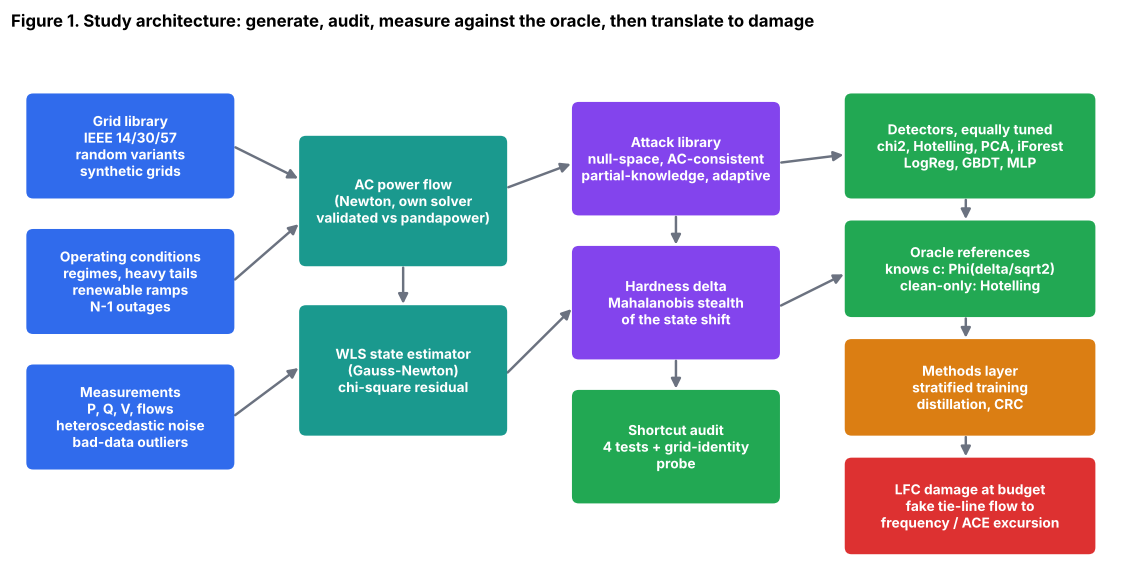

PosixPath('/tmp/w2/proj/figures/fig01_architecture.png')

In [4]:
def box(ax, xy, w, h, text, color, fs=9, tc="white"):
    x, y = xy
    p = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                       fc=color, ec="none", alpha=0.95, zorder=3)
    ax.add_patch(p)
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", color=tc, fontsize=fs,
            fontweight="bold", zorder=4, wrap=True)

def arrow(ax, p0, p1, color=PAL["grey"], rad=0.0, lw=1.6):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle="-|>", mutation_scale=13, lw=lw,
                                 color=color, connectionstyle=f"arc3,rad={rad}", zorder=2))

fig, ax = plt.subplots(figsize=(13, 6.2))
ax.set_xlim(0, 13); ax.set_ylim(0, 6.2); ax.axis("off")
ax.set_title("Figure 1. Study architecture: generate, audit, measure against the oracle, then translate to damage",
             loc="left")

# column 1: generation
box(ax, (0.2, 4.3), 2.4, 1.2, "Grid library\nIEEE 14/30/57\nrandom variants\nsynthetic grids", PAL["blue"])
box(ax, (0.2, 2.7), 2.4, 1.2, "Operating conditions\nregimes, heavy tails\nrenewable ramps\nN-1 outages", PAL["blue"])
box(ax, (0.2, 1.1), 2.4, 1.2, "Measurements\nP, Q, V, flows\nheteroscedastic noise\nbad-data outliers", PAL["blue"])
# column 2: physics
box(ax, (3.4, 3.5), 2.4, 1.5, "AC power flow\n(Newton, own solver\nvalidated vs pandapower)", PAL["teal"])
box(ax, (3.4, 1.5), 2.4, 1.5, "WLS state estimator\n(Gauss-Newton)\nchi-square residual", PAL["teal"])
# column 3: attacks + audit
box(ax, (6.6, 4.1), 2.4, 1.3, "Attack library\nnull-space, AC-consistent\npartial-knowledge, adaptive", PAL["purple"])
box(ax, (6.6, 2.4), 2.4, 1.3, "Hardness delta\nMahalanobis stealth\nof the state shift", PAL["purple"])
box(ax, (6.6, 0.7), 2.4, 1.3, "Shortcut audit\n4 tests + grid-identity\nprobe", PAL["green"])
# column 4: measurement
box(ax, (9.8, 4.3), 2.9, 1.2, "Detectors, equally tuned\nchi2, Hotelling, PCA, iForest\nLogReg, GBDT, MLP", PAL["green"])
box(ax, (9.8, 2.9), 2.9, 1.1, "Oracle references\nknows c: Phi(delta/sqrt2)\nclean-only: Hotelling", PAL["green"])
box(ax, (9.8, 1.5), 2.9, 1.1, "Methods layer\nstratified training\ndistillation, CRC", PAL["amber"])
box(ax, (9.8, 0.1), 2.9, 1.1, "LFC damage at budget\nfake tie-line flow to\nfrequency / ACE excursion", PAL["red"])

for a, b in [((2.6, 4.9), (3.4, 4.5)), ((2.6, 3.3), (3.4, 4.0)), ((2.6, 1.7), (3.4, 2.3)),
             ((4.6, 3.5), (4.6, 3.0)), ((5.8, 4.4), (6.6, 4.7)), ((5.8, 2.2), (6.6, 3.0)),
             ((7.8, 4.1), (7.8, 3.7)), ((7.8, 2.4), (7.8, 2.0)),
             ((9.0, 4.7), (9.8, 4.8)), ((9.0, 3.0), (9.8, 3.4)), ((11.2, 4.3), (11.2, 4.0)),
             ((11.2, 2.9), (11.2, 2.6)), ((11.2, 1.5), (11.2, 1.2))]:
    arrow(ax, a, b)
savefig(fig, "fig01_architecture")

## Part 2. Theory: what "best possible" means

### 2.1 The setting in one paragraph

A state estimator turns measurements $z$ into a state estimate $\hat x$. A *stealth* (null-space) false-data injection adds $a = Hc$ to the measurements, with $H$ the measurement Jacobian. The residual $r = z - H\hat x$ is unchanged because $Hc$ lies in the column space of $H$ and the residual lives in its orthogonal complement. The classical chi-square bad-data test, which looks only at $r$, therefore cannot see the attack. The attack's only footprint is a shift $c$ of the *state estimate*. Whether that shift is detectable depends on how large it is compared with how much the estimate wanders on its own, because load and generation vary all day.

**Hardness.** If $\Sigma$ is the covariance of the clean state estimate, the hardness of a shift $c$ is its Mahalanobis length

$$\delta(c)=\sqrt{c^{\top}\Sigma^{-1}c}.$$

**Oracle detector.** For a *known* direction $c$ and Gaussian clean estimates, the likelihood-ratio test is $s=c^\top\Sigma^{-1}(\hat x-\mu)$, and its operating characteristic is exact:

$$\mathrm{TPR}(\alpha)=\Phi\!\big(\delta-\Phi^{-1}(1-\alpha)\big),\qquad \mathrm{AUROC}=\Phi\!\big(\delta/\sqrt{2}\big).$$

No detector, learned or not, can beat this for that $c$ under the Gaussian model (Neyman–Pearson). This is known theory (it is the likelihood-ratio result behind the Gaussian-stealth literature); what we add is checking it on non-Gaussian AC data and using it as a yardstick for learned detectors.

**Clean-only reference.** A real operator does not know $c$. A detector trained only on clean data can at best test whether $\hat x$ is plausible in *all* $n$ directions, i.e. Hotelling's $T^2=(\hat x-\mu)^\top\Sigma^{-1}(\hat x-\mu)$, which under attack is non-central $\chi^2_n(\delta^2)$. Its power is lower than the oracle's and falls as $n$ grows.

**Damage ceiling.** If an attack of hardness $\delta$ fakes a tie-line flow $h^\top c$, the largest fake flow it can cause is $\delta\sqrt{h^\top\Sigma h}$, reached at $c^\star=\delta\,\Sigma h/\sqrt{h^\top\Sigma h}$ (Lagrange / Cauchy–Schwarz in the $\Sigma^{-1}$ inner product).

In [5]:
def oracle_tpr(delta, alpha):
    """TPR of the likelihood-ratio detector at false-alarm rate alpha."""
    return st.norm.cdf(np.asarray(delta) - st.norm.ppf(1 - np.asarray(alpha)))

def oracle_auc(delta):
    return st.norm.cdf(np.asarray(delta) / np.sqrt(2.0))

def hotelling_tpr(delta, n, alpha):
    """Power of the clean-only chi2_n test against a shift of hardness delta."""
    thr = st.chi2.ppf(1 - alpha, n)
    return st.ncx2.sf(thr, n, np.asarray(delta) ** 2)

def hotelling_auc(delta, n, grid=4000):
    """AUROC between chi2_n (clean) and ncx2(n, delta^2) (attacked): P(X_a > X_c)."""
    delta = np.atleast_1d(delta).astype(float)
    hi = st.chi2.ppf(1 - 1e-9, n) + (delta.max() + 8) ** 2
    x = np.linspace(0, hi, grid)
    Fc = st.chi2.cdf(x, n)
    return np.array([np.trapezoid(st.ncx2.pdf(x, n, d ** 2) * Fc, x) for d in delta])

# --- Monte-Carlo check of the closed forms (pure Gaussian world) ---------------
rg = rng_for("theory_mc")
n_dim, n_mc = 12, 40000
A = rg.normal(size=(n_dim, n_dim)); Sigma_t = A @ A.T / n_dim + 0.3 * np.eye(n_dim)
Li = np.linalg.cholesky(Sigma_t); Sinv = np.linalg.inv(Sigma_t)
rows = []
for d in [0.5, 1.0, 2.0, 3.0]:
    u = rg.normal(size=n_dim); u /= np.sqrt(u @ Sinv @ u); c = d * u          # hardness exactly d
    xc = rg.normal(size=(n_mc, n_dim)) @ Li.T
    xa = rg.normal(size=(n_mc, n_dim)) @ Li.T + c
    s_or_c, s_or_a = xc @ Sinv @ c, xa @ Sinv @ c
    t2_c = np.einsum("ij,jk,ik->i", xc, Sinv, xc); t2_a = np.einsum("ij,jk,ik->i", xa, Sinv, xa)
    rows.append(dict(delta=d,
        auc_oracle_mc=roc_auc_score(np.r_[np.zeros(n_mc), np.ones(n_mc)], np.r_[s_or_c, s_or_a]),
        auc_oracle_formula=float(oracle_auc(d)),
        auc_T2_mc=roc_auc_score(np.r_[np.zeros(n_mc), np.ones(n_mc)], np.r_[t2_c, t2_a]),
        auc_T2_formula=float(hotelling_auc(d, n_dim)[0])))
print(pd.DataFrame(rows).round(4).to_string(index=False))

# --- damage-ceiling check -------------------------------------------------------
h_t = rg.normal(size=n_dim)
c_star = 2.0 * Sigma_t @ h_t / np.sqrt(h_t @ Sigma_t @ h_t)
dirs = rg.normal(size=(200000, n_dim)); dirs /= np.sqrt(np.einsum("ij,jk,ik->i", dirs, Sinv, dirs))[:, None]
print(f"\nhardness of c*            : {np.sqrt(c_star @ Sinv @ c_star):.4f}")
print(f"h'c* (closed form)         : {h_t @ c_star:.4f}  vs  delta*sqrt(h'Sh) = {2.0*np.sqrt(h_t@Sigma_t@h_t):.4f}")
print(f"best of 200k random dirs   : {(2.0 * dirs @ h_t).max():.4f}  (must not exceed the ceiling)")

 delta  auc_oracle_mc  auc_oracle_formula  auc_T2_mc  auc_T2_formula
   0.5         0.6386              0.6382     0.5139          0.5140
   1.0         0.7598              0.7602     0.5524          0.5543
   2.0         0.9213              0.9214     0.6903          0.6922
   3.0         0.9830              0.9831     0.8426          0.8448

hardness of c*            : 2.0000
h'c* (closed form)         : 5.4596  vs  delta*sqrt(h'Sh) = 5.4596
best of 200k random dirs   : 4.5648  (must not exceed the ceiling)


### 2.2 Two figures that carry the whole idea (Figures 2 and 3)

Figure 2 shows the geometry: why the residual test is blind to the attack, and why *equal-sized* attacks can have very different hardness. Figure 3 shows the oracle's ROC family and how the clean-only reference degrades with dimension.

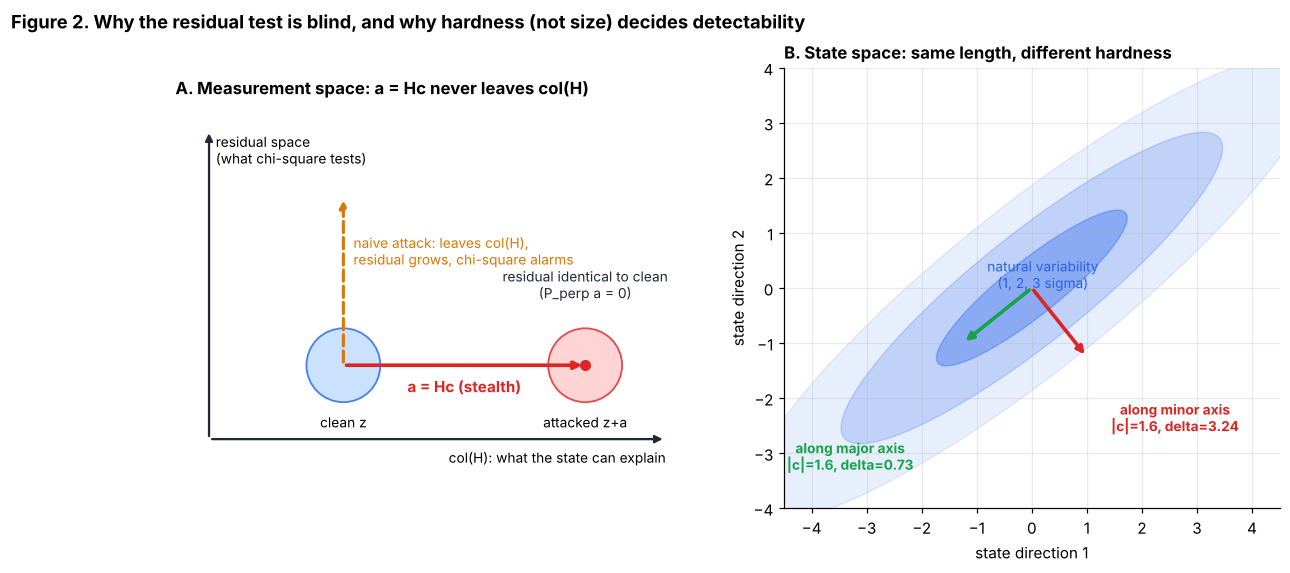

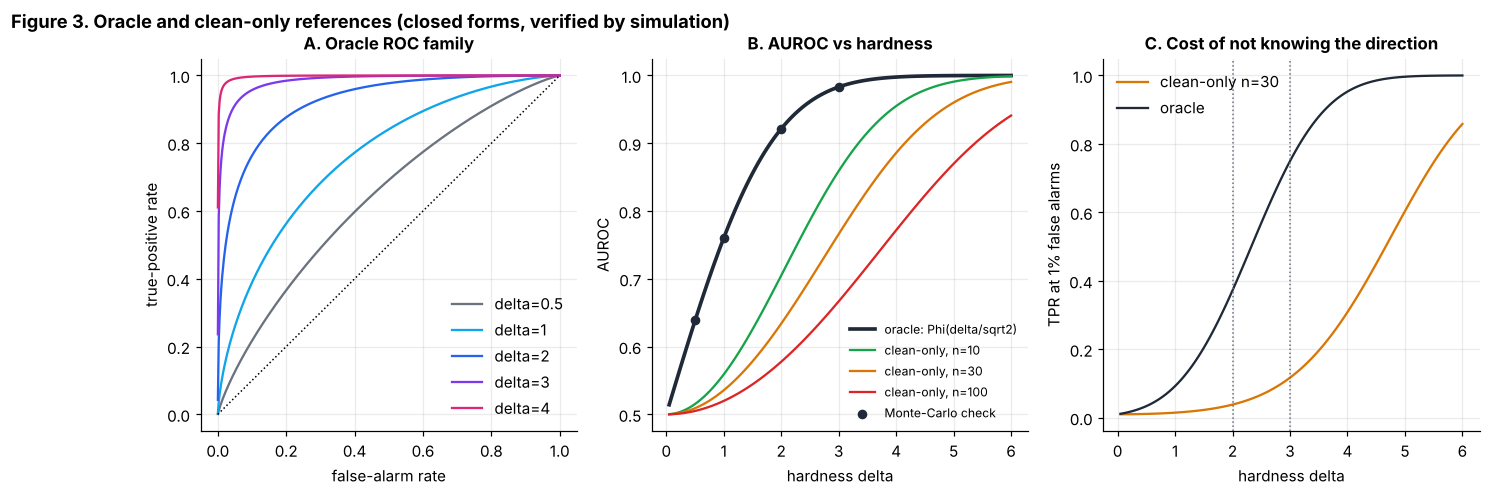

PosixPath('/tmp/w2/proj/figures/fig03_oracle_roc.png')

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# Panel A: measurement-space decomposition
ax = axes[0]; ax.set_xlim(-0.5, 7); ax.set_ylim(-0.5, 5); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("A. Measurement space: a = Hc never leaves col(H)", loc="left")
ax.annotate("", xy=(6.8, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=1.5, color=PAL["ink"]))
ax.annotate("", xy=(0, 4.6), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=1.5, color=PAL["ink"]))
ax.text(6.8, -0.35, "col(H): what the state can explain", ha="right", fontsize=9)
ax.text(0.1, 4.55, "residual space\n(what chi-square tests)", fontsize=9, va="top")
ax.add_patch(Circle((2.0, 1.1), 0.55, fc="#bfdbfe", ec=PAL["blue"], lw=1.2, alpha=0.8))
ax.text(2.0, 0.25, "clean z", ha="center", va="center", fontsize=9)
ax.annotate("", xy=(5.6, 1.1), xytext=(2.0, 1.1), arrowprops=dict(arrowstyle="-|>", lw=2.4, color=PAL["red"]))
ax.text(3.8, 0.7, "a = Hc (stealth)", color=PAL["red"], ha="center", fontsize=10, fontweight="bold")
ax.add_patch(Circle((5.6, 1.1), 0.55, fc="#fecaca", ec=PAL["red"], lw=1.2, alpha=0.8))
ax.text(5.6, 0.25, "attacked z+a", ha="center", va="center", fontsize=9)
ax.annotate("", xy=(2.0, 3.6), xytext=(2.0, 1.1), arrowprops=dict(arrowstyle="-|>", lw=2.0, color=PAL["amber"], ls="--"))
ax.text(2.15, 2.6, "naive attack: leaves col(H),\nresidual grows, chi-square alarms", color=PAL["amber"], fontsize=9)
ax.plot([5.6, 5.6], [1.1, 1.1], "o", color=PAL["red"])
ax.text(5.6, 2.1, "residual identical to clean\n(P_perp a = 0)", ha="center", color=PAL["ink"], fontsize=9)

# Panel B: state space with covariance ellipse
ax = axes[1]
ax.set_title("B. State space: same length, different hardness", loc="left")
Sg = np.array([[3.0, 2.2], [2.2, 2.0]]); w, V = np.linalg.eigh(Sg)
th = np.linspace(0, 2 * np.pi, 200)
for k, a_ in [(1, 0.35), (2, 0.2), (3, 0.1)]:
    e = V @ np.diag(np.sqrt(w)) @ np.vstack([np.cos(th), np.sin(th)]) * k
    ax.fill(e[0], e[1], color=PAL["blue"], alpha=a_)
ax.text(0.2, 0.0, "natural variability\n(1, 2, 3 sigma)", fontsize=9, color=PAL["blue"], ha="center")
L = 1.6
for vec, col, lab in [(V[:, 1], PAL["green"], "along major axis"), (V[:, 0], PAL["red"], "along minor axis")]:
    c_ = L * vec; d_ = np.sqrt(c_ @ np.linalg.inv(Sg) @ c_)
    ax.annotate("", xy=c_, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=2.4, color=col))
    pos = (-3.3, -3.3) if c_[0] < 0 else (2.6, -2.6)
    ax.text(pos[0], pos[1], f"{lab}\n|c|={L:.1f}, delta={d_:.2f}", color=col, fontsize=9, ha="center", fontweight="bold")
ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4, 4); ax.set_aspect("equal")
ax.set_xlabel("state direction 1"); ax.set_ylabel("state direction 2")
fig.suptitle("Figure 2. Why the residual test is blind, and why hardness (not size) decides detectability", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig02_geometry")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
al = np.linspace(1e-4, 1 - 1e-4, 400)
ax = axes[0]
for d, col in zip([0.5, 1, 2, 3, 4], [PAL["grey"], PAL["sky"], PAL["blue"], PAL["purple"], PAL["pink"]]):
    ax.plot(al, oracle_tpr(d, al), color=col, label=f"delta={d}")
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_xlabel("false-alarm rate"); ax.set_ylabel("true-positive rate")
ax.set_title("A. Oracle ROC family"); ax.legend()
ax = axes[1]
dd = np.linspace(0.05, 6, 120)
ax.plot(dd, oracle_auc(dd), color=PAL["ink"], lw=2.4, label="oracle: Phi(delta/sqrt2)")
for n_, col in [(10, PAL["green"]), (30, PAL["amber"]), (100, PAL["red"])]:
    ax.plot(dd, hotelling_auc(dd, n_), color=col, label=f"clean-only, n={n_}")
mc = pd.DataFrame(rows)
ax.scatter(mc.delta, mc.auc_oracle_mc, c=PAL["ink"], s=28, zorder=5, label="Monte-Carlo check")
ax.set_xlabel("hardness delta"); ax.set_ylabel("AUROC"); ax.set_title("B. AUROC vs hardness"); ax.legend(fontsize=8)
ax = axes[2]
ax.plot(dd, hotelling_tpr(dd, 30, 0.01), color=PAL["amber"], label="clean-only n=30")
ax.plot(dd, oracle_tpr(dd, 0.01), color=PAL["ink"], label="oracle")
for d0 in (2.0, 3.0): ax.axvline(d0, color=PAL["grey"], ls=":", lw=1)
ax.set_xlabel("hardness delta"); ax.set_ylabel("TPR at 1% false alarms")
ax.set_title("C. Cost of not knowing the direction"); ax.legend()
fig.suptitle("Figure 3. Oracle and clean-only references (closed forms, verified by simulation)", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig03_oracle_roc")

## Part 3. Grid library

The benchmark's value depends on grid diversity, so grids are data objects that can be cloned and modified, not fixed library calls. Three sources feed the library:

1. **IEEE cases** (14, 30, 57 buses) read from `pandapower`'s internal power-flow case (`ppc`), then stored in our own `Grid` container.
2. **Randomized variants**: remove a few lines while keeping the network connected, jitter line impedances by about ±15%, and re-site loads among load buses.
3. **Synthetic grids** with random bus counts: random geometric networks with a spanning backbone plus extra loops, log-normal loads, and generators on a random subset of buses.

Every grid carries a `family` tag and an `area` label (a two-area partition by Kernighan–Lin bisection), which later defines the tie lines for the LFC study. The benchmark family itself is assembled in Part 4.2, after the physics core exists, so that each grid can be screened for power-flow convergence. Branch and bus data stay in per-unit and megawatt arrays so the physics core in Part 4 can rebuild admittance matrices for any topology, including N−1 outages.

In [7]:
@dataclass
class Grid:
    name: str
    baseMVA: float
    bustype: np.ndarray            # 1 PQ, 2 PV, 3 reference
    Pd: np.ndarray; Qd: np.ndarray # MW, MVAr
    Gs: np.ndarray; Bs: np.ndarray # shunt MW, MVAr at 1 pu
    gen_bus: np.ndarray; gen_P: np.ndarray; gen_V: np.ndarray
    f: np.ndarray; t: np.ndarray   # branch end buses (0-based)
    r: np.ndarray; x: np.ndarray; b: np.ndarray
    tap: np.ndarray; shift: np.ndarray   # tap ratio, phase shift (rad)
    status: np.ndarray             # bool per branch
    family: str = ""
    area: np.ndarray = None
    meta: dict = field(default_factory=dict)

    @property
    def n(self): return len(self.bustype)
    @property
    def nl(self): return len(self.f)

    def clone(self, **kw):
        d = {k: (v.copy() if isinstance(v, np.ndarray) else v) for k, v in self.__dict__.items()}
        d["meta"] = dict(self.meta); d.update(kw)
        return Grid(**d)

    def graph(self, only_active=True):
        G = nx.Graph(); G.add_nodes_from(range(self.n))
        for k in range(self.nl):
            if self.status[k] or not only_active:
                G.add_edge(int(self.f[k]), int(self.t[k]), k=k)
        return G

def grid_from_pandapower(net, name, family="ieee", init="flat"):
    try:
        pp.runpp(net, init=init, numba=False)
    except Exception:
        pp.runpp(net, init="dc", numba=False, max_iteration=60)
    ppc = net._ppc
    bus, gen, br = ppc["bus"], ppc["gen"], ppc["branch"]
    # keep only the energised island that contains the reference bus (open switches leave isolated buses)
    ok_bus = (bus[:, 1] != 4) & np.isfinite(bus[:, 7])
    live = br[:, 10] > 0
    pos = {int(b): i for i, b in enumerate(bus[:, 0])}
    fb = np.array([pos[int(b)] for b in br[:, 0]]); tb = np.array([pos[int(b)] for b in br[:, 1]])
    G0 = nx.Graph(); G0.add_nodes_from(np.where(ok_bus)[0])
    G0.add_edges_from([(int(a_), int(b_)) for a_, b_, l_ in zip(fb, tb, live) if l_ and ok_bus[a_] and ok_bus[b_]])
    ref0 = int(np.where(bus[:, 1] == 3)[0][0])
    comp = nx.node_connected_component(G0, ref0)
    keep = np.zeros(len(bus), bool); keep[list(comp)] = True
    new_id = -np.ones(len(bus), int); new_id[keep] = np.arange(keep.sum())
    lv = live & keep[fb] & keep[tb]
    gmask = (gen[:, 7] > 0) & keep[[pos[int(b)] for b in gen[:, 0]]]
    tap = br[lv, 8].copy(); tap[tap == 0] = 1.0
    bk = bus[keep]
    g = Grid(name=name, baseMVA=float(ppc["baseMVA"]), bustype=bk[:, 1].astype(int),
             Pd=bk[:, 2].copy(), Qd=bk[:, 3].copy(), Gs=bk[:, 4].copy(), Bs=bk[:, 5].copy(),
             gen_bus=np.array([new_id[pos[int(b)]] for b in gen[gmask, 0]]), gen_P=gen[gmask, 1].copy(), gen_V=gen[gmask, 5].copy(),
             f=new_id[fb[lv]], t=new_id[tb[lv]],
             r=br[lv, 2].copy(), x=br[lv, 3].copy(), b=br[lv, 4].copy(),
             tap=tap, shift=np.deg2rad(br[lv, 9]), status=np.ones(int(lv.sum()), bool), family=family)
    g.meta["Vm_ref"] = bk[:, 7].copy()
    lk = net._pd2ppc_lookups["bus"]                       # pandapower bus index -> ppc bus index (switch fusing)
    bm = -np.ones(len(lk), int)
    for pb_, pc_ in enumerate(lk):
        if pc_ >= 0 and pc_ < len(bus) and keep[pc_]: bm[pb_] = new_id[pc_]
    g.meta["bus_map"] = bm                                # lets profile-driven generators place loads and DER on the right bus
    g.meta["V_start"] = bk[:, 7] * np.exp(1j * np.deg2rad(bk[:, 8]))    # solved pandapower voltages: a robust warm start for stiff feeders
    return g

def assign_areas(g, seed=0):
    """Two-area partition (balanced min-cut heuristic) -> g.area in {0,1}."""
    G = g.graph()
    A, B = nx.algorithms.community.kernighan_lin_bisection(G, seed=seed)
    area = np.zeros(g.n, int); area[list(B)] = 1
    g.area = area
    g.meta["tie"] = np.where(area[g.f] != area[g.t])[0]
    return g

def is_connected_without(g, drop):
    G = g.graph()
    G.remove_edges_from([(int(g.f[k]), int(g.t[k])) for k in drop])
    return nx.is_connected(G)

def variant_grid(base, rng, n_remove=2, jitter=0.15, resite=True, name=None):
    g = base.clone(name=name or base.name + "_v", family="variant")
    cand = list(rng.permutation(g.nl)); dropped = []
    for k in cand:
        if len(dropped) >= n_remove: break
        if is_connected_without(g, dropped + [k]): dropped.append(int(k))
    g.status[dropped] = False
    # drop them physically so downstream code never sees dead branches
    keep = g.status
    for a in ["f", "t", "r", "x", "b", "tap", "shift"]:
        setattr(g, a, getattr(g, a)[keep])
    g.status = np.ones(len(g.f), bool)
    s = rng.uniform(1 - jitter, 1 + jitter, size=g.nl)
    g.r, g.x, g.b = g.r * s, g.x * s, g.b * rng.uniform(1 - jitter, 1 + jitter, size=g.nl)
    if resite:
        load_buses = np.where((g.Pd > 0) & (g.bustype == 1))[0]
        perm = rng.permutation(load_buses)
        g.Pd[load_buses], g.Qd[load_buses] = g.Pd[perm], g.Qd[perm]
    g.meta["removed"] = dropped
    return g

def synthetic_grid(n, rng, name, extra_loops=0.35, load_mw=(4, 60), baseMVA=100.0):
    """Random geometric grid: connected backbone (MST on random points) + extra short links."""
    pts = rng.uniform(0, 1, size=(n, 2))
    D = np.linalg.norm(pts[:, None] - pts[None], axis=2)
    G = nx.Graph(); G.add_nodes_from(range(n))
    for i in range(n):
        for j in range(i + 1, n): G.add_edge(i, j, w=D[i, j])
    T = nx.minimum_spanning_tree(G, weight="w")
    edges = set(map(lambda e: tuple(sorted(e)), T.edges()))
    order = np.dstack(np.unravel_index(np.argsort(D + np.eye(n) * 9), D.shape))[0]
    want = int(extra_loops * n)
    for i, j in order:
        if len(edges) >= (n - 1) + want: break
        e = tuple(sorted((int(i), int(j))))
        if e not in edges and rng.random() < 0.5: edges.add(e)
    edges = sorted(edges)
    f = np.array([e[0] for e in edges]); t = np.array([e[1] for e in edges])
    d = D[f, t]
    x = 0.04 + 0.35 * d * rng.uniform(0.8, 1.2, size=len(d))
    r = x * rng.uniform(0.12, 0.35, size=len(d))
    b = 0.02 + 0.05 * d
    Pd = np.exp(rng.normal(np.log(np.mean(load_mw)), 0.6, size=n)).clip(*load_mw)
    Pd[rng.random(n) < 0.15] = 0.0
    Qd = Pd * rng.uniform(0.2, 0.45, size=n)
    ng = max(2, n // 5)
    gb = rng.choice(n, size=ng, replace=False)
    ref = int(gb[0])
    btype = np.ones(n, int); btype[gb] = 2; btype[ref] = 3
    Pg = np.zeros(ng); share = rng.uniform(0.7, 1.3, size=ng); share /= share.sum()
    Pg = share * Pd.sum() * 1.02
    g = Grid(name=name, baseMVA=baseMVA, bustype=btype, Pd=Pd, Qd=Qd, Gs=np.zeros(n), Bs=np.zeros(n),
             gen_bus=gb, gen_P=Pg, gen_V=rng.uniform(1.0, 1.04, size=ng),
             f=f, t=t, r=r, x=x, b=b, tap=np.ones(len(f)), shift=np.zeros(len(f)),
             status=np.ones(len(f), bool), family="synthetic")
    return g

In [8]:
base14 = grid_from_pandapower(pn.case14(), "ieee14")
base30 = grid_from_pandapower(pn.case30(), "ieee30")
base57 = grid_from_pandapower(pn.case57(), "ieee57")
for g in (base14, base30, base57): assign_areas(g)
print(f"{'grid':<8}{'buses':>6}{'branches':>9}{'gens':>5}{'load MW':>9}{'tie lines':>10}")
for g in (base14, base30, base57):
    print(f"{g.name:<8}{g.n:>6}{g.nl:>9}{len(g.gen_bus):>5}{g.Pd.sum():>9.1f}{len(g.meta['tie']):>10}")

grid     buses branches gens  load MW tie lines
ieee14      14       20    5    259.0         3
ieee30      30       41    6    189.2         5
ieee57      57       80    7   1250.8         6


## Part 4. Physics core

Everything here is written from scratch in NumPy so that every step of the data-generating process is inspectable, and then **validated against `pandapower`** before any dataset is built.

| Block | What it does | Validation |
|---|---|---|
| Admittance matrices | $Y_{bus}$, $Y_f$, $Y_t$ from branch data, any topology | compared with pandapower's `makeYbus` |
| Newton–Raphson power flow | polar form, PV/PQ handling | voltages compared with `pandapower.runpp` on the base cases |
| Measurement model $h(x)$ | bus injections $P,Q$, voltage magnitudes, branch flows $P_f$ | analytic Jacobian vs finite differences |
| WLS state estimator | Gauss–Newton on $\min_x (z-h(x))^\top W (z-h(x))$ | recovers the true state under noise; $\chi^2$ statistic matches its theoretical distribution |

State vector: $x=[\theta_{\text{non-ref}},\,V_m]$ with $2n-1$ entries.

In [9]:
def build_Y(g):
    """Return Ybus (n x n), Yf, Yt (nl x n), Cf, Ct incidence for the ACTIVE branches of g."""
    n, nl = g.n, g.nl
    act = g.status
    ys = 1.0 / (g.r + 1j * g.x)
    bc = 1j * g.b
    tap = g.tap * np.exp(1j * g.shift)
    Ytt = ys + bc / 2
    Yff = Ytt / (tap * np.conj(tap))
    Yft = -ys / np.conj(tap)
    Ytf = -ys / tap
    Yff, Yft, Ytf, Ytt = [np.where(act, a, 0.0) for a in (Yff, Yft, Ytf, Ytt)]
    Cf = np.zeros((nl, n)); Ct = np.zeros((nl, n))
    Cf[np.arange(nl), g.f] = 1.0; Ct[np.arange(nl), g.t] = 1.0
    Yf = Yff[:, None] * Cf + Yft[:, None] * Ct
    Yt = Ytf[:, None] * Cf + Ytt[:, None] * Ct
    Ysh = (g.Gs + 1j * g.Bs) / g.baseMVA
    Ybus = Cf.T @ Yf + Ct.T @ Yt + np.diag(Ysh)
    return Ybus, Yf, Yt, Cf, Ct

class Model:
    """Precomputed matrices for one grid topology."""
    def __init__(self, g):
        self.g = g
        self.Ybus, self.Yf, self.Yt, self.Cf, self.Ct = build_Y(g)
        self.n, self.nl = g.n, g.nl
        self.ref = int(np.where(g.bustype == 3)[0][0])
        self.pv = np.where(g.bustype == 2)[0]
        self.pq = np.where(g.bustype == 1)[0]
        self.pvpq = np.r_[self.pv, self.pq]
        self.nonref = np.array([i for i in range(self.n) if i != self.ref])
        # generator voltage set-points per bus
        self.Vset = np.ones(self.n)
        for b_, v_ in zip(g.gen_bus, g.gen_V): self.Vset[b_] = v_

def dS_dV(M, V):
    Ibus = M.Ybus @ V; Vn = V / np.abs(V)
    dVm = V[:, None] * np.conj(M.Ybus * Vn[None, :]) + np.diag(np.conj(Ibus) * Vn)
    dVa = 1j * V[:, None] * np.conj(np.diag(Ibus) - M.Ybus * V[None, :])
    return dVm, dVa

def newton_pf(M, Pd, Qd, Pg_bus, V0=None, tol=1e-9, maxit=25):
    """Polar Newton-Raphson. Pd, Qd in MW/MVAr per bus; Pg_bus in MW per bus (slack output is free)."""
    g = M.g; n = M.n
    Sbus = ((Pg_bus - Pd) + 1j * (-Qd)) / g.baseMVA
    if V0 is None: V0 = g.meta.get("V_start")
    V = (np.ones(n, complex) if V0 is None else np.array(V0, complex))
    Vm = np.abs(V); Va = np.angle(V)
    Vm[np.r_[M.pv, M.ref]] = M.Vset[np.r_[M.pv, M.ref]]
    V = Vm * np.exp(1j * Va)
    pvpq, pq = M.pvpq, M.pq
    for it in range(maxit):
        S = V * np.conj(M.Ybus @ V)
        mis = S - Sbus
        F = np.r_[mis[pvpq].real, mis[pq].imag]
        if np.max(np.abs(F)) < tol: return V, True, it
        dVm, dVa = dS_dV(M, V)
        J = np.block([[dVa[np.ix_(pvpq, pvpq)].real, dVm[np.ix_(pvpq, pq)].real],
                      [dVa[np.ix_(pq, pvpq)].imag,   dVm[np.ix_(pq, pq)].imag]])
        try: dx = np.linalg.solve(J, -F)
        except np.linalg.LinAlgError: return V, False, it
        Va[pvpq] += dx[:len(pvpq)]; Vm[pq] += dx[len(pvpq):]
        V = Vm * np.exp(1j * Va)
    return V, False, maxit

def meas_h(M, V):
    """Full measurement vector [P_inj(n), Q_inj(n), Vm(n), Pf(nl)] in per unit."""
    S = V * np.conj(M.Ybus @ V)
    Sf = (M.Cf @ V) * np.conj(M.Yf @ V)
    return np.r_[S.real, S.imag, np.abs(V), Sf.real]

def meas_jac(M, V):
    """Analytic Jacobian of meas_h wrt x = [Va_nonref, Vm]."""
    n = M.n; Vn = V / np.abs(V)
    dVm, dVa = dS_dV(M, V)
    Vf = M.Cf @ V; If = M.Yf @ V
    dSf_dVa = 1j * (np.conj(If)[:, None] * M.Cf * V[None, :] - Vf[:, None] * np.conj(M.Yf * V[None, :]))
    dSf_dVm = Vf[:, None] * np.conj(M.Yf * Vn[None, :]) + np.conj(If)[:, None] * M.Cf * Vn[None, :]
    H = np.zeros((3 * n + M.nl, 2 * n - 1))
    ne = M.nonref
    H[:n, :n - 1] = dVa[:, ne].real;  H[:n, n - 1:] = dVm.real
    H[n:2 * n, :n - 1] = dVa[:, ne].imag; H[n:2 * n, n - 1:] = dVm.imag
    H[2 * n:3 * n, n - 1:] = np.eye(n)
    H[3 * n:, :n - 1] = dSf_dVa[:, ne].real; H[3 * n:, n - 1:] = dSf_dVm.real
    return H

def x_to_V(M, x, Va_ref=0.0):
    n = M.n
    Va = np.zeros(n); Va[M.nonref] = x[:n - 1]; Va[M.ref] = Va_ref
    return x[n - 1:] * np.exp(1j * Va)

def V_to_x(M, V):
    return np.r_[np.angle(V)[M.nonref] - np.angle(V)[M.ref], np.abs(V)]

### 4.1 Validation against pandapower (Figure 5)

Three checks, all on the three IEEE cases: (i) admittance matrix agreement, (ii) Newton power flow versus `pandapower.runpp`, (iii) analytic Jacobian versus central finite differences. If any of them fails, nothing downstream can be trusted, so the cell stops with an assertion.

  grid  converged  iters   max_dY  max_dVm  max_dVa_rad   max_dJ
ieee14       True      0 0.00e+00 4.44e-16     5.55e-17 4.27e-09
ieee30       True      0 0.00e+00 4.44e-16     1.39e-17 4.77e-09
ieee57       True      0 0.00e+00 4.44e-16     5.55e-17 6.38e-09


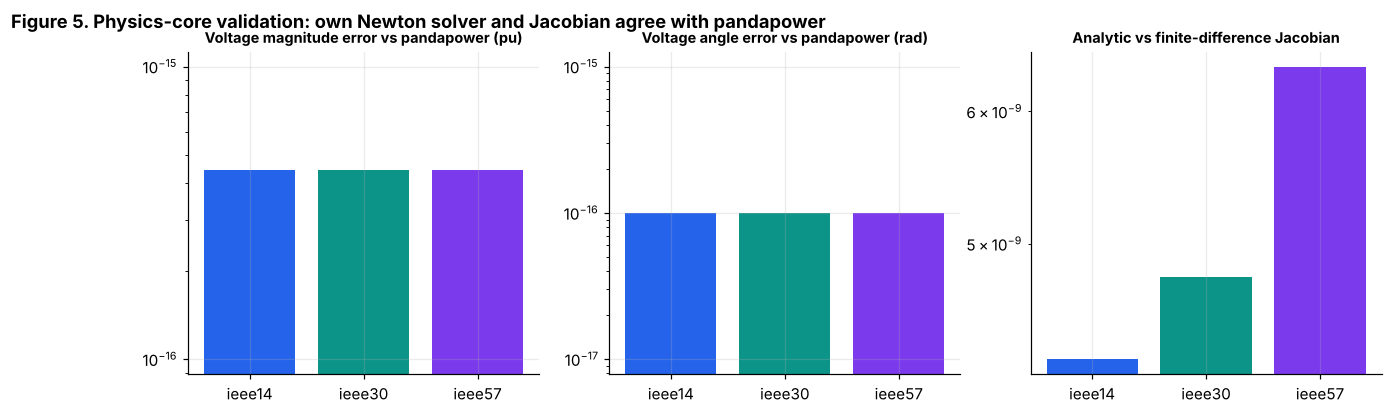

PosixPath('/tmp/w2/proj/figures/fig05_physics_validation.png')

In [10]:
val_rows = []
for name, mk in [("ieee14", pn.case14), ("ieee30", pn.case30), ("ieee57", pn.case57)]:
    g = {"ieee14": base14, "ieee30": base30, "ieee57": base57}[name]; M = Model(g)
    # (i) Ybus vs pandapower's makeYbus
    net = mk(); pp.runpp(net, init="flat", numba=False); ppc = net._ppc
    Yb_pp, _, _ = _pp_makeYbus(ppc["baseMVA"], ppc["bus"], ppc["branch"])
    e_Y = np.abs(M.Ybus - Yb_pp.toarray()).max()
    # (ii) power flow vs pandapower voltages
    Pg_bus = np.zeros(g.n); np.add.at(Pg_bus, g.gen_bus, g.gen_P)
    V, ok, it = newton_pf(M, g.Pd, g.Qd, Pg_bus)
    Vm_pp = ppc["bus"][:, 7]; Va_pp = np.deg2rad(ppc["bus"][:, 8])
    e_vm = np.abs(np.abs(V) - Vm_pp).max()
    # pandapower reports angles relative to its slack reference
    e_va = np.abs((np.angle(V) - np.angle(V)[M.ref]) - (Va_pp - Va_pp[M.ref])).max()
    # (iii) Jacobian vs finite differences
    x0 = V_to_x(M, V); H = meas_jac(M, V); Hn = np.zeros_like(H); eps = 1e-6
    for j in range(len(x0)):
        xp, xm = x0.copy(), x0.copy(); xp[j] += eps; xm[j] -= eps
        Hn[:, j] = (meas_h(M, x_to_V(M, xp, np.angle(V)[M.ref])) - meas_h(M, x_to_V(M, xm, np.angle(V)[M.ref]))) / (2 * eps)
    e_J = np.abs(H - Hn).max()
    val_rows.append(dict(grid=name, converged=ok, iters=it, max_dY=e_Y, max_dVm=e_vm, max_dVa_rad=e_va, max_dJ=e_J))
val = pd.DataFrame(val_rows)
print(val.to_string(index=False, float_format=lambda v: f"{v:.2e}"))
assert (val.converged).all() and (val.max_dY < 1e-9).all() and (val.max_dVm < 1e-5).all() and (val.max_dJ < 1e-5).all(), \
    "physics core failed validation against pandapower"

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, ttl in zip(axes, ["max_dVm", "max_dVa_rad", "max_dJ"],
                        ["Voltage magnitude error vs pandapower (pu)", "Voltage angle error vs pandapower (rad)",
                         "Analytic vs finite-difference Jacobian"]):
    ax.bar(val.grid, val[col].clip(lower=1e-16), color=[PAL["blue"], PAL["teal"], PAL["purple"]])
    ax.set_yscale("log"); ax.set_title(ttl, fontsize=9.5)
fig.suptitle("Figure 5. Physics-core validation: own Newton solver and Jacobian agree with pandapower", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig05_physics_validation")

### 4.2 The benchmark family, with an acceptance screen (Figure 4)

The physics core now exists, so every generated grid can be screened before it is accepted. The grids below are fixed once here, from named seeds, and reused by every experiment. `TRAIN_FAMILY` is the broad randomized family used for training in Part 11; `UNSEEN` grids are never used for training or tuning.

* IEEE 14, 30 and 57-bus bases.
* `ieee14_v1`, `ieee14_v2`, `ieee30_v1`: variants with removed lines, jittered impedances and re-sited loads.
* `syn20`, `syn28`, `syn36`: synthetic grids in the training family.
* `ieee30_v2`, `syn24u`, `syn44u`: variants and synthetic grids held out as **unseen** grids, and IEEE 57 as the largest unseen grid.

Each grid has to pass a convergence screen (base load and 122% peak load) before it enters the family.

{'ieee14': '-', 'ieee30': '-', 'ieee57': '-', 'ieee14_v1': 1, 'ieee14_v2': 1, 'ieee30_v1': 6, 'syn20': 7, 'syn28': 11, 'syn36': 1, 'ieee30_v2': 1, 'syn24u': 4, 'syn44u': 16} <- tries needed to pass the screen


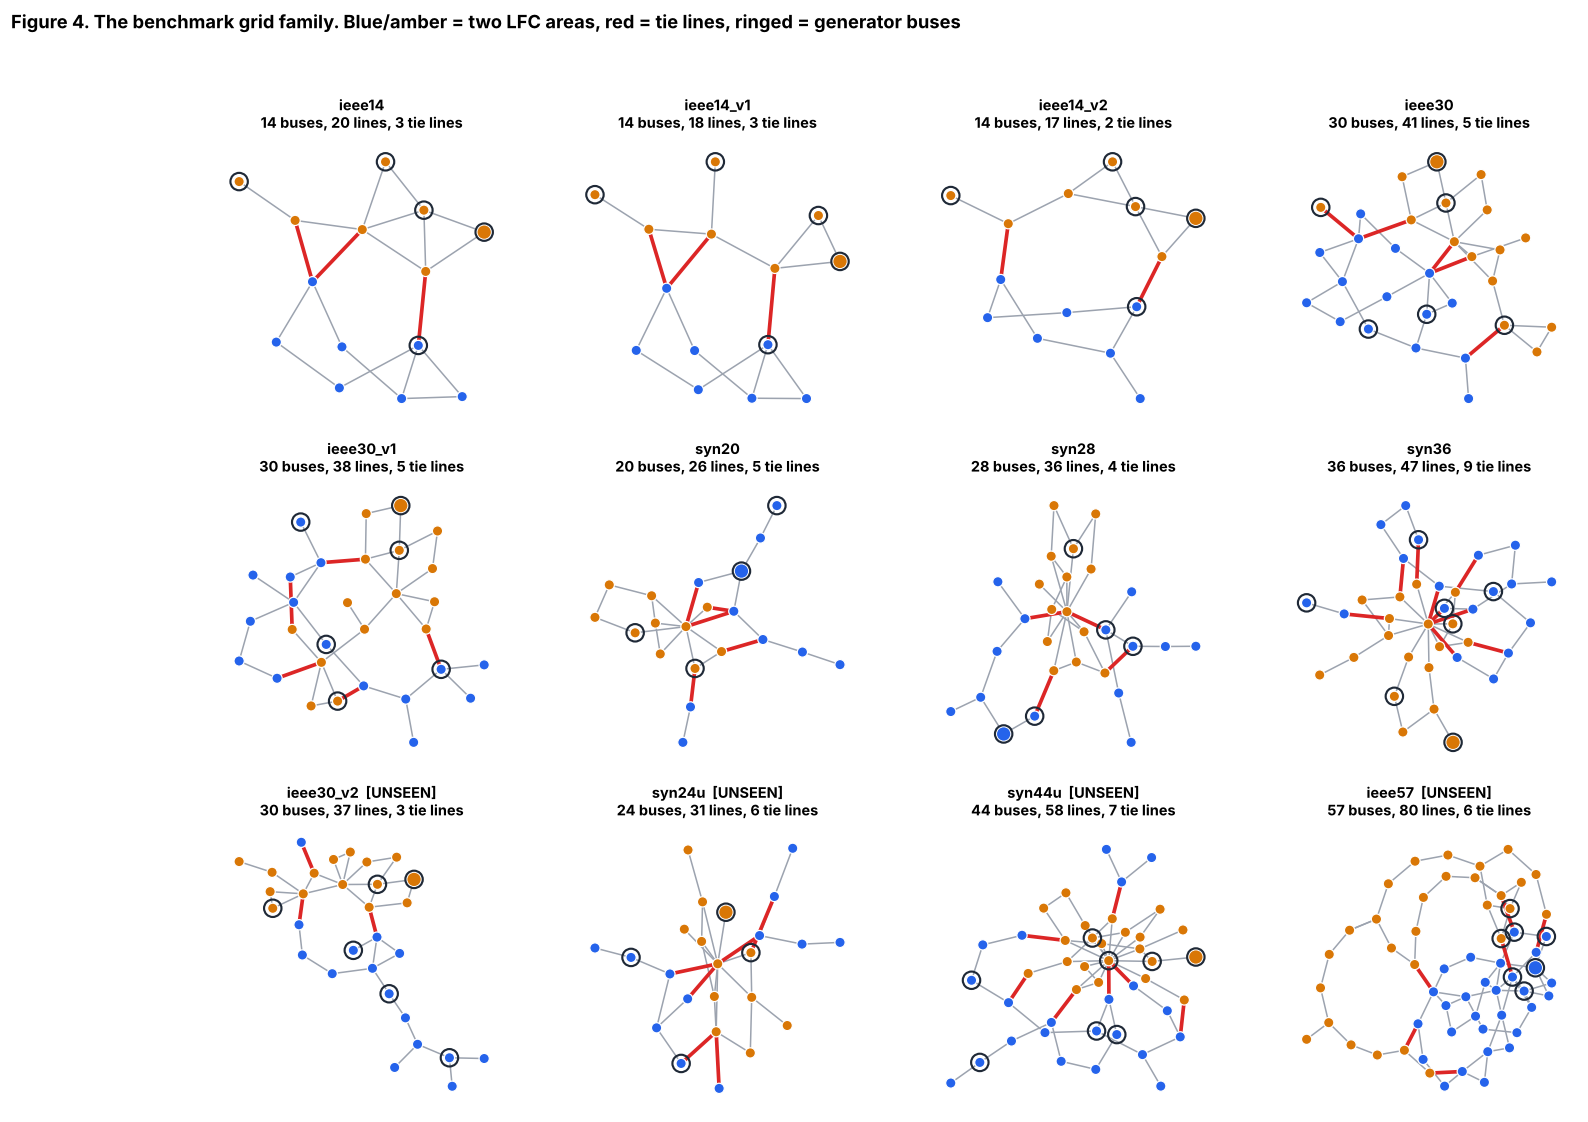

PosixPath('/tmp/w2/proj/figures/fig04_grid_family.png')

In [11]:
def accept(g, peak=1.22):
    """Screen: Newton power flow must converge at base load and at peak load with sane voltages."""
    try:
        M = Model(g)
        Pg = np.zeros(g.n); np.add.at(Pg, g.gen_bus, g.gen_P)
        for lvl in (1.0, peak):
            V, ok, _ = newton_pf(M, g.Pd * lvl, g.Qd * lvl, Pg * lvl)
            if not ok or np.abs(V).min() < 0.88 or np.abs(V).max() > 1.12: return False
        return True
    except Exception:
        return False

def screened(make, name, max_tries=40):
    for i in range(max_tries):
        g = assign_areas(make(i))
        g.name = name
        if accept(g): g.meta["tries"] = i + 1; return g
    raise RuntimeError(f"no acceptable grid found for {name}")

GRIDS = {"ieee14": base14, "ieee30": base30, "ieee57": base57}
GRIDS["ieee14_v1"] = screened(lambda i: variant_grid(base14, rng_for("g_v1", i), 2, 0.15, True, "ieee14_v1"), "ieee14_v1")
GRIDS["ieee14_v2"] = screened(lambda i: variant_grid(base14, rng_for("g_v2", i), 3, 0.20, True, "ieee14_v2"), "ieee14_v2")
GRIDS["ieee30_v1"] = screened(lambda i: variant_grid(base30, rng_for("g_v3", i), 3, 0.15, True, "ieee30_v1"), "ieee30_v1")
GRIDS["syn20"]     = screened(lambda i: synthetic_grid(20, rng_for("g_s20", i), "syn20"), "syn20")
GRIDS["syn28"]     = screened(lambda i: synthetic_grid(28, rng_for("g_s28", i), "syn28"), "syn28")
GRIDS["syn36"]     = screened(lambda i: synthetic_grid(36, rng_for("g_s36", i), "syn36"), "syn36")
# held-out grids (never used for training or tuning)
GRIDS["ieee30_v2"] = screened(lambda i: variant_grid(base30, rng_for("g_v4", i), 4, 0.25, True, "ieee30_v2"), "ieee30_v2")
GRIDS["syn24u"]    = screened(lambda i: synthetic_grid(24, rng_for("g_s24u", i), "syn24u"), "syn24u")
GRIDS["syn44u"]    = screened(lambda i: synthetic_grid(44, rng_for("g_s44u", i), "syn44u"), "syn44u")

TRAIN_FAMILY = ["ieee14", "ieee14_v1", "ieee14_v2", "ieee30", "ieee30_v1", "syn20", "syn28", "syn36"]
UNSEEN       = ["ieee30_v2", "syn24u", "syn44u", "ieee57"]
for k in UNSEEN: GRIDS[k].family = GRIDS[k].family + "_unseen"
print({k: GRIDS[k].meta.get("tries", "-") for k in GRIDS}, "<- tries needed to pass the screen")

def draw_grid(ax, g, title):
    G = g.graph()
    pos = nx.kamada_kawai_layout(G)
    tie = set(g.meta["tie"].tolist())
    cols = [PAL["blue"] if a == 0 else PAL["amber"] for a in g.area]
    ties = [(int(g.f[k]), int(g.t[k])) for k in tie]
    others = [(int(g.f[k]), int(g.t[k])) for k in range(g.nl) if k not in tie]
    nx.draw_networkx_edges(G, pos, edgelist=others, ax=ax, edge_color="#9ca3af", width=1.0)
    nx.draw_networkx_edges(G, pos, edgelist=ties, ax=ax, edge_color=PAL["red"], width=2.4)
    sizes = [90 if g.bustype[i] == 3 else 45 for i in range(g.n)]
    shapes = nx.draw_networkx_nodes(G, pos, ax=ax, node_color=cols, node_size=sizes, linewidths=0.8, edgecolors="white")
    gb = set(g.gen_bus.tolist())
    nx.draw_networkx_nodes(G, pos, nodelist=sorted(gb), ax=ax, node_color="none", node_size=130, edgecolors=PAL["ink"], linewidths=1.4)
    ax.set_title(f"{title}\n{g.n} buses, {g.nl} lines, {len(tie)} tie lines", fontsize=9.5)
    ax.axis("off")

order = TRAIN_FAMILY + UNSEEN
fig, axes = plt.subplots(3, 4, figsize=(16, 11.5))
for ax, k in zip(axes.ravel(), order):
    draw_grid(ax, GRIDS[k], k + ("  [UNSEEN]" if k in UNSEEN else ""))
fig.suptitle("Figure 4. The benchmark grid family. Blue/amber = two LFC areas, red = tie lines, ringed = generator buses",
             x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig04_grid_family")

### 4.3 Measurement set, noise and the WLS estimator

**Measurement set.** Each grid gets a random meter placement: every candidate meter (bus injection $P$, $Q$, voltage magnitude, branch flow $P_f$) is kept with probability 0.9, and the placement is redrawn until the Jacobian has full column rank (observability) and at least 1.5 times as many meters as states (redundancy, which is what gives the $\chi^2$ test its degrees of freedom).

**Noise.** Each meter's standard deviation is a type-specific base value times a fixed, grid-specific factor drawn log-uniformly from $[0.6, 1.6]$. This gives heteroscedastic noise without per-sample randomness in the weights, so one weight matrix serves every sample of a grid.

**Estimator.** Weighted least squares with $W=\mathrm{diag}(1/\sigma^2)$, solved by three Gauss–Newton iterations from the nominal operating point (the usual warm start, because an operator starts from the last estimate or forecast). The $\chi^2$ statistic is $J(\hat x)=r^\top W r$ with $m-(2n-1)$ degrees of freedom.

In [12]:
SIG_BASE = dict(P=0.004, Q=0.004, V=0.0012, F=0.004)    # per-unit standard deviations
KEEP_PROB = 0.90

def setup_meters(M, rng, V_nom):
    """Random meter placement + heteroscedastic noise; returns dict with indices and sigmas."""
    n, nl = M.n, M.nl
    types = np.r_[np.zeros(n, int), np.ones(n, int), 2 * np.ones(n, int), 3 * np.ones(nl, int)]
    base = np.array([SIG_BASE["P"], SIG_BASE["Q"], SIG_BASE["V"], SIG_BASE["F"]])[types]
    H_full = meas_jac(M, V_nom)
    for attempt in range(200):
        keep = rng.random(len(types)) < KEEP_PROB
        keep[2 * n + M.ref] = True       # always meter the reference voltage magnitude
        sel = np.where(keep)[0]
        H = H_full[sel]
        if len(sel) >= 1.5 * (2 * n - 1) and np.linalg.matrix_rank(H) == 2 * n - 1:
            break
    else:
        raise RuntimeError("could not find an observable meter placement")
    sig = base[sel] * np.exp(rng.uniform(np.log(0.6), np.log(1.6), size=len(sel)))
    return dict(sel=sel, sigma=sig, W=1.0 / sig ** 2, types=types[sel], m=len(sel), ns=2 * n - 1)

def wls_estimate(M, mt, z, x0, iters=3, tol=None):
    """Gauss-Newton WLS. z: measured vector on mt['sel']. Returns xhat, chi2, residual."""
    sel, W = mt["sel"], mt["W"]
    x = x0.copy(); Va_ref = 0.0
    for _ in range(iters):
        V = x_to_V(M, x, Va_ref)
        r = z - meas_h(M, V)[sel]
        H = meas_jac(M, V)[sel]
        G = H.T @ (W[:, None] * H)
        dx = np.linalg.solve(G, H.T @ (W * r))
        x = x + dx
        if tol is not None and np.max(np.abs(dx)) < tol: break
    V = x_to_V(M, x, Va_ref)
    r = z - meas_h(M, V)[sel]
    return x, float(np.sum(W * r * r)), r

### 4.4 Operating conditions and measurements

The estimator is only interesting if the grid moves on its own. Each sample draws an operating condition from the process below, solves the AC power flow, and measures it.

* **Regime switching.** Off-peak, normal or peak system loading (levels 0.78 / 1.0 / 1.22 with probabilities 0.3 / 0.5 / 0.2).
* **Spatial correlation.** A shared system factor, an area factor and a per-bus factor, so load changes are correlated within areas but not perfectly.
* **Heavy tails.** Per-bus factors are Student-$t$ with 4 degrees of freedom (scaled to 8% standard deviation), so occasional large load swings occur. This is what breaks the Gaussian assumption behind the oracle.
* **Renewable ramps.** In 15% of samples one non-reference generator drops its output by 40–80%.
* **Dispatch.** Generator outputs scale with total load; the reference bus absorbs the mismatch.

Two kinds of *hard negatives* are also generated and labelled **clean**, because an operator must not raise an attack alarm on them: **N−1 line outages** (the true topology differs from the estimator's model, 5% of clean samples) and **gross bad-data errors** (one meter reads 8–20σ off, 5% of clean samples).

In [13]:
LOAD_REGIMES = np.array([0.78, 1.00, 1.22]); REGIME_P = np.array([0.3, 0.5, 0.2])

class GridSim:
    """Everything needed to draw operating points, measure them, estimate, and attack them for one grid."""
    def __init__(self, g, seed_name):
        self.g = g; self.M = Model(g)
        self.rng_meter = rng_for("meters", *[ord(c) for c in g.name])
        Pg_bus = np.zeros(g.n); np.add.at(Pg_bus, g.gen_bus, g.gen_P); self.Pg0 = Pg_bus
        V0, ok, _ = newton_pf(self.M, g.Pd, g.Qd, Pg_bus)
        if not ok: raise RuntimeError(f"base case of {g.name} did not converge")
        self.V0 = V0; self.x0 = V_to_x(self.M, V0)
        self.mt = setup_meters(self.M, self.rng_meter, V0)
        self.load_bus = np.where(g.Pd > 0)[0]
        self.nonref_gens = [b for b in g.gen_bus if b != self.M.ref]
        self._outage_models = {}
        # candidate N-1 outages: removable lines that keep the grid connected
        self.outage_lines = [k for k in range(g.nl) if is_connected_without(g, [k])]

    def outage_model(self, k):
        if k not in self._outage_models:
            go = self.g.clone(); go.status[k] = False
            self._outage_models[k] = Model(go)
        return self._outage_models[k]

    def draw_conditions(self, rng):
        g = self.g
        reg = rng.choice(LOAD_REGIMES, p=REGIME_P)
        sysf = reg * (1 + 0.03 * rng.standard_t(5) * np.sqrt(3 / 5))
        areaf = 1 + 0.05 * rng.normal(size=2)
        busf = 1 + 0.08 * rng.standard_t(4, size=g.n) * np.sqrt(2 / 4)
        m = np.clip(sysf * areaf[g.area] * busf, 0.3, 2.2)
        Pd = g.Pd * m; Qd = g.Qd * m * (1 + 0.02 * rng.normal(size=g.n))
        Pg = self.Pg0 * (Pd.sum() / g.Pd.sum()) * (1 + 0.02 * rng.normal())
        if rng.random() < 0.15 and self.nonref_gens:
            b_ = rng.choice(self.nonref_gens); Pg[b_] *= rng.uniform(0.2, 0.6)
        return Pd, Qd, Pg

    def solve(self, Pd, Qd, Pg, model=None):
        M = model or self.M
        V, ok, _ = newton_pf(M, Pd, Qd, Pg, V0=self.V0)
        return V, ok

    def measure(self, V_true, rng, model=None, outlier=False):
        M = model or self.M
        clean = meas_h(M, V_true)[self.mt["sel"]]
        z = clean + rng.normal(size=self.mt["m"]) * self.mt["sigma"]
        if outlier:
            j = rng.integers(self.mt["m"]); z[j] += rng.choice([-1, 1]) * rng.uniform(8, 20) * self.mt["sigma"][j]
        return z

    def estimate(self, z):
        return wls_estimate(self.M, self.mt, z, self.x0)

def new_sample(sim, rng, kind="clean"):
    """kind: clean | outage | outlier. Returns (z, V_true, info) or None if the power flow fails."""
    for _ in range(20):
        Pd, Qd, Pg = sim.draw_conditions(rng)
        if kind == "outage" and not sim.outage_lines:
            # Radial feeders have no line whose loss keeps the grid connected. The hard negative that plays the same role
            # (a real, non-malicious event that moves the state far from the calibration cloud) is a feeder load surge or DER trip.
            Pd, Qd, Pg = sim.draw_conditions(rng)
            hit = rng.choice(sim.g.n, size=max(1, sim.g.n // 10), replace=False)
            fac = rng.uniform(1.8, 3.0); Pd[hit] = Pd[hit] * fac; Qd[hit] = Qd[hit] * fac
            V, ok = sim.solve(Pd, Qd, Pg)
            if ok: return sim.measure(V, rng), V, dict(kind=kind, line=-1)
            continue
        if kind == "outage":
            k = int(rng.choice(sim.outage_lines)); mo = sim.outage_model(k)
            V, ok = sim.solve(Pd, Qd, Pg, mo)
            if ok: return sim.measure(V, rng, mo), V, dict(kind=kind, line=k)
        else:
            V, ok = sim.solve(Pd, Qd, Pg)
            if ok: return sim.measure(V, rng, outlier=(kind == "outlier")), V, dict(kind=kind)
    return None

t0 = time.time()
SIMS = {name: GridSim(GRIDS[name], name) for name in TRAIN_FAMILY + UNSEEN}
print(f"built {len(SIMS)} simulators in {time.time()-t0:.1f}s")
print(f"{'grid':<10}{'states':>7}{'meters':>7}{'dof':>5}{'N-1 lines':>10}")
for k, s in SIMS.items():
    print(f"{k:<10}{s.mt['ns']:>7}{s.mt['m']:>7}{s.mt['m']-s.mt['ns']:>5}{len(s.outage_lines):>10}")

built 12 simulators in 0.1s
grid       states meters  dof N-1 lines
ieee14         27     56   29        19
ieee14_v1      27     54   27        16
ieee14_v2      27     54   27        15
ieee30         59    117   58        38
ieee30_v1      59    115   56        32
syn20          39     80   41        20
syn28          55    112   57        28
syn36          71    136   65        41
ieee30_v2      59    115   56        26
syn24u         47     94   47        21
syn44u         87    169   82        49
ieee57        113    231  118        79


### 4.5 Does the estimator behave like a textbook estimator? (Figure 6)

Before attacking anything, two sanity checks on clean data from IEEE 14 and a synthetic grid: (i) the estimation error should be small relative to the load-driven wandering of the state, and (ii) $J(\hat x)$ should follow $\chi^2_{m-n_s}$. Outage and bad-data samples are overlaid to show why chi-square is a good detector for *those* anomalies (and why it must not be asked to find stealth attacks).

ieee14: clean J mean 29.2 (chi2 mean 29), outage median 4804, outlier median 140


syn28: clean J mean 56.7 (chi2 mean 57), outage median 17048, outlier median 140


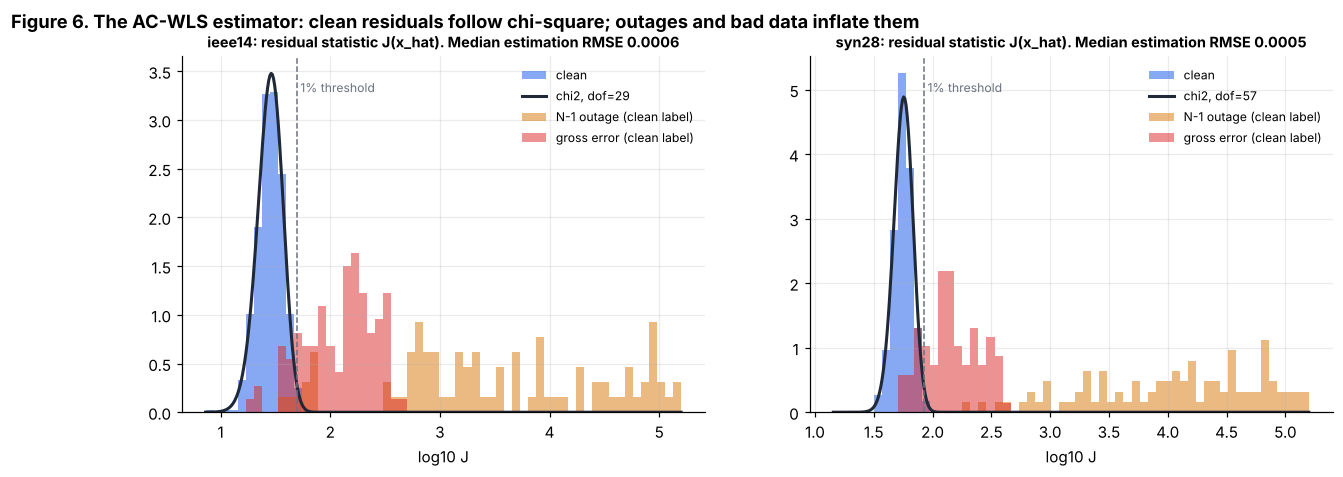

PosixPath('/tmp/w2/proj/figures/fig06_chi2_clean_vs_anomalies.png')

In [14]:
def chi2_study(name, n=500, seed=1):
    sim = SIMS[name]; rng = rng_for("chi2study", seed, *[ord(c) for c in name])
    rec = {"clean": [], "outage": [], "outlier": []}; err = []
    for kind, cnt in [("clean", n), ("outage", n // 5), ("outlier", n // 5)]:
        while len(rec[kind]) < cnt:
            s = new_sample(sim, rng, kind)
            if s is None: continue
            z, V, info = s
            xh, J, r = sim.estimate(z)
            rec[kind].append(J)
            if kind == "clean": err.append(np.sqrt(np.mean((xh - V_to_x(sim.M, V)) ** 2)))
    return rec, np.array(err), sim.mt["m"] - sim.mt["ns"]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
for ax, name in zip(axes, ["ieee14", "syn28"]):
    rec, err, dof = chi2_study(name)
    lg = {k: np.log10(np.maximum(v, 1e-9)) for k, v in rec.items()}
    xs = np.linspace(np.log10(dof) - 0.6, 5.2, 400); xj = 10 ** xs
    bins = np.linspace(xs[0], 5.2, 60)
    ax.hist(lg["clean"], bins=bins, density=True, alpha=0.55, color=PAL["blue"], label="clean")
    ax.plot(xs, st.chi2.pdf(xj, dof) * xj * np.log(10), color=PAL["ink"], lw=2, label=f"chi2, dof={dof}")
    ax.hist(lg["outage"], bins=bins, density=True, alpha=0.5, color=PAL["amber"], label="N-1 outage (clean label)")
    ax.hist(lg["outlier"], bins=bins, density=True, alpha=0.5, color=PAL["red"], label="gross error (clean label)")
    thr = st.chi2.ppf(0.99, dof); ax.axvline(np.log10(thr), color=PAL["grey"], ls="--", lw=1); ax.text(np.log10(thr), ax.get_ylim()[1] * 0.9, " 1% threshold", fontsize=8, color=PAL["grey"])
    ax.set_title(f"{name}: residual statistic J(x_hat). Median estimation RMSE {np.median(err):.4f}", fontsize=9.5)
    ax.set_xlabel("log10 J"); ax.legend(fontsize=8, loc="upper right")
    print(f"{name}: clean J mean {np.mean(rec['clean']):.1f} (chi2 mean {dof}), "
          f"outage median {np.median(rec['outage']):.0f}, outlier median {np.median(rec['outlier']):.0f}")
fig.suptitle("Figure 6. The AC-WLS estimator: clean residuals follow chi-square; outages and bad data inflate them",
             x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig06_chi2_clean_vs_anomalies")

## Part 5. Natural variability and the hardness scale

Hardness needs $\Sigma$, the covariance of the *clean* state estimate. It is estimated per grid from a **calibration set** of natural operating conditions (regime switching, correlated and heavy-tailed loads, renewable ramps), with Ledoit–Wolf shrinkage so that it stays well-conditioned when the number of states approaches the number of samples. Hard negatives (outages, bad data) are excluded from this set, because they are not "natural variability" in the sense of the theory. They are abnormal events that the operator also needs to tell apart from attacks.

The same calibration set doubles as the **clean reference** that any deployed detector can legitimately use (an operator always has unlabeled clean history of their own grid).

In [15]:
class Calib:
    """Clean-reference statistics for one grid."""
    def __init__(self, sim, n, seed=0):
        rng = rng_for("calib", seed, *[ord(c) for c in sim.g.name])
        X, J = [], []
        while len(X) < n:
            s = new_sample(sim, rng, "clean")
            if s is None: continue
            z, V, _ = s; xh, j, r = sim.estimate(z); X.append(xh); J.append(j)
        self.X = np.array(X); self.J = np.array(J)
        self.mu = self.X.mean(0)
        # Plain sample covariance plus a tiny ridge. Ledoit-Wolf shrinkage was tried first and rejected: it shrinks toward a
        # multiple of the identity sized by the *largest* variances, which here inflates the variance of the tightest
        # directions by about 10x (see the design note below) and so under-states how detectable small shifts are.
        Xc = self.X - self.mu
        self.Sigma = (Xc.T @ Xc) / (len(Xc) - 1) + 1e-12 * np.eye(Xc.shape[1]); self.shrink = 0.0
        self.Sinv = np.linalg.inv(self.Sigma)
        self.L = np.linalg.cholesky(self.Sigma)
        w, V_ = np.linalg.eigh(self.Sigma); self.eigval, self.eigvec = w[::-1], V_[:, ::-1]
        self.sd = np.sqrt(np.diag(self.Sigma))
        self.ns = self.X.shape[1]
        self.dof = sim.mt["m"] - sim.mt["ns"]

    def delta(self, c):
        c = np.atleast_2d(c); return np.sqrt(np.einsum("ij,jk,ik->i", c, self.Sinv, c))

t0 = time.time()
CAL = {name: Calib(SIMS[name], SIZES["n_cal"]) for name in TRAIN_FAMILY + UNSEEN}
print(f"calibration sets built in {time.time()-t0:.0f}s")
print(f"{'grid':<10}{'states':>7}{'cond(Sigma)':>13}{'median sd(state)':>18}{'eff. rank':>11}")
for k, c_ in CAL.items():
    pe = c_.eigval / c_.eigval.sum(); er = float(np.exp(-np.sum(pe * np.log(pe + 1e-300))))
    print(f"{k:<10}{c_.ns:>7}{np.linalg.cond(c_.Sigma):>13.1e}{np.median(c_.sd):>18.4f}{er:>11.1f}")

calibration sets built in 31s
grid       states  cond(Sigma)  median sd(state)  eff. rank
ieee14         27      3.2e+06            0.0097        1.0
ieee14_v1      27      1.6e+07            0.0124        1.0
ieee14_v2      27      7.8e+06            0.0160        1.1
ieee30         59      4.5e+06            0.0067        1.9
ieee30_v1      59      6.9e+06            0.0069        1.7
syn20          39      1.1e+07            0.0233        1.5
syn28          55      3.6e+07            0.0188        1.3
syn36          71      1.6e+08            0.0116        1.2
ieee30_v2      59      2.8e+07            0.0082        2.1
syn24u         47      6.0e+07            0.0228        1.3
syn44u         87      2.8e+08            0.0212        1.2
ieee57        113      2.8e+08            0.0395        1.4


### 5.0 Design note: which covariance estimator?

The first version of this pipeline used Ledoit–Wolf shrinkage for $\Sigma$. A feature probe on the first detector run showed why that was wrong *for this problem*: a summary statistic measuring energy in the tightest directions alone reached AUROC 0.94 on attacks the oracle called "hard". The state estimate has a huge dynamic range (largest variance about $10^4$ times the smallest, because the system-wide load factor dominates while the tightest directions are limited only by estimation noise). Shrinkage toward a scaled identity set its floor by the *largest* variances, which was roughly ten times the true noise floor. Clean data then sat far inside the supposed spread in the tight directions, so small shifts there were much more detectable than their nominal hardness said. With $n_{\rm cal}\ge 8\,n_s$ calibration samples a plain sample covariance with a tiny ridge is accurate enough, and it is what the rest of the notebook uses. This kind of estimator choice is exactly what the oracle-referenced framing is meant to expose: a miscalibrated $\Sigma$ shows up as detectors that "beat the oracle".

### 5.1 What does natural variability look like? (Figure 7)

Panel A shows the Gaussian assumption is wrong in a way that matters: heavy-tailed load swings and regime switching make the state distribution non-Gaussian, so the oracle's closed form is an *approximation* here, and Part 10 measures how good an approximation it is. Panel B shows the spectrum of $\Sigma$, which is the "intrinsic dimension" the audit in Part 8 will use. A generator whose state cloud lives in a few dimensions is easy to attack-detect, because almost every direction is "impossible".

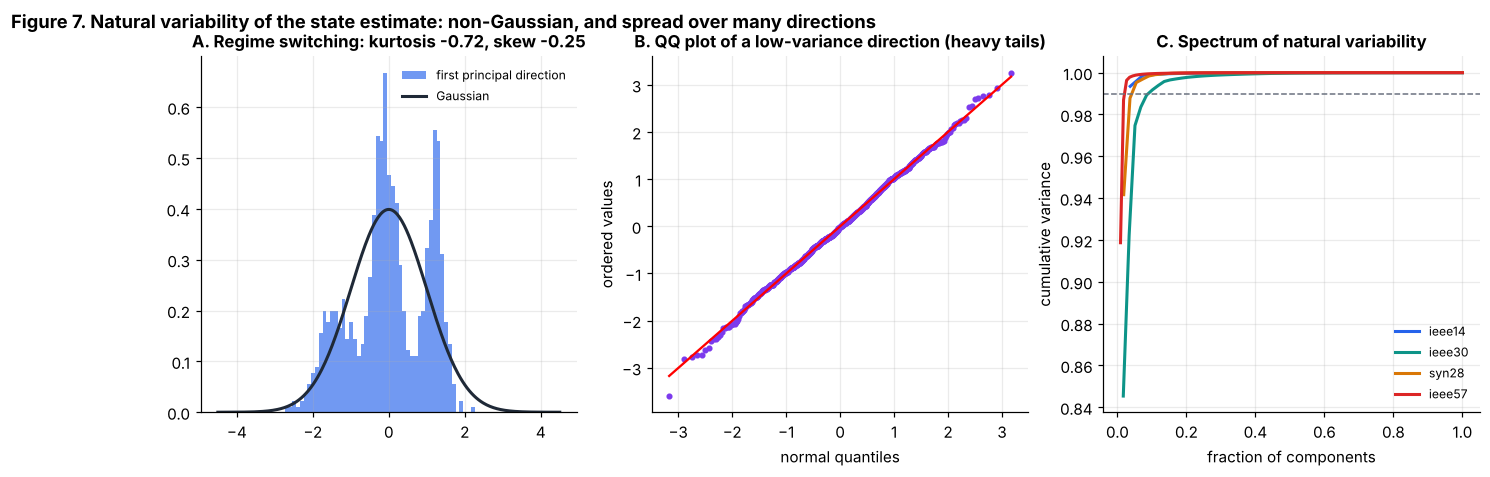

PosixPath('/tmp/w2/proj/figures/fig07_natural_variability.png')

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
c_ = CAL["ieee14"]; sdv = c_.eigvec[:, 0]
proj = (c_.X - c_.mu) @ sdv / np.sqrt(c_.eigval[0])
ax.hist(proj, bins=50, density=True, color=PAL["blue"], alpha=0.65, label="first principal direction")
xx = np.linspace(-4.5, 4.5, 300); ax.plot(xx, st.norm.pdf(xx), color=PAL["ink"], lw=2, label="Gaussian")
ax.set_title(f"A. Regime switching: kurtosis {st.kurtosis(proj):.2f}, skew {st.skew(proj):.2f}"); ax.legend(fontsize=8)
ax = axes[1]
last = (c_.X - c_.mu) @ c_.eigvec[:, -3] / np.sqrt(c_.eigval[-3])
st.probplot(last, dist="norm", plot=ax); ax.get_lines()[0].set_color(PAL["purple"]); ax.get_lines()[0].set_markersize(3)
ax.set_title("B. QQ plot of a low-variance direction (heavy tails)"); ax.set_xlabel("normal quantiles"); ax.set_ylabel("ordered values")
ax = axes[2]
for name, col in [("ieee14", PAL["blue"]), ("ieee30", PAL["teal"]), ("syn28", PAL["amber"]), ("ieee57", PAL["red"])]:
    ev = CAL[name].eigval; ax.plot(np.arange(1, len(ev) + 1) / len(ev), np.cumsum(ev) / ev.sum(), color=col, label=name, lw=2)
ax.axhline(0.99, color=PAL["grey"], ls="--", lw=1); ax.set_xlabel("fraction of components"); ax.set_ylabel("cumulative variance")
ax.set_title("C. Spectrum of natural variability"); ax.legend(fontsize=8)
fig.suptitle("Figure 7. Natural variability of the state estimate: non-Gaussian, and spread over many directions", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig07_natural_variability")

## Part 6. Attack library

An attack is specified by a state shift $c$ and an attacker model. The attacker never touches the state directly; they add a vector $a$ to the meter readings, and we then measure the *realized* shift $c_{\rm eff}=\hat x_{\rm attacked}-\hat x_{\rm clean}$ of the estimator on the same noise realization. Every hardness reported below uses this realized shift, not the nominal one.

| Attacker model | How $a$ is built | What it knows |
|---|---|---|
| `linear` | $a=H_{\rm nom}c$ with the nominal-point Jacobian | the topology and nominal operating point |
| `ac` | $a=h(\hat x_0+c)-h(\hat x_0)$ with $\hat x_0$ the attacker's own estimate | the full AC measurement model and live readings |
| `partial` | $a=\tilde H c$, $\tilde H$ = nominal Jacobian with 10% random error | an imperfect model |

| Direction of $c$ | Description |
|---|---|
| `sparse` | 1 to 4 compromised buses (angle, and voltage with probability 0.5) |
| `dense` | all states |
| `lfc` | $c\propto\Sigma h$, the worst-case direction for the fake tie-line flow $h^\top c$ (Part 12) |

The *size* of $c$ is set in one of two ways. **Hardness-stratified** sampling draws $\delta$ log-uniformly on $[0.25,6]$ and rescales $c$ to exactly that hardness (used for every test set, so that every hardness bin is populated). **Uniform-magnitude** sampling draws a state-unit magnitude $m\sim U(0.1,3)$ standard deviations and does not control $\delta$; it imitates how many published generators scale their attacks, and it is the comparison arm for method A in Part 13.

In [17]:
def tie_sensitivity(sim):
    """h such that fake tie-line flow (area0 -> area1, pu) = h @ c, from the nominal Jacobian."""
    g, M = sim.g, sim.M
    Hf = meas_jac(M, sim.V0)
    h = np.zeros(2 * g.n - 1)
    for k in g.meta["tie"]:
        sgn = 1.0 if g.area[g.f[k]] == 0 else -1.0
        h += sgn * Hf[3 * g.n + k]
    return h

for name, sim in SIMS.items():
    sim.h_tie = tie_sensitivity(sim)
    sim.H_nom = meas_jac(sim.M, sim.V0)[sim.mt["sel"]]

def make_direction(sim, cal, rng, kind):
    ns = cal.ns; n = sim.g.n
    if kind == "dense":
        u = rng.normal(size=ns)
    elif kind == "lfc":
        u = cal.Sigma @ sim.h_tie * rng.choice([-1, 1])      # exact worst-case direction for the fake tie flow
    else:   # sparse
        k = int(rng.integers(1, 5)); buses = rng.choice(n, size=min(k, n), replace=False)
        idx = []
        for b_ in buses:
            if b_ != sim.M.ref: idx.append(int(np.where(sim.M.nonref == b_)[0][0]))
            if rng.random() < 0.5: idx.append(n - 1 + int(b_))
        if not idx: idx = [n - 1 + int(buses[0])]
        u = np.zeros(ns); u[idx] = rng.normal(size=len(idx))
    return u

def set_size(cal, u, rng, mode, delta_range=(0.25, 6.0)):
    if mode == "strat":
        d = np.exp(rng.uniform(np.log(delta_range[0]), np.log(delta_range[1])))
        return u * d / cal.delta(u)[0]
    # uniform magnitude in state units (standard deviations), direction not rescaled for hardness
    m = rng.uniform(0.1, 3.0)
    uu = u / (np.linalg.norm(u / cal.sd) + 1e-12)
    return m * uu

def apply_attack(sim, cal, rng, z, c, model):
    """Return attacked measurement vector for attacker model in {linear, ac, partial}."""
    if model == "ac":
        xh0, _, _ = sim.estimate(z)
        a = (meas_h(sim.M, x_to_V(sim.M, xh0 + c)) - meas_h(sim.M, x_to_V(sim.M, xh0)))[sim.mt["sel"]]
    elif model == "partial":
        Ht = sim.H_nom * (1 + 0.10 * rng.normal(size=sim.H_nom.shape)); a = Ht @ c
    else:
        a = sim.H_nom @ c
    return z + a

DIR_P = dict(sparse=0.60, dense=0.20, lfc=0.20)
MODEL_P = dict(linear=0.45, ac=0.40, partial=0.15)

def attacked_sample(sim, cal, rng, size_mode="strat", model=None, kind=None):
    for _ in range(10):
        s = new_sample(sim, rng, "clean")
        if s is None: continue
        z, V, _ = s
        kind_ = kind or rng.choice(list(DIR_P), p=list(DIR_P.values()))
        model_ = model or rng.choice(list(MODEL_P), p=list(MODEL_P.values()))
        u = make_direction(sim, cal, rng, kind_)
        c = set_size(cal, u, rng, size_mode)
        za = apply_attack(sim, cal, rng, z, c, model_)
        xh0, J0, _ = sim.estimate(z); xh1, J1, r1 = sim.estimate(za)
        c_eff = xh1 - xh0
        return dict(x=xh1, J=J1, rmax=float(np.max(np.abs(r1) / sim.mt["sigma"])), shift=c_eff, dirkind=kind_, model=model_,
                    dJ=J1 - J0, x_clean=xh0)
    return None

### 6.1 Do the attacks do what the theory says? (Figure 8)

Four claims are checked on IEEE 14 with 300 attacks per attacker model.

1. A **linear** null-space attack changes the AC residual only slightly (second-order effect of the nonlinearity), so the chi-square test misses it unless the shift is large.
2. An **AC-consistent** attack leaves the residual essentially unchanged at any size.
3. The realized shift $c_{\rm eff}$ matches the requested $c$ (the attack lands where it was aimed).
4. **Uniform-magnitude** sampling gives a very different hardness distribution from **hardness-stratified** sampling.

chi2 dof=29, 1% threshold=49.6

  model   n  median_J  alarm_rate_1pct  alarm_rate_delta_lt2  alarm_rate_delta_gt4
 linear 300    29.384            0.070                 0.012                 0.388
     ac 300    28.686            0.013                 0.010                 0.062
partial 300    32.003            0.233                 0.026                 0.647


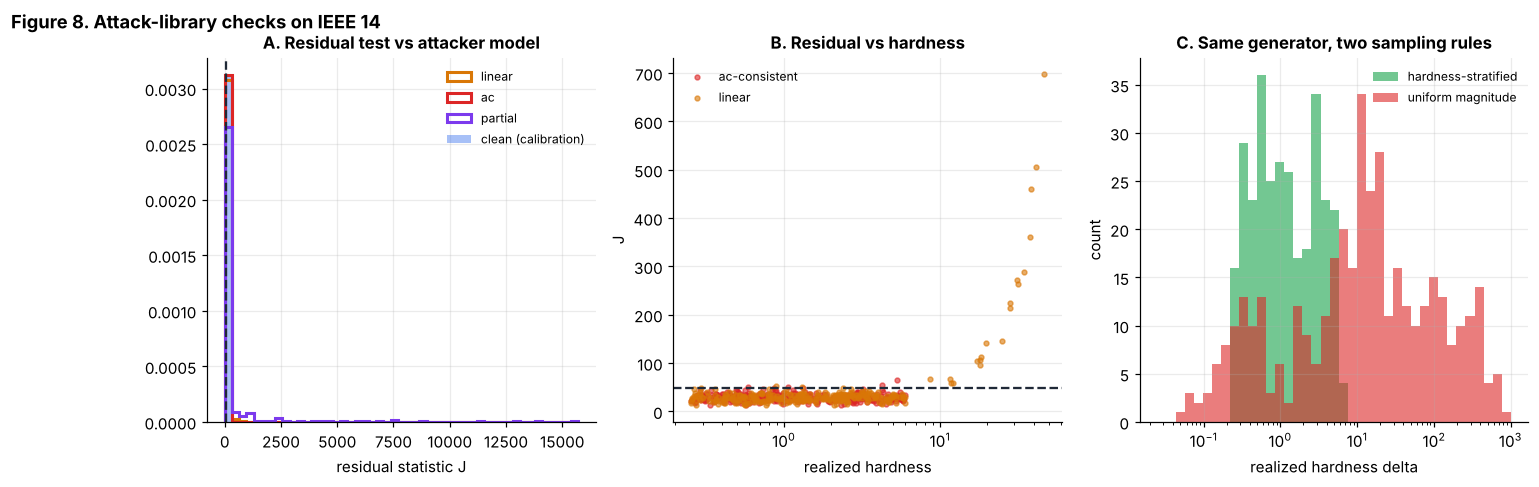


uniform-magnitude hardness: median 12.08, share below 2: 23.75%, share above 6: 65.25%


In [18]:
rng = rng_for("attack_check"); sim, cal = SIMS["ieee14"], CAL["ieee14"]
recs = {m: [] for m in ["linear", "ac", "partial"]}
for m in recs:
    for _ in range(300):
        a_ = attacked_sample(sim, cal, rng, "strat", model=m)
        if a_ is None: continue
        a_["delta_eff"] = float(cal.delta(a_["shift"])[0]); recs[m].append(a_)
thr = st.chi2.ppf(0.99, cal.dof)
rows = []
for m, lst in recs.items():
    dJ = np.array([a["J"] for a in lst]); dl = np.array([a["delta_eff"] for a in lst])
    rows.append(dict(model=m, n=len(lst), median_J=np.median(dJ), alarm_rate_1pct=np.mean(dJ > thr),
                     alarm_rate_delta_lt2=np.mean(dJ[dl < 2] > thr), alarm_rate_delta_gt4=np.mean(dJ[dl > 4] > thr)))
print(f"chi2 dof={cal.dof}, 1% threshold={thr:.1f}\n")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# uniform-magnitude hardness distribution
mag = [attacked_sample(sim, cal, rng, "mag") for _ in range(400)]
d_mag = np.array([cal.delta(a["shift"])[0] for a in mag if a is not None])

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))
ax = axes[0]
bins = np.linspace(0, np.percentile(np.r_[[a["J"] for m in recs for a in recs[m]]], 98), 50)
for m, col in zip(recs, [PAL["amber"], PAL["red"], PAL["purple"]]):
    ax.hist([a["J"] for a in recs[m]], bins=bins, density=True, histtype="step", lw=2, color=col, label=m)
ax.hist(cal.J, bins=bins, density=True, alpha=0.4, color=PAL["blue"], label="clean (calibration)")
ax.axvline(thr, color=PAL["ink"], ls="--"); ax.set_xlabel("residual statistic J"); ax.set_title("A. Residual test vs attacker model"); ax.legend(fontsize=8)
ax = axes[1]
req = np.array([cal.delta(a["shift"])[0] for a in recs["ac"]])
ax.scatter(req, [a["J"] for a in recs["ac"]], s=10, color=PAL["red"], alpha=0.6, label="ac-consistent")
ax.scatter(np.array([a["delta_eff"] for a in recs["linear"]]), [a["J"] for a in recs["linear"]], s=10, color=PAL["amber"], alpha=0.6, label="linear")
ax.axhline(thr, color=PAL["ink"], ls="--"); ax.set_xscale("log"); ax.set_xlabel("realized hardness"); ax.set_ylabel("J"); ax.set_title("B. Residual vs hardness"); ax.legend(fontsize=8)
ax = axes[2]
lb = np.logspace(-1.6, 3, 40)
ax.hist(np.array([a["delta_eff"] for a in recs["ac"]]), bins=lb, alpha=0.6, color=PAL["green"], label="hardness-stratified")
ax.hist(d_mag, bins=lb, alpha=0.6, color=PAL["red"], label="uniform magnitude")
ax.set_xscale("log"); ax.set_xlabel("realized hardness delta"); ax.set_ylabel("count"); ax.set_title("C. Same generator, two sampling rules"); ax.legend(fontsize=8)
fig.suptitle("Figure 8. Attack-library checks on IEEE 14", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig08_attack_checks")
print(f"\nuniform-magnitude hardness: median {np.median(d_mag):.2f}, share below 2: {np.mean(d_mag<2):.2%}, share above 6: {np.mean(d_mag>6):.2%}")

### 6.2 Anatomy of one attack (Figure 9)

A concrete attack on IEEE 14, shown in all three spaces the study works in: the state shift (what the attacker aims at), the meter changes (what the attacker has to forge), and the estimated state (what the operator sees). Note panel A: a hardness-3 attack on a single bus angle is a *tiny* fraction of that angle's marginal standard deviation. Hardness is not marginal size. Natural variability is strongly correlated across buses, so an isolated angle shift is far outside the correlation pattern even when it is small in absolute terms.

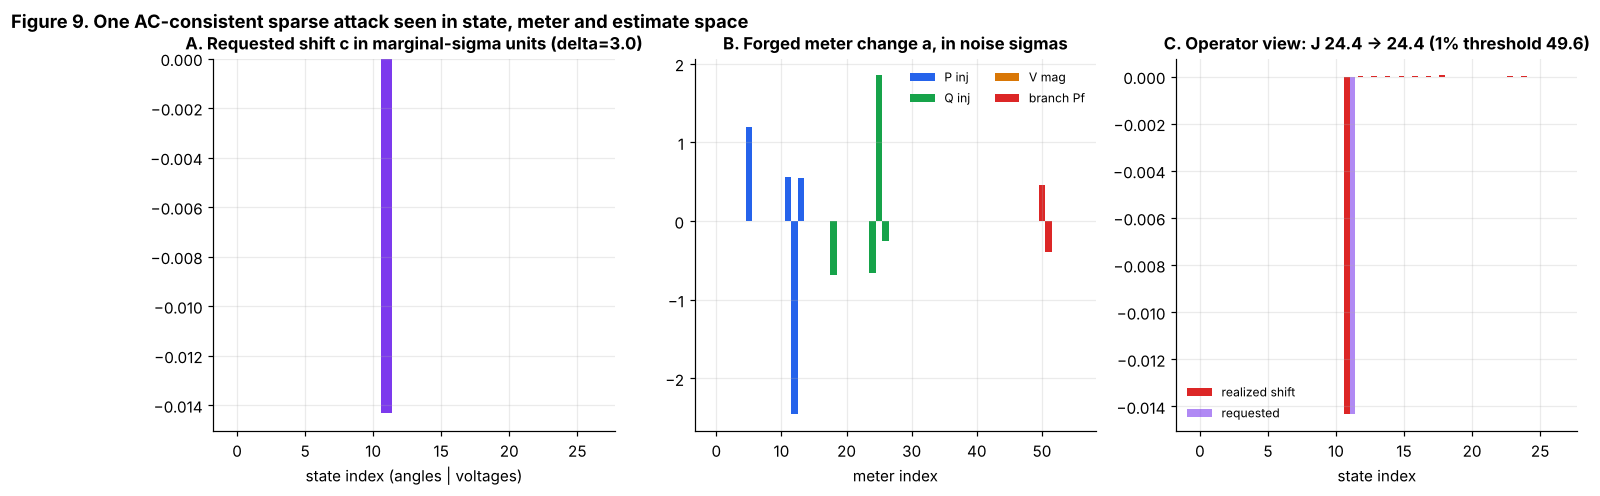

PosixPath('/tmp/w2/proj/figures/fig09_attack_anatomy.png')

In [19]:
rng = rng_for("anatomy"); sim, cal = SIMS["ieee14"], CAL["ieee14"]
while True:
    s = new_sample(sim, rng, "clean")
    if s is None: continue
    z, V, _ = s
    u = make_direction(sim, cal, rng, "sparse"); c = u * 3.0 / cal.delta(u)[0]
    za = apply_attack(sim, cal, rng, z, c, "ac")
    break
xh0, J0, r0 = sim.estimate(z); xh1, J1, r1 = sim.estimate(za)
n = sim.g.n
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
ax = axes[0]; lab = [f"th{b}" for b in sim.M.nonref] + [f"V{b}" for b in range(n)]
ax.bar(np.arange(len(c)), c / cal.sd, color=[PAL["purple"] if i < n - 1 else PAL["teal"] for i in range(len(c))])
ax.set_title(f"A. Requested shift c in marginal-sigma units (delta={cal.delta(c)[0]:.1f})"); ax.set_xlabel("state index (angles | voltages)")
ax = axes[1]; a_vec = za - z; typ = sim.mt["types"]
for t_, nm, col in zip(range(4), ["P inj", "Q inj", "V mag", "branch Pf"], [PAL["blue"], PAL["green"], PAL["amber"], PAL["red"]]):
    idx = np.where(typ == t_)[0]; ax.bar(idx, a_vec[idx] / sim.mt["sigma"][idx], color=col, label=nm, width=1.0)
ax.set_title("B. Forged meter change a, in noise sigmas"); ax.set_xlabel("meter index"); ax.legend(fontsize=8, ncol=2)
ax = axes[2]
ax.bar(np.arange(len(c)) - 0.2, (xh1 - xh0) / cal.sd, width=0.4, color=PAL["red"], label="realized shift")
ax.bar(np.arange(len(c)) + 0.2, c / cal.sd, width=0.4, color=PAL["purple"], alpha=0.6, label="requested")
ax.set_title(f"C. Operator view: J {J0:.1f} -> {J1:.1f} (1% threshold {thr:.1f})"); ax.legend(fontsize=8); ax.set_xlabel("state index")
fig.suptitle("Figure 9. One AC-consistent sparse attack seen in state, meter and estimate space", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig09_attack_anatomy")

## Part 7. Dataset assembly

Each grid gets five sets, all generated from separately named random streams:

| Set | Content | Used for |
|---|---|---|
| `cal` | natural clean windows (Part 5) | $\mu,\Sigma$, clean reference, one-class training |
| `train` | half clean (including 5% outages, 5% bad data), half hardness-stratified attacks | supervised training |
| `train_mag` | the same number of attacks sampled by uniform magnitude, to pair with the clean half of `train` | method A comparison |
| `train_extra` (two study grids only) | a second block of `train`, to give training pools of 1,800 and 3,600 | label-budget curves |
| `test` | half clean (with hard negatives), half hardness-stratified attacks | everything that is reported |

Each row stores the state estimate $\hat x$, the residual statistic $J$, the largest normalised residual, the label, the kind (`natural`, `outage`, `outlier`, `attack`), and for attacks the realised shift $c_{\rm eff}$, realised hardness, attacker model, direction kind, and fake tie-line flow $h^\top c_{\rm eff}$. The shift vectors are *privileged information*: detectors never see them, but the oracle and the distillation teacher do.

Generation is cached in `data/` so a rerun skips this step unless `BUDGET` changes.

In [20]:
def gen_clean_block(sim, cal, rng, n, hn=(0.05, 0.05)):
    kinds = rng.choice(["natural", "outage", "outlier"], size=n, p=[1 - sum(hn), hn[0], hn[1]])
    X, J, R = [], [], []
    for k in kinds:
        s = None
        while s is None: s = new_sample(sim, rng, {"natural": "clean"}.get(k, k))
        z, V, _ = s; xh, j, r = sim.estimate(z)
        X.append(xh); J.append(j); R.append(np.max(np.abs(r) / sim.mt["sigma"]))
    return dict(x=np.array(X), J=np.array(J), rmax=np.array(R), label=np.zeros(n, int), kind=kinds,
                delta=np.full(n, np.nan), shift=np.zeros((n, cal.ns)), flow=np.zeros(n),
                model=np.array([""] * n), dirkind=np.array([""] * n))

def gen_attack_block(sim, cal, rng, n, size_mode):
    rec = []
    while len(rec) < n:
        a = attacked_sample(sim, cal, rng, size_mode)
        if a is not None: rec.append(a)
    sh = np.array([a["shift"] for a in rec])
    return dict(x=np.array([a["x"] for a in rec]), J=np.array([a["J"] for a in rec]), rmax=np.array([a["rmax"] for a in rec]),
                label=np.ones(n, int), kind=np.array(["attack"] * n), delta=cal.delta(sh), shift=sh, flow=sh @ sim.h_tie,
                model=np.array([a["model"] for a in rec]), dirkind=np.array([a["dirkind"] for a in rec]))

def concat_blocks(*blocks):
    return {k: np.concatenate([b[k] for b in blocks]) for k in blocks[0]}

STUDY_GRIDS = ["ieee14", "syn28"]     # grids used for the in-grid oracle-gap study (Part 10)

def build_grid_data(name):
    sim, cal = SIMS[name], CAL[name]; n_tr, n_te = SIZES["n_train"], SIZES["n_test"]
    d = {}
    for role, size in [("train", n_tr), ("test", n_te)] + ([("train_extra", n_tr)] if name in STUDY_GRIDS else []):
        rng = rng_for("set", ord(role[0]) + len(role), *[ord(c) for c in name])
        d[role] = concat_blocks(gen_clean_block(sim, cal, rng, size // 2), gen_attack_block(sim, cal, rng, size // 2, "strat"))
    rng = rng_for("set_mag", *[ord(c) for c in name])
    d["train_mag"] = gen_attack_block(sim, cal, rng, n_tr // 2, "mag")
    return d

cache = DATA / f"datasets_{BUDGET}.pkl"
if cache.exists():
    with open(cache, "rb") as fh: DS = pickle.load(fh)
    print("loaded cached datasets:", cache.name)
else:
    DS = {}; t0 = time.time()
    for name in TRAIN_FAMILY + UNSEEN:
        t1 = time.time(); DS[name] = build_grid_data(name)
        print(f"{name:<10} built in {time.time()-t1:5.1f}s", flush=True)
    with open(cache, "wb") as fh: pickle.dump(DS, fh)
    print(f"total {time.time()-t0:.0f}s, cached to {cache.name}")

rows = []
for name, d in DS.items():
    te = d["test"]
    rows.append(dict(grid=name, role="UNSEEN" if name in UNSEEN else "family", states=CAL[name].ns, n_train=len(d["train"]["label"]),
                     n_test=len(te["label"]), attacks=int(te["label"].sum()),
                     outage=int((te["kind"] == "outage").sum()), outlier=int((te["kind"] == "outlier").sum()),
                     delta_med=float(np.nanmedian(te["delta"]))))
print(pd.DataFrame(rows).round(2).to_string(index=False))

loaded cached datasets: datasets_full.pkl
     grid   role  states  n_train  n_test  attacks  outage  outlier  delta_med
   ieee14 family      27     1800    1800      900      50       39       1.51
ieee14_v1 family      27     1800    1800      900      43       53       1.64
ieee14_v2 family      27     1800    1800      900      34       53       1.48
   ieee30 family      59     1800    1800      900      50       55       1.32
ieee30_v1 family      59     1800    1800      900      34       41       1.24
    syn20 family      39     1800    1800      900      47       47       1.43
    syn28 family      55     1800    1800      900      48       32       1.33
    syn36 family      71     1800    1800      900      54       47       1.50
ieee30_v2 UNSEEN      59     1800    1800      900      47       45       1.37
   syn24u UNSEEN      47     1800    1800      900      40       53       1.40
   syn44u UNSEEN      87     1800    1800      900      43       36       1.43
   ieee57 

### 7.1 Dataset overview (Figure 10)

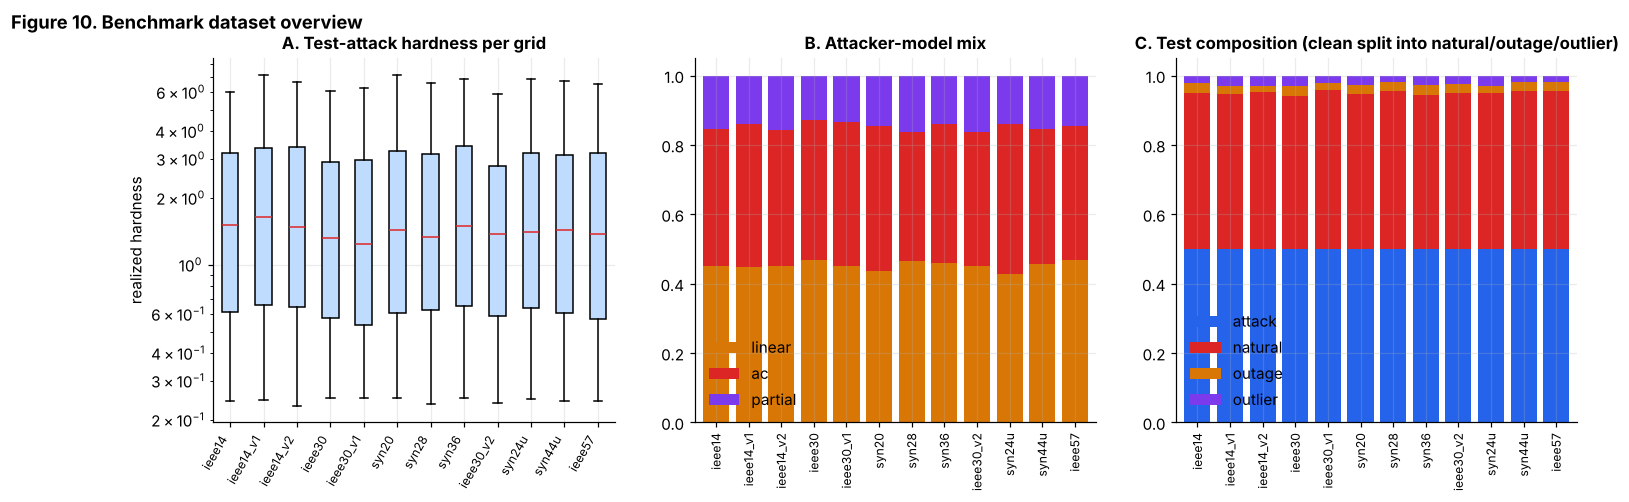

PosixPath('/tmp/w2/proj/figures/fig10_dataset_overview.png')

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
ax = axes[0]
names = list(DS.keys())
dl = [DS[k]["test"]["delta"][DS[k]["test"]["label"] == 1] for k in names]
ax.boxplot(dl, vert=True, showfliers=False, patch_artist=True, boxprops=dict(facecolor="#bfdbfe"), medianprops=dict(color=PAL["red"]))
ax.set_xticks(range(1, len(names) + 1)); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8); ax.set_yscale("log")
ax.set_ylabel("realized hardness"); ax.set_title("A. Test-attack hardness per grid")
ax = axes[1]
mix = pd.DataFrame([{"grid": k, **pd.Series(DS[k]["test"]["model"][DS[k]["test"]["label"] == 1]).value_counts(normalize=True).to_dict()} for k in names]).set_index("grid")
mix.plot(kind="bar", stacked=True, ax=ax, color=[PAL["amber"], PAL["red"], PAL["purple"]], width=0.8, legend=True)
ax.set_title("B. Attacker-model mix"); ax.set_xlabel(""); ax.tick_params(axis="x", labelsize=8)
ax = axes[2]
kinds = pd.DataFrame([{"grid": k, **pd.Series(DS[k]["test"]["kind"]).value_counts().to_dict()} for k in names]).set_index("grid")
(kinds / kinds.sum(1).values[:, None]).plot(kind="bar", stacked=True, ax=ax, color=[PAL["blue"], PAL["red"], PAL["amber"], PAL["purple"]], width=0.8)
ax.set_title("C. Test composition (clean split into natural/outage/outlier)"); ax.set_xlabel(""); ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Figure 10. Benchmark dataset overview", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig10_dataset_overview")

## Part 8. Detectors, features and the evaluation harness

### 8.1 Two input views

* **In-grid view.** The whitened state estimate $w=L^{-1}(\hat x-\mu)$ (with $\Sigma=LL^\top$ from the grid's own clean calibration set) plus two residual features. This view has one dimension per state, so a model is tied to one grid. It is the fair arena for the oracle-gap study.
* **Grid-agnostic view.** A fixed-length vector of twelve summary statistics (total energy $T^2$, energy in the high-, mid- and low-variance parts of the spectrum, the four largest whitened components, kurtosis, energy in the three smallest components, the residual statistic and the largest normalised residual). Every statistic is computed against the *target grid's own clean reference*, which an operator always has. This view lets one model run on a grid it was never trained on, so it is the one used in Part 11.

Both views use only information a deployed detector has: $\hat x$, $J(\hat x)$ and the residuals, plus clean history. The attack shift $c$ is never an input.

In [22]:
def whiten(cal, X):
    return np.linalg.solve(cal.L, (X - cal.mu).T).T

def spectral_energy(cal, X):
    """Whitened components along the eigenvectors of Sigma: p_j = v_j'(x-mu)/sqrt(lambda_j)."""
    return ((X - cal.mu) @ cal.eigvec) / np.sqrt(cal.eigval)

def summary_features(cal, d):
    p = spectral_energy(cal, d["x"]); ns = p.shape[1]; e = p ** 2
    g1, g2 = max(1, ns // 4), max(1, ns // 4)
    def z(sumv, k): return (sumv - k) / np.sqrt(2 * k)
    T2 = e.sum(1)
    top = z(e[:, :g1].sum(1), g1); bot = z(e[:, -g2:].sum(1), g2); mid = z(e[:, g1:ns - g2].sum(1), max(1, ns - g1 - g2))
    last3 = z(e[:, -3:].sum(1), 3)
    ap = np.sort(np.abs(p), 1)[:, ::-1][:, :4]
    kurt = st.kurtosis(p, axis=1)
    zJ = (d["J"] - cal.dof) / np.sqrt(2 * cal.dof)
    return np.column_stack([z(T2, ns), top, mid, bot, last3, ap, kurt, zJ, np.log(d["rmax"] + 1e-9)])

def indomain_features(cal, d):
    zJ = (d["J"] - cal.dof) / np.sqrt(2 * cal.dof)
    return np.column_stack([whiten(cal, d["x"]), zJ, np.log(d["rmax"] + 1e-9)])

def subsample_balanced(d, n, rng):
    """n rows, half clean and half attacked, drawn without replacement from a pooled set."""
    ic, ia = np.where(d["label"] == 0)[0], np.where(d["label"] == 1)[0]
    pick = np.r_[rng.choice(ic, n // 2, replace=False), rng.choice(ia, n // 2, replace=False)]
    return {k: v[pick] for k, v in d.items()}

def drop_hard_negatives(d):
    keep = ~np.isin(d["kind"], ["outage", "outlier"])
    return {k: v[keep] for k, v in d.items()}

### 8.2 Detector zoo

| Detector | Type | Uses labels? | Input |
|---|---|---|---|
| `chi2` | classical bad-data test | no | $J(\hat x)$ |
| `hotelling` | clean-only generalized test | no | $T^2$ of $\hat x$ |
| `pca_recon` | clean-only subspace test | no | reconstruction error outside the top PCs (standardised state) |
| `iforest` | clean-only isolation forest | no | whitened $\hat x$ |
| `logreg` | linear supervised | yes | in-grid view |
| `gbdt` | gradient-boosted trees | yes | in-grid view |
| `mlp` | multilayer perceptron | yes | in-grid view |
| `gbdt_sum`, `mlp_sum`, `logreg_sum` | supervised, grid-agnostic | yes | summary view |
| `oracle` | *privileged*: knows the attack shift $c$ | n/a | $\hat x$ and $c$ |

All supervised detectors get the **same tuning budget**: `rs_trials` random-search trials scored by validation AUROC on a 30% split of the training data, then refit on the full training set with the winning configuration. This is deliberately modest. The point of equal tuning is that no arm gets an advantage, not that any arm is maximally tuned.

In [23]:
class Detector:
    name = "base"; supervised = False
    def fit(self, cal, train, seed=0): return self
    def score(self, cal, d): raise NotImplementedError

class Chi2(Detector):
    name = "chi2"
    def score(self, cal, d): return d["J"]

class Hotelling(Detector):
    name = "hotelling"
    def score(self, cal, d): return (whiten(cal, d["x"]) ** 2).sum(1)

class PCARecon(Detector):
    name = "pca_recon"
    def fit(self, cal, train=None, seed=0):
        self.p = PCA(n_components=0.95, svd_solver="full").fit((cal.X - cal.mu) / cal.sd); return self
    def score(self, cal, d):
        Z = (d["x"] - cal.mu) / cal.sd
        return ((Z - self.p.inverse_transform(self.p.transform(Z))) ** 2).sum(1)

class IForest(Detector):
    name = "iforest"
    def fit(self, cal, train=None, seed=0):
        self.m = IsolationForest(n_estimators=200, max_samples=256, random_state=seed).fit(whiten(cal, cal.X)); return self
    def score(self, cal, d): return -self.m.score_samples(whiten(cal, d["x"]))

def _logU(rng, lo, hi): return float(np.exp(rng.uniform(np.log(lo), np.log(hi))))

class Supervised(Detector):
    supervised = True
    view = "in"
    def feats(self, cal, d): return indomain_features(cal, d) if self.view == "in" else summary_features(cal, d)
    def make(self, rng): raise NotImplementedError
    def fit(self, cal, train, seed=0, trials=None):
        return self._fit_xy(self.feats(cal, train), train["label"], seed, trials)
    def _fit_xy(self, X, y, seed=0, trials=None):
        """Random-search tuning on a 30% validation split, then refit on everything with the winner."""
        trials = trials or SIZES["rs_trials"]; rng = np.random.default_rng(seed)
        if getattr(self, "scale", False): self.sc = StandardScaler().fit(X); X = self.sc.transform(X)
        idx = rng.permutation(len(y)); nv = int(0.3 * len(y)); va, tr = idx[:nv], idx[nv:]
        best, best_auc = None, -1
        for t in range(trials):
            m = self.make(rng, t)
            try:
                m.fit(X[tr], y[tr]); a = roc_auc_score(y[va], self._p(m, X[va]))
            except Exception:
                a = -1
            if a > best_auc: best, best_auc = m, a
        self.model = best; self.val_auc = best_auc
        self.model.fit(X, y)            # refit on everything with the winning configuration
        return self
    def _p(self, m, X): return m.predict_proba(X)[:, 1]
    def score(self, cal, d):
        X = self.feats(cal, d)
        if hasattr(self, "sc"): X = self.sc.transform(X)
        return self._p(self.model, X)

class LogReg(Supervised):
    name = "logreg"; scale = True
    def make(self, rng, t): return LogisticRegression(C=_logU(rng, 1e-3, 10), max_iter=400)

class GBDT(Supervised):
    name = "gbdt"
    def make(self, rng, t):
        return HistGradientBoostingClassifier(learning_rate=_logU(rng, 0.03, 0.3), max_leaf_nodes=int(rng.choice([15, 31, 63])),
                                              l2_regularization=_logU(rng, 1e-3, 10), max_iter=250, early_stopping=True,
                                              validation_fraction=0.15, n_iter_no_change=15, random_state=int(rng.integers(1e6)))

class MLP(Supervised):
    name = "mlp"; scale = True
    def make(self, rng, t):
        h = [(64,), (128, 64), (256, 128)][int(rng.integers(3))]
        return MLPClassifier(hidden_layer_sizes=h, alpha=_logU(rng, 1e-5, 1e-2), learning_rate_init=_logU(rng, 1e-4, 3e-3),
                             max_iter=250, early_stopping=True, n_iter_no_change=12, random_state=int(rng.integers(1e6)))

class LogRegSum(LogReg): name = "logreg_sum"; view = "sum"
class GBDTSum(GBDT):     name = "gbdt_sum";   view = "sum"
class MLPSum(MLP):       name = "mlp_sum";    view = "sum"

### 8.3 The oracle, per attack

For an attacked window $i$ with realized shift $c_i$, the oracle score is $s_i=c_i^\top\Sigma^{-1}(\hat x_i-\mu)$. To place it on a ROC it must be compared with clean windows *scored in the same direction*: $s_{ij}=c_i^\top\Sigma^{-1}(\hat x_j-\mu)$ for each clean window $j$. The per-attack AUROC is the fraction of clean windows whose score falls below $s_i$. Averaging over the attacks in a hardness bin gives the bin's oracle AUROC, and the closed form $\Phi(\delta/\sqrt2)$ is the Gaussian prediction for it. Where the two differ, the Gaussian assumption is failing, and the *empirical* oracle (not the formula) is the honest yardstick.

The oracle sees the true shift but *not* the labels' source (it scores clean windows too), so it is an upper reference for a detector that knows the attack direction.

In [24]:
def oracle_scores(cal, d_test):
    """Return (per-attack AUROC array, attack deltas, attack flow) using the realized shifts."""
    ia = np.where(d_test["label"] == 1)[0]; ic = np.where(d_test["label"] == 0)[0]
    C = d_test["shift"][ia]; Xa = d_test["x"][ia] - cal.mu; Xc = d_test["x"][ic] - cal.mu
    CS = C @ cal.Sinv                                    # (na, ns)
    s_att = np.einsum("ij,ij->i", CS, Xa)                # (na,)
    s_clean = CS @ Xc.T                                  # (na, nc)
    auc = (s_att[:, None] > s_clean).mean(1) + 0.5 * (s_att[:, None] == s_clean).mean(1)
    return auc, d_test["delta"][ia], s_att

BIN_EDGES = np.array([0.25, 0.5, 1.0, 2.0, 4.0, 6.5])
BIN_NAMES = [f"{BIN_EDGES[i]:g}-{BIN_EDGES[i+1]:g}" for i in range(len(BIN_EDGES) - 1)]

def auc_by_bin(score_test, d_test, edges=BIN_EDGES):
    """AUROC of each hardness bin's attacks versus ALL clean test windows."""
    ia = np.where(d_test["label"] == 1)[0]; ic = np.where(d_test["label"] == 0)[0]
    out = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        sel = ia[(d_test["delta"][ia] >= lo) & (d_test["delta"][ia] < hi + (1e-9 if hi == edges[-1] else 0))]
        if len(sel) < 5: out.append(np.nan); continue
        out.append(roc_auc_score(np.r_[np.zeros(len(ic)), np.ones(len(sel))], np.r_[score_test[ic], score_test[sel]]))
    return np.array(out)

def oracle_by_bin(cal, d_test, edges=BIN_EDGES):
    auc, dl, _ = oracle_scores(cal, d_test)
    return np.array([auc[(dl >= lo) & (dl < hi + (1e-9 if hi == edges[-1] else 0))].mean()
                     if np.any((dl >= lo) & (dl < hi + (1e-9 if hi == edges[-1] else 0))) else np.nan
                     for lo, hi in zip(edges[:-1], edges[1:])])

def overall_auc(score_test, d_test): return roc_auc_score(d_test["label"], score_test)

def formula_by_bin(d_test, edges=BIN_EDGES):
    dl = d_test["delta"][d_test["label"] == 1]
    return np.array([np.nanmean(oracle_auc(dl[(dl >= lo) & (dl < hi + (1e-9 if hi == edges[-1] else 0))])) if np.any((dl >= lo) & (dl < hi + (1e-9 if hi == edges[-1] else 0))) else np.nan
                     for lo, hi in zip(edges[:-1], edges[1:])])

### 8.4 First look: all detectors on IEEE 14 (Figure 11)

One grid, one seed, the full training set. This cell is a smoke test of the harness and the first look at where the detectors sit relative to the oracle; the controlled study with seeds and label budgets is Part 10.

IEEE 14, 1800 training windows, 6s
                           0.25-0.5  0.5-1    1-2    2-4  4-6.5  overall
chi2                          0.458  0.466  0.463  0.463  0.518    0.498
hotelling                     0.467  0.476  0.528  0.658  0.839    0.599
pca_recon                     0.477  0.462  0.485  0.503  0.545    0.515
iforest                       0.459  0.471  0.512  0.642  0.786    0.583
logreg                        0.560  0.564  0.540  0.508  0.473    0.532
gbdt                          0.542  0.543  0.558  0.674  0.780    0.620
mlp                           0.534  0.539  0.562  0.622  0.715    0.601
ORACLE (empirical)            0.615  0.680  0.824  0.958  0.989      NaN
ORACLE (Gaussian formula)     0.606  0.698  0.843  0.971  0.999      NaN


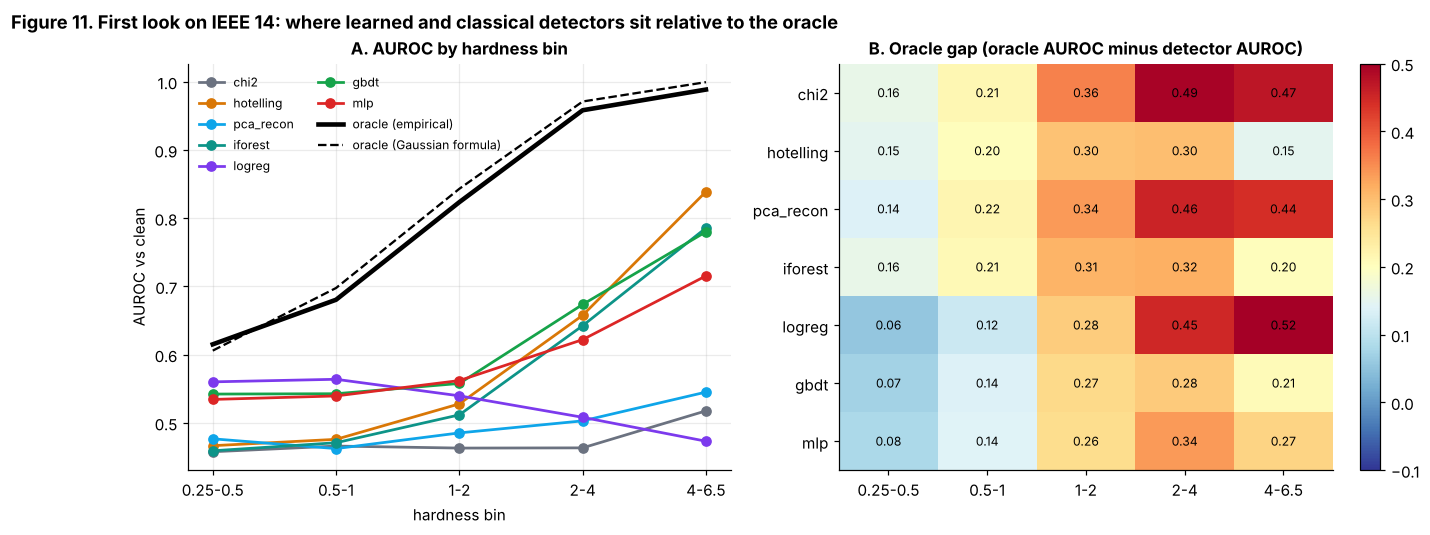

PosixPath('/tmp/w2/proj/figures/fig11_first_look_ieee14.png')

In [25]:
def run_detectors(name, train, test, cal, dets, seed=0):
    res = {}
    for D in dets:
        t0 = time.time(); det = D()
        det.fit(cal, train, seed) if det.supervised else det.fit(cal, None, seed)
        s = det.score(cal, test)
        res[det.name] = dict(bins=auc_by_bin(s, test), overall=overall_auc(s, test), score=s, secs=time.time() - t0,
                             val=getattr(det, "val_auc", np.nan))
    return res

DETS_IN = [Chi2, Hotelling, PCARecon, IForest, LogReg, GBDT, MLP]
t0 = time.time()
name = "ieee14"; cal = CAL[name]
pool = concat_blocks(DS[name]["train"], DS[name]["train_extra"]) if "train_extra" in DS[name] else DS[name]["train"]
res14 = run_detectors(name, DS[name]["train"], DS[name]["test"], cal, DETS_IN)
orc14 = oracle_by_bin(cal, DS[name]["test"]); frm14 = formula_by_bin(DS[name]["test"])
tab = pd.DataFrame({k: v["bins"] for k, v in res14.items()}, index=BIN_NAMES).T
tab["overall"] = [v["overall"] for v in res14.values()]
tab.loc["ORACLE (empirical)"] = list(orc14) + [np.nan]; tab.loc["ORACLE (Gaussian formula)"] = list(frm14) + [np.nan]
print(f"IEEE 14, {len(DS[name]['train']['label'])} training windows, {time.time()-t0:.0f}s")
print(tab.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
xs = np.arange(len(BIN_NAMES)); colors = dict(chi2=PAL["grey"], hotelling=PAL["amber"], pca_recon=PAL["sky"], iforest=PAL["teal"],
                                              logreg=PAL["purple"], gbdt=PAL["green"], mlp=PAL["red"])
for k, v in res14.items(): ax[0].plot(xs, v["bins"], "o-", color=colors[k], label=k, lw=1.8)
ax[0].plot(xs, orc14, "k-", lw=3, label="oracle (empirical)"); ax[0].plot(xs, frm14, "k--", lw=1.5, label="oracle (Gaussian formula)")
ax[0].set_xticks(xs); ax[0].set_xticklabels(BIN_NAMES); ax[0].set_xlabel("hardness bin"); ax[0].set_ylabel("AUROC vs clean")
ax[0].set_title("A. AUROC by hardness bin"); ax[0].legend(fontsize=8, ncol=2)
gap = pd.DataFrame({k: orc14 - v["bins"] for k, v in res14.items()}, index=BIN_NAMES)
im = ax[1].imshow(gap.T.values, cmap="RdYlBu_r", vmin=-0.1, vmax=0.5, aspect="auto")
ax[1].set_xticks(xs); ax[1].set_xticklabels(BIN_NAMES); ax[1].set_yticks(range(len(gap.columns))); ax[1].set_yticklabels(gap.columns)
for i in range(gap.shape[1]):
    for j in range(gap.shape[0]): ax[1].text(j, i, f"{gap.values[j, i]:.2f}", ha="center", va="center", fontsize=8)
ax[1].set_title("B. Oracle gap (oracle AUROC minus detector AUROC)"); ax[1].grid(False); plt.colorbar(im, ax=ax[1], fraction=0.04)
fig.suptitle("Figure 11. First look on IEEE 14: where learned and classical detectors sit relative to the oracle", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig11_first_look_ieee14")

### 8.5 Is the Gaussian closed form a valid yardstick here? (Figure 12)

The first look shows something important: the *empirical* oracle sits well **above** the Gaussian formula $\Phi(\delta/\sqrt2)$. The reason is not a bug. For a known direction, the per-attack AUROC is $P(s_i+\delta^2>s_{ij})$, the probability that a clean score $s_{ij}$ falls below an attacked score. That depends on the distribution of the *difference* of two clean scores. If clean scores along $c$ are heavy-tailed or a mixture (regime switching), the difference concentrates more mass near zero than a Gaussian of the same variance, so the shifted score separates *better* than $\Phi(\delta/\sqrt2)$ predicts.

Consequence for the study: **the Gaussian formula is not an upper bound on achievable performance on this benchmark**, and a "gap to the formula" would mislead. Every gap reported from here on is measured against the **empirical** oracle, and the formula is kept only as the Gaussian prediction for comparison. Note also that the empirical oracle is a *linear-statistic* reference (Mahalanobis score along the known direction), not a proven Bayes bound, because under non-Gaussian clean data the exact likelihood ratio would be nonlinear. We therefore also build a **large-data reference** in Part 10 (a learned detector trained on many more windows than any budget under test) and report the gap to both.

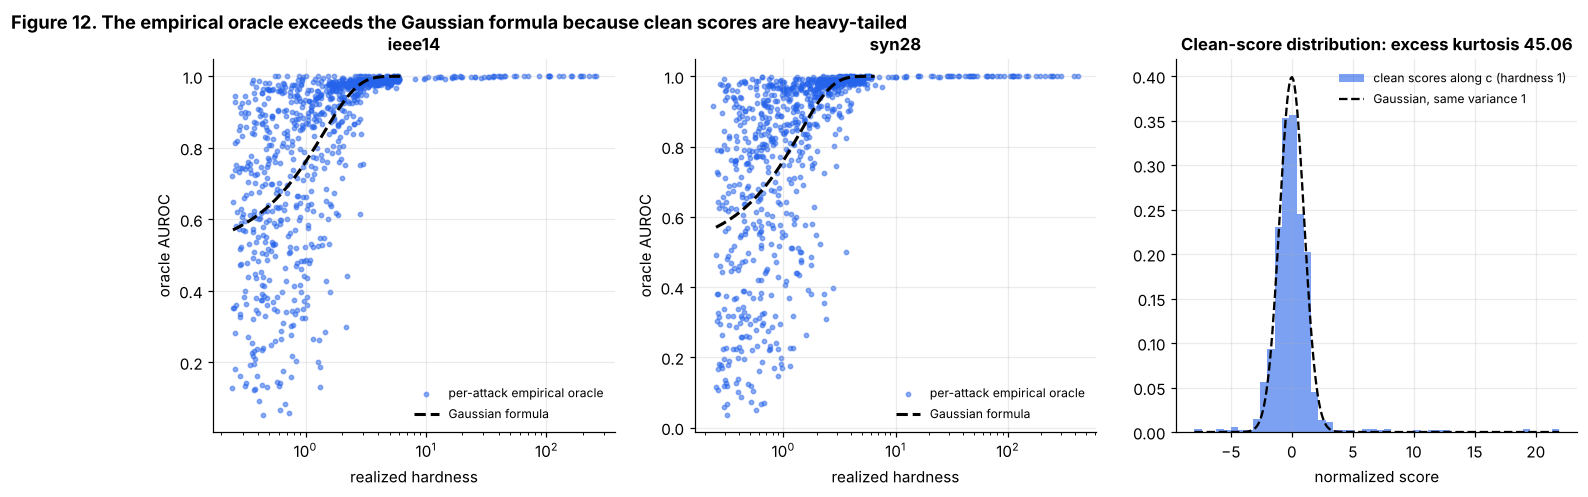

PosixPath('/tmp/w2/proj/figures/fig12_oracle_validity.png')

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, name in zip(axes[:2], ["ieee14", "syn28"]):
    cal_ = CAL[name]; auc_, dl_, s_att_ = oracle_scores(cal_, DS[name]["test"])
    ax.scatter(dl_, auc_, s=8, alpha=0.5, color=PAL["blue"], label="per-attack empirical oracle")
    xx = np.linspace(0.25, 6.5, 200); ax.plot(xx, oracle_auc(xx), "k--", lw=2, label="Gaussian formula")
    ax.set_xscale("log"); ax.set_xlabel("realized hardness"); ax.set_ylabel("oracle AUROC"); ax.set_title(f"{name}"); ax.legend(fontsize=8)
ax = axes[2]
cal_ = CAL["ieee14"]; dt = DS["ieee14"]["test"]; ia = np.where(dt["label"] == 1)[0]; ic = np.where(dt["label"] == 0)[0]
i0 = ia[np.argmin(np.abs(dt["delta"][ia] - 1.0))]; c0 = dt["shift"][i0]
s_clean = ((dt["x"][ic] - cal_.mu) @ cal_.Sinv @ c0) / cal_.delta(c0)[0]
ax.hist(s_clean, bins=50, density=True, color=PAL["blue"], alpha=0.6, label="clean scores along c (hardness 1)")
xg = np.linspace(s_clean.min(), s_clean.max(), 300); ax.plot(xg, st.norm.pdf(xg, 0, 1), "k--", label="Gaussian, same variance 1")
ax.set_title(f"Clean-score distribution: excess kurtosis {st.kurtosis(s_clean):.2f}"); ax.legend(fontsize=8); ax.set_xlabel("normalized score")
fig.suptitle("Figure 12. The empirical oracle exceeds the Gaussian formula because clean scores are heavy-tailed", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig12_oracle_validity")

## Part 9. Shortcut audit

A benchmark can be solved without solving the problem. This part applies five tests to any FDI dataset. They are run on **(a) the existing SCEPTRE dataset** (IEEE 14, from the earlier project), and **(b) the generator built in this notebook**.

| Test | Question | What a solvable-by-shortcut dataset looks like |
|---|---|---|
| T1 Intrinsic dimension | How many principal components carry 99% of clean variance, relative to the dimension? And, where an estimator noise floor is available, in how many directions does natural variability exceed that floor by 10x (the directions an attacker can hide in)? | Few of either. Most of the space is "impossible", so almost any perturbation stands out |
| T2 Channel consistency | Does the attack change only some measurement channels? | Some channels never change, so a detector can read the unaltered ones |
| T3 Trivial-detector gap | Does a Hotelling test, a PCA test, or gradient boosting on a dozen summary statistics match the best deep model? | Yes, to within about 0.01 AUROC |
| T4 Split leakage | Do test windows have a near-twin in the training set? | A large share of near-duplicates |
| T5 Grid-identity probe | Can the attack label be predicted from grid-level constants alone? | Yes (the attack rate varies by grid, so identifying the grid leaks the label) |

Caveat on T1: a variance-based count is dominated by the single biggest source of variation. In both datasets that is a system-wide load factor, so the variance-based number is low for both and cannot by itself separate them. The noise-floor count is more informative but needs the estimator's own covariance, which the SCEPTRE data does not ship. The tests are cheap and use only data the benchmark already provides. Failing a test does not make a dataset wrong; it limits what claims it can support.

In [27]:
SC_DIR = ROOT / "reference" / "sceptre" / "dataset" / "case14"
SC_JSON = ROOT / "reference" / "sceptre" / "outputs" / "sceptre_results.json"
HAS_SCEPTRE = (SC_DIR / "train.npz").exists()
print("SCEPTRE reference data present:", HAS_SCEPTRE, "|", SC_DIR)

def nn_near_duplicate_rate(Ftr, Fte, seed=0, n=2000):
    """Leakage check. Returns (share of test rows closer to train than the 10th percentile of train-to-train
    nearest-neighbour distances, median-distance ratio test/train).  For independent splits the share is about 10%
    and the ratio about 1; a leaky split gives a much larger share and a ratio well below 1."""
    from sklearn.neighbors import NearestNeighbors
    rng = np.random.default_rng(seed)
    nn = NearestNeighbors(n_neighbors=2).fit(Ftr)
    i = rng.choice(len(Ftr), min(n, len(Ftr)), replace=False)
    d_tt = nn.kneighbors(Ftr[i], 2)[0][:, 1]                         # nearest OTHER training row
    j = rng.choice(len(Fte), min(n, len(Fte)), replace=False)
    d_et = nn.kneighbors(Fte[j], 1)[0][:, 0]
    return float(np.mean(d_et < np.percentile(d_tt, 10))), float(np.median(d_et) / np.median(d_tt))

audit = {}
if HAS_SCEPTRE:
    tr = np.load(SC_DIR / "train.npz"); te = np.load(SC_DIR / "test.npz")
    Xtr, Xte = tr["X"].astype(np.float32), te["X"].astype(np.float32); ytr, yte = tr["y_det"], te["y_det"]
    def sc_feats(X):
        return np.hstack([X[:, -1].reshape(len(X), -1), np.abs(np.diff(X, axis=1)).mean(1).reshape(len(X), -1)])
    Ftr, Fte = sc_feats(Xtr), sc_feats(Xte)
    # T1
    F0 = Xtr[ytr == 0][:, -1].reshape(-1, Xtr.shape[2] * Xtr.shape[3])
    cs = np.cumsum(PCA().fit(F0).explained_variance_ratio_)
    k99, k95 = int(np.searchsorted(cs, 0.99) + 1), int(np.searchsorted(cs, 0.95) + 1)
    # T2: how much label information does each channel carry? best single-feature AUROC over buses,
    # using the level at the last frame and the temporal standard deviation over the window
    nb, nc = Xtr.shape[2], Xtr.shape[3]
    def best_auc(vals):
        return max(abs(roc_auc_score(ytr, vals[:, b]) - 0.5) + 0.5 for b in range(nb))
    ch_level = [best_auc(Xtr[:, -1, :, c]) for c in range(nc)]
    ch_std = [best_auc(Xtr[:, :, :, c].std(1)) for c in range(nc)]
    # T3
    dim = F0.shape[1]; clean = Ftr[ytr == 0][:, :dim]; mu_ = clean.mean(0); Si_ = np.linalg.inv(LedoitWolf().fit(clean).covariance_)
    t2 = lambda F: np.einsum("ij,jk,ik->i", F[:, :dim] - mu_, Si_, F[:, :dim] - mu_)
    pca_ = PCA(0.95).fit(clean)
    pr = lambda F: ((F[:, :dim] - pca_.inverse_transform(pca_.transform(F[:, :dim]))) ** 2).sum(1)
    g_ = HistGradientBoostingClassifier(max_iter=200, random_state=0).fit(Ftr, ytr)
    sc_ = StandardScaler().fit(Ftr); m_ = MLPClassifier((128, 64), early_stopping=True, max_iter=100, random_state=0).fit(sc_.transform(Ftr), ytr)
    flat = lambda X: X[:, ::6].reshape(len(X), -1); sc2 = StandardScaler().fit(flat(Xtr))
    m2 = MLPClassifier((128, 64), early_stopping=True, max_iter=100, random_state=0).fit(sc2.transform(flat(Xtr)), ytr)
    triv = {"hotelling": roc_auc_score(yte, t2(Fte)), "pca_recon": roc_auc_score(yte, pr(Fte)),
            "gbdt_frame_stats": roc_auc_score(yte, g_.predict_proba(Fte)[:, 1])}
    deep = {"mlp_frame": roc_auc_score(yte, m_.predict_proba(sc_.transform(Fte))[:, 1]),
            "mlp_window": roc_auc_score(yte, m2.predict_proba(sc2.transform(flat(Xte)))[:, 1])}
    reported = {}
    if SC_JSON.exists():
        bm = json.load(open(SC_JSON))["benchmark"]; reported = {k: v["det_auc"][0] for k, v in bm.items()}
    # T4
    dup, ratio = nn_near_duplicate_rate(Ftr[:, :dim], Fte[:, :dim])
    audit["sceptre"] = dict(k99=k99, k95=k95, dim=dim, ch_level=ch_level, ch_std=ch_std, triv=triv, deep=deep, reported=reported, dup=dup, ratio=ratio)
    print(f"T1 intrinsic dimension: {k95}/{dim} components for 95% of clean variance, {k99}/{dim} for 99%")
    print("T2 best single-feature AUROC per channel (channel order as stored):")
    print("    level at last frame      :", np.round(ch_level, 3)); print("    temporal std over window :", np.round(ch_std, 3))
    print("T3 trivial detectors:", {k: round(v, 4) for k, v in triv.items()})
    print("   deep (this notebook, sklearn):", {k: round(v, 4) for k, v in deep.items()})
    if reported: print("   deep (SCEPTRE-reported AUROC, 10 architectures): best %.4f (%s), SCEPTRE %.4f" %
                       (max(reported.values()), max(reported, key=reported.get), reported["sceptre"]))
    print(f"T4 near-duplicate share {dup:.1%} (about 10% if independent), median-distance ratio {ratio:.2f} (about 1 if independent)")
else:
    print("SCEPTRE reference data not found: T1 to T4 on SCEPTRE are skipped and H1 is marked NOT_RUN.")

SCEPTRE reference data present: True | /tmp/w2/proj/reference/sceptre/dataset/case14


T1 intrinsic dimension: 3/56 components for 95% of clean variance, 37/56 for 99%
T2 best single-feature AUROC per channel (channel order as stored):
    level at last frame      : [0.526 0.529 0.537 0.53 ]
    temporal std over window : [0.892 0.525 0.937 0.565]
T3 trivial detectors: {'hotelling': 0.6364, 'pca_recon': 0.6367, 'gbdt_frame_stats': 0.9978}
   deep (this notebook, sklearn): {'mlp_frame': 0.9759, 'mlp_window': 0.8347}
   deep (SCEPTRE-reported AUROC, 10 architectures): best 0.9989 (mlp), SCEPTRE 0.9976
T4 near-duplicate share 6.6% (about 10% if independent), median-distance ratio 1.03 (about 1 if independent)


### 9.1 The same tests on this notebook's generator

T3 needs a definition that works for both datasets. **Trivial** detectors: Hotelling, PCA reconstruction error, and gradient boosting on a dozen summary statistics. **Learned** detectors: the in-grid MLP, gradient-boosted trees on the full whitened state, and logistic regression. The *gap* is the best learned AUROC minus the best trivial AUROC, computed in the **hard bins** (hardness below 2), because that is the region where a benchmark either discriminates between methods or does not. A gap above 0.02 means a trivial detector does not suffice.

Here the learned detectors get the full training set on IEEE 14 and on the synthetic 28-bus grid.

In [28]:
HARD_MASK = lambda d: (d["label"] == 0) | (d["delta"] < 2.0)

def hard_auc(score, d):
    m = HARD_MASK(d); return roc_auc_score(d["label"][m], score[m])

def audit_ours(name, seed=0):
    cal, tr, te = CAL[name], DS[name]["train"], DS[name]["test"]
    out = {}
    out["k99"] = int(np.searchsorted(np.cumsum(cal.eigval) / cal.eigval.sum(), 0.99) + 1); out["dim"] = cal.ns
    # noise-floor "hiding dimension": directions where natural variance exceeds the estimator's own noise by 10x
    sim = SIMS[name]; Hs = sim.H_nom; Gi = np.linalg.inv(Hs.T @ (sim.mt["W"][:, None] * Hs))
    floor_dir = np.einsum("ji,jk,ki->i", cal.eigvec, Gi, cal.eigvec)
    out["hide10"] = int((cal.eigval / floor_dir > 10).sum())
    out["k95"] = int(np.searchsorted(np.cumsum(cal.eigval) / cal.eigval.sum(), 0.95) + 1)
    triv, learned = {}, {}
    for D in (Hotelling, PCARecon):
        det = D().fit(cal, None, seed); triv[det.name] = hard_auc(det.score(cal, te), te)
    g = GBDTSum().fit(cal, tr, seed); triv["gbdt_sum"] = hard_auc(g.score(cal, te), te)
    for D in (LogReg, GBDT, MLP):
        det = D().fit(cal, tr, seed); learned[det.name] = hard_auc(det.score(cal, te), te)
    # T4: near duplicates in the whitened state
    dup, ratio = nn_near_duplicate_rate(whiten(cal, tr["x"]), whiten(cal, te["x"]))
    out["chi2_auc"] = roc_auc_score(te["label"], te["J"])           # T2: is the attack visible in the residual at all?
    out.update(triv=triv, learned=learned, gap=max(learned.values()) - max(triv.values()), dup=dup, ratio=ratio)
    return out

for nm in STUDY_GRIDS: audit[nm] = audit_ours(nm)
rows = []
for nm in STUDY_GRIDS:
    a = audit[nm]
    rows.append(dict(grid=nm, intrinsic_k95=f"{a['k95']}/{a['dim']}", intrinsic_k99=f"{a['k99']}/{a['dim']}", hiding_dim=f"{a['hide10']}/{a['dim']}",
                     best_trivial_hard=max(a["triv"].values()), best_learned_hard=max(a["learned"].values()),
                     gap=a["gap"], chi2_auc=a["chi2_auc"], near_dup_share=a["dup"], nn_ratio=a["ratio"]))
print(pd.DataFrame(rows).round(3).to_string(index=False))

  grid intrinsic_k95 intrinsic_k99 hiding_dim  best_trivial_hard  best_learned_hard   gap  chi2_auc  near_dup_share  nn_ratio
ieee14          1/27          1/27       5/27              0.531              0.554 0.023     0.498           0.102     1.018
 syn28          2/55          3/55      13/55              0.545              0.547 0.002     0.499           0.096     1.000


### 9.2 T5: the grid-identity probe

The probe trains a gradient-boosted classifier on **grid-level constants only** (number of states, number of meters, degrees of freedom, number of buses) with leave-one-grid-out evaluation. In this benchmark every grid has the same attack rate by construction, so the probe should sit at chance. It is included because the first thing someone adds when extending a benchmark to more grids is unequal attack rates, and this test catches the resulting leak.

In [29]:
G_rows, G_y = [], []
for nm in TRAIN_FAMILY + UNSEEN:
    c_ = CAL[nm]; te = DS[nm]["test"]
    feats_ = [c_.ns, SIMS[nm].mt["m"], c_.dof, SIMS[nm].g.n]
    for y_ in te["label"]: G_rows.append(feats_); G_y.append(y_)
G_rows, G_y = np.array(G_rows), np.array(G_y); gid = np.concatenate([[i] * len(DS[nm]["test"]["label"]) for i, nm in enumerate(TRAIN_FAMILY + UNSEEN)])
probe = []
for g_out in np.unique(gid):
    tr_m = gid != g_out
    m_ = HistGradientBoostingClassifier(max_iter=50, random_state=0).fit(G_rows[tr_m], G_y[tr_m])
    probe.append(roc_auc_score(G_y[~tr_m], m_.predict_proba(G_rows[~tr_m])[:, 1]) if len(np.unique(G_y[~tr_m])) > 1 else np.nan)
probe = np.array(probe)
print(f"grid-identity probe, leave-one-grid-out: mean AUROC {np.nanmean(probe):.3f} (chance = 0.5)")
audit["probe_auc"] = float(np.nanmean(probe))

grid-identity probe, leave-one-grid-out: mean AUROC 0.500 (chance = 0.5)


### 9.3 Audit scorecard (Figure 13)

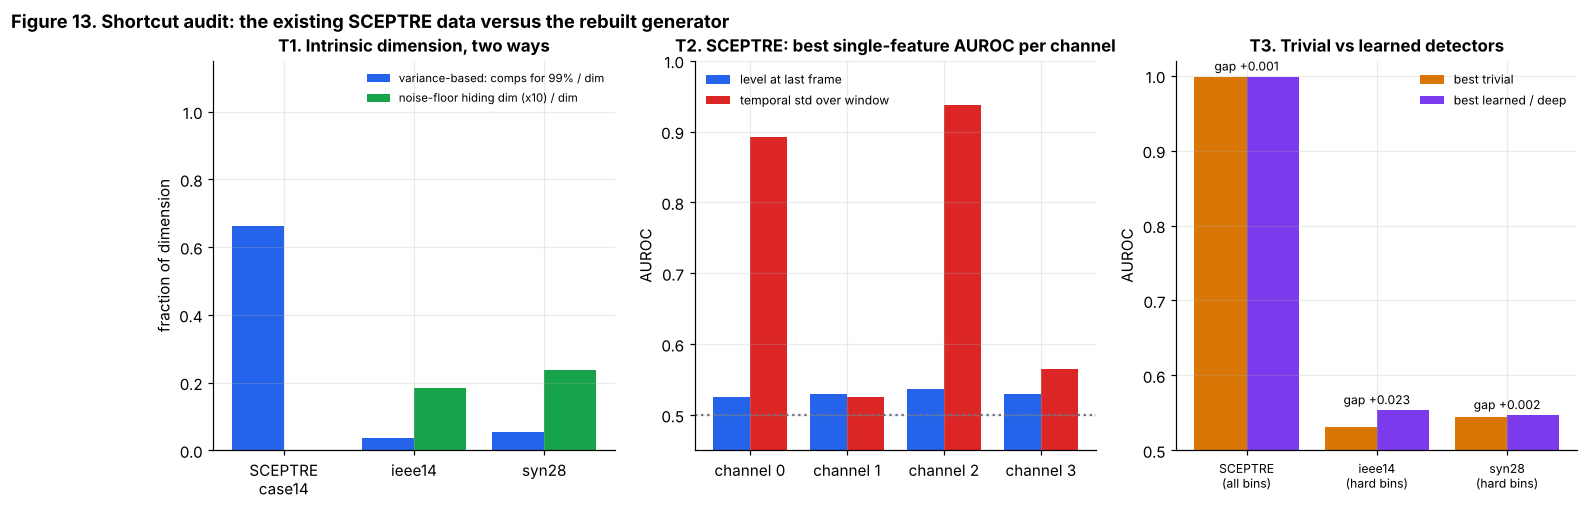

PosixPath('/tmp/w2/proj/figures/fig13_audit_scorecard.png')

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ax = axes[0]
labels, v99, vh = [], [], []
if HAS_SCEPTRE: labels.append("SCEPTRE\ncase14"); v99.append(audit["sceptre"]["k99"] / audit["sceptre"]["dim"]); vh.append(np.nan)
for nm in STUDY_GRIDS: labels.append(nm); v99.append(audit[nm]["k99"] / audit[nm]["dim"]); vh.append(audit[nm]["hide10"] / audit[nm]["dim"])
x_ = np.arange(len(labels)); ax.bar(x_ - 0.2, v99, 0.4, color=PAL["blue"], label="variance-based: comps for 99% / dim")
ax.bar(x_ + 0.2, np.nan_to_num(vh), 0.4, color=PAL["green"], label="noise-floor hiding dim (x10) / dim")
ax.set_xticks(x_); ax.set_xticklabels(labels); ax.set_ylim(0, 1.15); ax.legend(fontsize=7.5, loc="upper right")
ax.set_ylabel("fraction of dimension"); ax.set_title("T1. Intrinsic dimension, two ways")
ax = axes[1]
if HAS_SCEPTRE:
    w_ = 0.38
    ax.bar(np.arange(4) - w_ / 2, audit["sceptre"]["ch_level"], w_, color=PAL["blue"], label="level at last frame")
    ax.bar(np.arange(4) + w_ / 2, audit["sceptre"]["ch_std"], w_, color=PAL["red"], label="temporal std over window")
    ax.axhline(0.5, color=PAL["grey"], ls=":"); ax.set_xticks(range(4)); ax.set_xticklabels([f"channel {c}" for c in range(4)]); ax.legend(fontsize=8)
    ax.set_ylim(0.45, 1.0)
ax.set_title("T2. SCEPTRE: best single-feature AUROC per channel"); ax.set_ylabel("AUROC")
ax = axes[2]
names, triv_v, deep_v = [], [], []
if HAS_SCEPTRE:
    names.append("SCEPTRE\n(all bins)"); triv_v.append(max(audit["sceptre"]["triv"].values()))
    rep = audit["sceptre"]["reported"]; deep_v.append(max(max(audit["sceptre"]["deep"].values()), max(rep.values()) if rep else 0))
for nm in STUDY_GRIDS:
    names.append(nm + "\n(hard bins)"); triv_v.append(max(audit[nm]["triv"].values())); deep_v.append(max(audit[nm]["learned"].values()))
x_ = np.arange(len(names)); ax.bar(x_ - 0.2, triv_v, 0.4, color=PAL["amber"], label="best trivial"); ax.bar(x_ + 0.2, deep_v, 0.4, color=PAL["purple"], label="best learned / deep")
ax.set_xticks(x_); ax.set_xticklabels(names, fontsize=8); ax.set_ylim(0.5, 1.02); ax.legend(fontsize=8); ax.set_ylabel("AUROC")
for i, (a, b) in enumerate(zip(triv_v, deep_v)): ax.text(i, max(a, b) + 0.008, f"gap {b-a:+.3f}", ha="center", fontsize=8)
ax.set_title("T3. Trivial vs learned detectors")
fig.suptitle("Figure 13. Shortcut audit: the existing SCEPTRE data versus the rebuilt generator", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig13_audit_scorecard")

## Part 10. In-grid oracle-gap study

The central measurement of the study. On two grids (IEEE 14 and the synthetic 28-bus grid), every detector is trained at four label budgets and evaluated on the same hardness-stratified test set. For each hardness bin we report the detector's AUROC, the empirical oracle's AUROC, and the difference.

**Design.**

* Budgets: 300, 900, 1,800 and 3,600 training windows (half clean, half attacked), drawn without replacement from a pool; three seeds each (different training subsets and different tuning draws). Clean-only detectors (`hotelling`, `pca_recon`, `iforest`, `chi2`) do not use labels, so they do not vary with the budget.
* Every supervised detector gets the same random-search budget (Part 8.2).
* Besides the in-grid detectors, the two **summary-view** detectors (`gbdt_sum`, `mlp_sum`) are included. They see only twelve physics-motivated statistics, including the Hotelling energy, so they act as a first, cheap version of the *structured detector* the proposal calls C5.
* **Large-data reference.** On IEEE 14 only, a gradient-boosted model is also trained on a much larger set (about 14,000 windows). It estimates what a learner can reach when data is abundant, and gives a second reference next to the oracle that does not assume a known direction.

H2 reads off this study: *the best tuned learned detector is at least 0.05 AUROC below the empirical oracle over hardness 1 to 4 at 1,800 windows, and the gap shrinks with more data.*

In [31]:
BUDGETS = [300, 900, 1800, 3600] if BUDGET == "full" else [150, 300, 500, 1000]
H2_BUDGET = 1800 if BUDGET == "full" else 500
DETS_STUDY = [Hotelling, PCARecon, IForest, Chi2, LogReg, GBDT, MLP, GBDTSum, MLPSum]

# optional big pool for the large-data reference on ieee14
big_cache = DATA / f"big_ieee14_{BUDGET}.pkl"
n_big = 10800 if BUDGET == "full" else 3000
if big_cache.exists():
    with open(big_cache, "rb") as fh: BIG14 = pickle.load(fh)
else:
    rng = rng_for("big14"); t0 = time.time()
    BIG14 = concat_blocks(gen_clean_block(SIMS["ieee14"], CAL["ieee14"], rng, n_big // 2), gen_attack_block(SIMS["ieee14"], CAL["ieee14"], rng, n_big // 2, "strat"))
    with open(big_cache, "wb") as fh: pickle.dump(BIG14, fh)
    print(f"large-data pool built: {n_big} windows in {time.time()-t0:.0f}s")

def pool_for(name):
    return concat_blocks(DS[name]["train"], DS[name]["train_extra"])

INGRID = {}          # INGRID[grid][budget][seed][detector] = dict(bins, overall)
INGRID_SCORES = {}   # test scores at the reference budget, seed 0 (used for damage analysis)
t_all = time.time()
for name in STUDY_GRIDS:
    cal, test, pool = CAL[name], DS[name]["test"], pool_for(name)
    INGRID[name] = {}; INGRID_SCORES[name] = {}
    unsup = {}
    for D in (Hotelling, PCARecon, IForest, Chi2):
        det = D().fit(cal, None, 0); s = det.score(cal, test)
        unsup[det.name] = dict(bins=auc_by_bin(s, test), overall=overall_auc(s, test)); INGRID_SCORES[name][det.name] = s
    for b in BUDGETS:
        INGRID[name][b] = {}
        for seed in range(SIZES["n_budget_seeds"]):
            sub = subsample_balanced(pool, b, np.random.default_rng(1000 * seed + b))
            out = {k: dict(v) for k, v in unsup.items()}
            for D in (LogReg, GBDT, MLP, GBDTSum, MLPSum):
                det = D().fit(cal, sub, seed); s = det.score(cal, test)
                out[det.name] = dict(bins=auc_by_bin(s, test), overall=overall_auc(s, test))
                if b == H2_BUDGET and seed == 0: INGRID_SCORES[name][det.name] = s
            INGRID[name][b][seed] = out
        print(f"{name}: budget {b} done ({time.time()-t_all:.0f}s)", flush=True)
    INGRID[name]["oracle"] = oracle_by_bin(cal, test); INGRID[name]["formula"] = formula_by_bin(test)

# large-data reference on ieee14
LARGE = {}
cal14, te14 = CAL["ieee14"], DS["ieee14"]["test"]
for D in (GBDT, GBDTSum):
    det = D().fit(cal14, BIG14, 0); s = det.score(cal14, te14)
    LARGE[det.name] = dict(bins=auc_by_bin(s, te14), overall=overall_auc(s, te14))
print("large-data reference (ieee14, %d windows):" % len(BIG14["label"]))
print(pd.DataFrame({k: v["bins"] for k, v in LARGE.items()}, index=BIN_NAMES).T.round(3).to_string())

ieee14: budget 300 done (7s)


ieee14: budget 900 done (18s)


ieee14: budget 1800 done (43s)


ieee14: budget 3600 done (88s)


syn28: budget 300 done (95s)


syn28: budget 900 done (109s)


syn28: budget 1800 done (133s)


syn28: budget 3600 done (175s)


large-data reference (ieee14, 10800 windows):
          0.25-0.5  0.5-1    1-2    2-4  4-6.5
gbdt         0.565  0.578  0.595  0.781  0.919
gbdt_sum     0.554  0.558  0.594  0.779  0.934


### 10.1 Results at the reference budget (Figure 14)

Panel A shows mean AUROC by hardness bin (error bars: standard deviation over seeds), with the empirical oracle as a thick black line and the Gaussian formula dashed. Panel B is the gap heatmap. A *negative* gap means the detector scored *above* the oracle in that bin, which can happen because the oracle is a linear reference and learned detectors can use nonlinear structure.

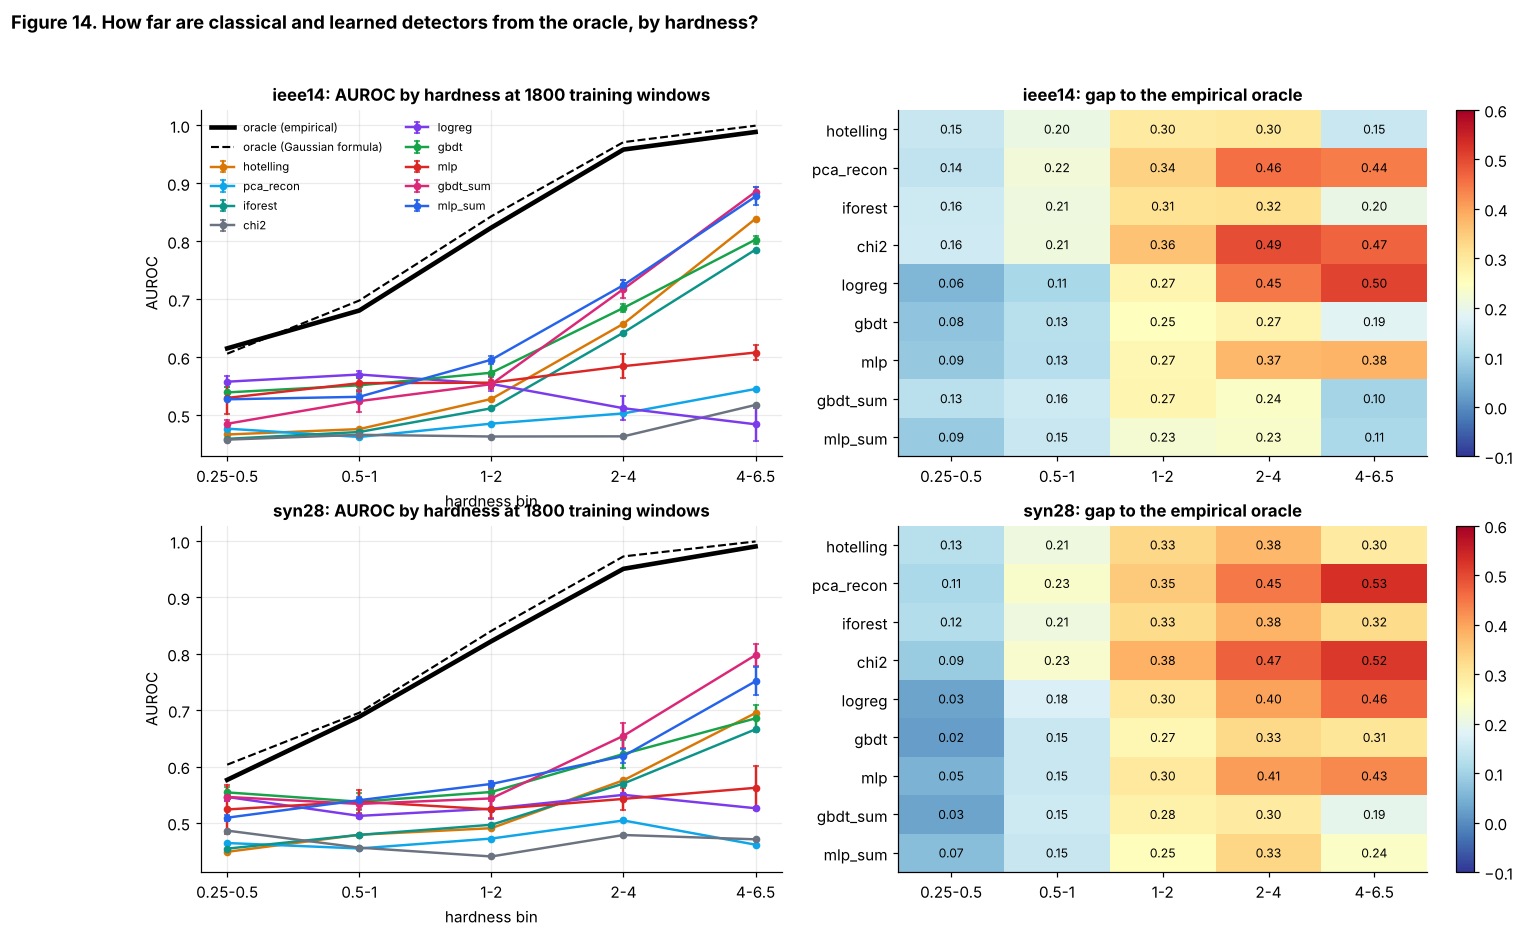

PosixPath('/tmp/w2/proj/figures/fig14_oracle_gap.png')

In [32]:
def agg(name, b, det):
    arr = np.array([INGRID[name][b][s][det]["bins"] for s in INGRID[name][b]])
    return arr.mean(0), arr.std(0)

DET_COLORS = dict(chi2=PAL["grey"], hotelling=PAL["amber"], pca_recon=PAL["sky"], iforest=PAL["teal"], logreg=PAL["purple"],
                  gbdt=PAL["green"], mlp=PAL["red"], gbdt_sum=PAL["pink"], mlp_sum=PAL["blue"])
DET_NAMES = [D.name if isinstance(D.name, str) else D().name for D in DETS_STUDY]
xs = np.arange(len(BIN_NAMES))
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for r, name in enumerate(STUDY_GRIDS):
    ax = axes[r, 0]
    for d_ in DET_NAMES:
        m, s = agg(name, H2_BUDGET, d_); ax.errorbar(xs, m, yerr=s, fmt="o-", color=DET_COLORS[d_], label=d_, lw=1.6, ms=4, capsize=2)
    ax.plot(xs, INGRID[name]["oracle"], "k-", lw=3, label="oracle (empirical)"); ax.plot(xs, INGRID[name]["formula"], "k--", lw=1.4, label="oracle (Gaussian formula)")
    ax.set_xticks(xs); ax.set_xticklabels(BIN_NAMES); ax.set_xlabel("hardness bin"); ax.set_ylabel("AUROC"); ax.set_title(f"{name}: AUROC by hardness at {H2_BUDGET} training windows")
    if r == 0: ax.legend(fontsize=7.5, ncol=2)
    ax = axes[r, 1]
    gap = np.array([INGRID[name]["oracle"] - agg(name, H2_BUDGET, d_)[0] for d_ in DET_NAMES])
    im = ax.imshow(gap, cmap="RdYlBu_r", vmin=-0.1, vmax=0.6, aspect="auto")
    ax.set_xticks(xs); ax.set_xticklabels(BIN_NAMES); ax.set_yticks(range(len(DET_NAMES))); ax.set_yticklabels(DET_NAMES)
    for i in range(gap.shape[0]):
        for j in range(gap.shape[1]): ax.text(j, i, f"{gap[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.grid(False); ax.set_title(f"{name}: gap to the empirical oracle"); plt.colorbar(im, ax=ax, fraction=0.04)
fig.suptitle("Figure 14. How far are classical and learned detectors from the oracle, by hardness?", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig14_oracle_gap")

### 10.2 Learning curves: does the gap shrink with data? (Figure 15)

H2's second half. For each detector, AUROC over the mid-hardness region (bins covering hardness 1 to 4) is plotted against the label budget, with the empirical oracle and, on IEEE 14, the large-data reference as horizontal lines.

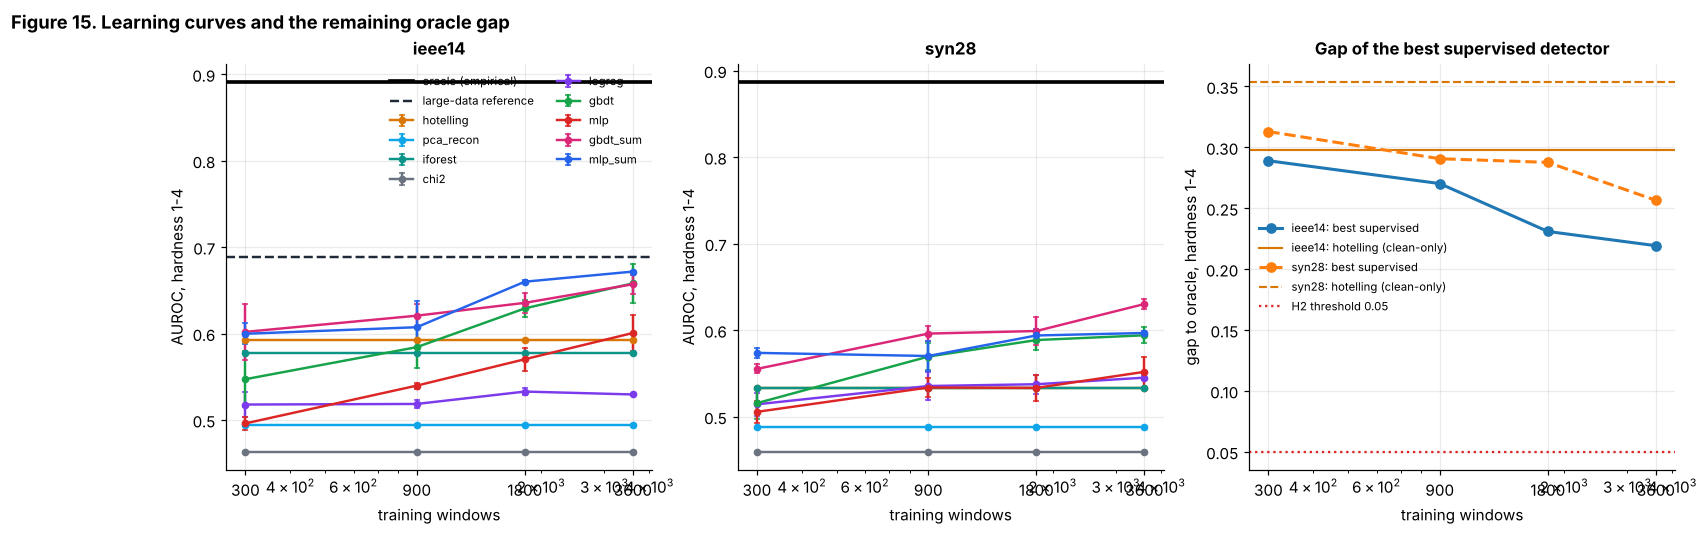

        gap_ref  gap_small  gap_large
ieee14    0.231      0.289      0.219
syn28     0.288      0.313      0.256


In [33]:
MID_BINS = [BIN_NAMES.index("1-2"), BIN_NAMES.index("2-4")]
HARD_BINS = [BIN_NAMES.index("0.5-1"), BIN_NAMES.index("1-2")]
def region(vals, idx): return float(np.nanmean(np.asarray(vals)[idx]))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, name in zip(axes[:2], STUDY_GRIDS):
    for d_ in DET_NAMES:
        ms = []; ss = []
        for b in BUDGETS:
            arr = np.array([region(INGRID[name][b][s][d_]["bins"], MID_BINS) for s in INGRID[name][b]]); ms.append(arr.mean()); ss.append(arr.std())
        ax.errorbar(BUDGETS, ms, yerr=ss, fmt="o-", color=DET_COLORS[d_], label=d_, lw=1.6, ms=4, capsize=2)
    ax.axhline(region(INGRID[name]["oracle"], MID_BINS), color="k", lw=2.4, label="oracle (empirical)")
    if name == "ieee14":
        ax.axhline(max(region(v["bins"], MID_BINS) for v in LARGE.values()), color=PAL["ink"], ls="--", lw=1.6, label="large-data reference")
    ax.set_xscale("log"); ax.set_xlabel("training windows"); ax.set_ylabel("AUROC, hardness 1-4"); ax.set_title(name); ax.set_xticks(BUDGETS); ax.set_xticklabels(BUDGETS)
axes[0].legend(fontsize=7.5, ncol=2)
ax = axes[2]
for name, ls in zip(STUDY_GRIDS, ["-", "--"]):
    best = []
    for b in BUDGETS:
        sup = ["logreg", "gbdt", "mlp", "gbdt_sum", "mlp_sum"]
        best.append(INGRID[name]["oracle"][MID_BINS].mean() - max(np.mean([region(INGRID[name][b][s][d_]["bins"], MID_BINS) for s in INGRID[name][b]]) for d_ in sup))
    ax.plot(BUDGETS, best, "o" + ls, lw=2, label=f"{name}: best supervised"); 
    hot = INGRID[name]["oracle"][MID_BINS].mean() - region(INGRID[name][BUDGETS[0]][0]["hotelling"]["bins"], MID_BINS)
    ax.axhline(hot, color=PAL["amber"], ls=ls, lw=1.4, label=f"{name}: hotelling (clean-only)")
ax.axhline(THRESH["h2_gap"], color=PAL["red"], ls=":", label="H2 threshold 0.05"); ax.set_xscale("log"); ax.set_xticks(BUDGETS); ax.set_xticklabels(BUDGETS)
ax.set_xlabel("training windows"); ax.set_ylabel("gap to oracle, hardness 1-4"); ax.set_title("Gap of the best supervised detector"); ax.legend(fontsize=7.5)
fig.suptitle("Figure 15. Learning curves and the remaining oracle gap", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig15_learning_curves")

# H2 numbers
h2 = {}
for name in STUDY_GRIDS:
    orc = INGRID[name]["oracle"][MID_BINS].mean(); sup = ["logreg", "gbdt", "mlp", "gbdt_sum", "mlp_sum"]
    def best_at(b): return max(np.mean([region(INGRID[name][b][s][d_]["bins"], MID_BINS) for s in INGRID[name][b]]) for d_ in sup)
    h2[name] = dict(gap_ref=orc - best_at(H2_BUDGET), gap_small=orc - best_at(BUDGETS[0]), gap_large=orc - best_at(BUDGETS[-1]))
print(pd.DataFrame(h2).T.round(3).to_string()); 

## Part 11. Leave-grid-out generalization

Published FDI detectors are trained and tested on windows from the *same* grid. An operator who deploys a detector on a different grid, or on the same grid after a topology change, is asking an extrapolation question. This part measures it with the **grid-agnostic** summary view (Part 8.1), since a fixed-length view is what makes a model portable at all.

**Training arms** (all with exactly 1,800 training windows in total, so no arm has more data):

| Arm | Training grids | Windows per grid |
|---|---|---|
| `single14` | IEEE 14 only | 1,800 |
| `three` | `ieee14`, `ieee14_v1`, `ieee30` | 600 |
| `broad8` | the full 8-grid training family | 225 |

**Test.** (i) Fresh windows of the *seen* grids, and (ii) the four **unseen** grids (`ieee30_v2`, `syn24u`, `syn44u`, `ieee57`), never used for training, tuning, or threshold selection. The metric is AUROC on attacks of hardness 0.5 to 2 (the hard region) against all clean windows.

* **H12**: the three-grid arm loses at least 0.05 AUROC on unseen grids relative to seen grids.
* **H13**: the broad family beats single-IEEE training on unseen grids at equal sample count (pre-registered pass rule: mean paired improvement of at least 0.01, with the sign positive in every seed).

Different grids differ in intrinsic difficulty, so a raw drop could reflect that rather than transfer. The Hotelling test needs no training, so its seen-minus-unseen difference measures grid difficulty alone, and the **difficulty-adjusted** drop subtracts it.

In [34]:
THRESH["h13_min"] = 0.01
ARMS = {"single14": {"ieee14": 1800},
        "three": {"ieee14": 600, "ieee14_v1": 600, "ieee30": 600},
        "broad8": {g: 225 for g in TRAIN_FAMILY}}
if BUDGET == "quick": ARMS = {k: {g: max(20, n // 3) for g, n in v.items()} for k, v in ARMS.items()}

def small_auc(score, d, lo=0.5, hi=2.0):
    m = (d["label"] == 0) | ((d["delta"] >= lo) & (d["delta"] < hi))
    return roc_auc_score(d["label"][m], score[m])

def train_pool_for(g):
    return pool_for(g) if g in DS and "train_extra" in DS[g] else DS[g]["train"]

def arm_training_arrays(arm, seed, model_cls):
    Xs, ys = [], []
    for g, n in ARMS[arm].items():
        sub = subsample_balanced(train_pool_for(g), n - n % 2, np.random.default_rng(7000 + 31 * seed + len(g)))
        Xs.append(summary_features(CAL[g], sub)); ys.append(sub["label"])
    return np.vstack(Xs), np.concatenate(ys)

SEEN_SETS = ["ieee14", "ieee14_v1", "ieee30"]
tr_res = {}   # tr_res[arm][model][seed] = dict(seen=..., unseen={grid: auc})
t0 = time.time()
for arm in ARMS:
    tr_res[arm] = {}
    for Mcls in (GBDTSum, MLPSum):
        tr_res[arm][Mcls.name] = {}
        for seed in range(SIZES["n_budget_seeds"]):
            X, y = arm_training_arrays(arm, seed, Mcls); det = Mcls()._fit_xy(X, y, seed)
            out = {"seen": {g: small_auc(det.score(CAL[g], DS[g]["test"]), DS[g]["test"]) for g in TRAIN_FAMILY},
                   "unseen": {g: small_auc(det.score(CAL[g], DS[g]["test"]), DS[g]["test"]) for g in UNSEEN}}
            tr_res[arm][Mcls.name][seed] = out
    print(f"arm {arm} done ({time.time()-t0:.0f}s)", flush=True)

# references that need no training
REF = {"hotelling": {g: small_auc(Hotelling().score(CAL[g], DS[g]["test"]), DS[g]["test"]) for g in TRAIN_FAMILY + UNSEEN},
       "oracle": {g: float(np.nanmean(oracle_by_bin(CAL[g], DS[g]["test"], np.array([0.5, 1.0, 2.0]))) ) for g in TRAIN_FAMILY + UNSEEN}}

rows = []
for arm in ARMS:
    for mname in tr_res[arm]:
        for seed, o in tr_res[arm][mname].items():
            seen_g = [g for g in ARMS[arm]]                          # held-out windows of the grids the arm trained on
            rows.append(dict(arm=arm, model=mname, seed=seed,
                             seen=np.mean([o["seen"][g] for g in seen_g]), unseen=np.mean(list(o["unseen"].values())),
                             hot_seen=np.mean([REF["hotelling"][g] for g in seen_g]), hot_unseen=np.mean([REF["hotelling"][g] for g in UNSEEN])))
TR = pd.DataFrame(rows); TR["drop"] = TR.seen - TR.unseen; TR["drop_adj"] = TR["drop"] - (TR.hot_seen - TR.hot_unseen)
print(TR.groupby(["arm", "model"])[["seen", "unseen", "drop", "drop_adj"]].mean().round(3).to_string())

arm single14 done (12s)


arm three done (26s)


arm broad8 done (39s)


                    seen  unseen   drop  drop_adj
arm      model                                   
broad8   gbdt_sum  0.555   0.549  0.006     0.003
         mlp_sum   0.531   0.529  0.002    -0.001
single14 gbdt_sum  0.567   0.541  0.025     0.006
         mlp_sum   0.566   0.536  0.030     0.011
three    gbdt_sum  0.560   0.544  0.016    -0.000
         mlp_sum   0.558   0.543  0.015    -0.001


### 11.1 Results (Figure 16)

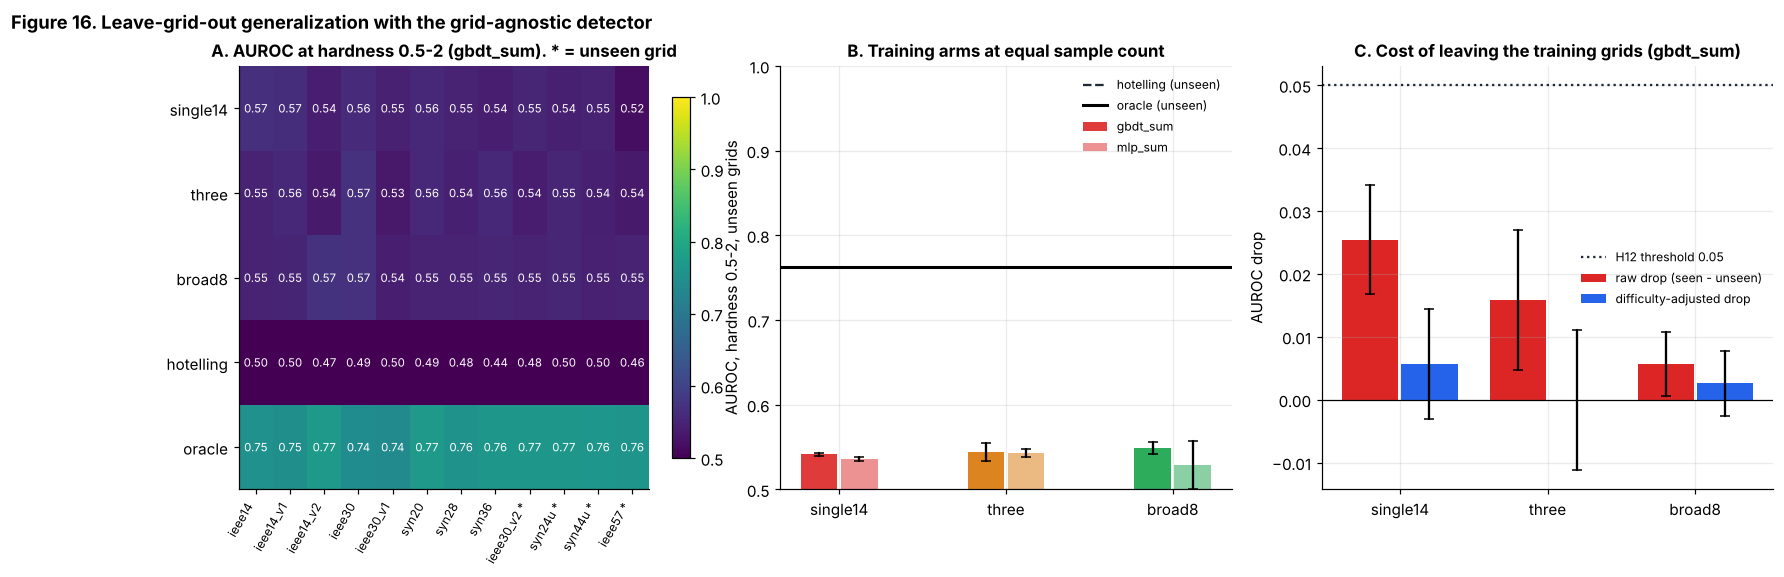

PosixPath('/tmp/w2/proj/figures/fig16_leave_grid_out.png')

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax = axes[0]
allg = TRAIN_FAMILY + UNSEEN
M_ = np.array([[np.mean([tr_res[arm]["gbdt_sum"][s]["seen" if g in TRAIN_FAMILY else "unseen"][g] for s in tr_res[arm]["gbdt_sum"]]) for g in allg] for arm in ARMS]
              + [[REF["hotelling"][g] for g in allg], [REF["oracle"][g] for g in allg]])
im = ax.imshow(M_, cmap="viridis", vmin=0.5, vmax=1.0, aspect="auto")
ax.set_yticks(range(M_.shape[0])); ax.set_yticklabels(list(ARMS) + ["hotelling", "oracle"])
ax.set_xticks(range(len(allg))); ax.set_xticklabels([g + (" *" if g in UNSEEN else "") for g in allg], rotation=60, ha="right", fontsize=8)
for i in range(M_.shape[0]):
    for j in range(M_.shape[1]): ax.text(j, i, f"{M_[i, j]:.2f}", ha="center", va="center", color="white" if M_[i, j] < 0.78 else "black", fontsize=7.5)
ax.grid(False); ax.set_title("A. AUROC at hardness 0.5-2 (gbdt_sum). * = unseen grid"); plt.colorbar(im, ax=ax, fraction=0.04)
ax = axes[1]
for k, (arm, col) in enumerate(zip(ARMS, [PAL["red"], PAL["amber"], PAL["green"]])):
    sub = TR[(TR.arm == arm)]; 
    for mname, off in [("gbdt_sum", -0.12), ("mlp_sum", 0.12)]:
        v = sub[sub.model == mname]
        ax.bar(k + off, v.unseen.mean(), 0.22, yerr=v.unseen.std(), color=col, alpha=0.9 if mname == "gbdt_sum" else 0.5, capsize=3,
               label=f"{mname}" if k == 0 else None)
ax.axhline(np.mean([REF["hotelling"][g] for g in UNSEEN]), color=PAL["ink"], ls="--", label="hotelling (unseen)")
ax.axhline(np.mean([REF["oracle"][g] for g in UNSEEN]), color="k", lw=2, label="oracle (unseen)")
ax.set_xticks(range(len(ARMS))); ax.set_xticklabels(list(ARMS)); ax.set_ylim(0.5, 1.0); ax.set_ylabel("AUROC, hardness 0.5-2, unseen grids")
ax.set_title("B. Training arms at equal sample count"); ax.legend(fontsize=8)
ax = axes[2]
for k, arm in enumerate(ARMS):
    v = TR[(TR.arm == arm) & (TR.model == "gbdt_sum")]
    ax.bar(k - 0.2, v["drop"].mean(), 0.38, yerr=v["drop"].std(), color=PAL["red"], capsize=3, label="raw drop (seen - unseen)" if k == 0 else None)
    ax.bar(k + 0.2, v["drop_adj"].mean(), 0.38, yerr=v["drop_adj"].std(), color=PAL["blue"], capsize=3, label="difficulty-adjusted drop" if k == 0 else None)
ax.axhline(THRESH["h12_drop"], color=PAL["ink"], ls=":", label="H12 threshold 0.05"); ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(range(len(ARMS))); ax.set_xticklabels(list(ARMS)); ax.set_ylabel("AUROC drop"); ax.set_title("C. Cost of leaving the training grids (gbdt_sum)"); ax.legend(fontsize=8)
fig.suptitle("Figure 16. Leave-grid-out generalization with the grid-agnostic detector", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig16_leave_grid_out")

### 11.2 Pre-registered readouts H12 and H13

In [36]:
def h12_h13():
    g3 = TR[(TR.arm == "three") & (TR.model == "gbdt_sum")]
    h12_val = float(g3["drop"].mean()); h12_adj = float(g3["drop_adj"].mean())
    b = TR[(TR.arm == "broad8") & (TR.model == "gbdt_sum")].sort_values("seed").unseen.values
    s = TR[(TR.arm == "single14") & (TR.model == "gbdt_sum")].sort_values("seed").unseen.values
    d = b - s
    return dict(h12_drop=h12_val, h12_drop_adj=h12_adj, h13_mean_diff=float(d.mean()), h13_all_positive=bool(np.all(d > 0)), h13_diffs=d.round(4).tolist())
H1213 = h12_h13(); print(H1213)

{'h12_drop': 0.01584086818548347, 'h12_drop_adj': -0.00010806395501833377, 'h13_mean_diff': 0.00805331460550418, 'h13_all_positive': True, 'h13_diffs': [0.0139, 0.0057, 0.0046]}


### 11.3 Hard negatives (H14)

An operator should not get an attack alarm when a line trips or one meter fails. Training data that contains only natural clean windows and attacks teaches a detector that "different from normal" means "attack". H14 measures how much that costs: for each study grid and each of the two supervised detector families, train once **with** the outage and bad-data windows labelled clean and once **without**, set the alarm threshold so that 1% of *natural* clean test windows alarm, and compare the alarm rate on 300 fresh N−1 outage windows. H14 holds if the without-hard-negative detectors alarm at least twice as often.

                fa_outage         fa_outlier        
training             with without       with without
grid   det                                          
ieee14 gbdt         0.000   0.780      0.008   0.227
       gbdt_sum     0.003   0.796      0.044   0.329
syn28  gbdt         0.001   0.971      0.017   0.717
       gbdt_sum     0.007   0.913      0.029   0.494

mean outage alarm rate: with 0.003, without 0.865, ratio 311.40


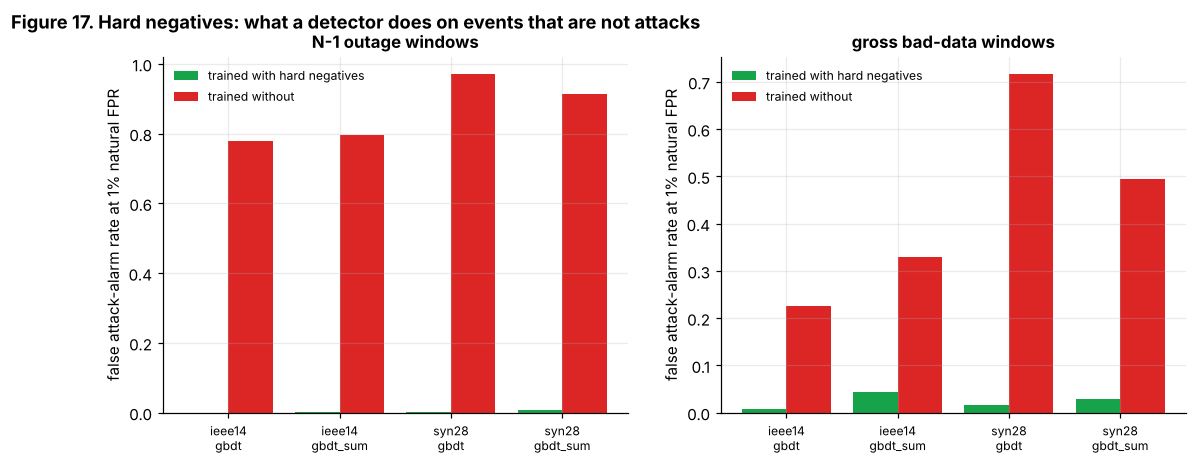

PosixPath('/tmp/w2/proj/figures/fig17_hard_negatives.png')

In [37]:
def gen_hardneg_test(name, n=300):
    sim, cal = SIMS[name], CAL[name]; rng = rng_for("hn_test", *[ord(c) for c in name])
    out = {}
    for kind in ("outage", "outlier"):
        X, J, R = [], [], []
        while len(X) < n:
            s = new_sample(sim, rng, kind)
            if s is None: continue
            z, V, _ = s; xh, j, r = sim.estimate(z); X.append(xh); J.append(j); R.append(np.max(np.abs(r) / sim.mt["sigma"]))
        out[kind] = dict(x=np.array(X), J=np.array(J), rmax=np.array(R))
    return out

h14_rows = []
for name in STUDY_GRIDS:
    cal, test, pool = CAL[name], DS[name]["test"], pool_for(name); hn = gen_hardneg_test(name)
    nat = test["kind"] == "natural"
    for Dcls in (GBDT, GBDTSum):
        for seed in range(SIZES["n_budget_seeds"]):
            sub = subsample_balanced(pool, H2_BUDGET, np.random.default_rng(555 + seed))
            for tag, tr_ in [("with", sub), ("without", drop_hard_negatives(sub))]:
                det = Dcls().fit(cal, tr_, seed)
                thr = np.quantile(det.score(cal, test)[nat & (test["label"] == 0)], 0.99)
                fa = {k: float(np.mean(det.score(cal, v) > thr)) for k, v in hn.items()}
                h14_rows.append(dict(grid=name, det=det.name, seed=seed, training=tag, fa_outage=fa["outage"], fa_outlier=fa["outlier"]))
H14 = pd.DataFrame(h14_rows)
piv = H14.groupby(["grid", "det", "training"])[["fa_outage", "fa_outlier"]].mean().unstack("training").round(3)
print(piv.to_string())
w_, wo_ = H14[H14.training == "with"], H14[H14.training == "without"]
H14_ratio = float(wo_.fa_outage.mean() / max(w_.fa_outage.mean(), 1e-3)); print(f"\nmean outage alarm rate: with {w_.fa_outage.mean():.3f}, without {wo_.fa_outage.mean():.3f}, ratio {H14_ratio:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, ttl in zip(axes, ["fa_outage", "fa_outlier"], ["N-1 outage windows", "gross bad-data windows"]):
    tab = H14.groupby(["grid", "det", "training"])[col].mean().unstack("training")
    x_ = np.arange(len(tab)); ax.bar(x_ - 0.2, tab["with"], 0.4, color=PAL["green"], label="trained with hard negatives")
    ax.bar(x_ + 0.2, tab["without"], 0.4, color=PAL["red"], label="trained without")
    ax.set_xticks(x_); ax.set_xticklabels([f"{g}\n{d}" for g, d in tab.index], fontsize=8); ax.set_ylabel("false attack-alarm rate at 1% natural FPR"); ax.set_title(ttl); ax.legend(fontsize=8)
fig.suptitle("Figure 17. Hard negatives: what a detector does on events that are not attacks", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig17_hard_negatives")

## Part 12. From detection to damage: the LFC plant

F1 and AUROC say how well a detector separates attacks from clean windows. They do not say *what the attacker gets away with*. In load-frequency control, a stealth shift of the state estimate that fakes a tie-line flow reading is fed into the area control error (ACE), so the automatic generation control (AGC) tries to "correct" a flow imbalance that does not exist. The physical result is a frequency excursion.

### 12.1 A two-area LFC model

Standard linearised two-area model (per area: inertia $2H$, damping $D$, governor $T_g$ with droop $R$, turbine $T_t$, integral AGC with gain $K_i$ acting on $\mathrm{ACE}_i=B_i\Delta f_i\pm(\Delta P_{tie}+b)$), coupled by a synchronising tie-line with coefficient $T_{12}$. The attack enters as a bias $b$ on the tie-line reading used by both areas' ACE. The plant is linear, so peak damage scales linearly with $b$ and we only need the response to a unit bias.

Parameters follow common textbook values; $K_i$ is chosen so that the nominal loop is stable and reasonably damped (checked below by eigenvalues). The plant is a stand-in for the NL-LFC plant of the earlier project (which has eight nonlinearities); using the linear one keeps the damage ceiling in closed form, and its limitations are stated in the scorecard.

In [38]:
from scipy import signal
LFC = dict(H=(5.0, 5.0), D=(1.0, 1.0), R=(0.05, 0.05), Tg=(0.2, 0.2), Tt=(0.5, 0.5), Ki=(0.12, 0.12), T12=0.2, f0=60.0)

def lfc_ss(P=LFC):
    H, D, R, Tg, Tt, Ki = [np.array(P[k]) for k in ("H", "D", "R", "Tg", "Tt", "Ki")]; T12 = P["T12"]
    B = 1 / R + D
    A = np.zeros((9, 9)); Bm = np.zeros((9, 1))
    # states: [df1, Pm1, Pv1, Pref1, df2, Pm2, Pv2, Pref2, Ptie]
    for a, o in ((0, 0), (1, 4)):
        i = o
        A[i, i] = -D[a] / (2 * H[a]); A[i, i + 1] = 1 / (2 * H[a])
        A[i + 1, i + 1] = -1 / Tt[a]; A[i + 1, i + 2] = 1 / Tt[a]
        A[i + 2, i] = -1 / (R[a] * Tg[a]); A[i + 2, i + 2] = -1 / Tg[a]; A[i + 2, i + 3] = 1 / Tg[a]
        sgn = 1.0 if a == 0 else -1.0                # tie flow leaves area 1 and enters area 2
        A[i, 8] = -sgn / (2 * H[a])
        A[i + 3, i] = -Ki[a] * B[a]; A[i + 3, 8] = -Ki[a] * sgn; Bm[i + 3, 0] = -Ki[a] * sgn
    A[8, 0] = 2 * np.pi * T12; A[8, 4] = -2 * np.pi * T12
    C = np.zeros((5, 9)); C[0, 0] = 1; C[1, 4] = 1
    C[2, 0] = B[0]; C[2, 8] = 1; C[3, 4] = B[1]; C[3, 8] = -1; C[4, 8] = 1
    Dm = np.zeros((5, 1)); Dm[2, 0] = 1; Dm[3, 0] = -1
    return signal.StateSpace(A, Bm, C, Dm)

ss = lfc_ss(); ev = np.linalg.eigvals(ss.A)
print("max real part of eigenvalues:", ev.real.max().round(4), "(must be < 0)   slowest damping ratio:",
      round(float(np.min(-ev.real / np.abs(ev))), 3))
assert ev.real.max() < 0
tt = np.linspace(0, 300, 3001)
_, yy, _ = signal.lsim(ss, U=np.ones_like(tt), T=tt)
G_f = float(np.max(np.abs(yy[:, :2])) * LFC["f0"])        # Hz of peak frequency deviation per unit (pu) tie-line bias
G_ace = float(np.max(np.abs(yy[:, 2:4])))
print(f"peak |df| per 1 pu fake tie-line bias: {G_f:.3f} Hz;  peak |ACE|: {G_ace:.3f} pu")

max real part of eigenvalues: -0.1198 (must be < 0)   slowest damping ratio: 0.265
peak |df| per 1 pu fake tie-line bias: 1.079 Hz;  peak |ACE|: 1.000 pu


### 12.2 The plant and the attack's footprint (Figure 18)

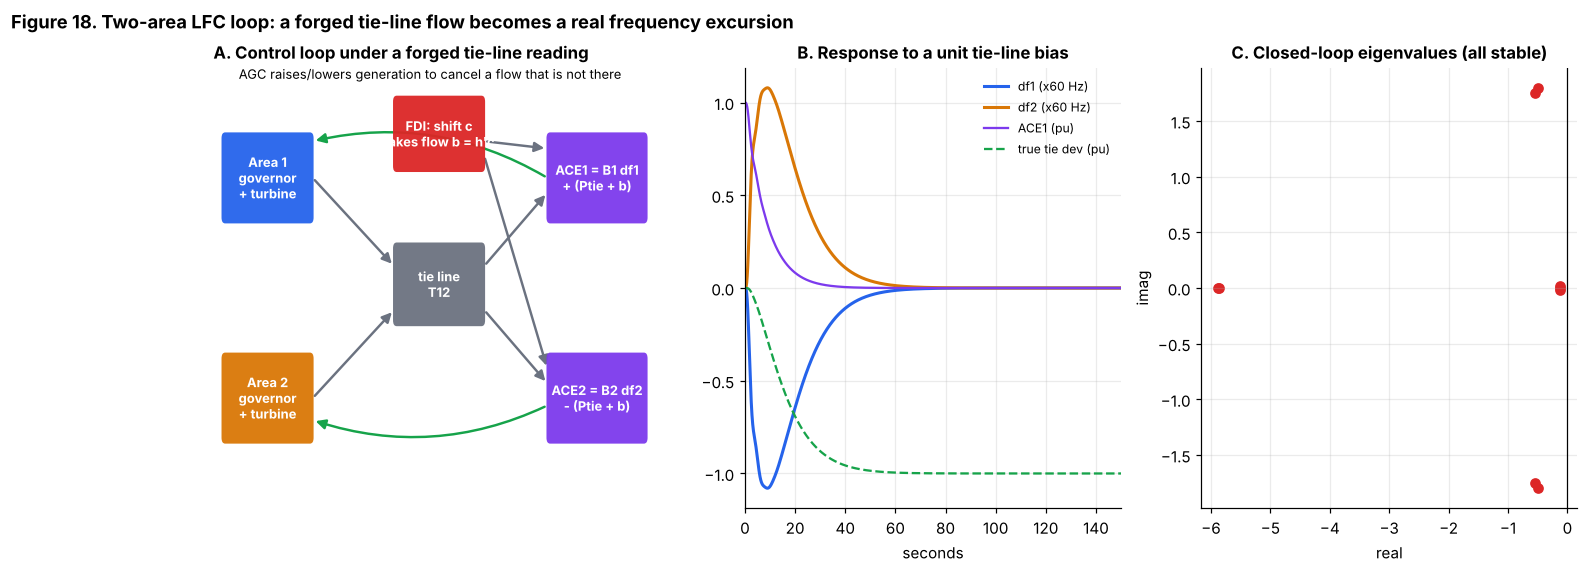

PosixPath('/tmp/w2/proj/figures/fig18_lfc_plant.png')

In [39]:
fig = plt.figure(figsize=(16, 5.2)); gs = fig.add_gridspec(1, 3, width_ratios=[1.2, 1, 1])
ax = fig.add_subplot(gs[0]); ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off"); ax.set_title("A. Control loop under a forged tie-line reading", loc="left")
box(ax, (0.2, 3.9), 2.0, 1.2, "Area 1\ngovernor\n+ turbine", PAL["blue"], 8.5); box(ax, (0.2, 0.9), 2.0, 1.2, "Area 2\ngovernor\n+ turbine", PAL["amber"], 8.5)
box(ax, (4.0, 2.5), 2.0, 1.1, "tie line\nT12", PAL["grey"], 8.5); box(ax, (7.4, 3.9), 2.2, 1.2, "ACE1 = B1 df1\n+ (Ptie + b)", PAL["purple"], 8.5)
box(ax, (7.4, 0.9), 2.2, 1.2, "ACE2 = B2 df2\n- (Ptie + b)", PAL["purple"], 8.5)
box(ax, (4.0, 4.6), 2.0, 1.0, "FDI: shift c\nfakes flow b = h'c", PAL["red"], 8.5)
for p0, p1 in [((2.2, 4.5), (4.0, 3.3)), ((2.2, 1.5), (4.0, 2.7)), ((6.0, 3.3), (7.4, 4.3)), ((6.0, 2.7), (7.4, 1.7)), ((6.0, 5.0), (7.4, 4.9)), ((6.0, 4.8), (7.4, 1.9))]:
    arrow(ax, p0, p1)
arrow(ax, (7.4, 4.5), (2.2, 5.0), color=PAL["green"], rad=0.2); arrow(ax, (7.4, 1.4), (2.2, 1.2), color=PAL["green"], rad=-0.2)
ax.text(4.8, 5.85, "AGC raises/lowers generation to cancel a flow that is not there", fontsize=8.5, ha="center")
ax = fig.add_subplot(gs[1])
for k, (nm, col) in enumerate([("df1 (x60 Hz)", PAL["blue"]), ("df2 (x60 Hz)", PAL["amber"])]): ax.plot(tt, yy[:, k] * LFC["f0"], color=col, label=nm, lw=2)
ax.plot(tt, yy[:, 2], color=PAL["purple"], label="ACE1 (pu)", lw=1.5); ax.plot(tt, yy[:, 4], color=PAL["green"], label="true tie dev (pu)", lw=1.5, ls="--")
ax.set_xlim(0, 150); ax.set_xlabel("seconds"); ax.set_title("B. Response to a unit tie-line bias"); ax.legend(fontsize=8)
ax = fig.add_subplot(gs[2]); ax.scatter(ev.real, ev.imag, color=PAL["red"], s=36); ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("real"); ax.set_ylabel("imag"); ax.set_title("C. Closed-loop eigenvalues (all stable)")
fig.suptitle("Figure 18. Two-area LFC loop: a forged tie-line flow becomes a real frequency excursion", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig18_lfc_plant")

### 12.3 The damage ceiling, checked on the data (Figure 19)

For a grid with fake-flow sensitivity $h$ and clean covariance $\Sigma$, any attack of hardness $\delta$ fakes at most $\delta\sqrt{h^\top\Sigma h}$ of tie-line flow (Part 2). Scaled to the LFC area base, and multiplied by the plant's peak-frequency gain $G_f$, this is a **damage ceiling** that holds against every detector, since hardness is a property of the attack, not of the detector. Two checks: (i) no realised attack exceeds the ceiling; (ii) `lfc`-direction attacks sit near it when the attacker's model of the grid is exact (`ac` model), so the ceiling is attainable and not a loose bound. A *linear* attacker (stale Jacobian) leaks energy into the tight directions of $\Sigma$, so its *realised* hardness is much larger than the hardness it aimed for; it therefore lands well below the ceiling at its realised hardness. That is a finding about imperfect attackers, not a bug.

  grid  max_ratio_to_ceiling  lfc_ac_median_ratio  lfc_linear_median_ratio  sparse_median_ratio
ieee14                   1.0                  1.0                    0.490                0.002
 syn28                   1.0                  1.0                    0.289                0.000


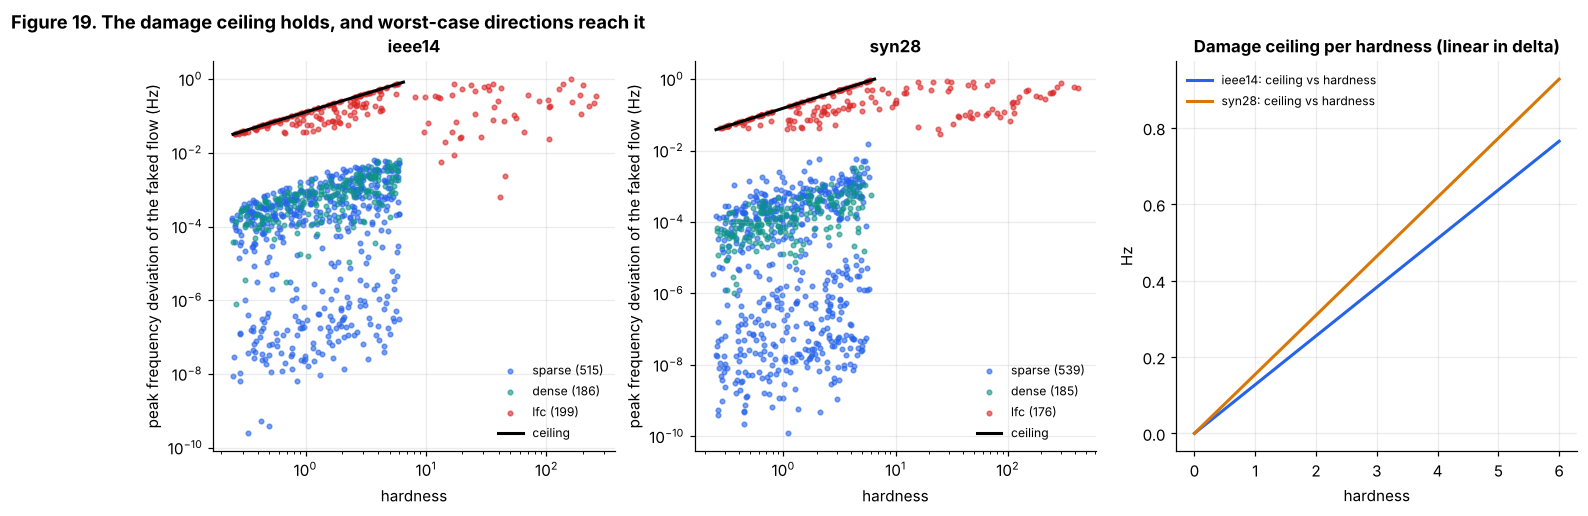

In [40]:
def area_base_MW(g): return 0.5 * g.Pd.sum()
def flow_to_Hz(g, flow_pu): return np.abs(flow_pu) * g.baseMVA / area_base_MW(g) * G_f

ceil_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, name in zip(axes[:2], STUDY_GRIDS):
    sim, cal, te = SIMS[name], CAL[name], DS[name]["test"]; ia = te["label"] == 1
    sq = float(np.sqrt(sim.h_tie @ cal.Sigma @ sim.h_tie))
    dl, fl, dk, mdl = te["delta"][ia], np.abs(te["flow"][ia]), te["dirkind"][ia], te["model"][ia]
    ratio = fl / (dl * sq)
    for kind, col in [("sparse", PAL["blue"]), ("dense", PAL["teal"]), ("lfc", PAL["red"])]:
        m = dk == kind; ax.scatter(dl[m], flow_to_Hz(sim.g, fl[m]), s=9, alpha=0.6, color=col, label=f"{kind} ({m.sum()})")
    xx = np.linspace(0.25, 6.5, 100); ax.plot(xx, flow_to_Hz(sim.g, xx * sq), "k-", lw=2, label="ceiling")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("hardness"); ax.set_ylabel("peak frequency deviation of the faked flow (Hz)"); ax.set_title(name); ax.legend(fontsize=8)
    ceil_rows.append(dict(grid=name, max_ratio_to_ceiling=ratio.max(), lfc_ac_median_ratio=np.median(ratio[(dk == "lfc") & (mdl == "ac")]), lfc_linear_median_ratio=np.median(ratio[(dk == "lfc") & (mdl == "linear")]), sparse_median_ratio=np.median(ratio[dk == "sparse"])))
print(pd.DataFrame(ceil_rows).round(3).to_string(index=False))
ax = axes[2]
for name, col in zip(STUDY_GRIDS, [PAL["blue"], PAL["amber"]]):
    sim, cal = SIMS[name], CAL[name]; sq = float(np.sqrt(sim.h_tie @ cal.Sigma @ sim.h_tie)); dd = np.linspace(0, 6, 100)
    ax.plot(dd, flow_to_Hz(sim.g, dd * sq), color=col, lw=2, label=f"{name}: ceiling vs hardness")
ax.set_xlabel("hardness"); ax.set_ylabel("Hz"); ax.set_title("Damage ceiling per hardness (linear in delta)"); ax.legend(fontsize=8)
fig.suptitle("Figure 19. The damage ceiling holds, and worst-case directions reach it", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig19_damage_ceiling")
assert max(r["max_ratio_to_ceiling"] for r in ceil_rows) < 1.02, "an attack exceeded the damage ceiling"

### 12.4 Damage at budget, and whether it ranks detectors differently from AUROC (H4, Figure 20)

For a detector with threshold fixed at 1% false alarms on natural clean windows, the **expected evaded damage** is

$$\mathbb E[\,\text{damage}\cdot\mathbf 1(\text{attack not alarmed})\,]$$

over the test attacks, with damage measured as the peak frequency deviation (Hz) the faked flow produces. It answers "how much harm do attacks do *after* this detector has done its job?". H4 asks whether ranking the nine detectors by this number gives a different order from ranking them by overall AUROC (Spearman correlation below 0.8).

  grid       det    auc  evaded_damage_mHz  damage_prevented_share  evasion_rate
ieee14 hotelling 0.5989            27.8924                  0.3747        0.9211
ieee14 pca_recon 0.5154            29.9075                  0.3295        0.9367
ieee14   iforest 0.5834            28.9303                  0.3514        0.9244
ieee14      chi2 0.4975            29.0050                  0.3497        0.9411
ieee14    logreg 0.5370            31.1146                  0.3024        0.9511
ieee14      gbdt 0.6334            27.6123                  0.3810        0.9389
ieee14       mlp 0.5729            20.7173                  0.5355        0.9200
ieee14  gbdt_sum 0.6186            34.9792                  0.2158        0.8678
ieee14   mlp_sum 0.6447            28.8691                  0.3528        0.9378
 syn28 hotelling 0.5518            31.7303                  0.4071        0.9244
 syn28 pca_recon 0.4985            39.2669                  0.2662        0.9578
 syn28   iforest 0.5502     

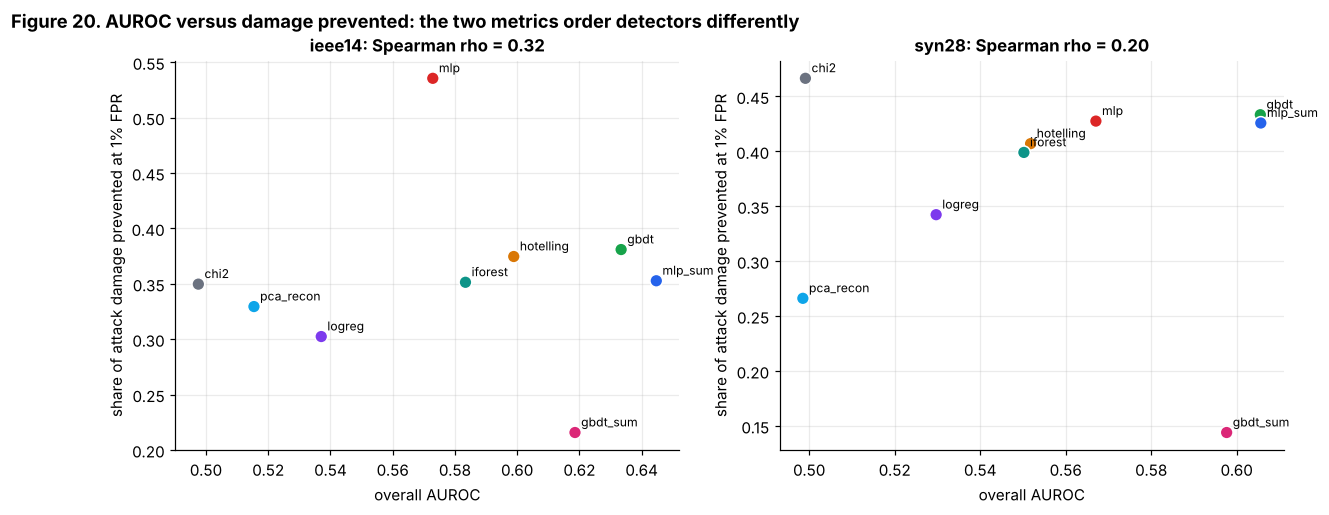

PosixPath('/tmp/w2/proj/figures/fig20_auc_vs_damage.png')

In [41]:
from scipy.stats import spearmanr
def evaded_damage(name, score, test, fpr=0.01):
    nat = (test["kind"] == "natural") & (test["label"] == 0)
    thr = np.quantile(score[nat], 1 - fpr); ia = test["label"] == 1
    dmg = flow_to_Hz(SIMS[name].g, test["flow"][ia]); ev_ = score[ia] <= thr
    return float(np.mean(dmg * ev_)), float(np.mean(dmg)), float(np.mean(ev_))

dm_rows = []
for name in STUDY_GRIDS:
    test = DS[name]["test"]
    for d_, s in INGRID_SCORES[name].items():
        e, tot, evr = evaded_damage(name, s, test)
        dm_rows.append(dict(grid=name, det=d_, auc=overall_auc(s, test), evaded_damage_mHz=1000 * e, damage_prevented_share=1 - e / tot, evasion_rate=evr))
DM = pd.DataFrame(dm_rows)
rho = {g: spearmanr(DM[DM.grid == g].auc, -DM[DM.grid == g].evaded_damage_mHz)[0] for g in STUDY_GRIDS}
print(DM.round(4).to_string(index=False)); print("\nSpearman(AUROC, -evaded damage):", {k: round(v, 3) for k, v in rho.items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, name in zip(axes, STUDY_GRIDS):
    v = DM[DM.grid == name]
    ax.scatter(v.auc, v.damage_prevented_share, s=70, c=[DET_COLORS[d] for d in v.det], edgecolor="white", zorder=3)
    for _, r in v.iterrows(): ax.annotate(r.det, (r.auc, r.damage_prevented_share), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("overall AUROC"); ax.set_ylabel("share of attack damage prevented at 1% FPR"); ax.set_title(f"{name}: Spearman rho = {rho[name]:.2f}")
fig.suptitle("Figure 20. AUROC versus damage prevented: the two metrics order detectors differently", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig20_auc_vs_damage")

## Part 13. Methods layer

Three methods, each a known technique applied to this problem with the oracle framing. None is a new architecture, and the paper should not claim that. Each has a stated claim and a way to fail.

| | Method | Idea | Pre-registered claim |
|---|---|---|---|
| A | Hardness-stratified training | Sample training attacks uniformly in log-hardness instead of uniformly in magnitude | H6: closes at least 20% more of the oracle gap at small hardness |
| B | Oracle distillation | A student that sees only measurements is trained on the oracle's *soft* posterior, computed with the privileged shift $c$ and $\Sigma$ | H7: beats a plain student at 1% and 5% label budgets |
| E | Conformal risk control on damage | Pick the alarm threshold so the *expected evaded damage* is bounded, rather than the false-alarm rate | H8: realised risk stays under budget in at least 95% of calibration splits |

### 13.1 Method A: hardness-stratified training (Figure 21)

Both arms see **the same clean windows** and the same number of attack windows. They differ only in how attack sizes were drawn: log-uniform hardness versus uniform state-unit magnitude (Figure 8C shows how different the resulting hardness distributions are). The gap closure is $(\text{gap}_{\rm mag}-\text{gap}_{\rm strat})/\text{gap}_{\rm mag}$ at hardness 0.5 to 2, with the gap measured to the empirical oracle.

                 auc_strat  auc_mag  oracle  closure
grid   det                                          
ieee14 gbdt          0.559    0.519   0.752    0.171
       gbdt_sum      0.555    0.527   0.752    0.120
       mlp_sum       0.557    0.564   0.752   -0.040
syn28  gbdt          0.539    0.526   0.755    0.054
       gbdt_sum      0.535    0.536   0.755   -0.007
       mlp_sum       0.536    0.546   0.755   -0.050

mean gap closure of stratified over uniform-magnitude training: 4.1%


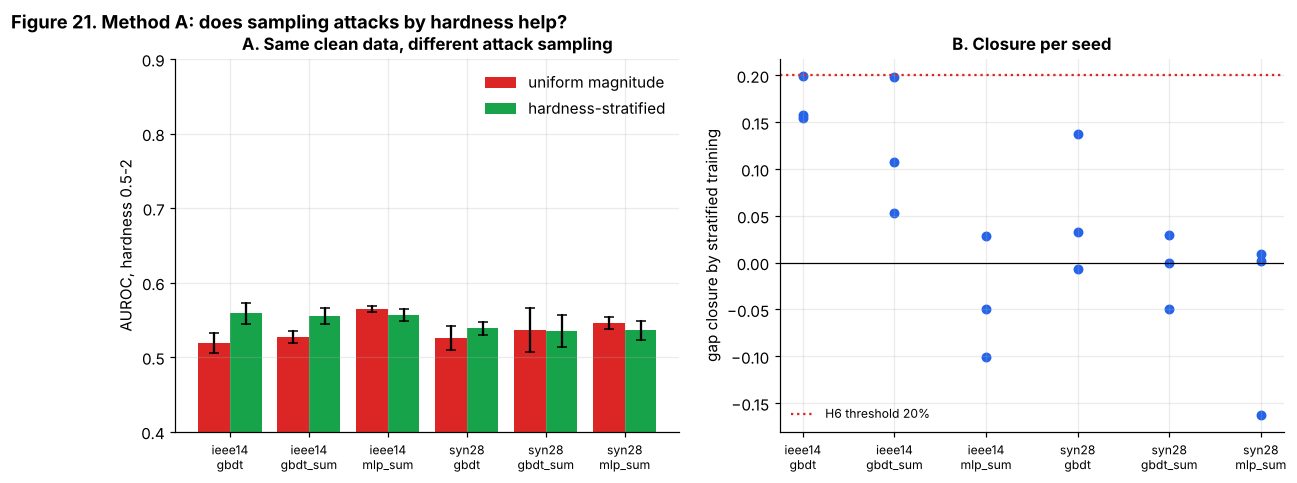

PosixPath('/tmp/w2/proj/figures/fig21_method_A.png')

In [42]:
THRESH["h6_closure"] = 0.20
def build_A_sets(name, seed, n_per):
    rng = np.random.default_rng(9000 + seed); tr = DS[name]["train"]; mg = DS[name]["train_mag"]
    ic = rng.choice(np.where(tr["label"] == 0)[0], n_per, replace=False)
    ia_s = rng.choice(np.where(tr["label"] == 1)[0], n_per, replace=False); ia_m = rng.choice(len(mg["label"]), min(n_per, len(mg["label"])), replace=False)
    clean = {k: v[ic] for k, v in tr.items()}
    strat = concat_blocks(clean, {k: v[ia_s] for k, v in tr.items()}); mag = concat_blocks(clean, {k: v[ia_m] for k, v in mg.items()})
    return strat, mag

N_PER_A = 600 if BUDGET == "full" else 150
A_rows = []
for name in STUDY_GRIDS:
    cal, te = CAL[name], DS[name]["test"]; orc = float(np.nanmean(oracle_by_bin(cal, te, np.array([0.5, 1.0, 2.0]))))
    for seed in range(SIZES["n_budget_seeds"]):
        strat, mag = build_A_sets(name, seed, N_PER_A)
        for Dcls in (GBDT, GBDTSum, MLPSum):
            r = {}
            for tag, tr_ in (("strat", strat), ("mag", mag)):
                det = Dcls().fit(cal, tr_, seed); r[tag] = small_auc(det.score(cal, te), te)
            A_rows.append(dict(grid=name, det=Dcls.name, seed=seed, auc_strat=r["strat"], auc_mag=r["mag"], oracle=orc,
                               closure=((orc - r["mag"]) - (orc - r["strat"])) / (orc - r["mag"])))
A = pd.DataFrame(A_rows)
print(A.groupby(["grid", "det"])[["auc_strat", "auc_mag", "oracle", "closure"]].mean().round(3).to_string())
H6_val = float(A.groupby(["grid", "det"]).closure.mean().mean()); print(f"\nmean gap closure of stratified over uniform-magnitude training: {H6_val:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
g_ = A.groupby(["grid", "det"])[["auc_strat", "auc_mag"]].mean(); s_ = A.groupby(["grid", "det"])[["auc_strat", "auc_mag"]].std()
x_ = np.arange(len(g_)); ax.bar(x_ - 0.2, g_.auc_mag, 0.4, yerr=s_.auc_mag, color=PAL["red"], capsize=3, label="uniform magnitude")
ax.bar(x_ + 0.2, g_.auc_strat, 0.4, yerr=s_.auc_strat, color=PAL["green"], capsize=3, label="hardness-stratified")
ax.set_xticks(x_); ax.set_xticklabels([f"{a}\n{b}" for a, b in g_.index], fontsize=8); ax.set_ylim(0.4, 0.9); ax.set_ylabel("AUROC, hardness 0.5-2"); ax.legend(); ax.set_title("A. Same clean data, different attack sampling")
ax = axes[1]
for (g, d), v in A.groupby(["grid", "det"]): ax.scatter([f"{g}\n{d}"] * len(v), v.closure, color=PAL["blue"], s=30)
ax.axhline(THRESH["h6_closure"], color=PAL["red"], ls=":", label="H6 threshold 20%"); ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("gap closure by stratified training"); ax.legend(fontsize=8)
ax.tick_params(axis="x", labelsize=8); ax.set_title("B. Closure per seed")
fig.suptitle("Figure 21. Method A: does sampling attacks by hardness help?", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig21_method_A")

### 13.2 Method B: oracle distillation (Figure 22)

**Teacher.** For a training window with state estimate $\hat x$ and (privileged) shift $c$, the oracle posterior that the window is "clean plus shift $c$" rather than clean, under the Gaussian shift model with equal priors, is $\sigma\!\big(\mathrm{LLR}\big)$ with $\mathrm{LLR}=c^\top\Sigma^{-1}(\hat x-\mu)-\tfrac12\delta^2$. For attacked windows $c$ is the true realised shift. A clean window has no shift, so it is paired with a *virtual* shift drawn from the training attacks, and its soft label is the posterior under that virtual direction (for a clean window this is usually near 0, but not exactly).

**Students.** Identical small MLPs on the summary view, with the same fixed hyperparameters and training schedule. The *plain* student regresses the hard 0/1 label; the *distilled* student regresses the teacher posterior. Both are scored by their raw output. Budgets are 1% and 5% of the largest pool (36 and 180 windows); five seeds.

The comparison isolates what the privileged signal adds per labelled window. It does **not** claim the teacher is available at deployment, only in simulation.

               auc_plain  auc_dist   gain
grid   budget                            
ieee14 36          0.503     0.481 -0.022
       180         0.541     0.545  0.004
syn28  36          0.532     0.518 -0.014
       180         0.530     0.518 -0.013

H7 readout: {36: {'mean_gain': -0.017844929070112852, 'frac_pos': 0.3}, 180: {'mean_gain': -0.0041268568033274115, 'frac_pos': 0.6}}


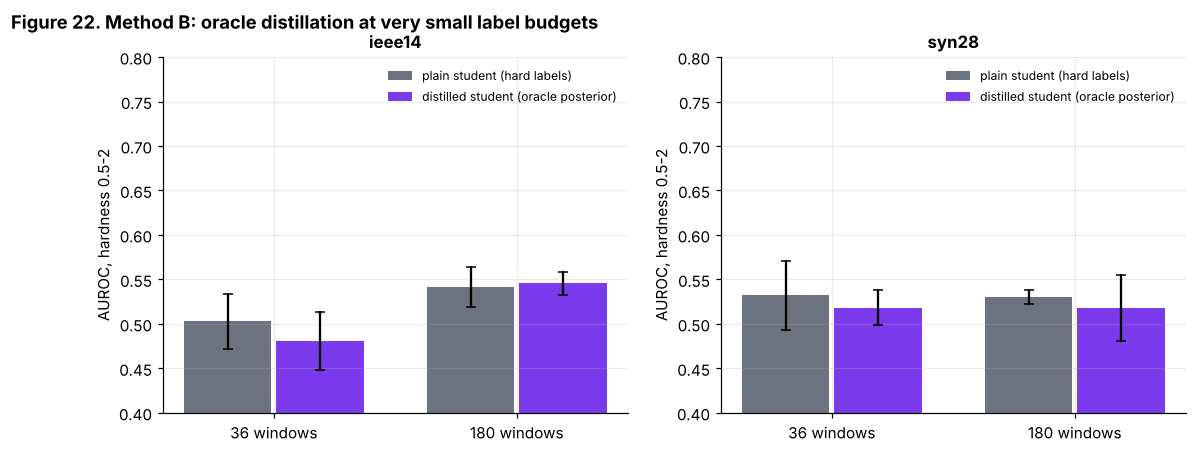

PosixPath('/tmp/w2/proj/figures/fig22_method_B.png')

In [43]:
THRESH["h7_min_pairs"] = 0.7
BUD_B = [36, 180] if BUDGET == "full" else [20, 60]
SEEDS_B = 5 if BUDGET == "full" else 3

def teacher_posterior(cal, d, rng):
    X = d["x"] - cal.mu; ia = np.where(d["label"] == 1)[0]
    C = d["shift"].copy()
    ic = np.where(d["label"] == 0)[0]; C[ic] = d["shift"][rng.choice(ia, len(ic))]       # virtual shifts for clean windows
    llr = np.einsum("ij,jk,ik->i", C, cal.Sinv, X) - 0.5 * cal.delta(C) ** 2
    return 1 / (1 + np.exp(-np.clip(llr, -30, 30)))

def fit_student(Xf, target, seed, regress=True):
    sc = StandardScaler().fit(Xf)
    kw = dict(hidden_layer_sizes=(64, 32), alpha=1e-3, learning_rate_init=1e-3, max_iter=600, random_state=seed)
    m = (MLPRegressor(**kw) if regress else MLPClassifier(**kw)).fit(sc.transform(Xf), target)
    return lambda F: (m.predict(sc.transform(F)) if regress else m.predict_proba(sc.transform(F))[:, 1])

B_rows = []
for name in STUDY_GRIDS:
    cal, te, pool = CAL[name], DS[name]["test"], pool_for(name); Fte = summary_features(cal, te)
    for b in BUD_B:
        for seed in range(SEEDS_B):
            sub = subsample_balanced(pool, b, np.random.default_rng(31 * seed + b)); F = summary_features(cal, sub)
            tp = teacher_posterior(cal, sub, np.random.default_rng(seed))
            plain = fit_student(F, sub["label"], seed, regress=False); dist = fit_student(F, tp, seed, regress=True)
            B_rows.append(dict(grid=name, budget=b, seed=seed, auc_plain=small_auc(plain(Fte), te), auc_dist=small_auc(dist(Fte), te),
                               all_plain=overall_auc(plain(Fte), te), all_dist=overall_auc(dist(Fte), te)))
B = pd.DataFrame(B_rows); B["gain"] = B.auc_dist - B.auc_plain
print(B.groupby(["grid", "budget"])[["auc_plain", "auc_dist", "gain"]].mean().round(3).to_string())
H7 = {int(b): dict(mean_gain=float(v.gain.mean()), frac_pos=float((v.gain > 0).mean())) for b, v in B.groupby("budget")}; print("\nH7 readout:", H7)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, name in zip(axes, STUDY_GRIDS):
    v = B[B.grid == name]; xs_ = np.arange(len(BUD_B))
    for k, (col, lab) in enumerate([("auc_plain", "plain student (hard labels)"), ("auc_dist", "distilled student (oracle posterior)")]):
        m = [v[v.budget == b][col].mean() for b in BUD_B]; s = [v[v.budget == b][col].std() for b in BUD_B]
        ax.bar(xs_ + (k - 0.5) * 0.38, m, 0.36, yerr=s, capsize=3, color=[PAL["grey"], PAL["purple"]][k], label=lab)
    ax.set_xticks(xs_); ax.set_xticklabels([f"{b} windows" for b in BUD_B]); ax.set_ylim(0.4, 0.8); ax.set_ylabel("AUROC, hardness 0.5-2"); ax.set_title(name); ax.legend(fontsize=8)
fig.suptitle("Figure 22. Method B: oracle distillation at very small label budgets", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig22_method_B")

### 13.3 Method E: conformal risk control on evaded damage (Figure 23)

**Setup.** Only attacks aimed at the tie line (`lfc` direction) by an attacker with an exact grid model (`ac`) are used. Linear attackers with a stale Jacobian realise far higher hardness than intended and are caught easily, so they would make a damage budget vacuous: sparse and dense attacks fake almost no tie-line flow (their damage is under 1% of the ceiling), so a damage budget on them is vacuous, and with so small an $\alpha$ the finite-sample term $1/(n+1)$ alone would exceed it. For a detector with score $s$ (alarm when $s>\lambda$), define for an attack $i$ with damage $D_i$ (peak frequency deviation) the loss

$$L_i(\lambda)=\frac{D_i}{D_{\max}}\,\mathbf 1\{s_i\le\lambda\}\in[0,1],$$

the normalised damage of an attack that *evades* the threshold. It is non-decreasing in $\lambda$, which is the monotonicity conformal risk control needs. $D_{\max}$ is the damage ceiling at the largest realised hardness among test attacks (at least 6.5). Any constant that bounds the loss in $[0,1]$ is valid; a larger one only makes the guarantee looser through the $1/(n+1)$ term.

**Rule.** With $n$ calibration attacks, choose the largest threshold satisfying

$$\tfrac{n}{n+1}\,\hat R_n(\lambda)+\tfrac{1}{n+1}\le\alpha,\qquad \hat R_n(\lambda)=\tfrac1n\sum_i L_i(\lambda).$$

The guarantee (Angelopoulos et al., conformal risk control) is on the **expected** loss of a new exchangeable attack: $\mathbb E[L_{n+1}(\hat\lambda)]\le\alpha$. I have not re-verified the exact statement of the assumptions from the full paper in this session, so the checks below are *empirical*: (i) is the average realised risk under $\alpha$, and (ii) in what fraction of individual calibration splits is the realised risk under $\alpha$?

H8 as pre-registered is the **stricter, per-split** statement (ii) at 95%. The expectation-level guarantee does not imply it, and the readout below shows both.

  grid       det  alpha  mean_risk  frac_splits_under  mean_fpr  risk_at_1pct_fpr  no_detector_risk
ieee14 hotelling 0.1307     0.1032             0.8125    0.2239            0.2550            0.2614
ieee14  gbdt_sum 0.1307     0.1028             0.7600    0.3747            0.2606            0.2614
ieee14      gbdt 0.1307     0.1038             0.7300    0.3094            0.1733            0.2614
 syn28 hotelling 0.1448     0.1143             0.8250    0.3914            0.2897            0.2897
 syn28  gbdt_sum 0.1448     0.1110             0.7500    0.6597            0.2890            0.2897
 syn28      gbdt 0.1448     0.1170             0.7200    0.2450            0.2262            0.2897

H8 readout: {'mean_risk_under_alpha': True, 'frac_splits_under': 0.76625, 'mean_fpr': 0.36734543697933897, 'vacuous': False}


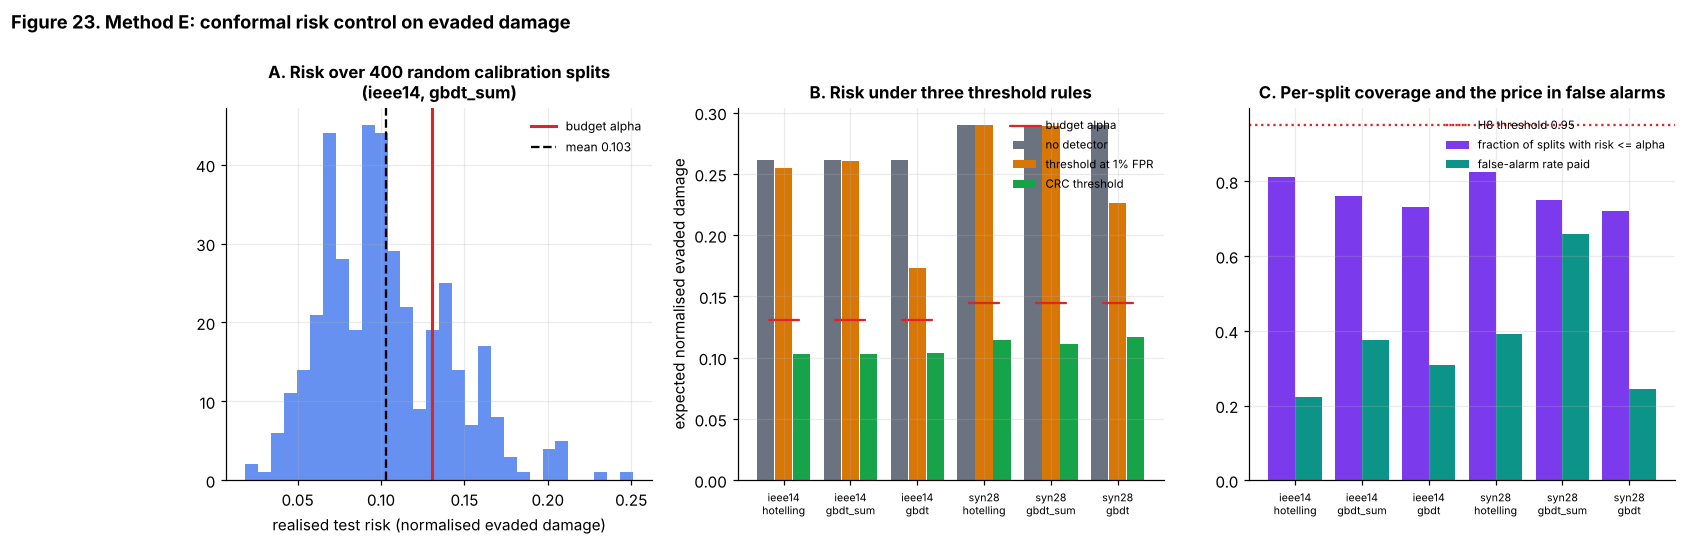

PosixPath('/tmp/w2/proj/figures/fig23_method_E.png')

In [44]:
import zlib
THRESH["h8_cov"] = 0.95
def crc_threshold(scores_att, loss_w, alpha):
    """Largest lambda with (n/(n+1)) R_hat(lambda) + 1/(n+1) <= alpha. loss_w = D_i / D_max in [0,1]."""
    n = len(scores_att); o = np.argsort(scores_att); s = scores_att[o]; w = loss_w[o]
    cum = np.cumsum(w)                       # R_hat(lambda=s_k) = cum[k]/n  (loss of attacks with score <= s_k)
    ok = (n / (n + 1)) * (cum / n) + 1 / (n + 1) <= alpha
    if not ok.any(): return -np.inf          # even the smallest threshold cannot meet alpha: alarm on everything
    return s[np.where(ok)[0].max()]

crc_rows = []; crc_curves = {}
N_SPLITS = 400
for name in STUDY_GRIDS:
    sim, cal, te = SIMS[name], CAL[name], DS[name]["test"]; ia = np.where((te["label"] == 1) & (te["dirkind"] == "lfc") & (te["model"] == "ac"))[0]
    sq = float(np.sqrt(sim.h_tie @ cal.Sigma @ sim.h_tie)); dcap = max(6.5, float(te['delta'][ia].max())); Dmax = float(flow_to_Hz(sim.g, dcap * sq))
    dmg = flow_to_Hz(sim.g, te["flow"][ia]) / Dmax
    assert dmg.max() <= 1.0 + 1e-9
    alpha = 0.5 * dmg.mean()                  # target: halve the damage an undetected attacker would do
    for det in ("hotelling", "gbdt_sum", "gbdt"):
        s_all = INGRID_SCORES[name][det]; s_att = s_all[ia]; nat = (te["kind"] == "natural") & (te["label"] == 0)
        risks, fprs = [], []; rng = np.random.default_rng(3 + zlib.crc32((name + det).encode()) % 1000)
        for _ in range(N_SPLITS):
            perm = rng.permutation(len(ia)); cal_i, test_i = perm[: len(ia) // 2], perm[len(ia) // 2:]
            lam = crc_threshold(s_att[cal_i], dmg[cal_i], alpha)
            risks.append(float(np.mean(dmg[test_i] * (s_att[test_i] <= lam)))); fprs.append(float(np.mean(s_all[nat] > lam)))
        risks, fprs = np.array(risks), np.array(fprs)
        thr1 = np.quantile(s_all[nat], 0.99); risk_fpr = float(np.mean(dmg * (s_att <= thr1)))
        crc_rows.append(dict(grid=name, det=det, alpha=alpha, mean_risk=risks.mean(), frac_splits_under=float(np.mean(risks <= alpha)),
                             mean_fpr=fprs.mean(), risk_at_1pct_fpr=risk_fpr, no_detector_risk=float(dmg.mean())))
        crc_curves[(name, det)] = (risks, alpha)
CRC = pd.DataFrame(crc_rows); print(CRC.round(4).to_string(index=False))
H8 = dict(mean_risk_under_alpha=bool((CRC.mean_risk <= CRC.alpha).all()), frac_splits_under=float(CRC.frac_splits_under.mean()), mean_fpr=float(CRC.mean_fpr.mean()), vacuous=bool(CRC.mean_fpr.mean() > 0.5))
print("\nH8 readout:", H8)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
ax = axes[0]; k_ = ("ieee14", "gbdt_sum"); r_, a_ = crc_curves[k_]
ax.hist(r_, bins=30, color=PAL["blue"], alpha=0.7); ax.axvline(a_, color=PAL["red"], lw=2, label="budget alpha"); ax.axvline(r_.mean(), color="k", ls="--", label=f"mean {r_.mean():.3f}")
ax.set_xlabel("realised test risk (normalised evaded damage)"); ax.set_title("A. Risk over 400 random calibration splits\n(ieee14, gbdt_sum)"); ax.legend(fontsize=8)
ax = axes[1]
lab = [f"{g}\n{d}" for g, d in zip(CRC.grid, CRC.det)]; x_ = np.arange(len(CRC))
ax.bar(x_ - 0.27, CRC.no_detector_risk, 0.26, color=PAL["grey"], label="no detector"); ax.bar(x_, CRC.risk_at_1pct_fpr, 0.26, color=PAL["amber"], label="threshold at 1% FPR")
ax.bar(x_ + 0.27, CRC.mean_risk, 0.26, color=PAL["green"], label="CRC threshold"); ax.scatter(x_, CRC.alpha, marker="_", s=400, color=PAL["red"], zorder=5, label="budget alpha")
ax.set_xticks(x_); ax.set_xticklabels(lab, fontsize=7); ax.set_ylabel("expected normalised evaded damage"); ax.legend(fontsize=7.5); ax.set_title("B. Risk under three threshold rules")
ax = axes[2]
ax.bar(x_ - 0.2, CRC.frac_splits_under, 0.4, color=PAL["purple"], label="fraction of splits with risk <= alpha"); ax.bar(x_ + 0.2, CRC.mean_fpr, 0.4, color=PAL["teal"], label="false-alarm rate paid")
ax.axhline(THRESH["h8_cov"], color=PAL["red"], ls=":", label="H8 threshold 0.95"); ax.set_xticks(x_); ax.set_xticklabels(lab, fontsize=7); ax.legend(fontsize=7.5); ax.set_title("C. Per-split coverage and the price in false alarms")
fig.suptitle("Figure 23. Method E: conformal risk control on evaded damage", x=0.01, y=1.08, ha="left", fontweight="bold")
savefig(fig, "fig23_method_E")

## Part 14. An adaptive attacker (H5)

Everything so far assumes the attacker does not know the detector. Here the attacker is given **white-box score access** to the deployed detector and a damage requirement, and chooses the attack direction to evade it.

**Attacker model.** In whitened coordinates $z=L^{-1}c$ (with $\Sigma=LL^\top$) the hardness is $\|z\|=\delta_0$, and the faked tie-line flow is $h^\top c=v^\top z$ with $v=L^\top h$, so the ceiling is $\|v\|\delta_0$. The attacker must reach at least a fraction $\rho$ of the ceiling:

$$z=\delta_0\big(\cos\varphi\,\hat v+\sin\varphi\,w\big),\qquad \cos\varphi=\rho,\quad w\perp\hat v,\ \|w\|=1 .$$

So hardness and damage are fixed, and the only freedom is the unit direction $w$ in the $(n_s-1)$-dimensional orthogonal complement. A clean-only quadratic test (Hotelling) has an expected score that depends on $\delta_0$ alone, so it should be indifferent to $w$. A supervised detector has learned *which* directions its training attacks occupied and may have blind spots.

**Protocol.** The attacker owns a set of natural windows $A$ and draws $K$ random directions $w$. It applies each to $A$ (adding $c$ to the state estimate and leaving the residual statistics untouched, as the exact-model attacker does) and picks the $w^\star$ with the lowest mean detector score. We then evaluate AUROC on a **disjoint** set of windows $T$. The non-adaptive reference is the mean AUROC over random $w$ at the same $(\delta_0,\rho)$. The *power loss* is reference minus adaptive AUROC. Selecting the best of $K$ candidates has a small optimism that also affects Hotelling, so Hotelling's loss is the control that shows how much of a loss is just selection noise.

H5 holds if the mean power loss of the supervised detectors exceeds Hotelling's.

ieee14 adaptive attacker done


syn28 adaptive attacker done


                        ref  adaptive   loss
grid   rho det                              
ieee14 0.5 gbdt       0.607     0.536  0.071
           gbdt_sum   0.525     0.520  0.005
           hotelling  0.572     0.567  0.004
           logreg     0.496     0.312  0.184
           mlp        0.543     0.377  0.166
           mlp_sum    0.541     0.534  0.007
       0.8 gbdt       0.652     0.628  0.024
           gbdt_sum   0.515     0.515 -0.000
           hotelling  0.572     0.566  0.005
           logreg     0.499     0.363  0.137
           mlp        0.566     0.442  0.124
           mlp_sum    0.554     0.551  0.003
syn28  0.5 gbdt       0.506     0.450  0.056
           gbdt_sum   0.508     0.510 -0.002
           hotelling  0.529     0.530 -0.001
           logreg     0.490     0.363  0.127
           mlp        0.477     0.382  0.095
           mlp_sum    0.511     0.508  0.003
       0.8 gbdt       0.515     0.489  0.026
           gbdt_sum   0.507     0.507  0.000
          

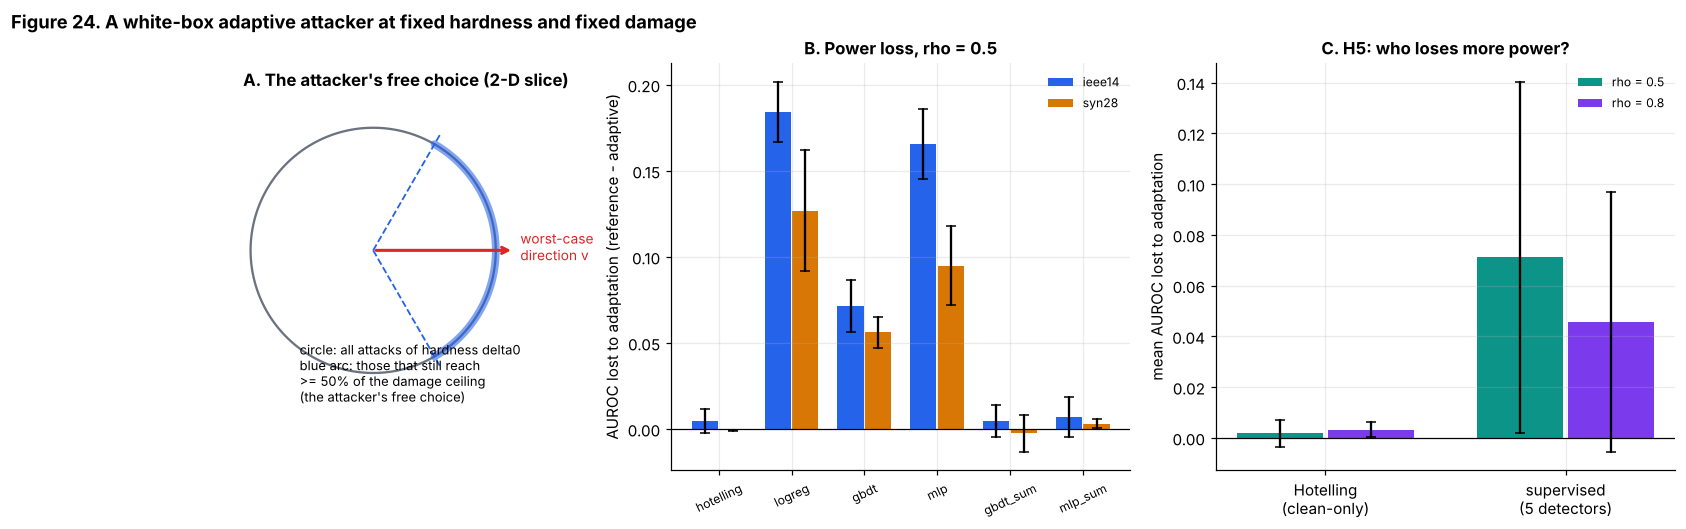

PosixPath('/tmp/w2/proj/figures/fig24_adaptive_attacker.png')

In [45]:
DELTA0, RHOS = 1.5, (0.5, 0.8)
K_CAND = 200 if BUDGET == "full" else 60
N_REF = 30 if BUDGET == "full" else 15
R_ADV = 3 if BUDGET == "full" else 2

def stacked_attack(cal, base, Zs, L):
    """Attack every base window with every whitened direction in Zs -> dict with len(Zs)*len(base) rows."""
    C = Zs @ L.T                                    # (K, ns) shifts in state units
    nb_, K = len(base["x"]), len(Zs)
    return dict(x=(base["x"][None] + C[:, None]).reshape(K * nb_, -1), J=np.tile(base["J"], K), rmax=np.tile(base["rmax"], K))

def auc_pair(s_att, s_clean):
    return roc_auc_score(np.r_[np.zeros(len(s_clean)), np.ones(len(s_att))], np.r_[s_clean, s_att])

def rand_perp(vhat, k, rng):
    W = rng.normal(size=(k, len(vhat))); W -= np.outer(W @ vhat, vhat)
    return W / np.linalg.norm(W, axis=1, keepdims=True)

ADV_ROWS = []
for name in STUDY_GRIDS:
    sim, cal, te, pool = SIMS[name], CAL[name], DS[name]["test"], pool_for(name)
    nat = {k: v[(te["kind"] == "natural") & (te["label"] == 0)] for k, v in te.items()}
    v = cal.L.T @ sim.h_tie; vhat = v / np.linalg.norm(v)
    sub = subsample_balanced(pool, H2_BUDGET, np.random.default_rng(555))
    dets = {"hotelling": Hotelling().fit(cal, None, 0)}
    for D in (LogReg, GBDT, MLP, GBDTSum, MLPSum): dets[D.name] = D().fit(cal, sub, 0)
    for rho_ in RHOS:
        for r in range(R_ADV):
            rng = np.random.default_rng(100 * r + int(10 * rho_)); perm = rng.permutation(len(nat["x"])); h_ = len(perm) // 2
            A = {k: v_[perm[:h_]] for k, v_ in nat.items()}; T = {k: v_[perm[h_:]] for k, v_ in nat.items()}
            def Zof(W): return DELTA0 * (rho_ * vhat[None] + np.sqrt(1 - rho_ ** 2) * W)
            Wk = rand_perp(vhat, K_CAND, rng); Wr = rand_perp(vhat, N_REF, rng)
            attA = stacked_attack(cal, A, Zof(Wk), cal.L); attR = stacked_attack(cal, T, Zof(Wr), cal.L)
            for dn, det in dets.items():
                sA = det.score(cal, attA).reshape(K_CAND, -1).mean(1); star = int(np.argmin(sA))
                sc_clean = det.score(cal, T); sR = det.score(cal, attR).reshape(N_REF, -1)
                ref = float(np.mean([auc_pair(sR[i], sc_clean) for i in range(N_REF)]))
                att_star = stacked_attack(cal, T, Zof(Wk[star:star + 1]), cal.L)
                adv = auc_pair(det.score(cal, att_star), sc_clean)
                ADV_ROWS.append(dict(grid=name, det=dn, rho=rho_, rep=r, ref=ref, adaptive=adv, loss=ref - adv, supervised=dn != "hotelling"))
    print(f"{name} adaptive attacker done", flush=True)
ADV = pd.DataFrame(ADV_ROWS)
print(ADV.groupby(["grid", "rho", "det"])[["ref", "adaptive", "loss"]].mean().round(3).to_string())
loss_sup = float(ADV[ADV.supervised].loss.mean()); loss_hot = float(ADV[~ADV.supervised].loss.mean())
gbs = ADV[ADV.det.isin(["gbdt_sum", "gbdt"])].loss.mean()
H5 = dict(loss_supervised=loss_sup, loss_hotelling=loss_hot, loss_gbdt_family=float(gbs), holds=bool(loss_sup > loss_hot))
print("\nH5 readout:", H5)

fig = plt.figure(figsize=(17, 4.8)); gs = fig.add_gridspec(1, 3, width_ratios=[0.9, 1.15, 1.15])
ax = fig.add_subplot(gs[0]); ax.set_aspect("equal"); ax.axis("off")
th = np.linspace(0, 2 * np.pi, 200); ax.plot(DELTA0 * np.cos(th), DELTA0 * np.sin(th), color=PAL["grey"], lw=1.5)
ax.annotate("", xy=(DELTA0 * 1.15, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=PAL["red"], lw=2)); ax.text(DELTA0 * 1.2, -0.12, "worst-case\ndirection v", color=PAL["red"], fontsize=9)
for s_ in (1, -1):
    ph = np.arccos(0.5)
    ax.plot([0, DELTA0 * 1.1 * np.cos(ph)], [0, s_ * DELTA0 * 1.1 * np.sin(ph)], color=PAL["blue"], lw=1.2, ls="--")
    arc = np.linspace(-ph, ph, 60); ax.plot(DELTA0 * np.cos(arc), DELTA0 * np.sin(arc), color=PAL["blue"], lw=5, alpha=0.35, solid_capstyle="round")
ax.text(-0.9, -1.85, "circle: all attacks of hardness delta0\nblue arc: those that still reach\n>= 50% of the damage ceiling\n(the attacker's free choice)", fontsize=8.5)
ax.set_xlim(-1.8, 2.6); ax.set_ylim(-2.3, 1.9); ax.set_title("A. The attacker's free choice (2-D slice)")
ax = fig.add_subplot(gs[1]); order = ["hotelling", "logreg", "gbdt", "mlp", "gbdt_sum", "mlp_sum"]
for k, (nm, col) in enumerate(zip(STUDY_GRIDS, [PAL["blue"], PAL["amber"]])):
    v_ = ADV[(ADV.grid == nm) & (ADV.rho == RHOS[0])].groupby("det").loss.agg(["mean", "std"]).loc[order]
    ax.bar(np.arange(len(order)) + (k - 0.5) * 0.38, v_["mean"], 0.36, yerr=v_["std"].fillna(0), capsize=3, color=col, label=nm)
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=25, fontsize=8)
ax.set_ylabel("AUROC lost to adaptation (reference - adaptive)"); ax.set_title(f"B. Power loss, rho = {RHOS[0]}"); ax.legend(fontsize=8)
ax = fig.add_subplot(gs[2])
for k, rho_ in enumerate(RHOS):
    d_ = ADV[ADV.rho == rho_].groupby("supervised").loss.agg(["mean", "std"])
    ax.bar(np.arange(2) + (k - 0.5) * 0.38, [d_.loc[False, "mean"], d_.loc[True, "mean"]], 0.36, yerr=[d_.loc[False, "std"], d_.loc[True, "std"]], capsize=3, label=f"rho = {rho_}", color=[PAL["teal"], PAL["purple"]][k])
ax.set_xticks([0, 1]); ax.set_xticklabels(["Hotelling\n(clean-only)", "supervised\n(5 detectors)"]); ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("mean AUROC lost to adaptation"); ax.set_title("C. H5: who loses more power?"); ax.legend(fontsize=8)
fig.suptitle("Figure 24. A white-box adaptive attacker at fixed hardness and fixed damage", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig24_adaptive_attacker")

**Reading Figure 24.** The attacker here only chooses among $K$ random directions, so this is a *weak* adaptive attacker. A gradient-based or learned attacker could do more. A supervised detector that loses little here has not been shown robust; the result is a lower bound on what an adaptive attacker can do. Conversely, if Hotelling loses nothing, that is expected from the algebra above, not evidence about real utilities.

## Part 15. Extended attack families

Parts 6 to 14 use one attack family: a perfectly stealthy, constant shift of a single snapshot. That is the family for which the oracle is a one-line Gaussian shift test, and it is the family most published detectors are scored on. This part adds the families that operators and the literature worry about and asks, for each, **what the best possible detector would score, and how far each real detector is from it**.

### 15.1 What is new here, stated carefully

I searched the literature before building this part. The families themselves are **not new**; each already appears in prior work (titles and abstracts read, not full papers):

| Family | Where it already exists | What it is here |
|---|---|---|
| Ramp and slow-drift injection | Ramping attacks that evade a predictive filter on PMU data (arXiv:1905.02271); a 2026 AGC detector built on a drifted Ornstein-Uhlenbeck model (arXiv:2606.02075) | Ramp, mid-window pulse, persistent shift, with a known-trajectory matched-filter oracle |
| Replay | Replay-resilient state estimation (IEEE Xplore 10943218); random-matrix replay detection (PMC10837177) | Splice of earlier clean frames, scored with no oracle (none is defined) |
| Limited meter access and sparse attacks | Sparse-FDI detection (OSTI 1482403); the 19-model taxonomy (arXiv:2002.11011) | Neighbourhood attacks of growing radius, with the number of meters touched recorded |
| Masking an outage | Masking line outages by false data injection (arXiv:1807.09609) | Stealth shift applied on top of an N-1 outage window, scored against outage windows |
| Imperfect stealth | Hybrid and stealthy attacks (arXiv:1803.00128) | A controlled residual leak, with the leak as the intensity axis |

What I could **not** find in those searches is a comparison that scores every family against its own optimal detector on a common hardness scale, and then checks whether detector rankings survive a change of attack family. That is the contribution this part tests, and it is a claim about *evaluation*, not about a new attack or a new detector. It could still be wrong: the search was shallow, the papers were not read in full, and a closely related benchmark may exist that I did not find. Check again before writing it up.

### 15.2 Four new pre-registered hypotheses

Written before this part was run (they are also frozen in Part 1.3):

* **H15.** A learned temporal detector beats the best clean-only temporal test (last-frame Hotelling, window-mean Hotelling, CUSUM on the Hotelling statistic) by at least 0.03 AUROC on ramp and pulse attacks at peak hardness 1 to 2.
* **H16.** A detector trained without masked examples loses at least 0.10 AUROC on attacks masked by an outage, compared with the same attacks on a normal window, at equal hardness.
* **H17.** Detector rankings do not transfer across attack families: the mean pairwise Spearman correlation of the detectors' per-family AUROCs is below 0.8.
* **H18.** Hardness is not a sufficient summary for real detectors: at equal hardness the oracle's AUROC is the same in every attack direction (spread at most 0.03), but a learned detector's AUROC varies by at least 0.05 across directions.

### 15.3 A temporal surrogate for clean sequences

Families that unfold over time need clean *sequences*, and the generator of Part 5 draws independent snapshots. Re-running the AC power flow along a simulated load trajectory would be more faithful but is a larger build. So this part uses an explicit, labelled **surrogate** at the level of the state estimate:

* Work in whitened eigen-coordinates $p=\Lambda^{-1/2}V^\top(\hat x-\mu)$, which have unit variance and no correlation, so a shift's hardness is simply $\|p\text{-shift}\|$.
* Component $j$ is driven by a slow part (load movement, autocorrelation $\rho=0.92$ per frame) and a fast part (estimation noise, independent each frame), mixed by $s_j=\mathrm{clip}(1-\lambda_{\rm floor}/\lambda_j,0,0.98)$. The slowest directions are the high-variance ones; the tightest directions are mostly noise.
* A Gaussian copula maps this to the **empirical marginals of the calibration set**, so every component keeps the real, non-Gaussian marginal distribution.
* The temporal correlation is therefore assumed, not measured. The checks in 15.4 show the surrogate does what it says, and the whole part should be read as "this surrogate says", not "the grid says".

Under the surrogate the exact oracle for a *known* shift trajectory $m_j(t)$ is the matched filter $\sum_j m_j^\top R_j^{-1} y_j$, with $R_j=s_jA_\rho+(1-s_j)I$, and its detectability is $\delta_T^2=\sum_j m_j^\top R_j^{-1}m_j$. That is exact only for Gaussian marginals, so as before it is a linear reference, not a Bayes bound.

In [46]:
T_FR = 8                       # frames per window
RHO_SLOW = 0.92
N_EXT = 1000 if BUDGET == "full" else 150
EXT_TRAIN_N = SIZES["n_train"]

class TemporalModel:
    def __init__(self, cal, T=T_FR, rho=RHO_SLOW):
        self.cal, self.T, self.rho, self.ns = cal, T, rho, cal.ns
        self.P = ((cal.X - cal.mu) @ cal.eigvec) / np.sqrt(cal.eigval)
        self.Ps = np.sort(self.P, axis=0)
        floor = np.median(cal.eigval[-max(2, cal.ns // 4):])
        self.s = np.clip(1 - floor / cal.eigval, 0.0, 0.98)
        idx = np.arange(T); A = rho ** np.abs(idx[:, None] - idx[None])
        self.R = self.s[:, None, None] * A[None] + (1 - self.s)[:, None, None] * np.eye(T)[None]
        self.Rinv = np.linalg.inv(self.R)
        self.sqlam = np.sqrt(cal.eigval)
        self.dvar = 2 * (1 - self.s * rho)                      # variance of one-step differences, per component
        self.dvar_span = 2 * (1 - self.s * rho ** (T - 1))      # variance of last-minus-first difference

    def gen_p(self, n, rng):
        T, ns = self.T, self.ns
        g = np.empty((n, T, ns)); g[:, 0] = rng.normal(size=(n, ns))
        for t in range(1, T): g[:, t] = self.rho * g[:, t - 1] + np.sqrt(1 - self.rho ** 2) * rng.normal(size=(n, ns))
        z = np.sqrt(self.s) * g + np.sqrt(1 - self.s) * rng.normal(size=(n, T, ns))
        u = st.norm.cdf(z); nc = len(self.Ps); pos = u * (nc - 1); lo = np.floor(pos).astype(int); hi = np.minimum(lo + 1, nc - 1); w = pos - lo
        out = np.empty_like(z)
        for j in range(ns): out[..., j] = self.Ps[lo[..., j], j] * (1 - w[..., j]) + self.Ps[hi[..., j], j] * w[..., j]
        return out

    def gen_J(self, n, rng, lam=0.0):
        if lam <= 0: return rng.choice(self.cal.J, size=(n, self.T))
        return st.ncx2.rvs(self.cal.dof, lam, size=(n, self.T), random_state=rng)

TM = {name: TemporalModel(CAL[name]) for name in STUDY_GRIDS}

### 15.4 Does the surrogate do what it claims? (Figure 26)

Three checks on IEEE 14: (A) the marginal of each whitened component matches the calibration data (Kolmogorov-Smirnov distance), (B) the autocorrelation at lag 1 follows $s_j\rho$, and (C) what the attack families look like, projected on the tie-line direction, against a band of clean sequences.

ieee14: max KS distance of a component's marginal to calibration = 0.023 (median 0.015)
ieee14: lag-1 autocorrelation range -0.00 to 0.90; target s_j*rho range 0.00 to 0.90


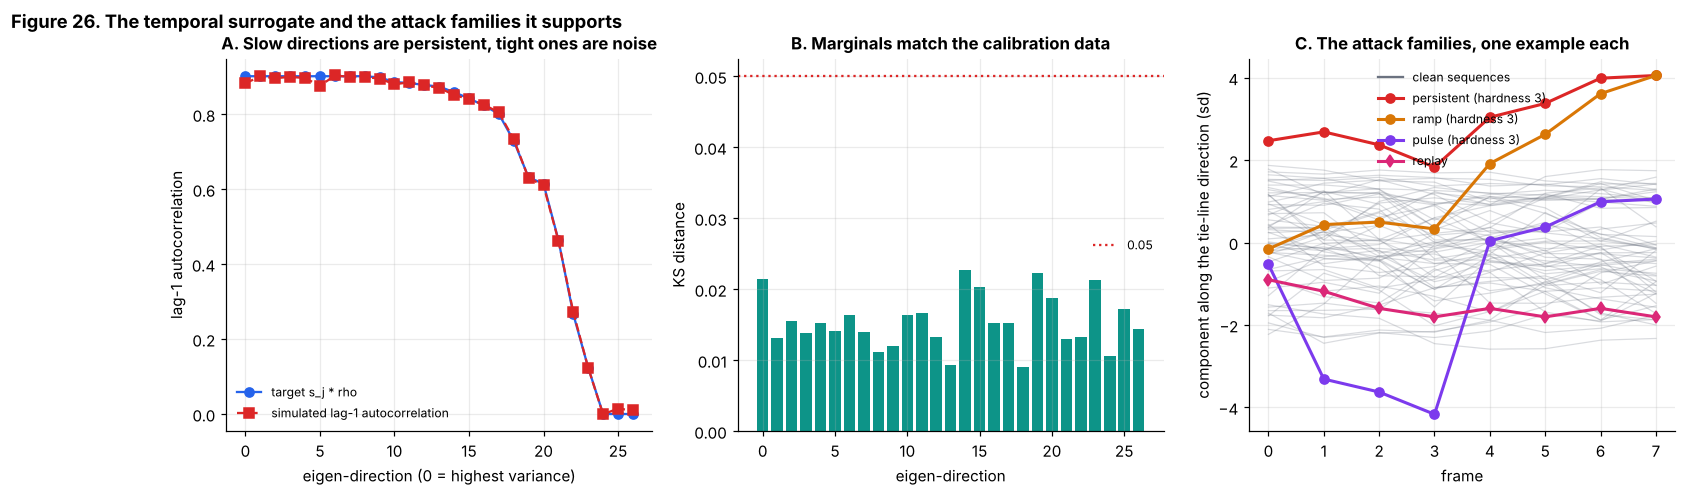

PosixPath('/tmp/w2/proj/figures/fig26_temporal_surrogate.png')

In [47]:
SHAPES = {
    "persistent": lambda T, rng: np.ones(T),
    "ramp":       lambda T, rng: (np.arange(T) + 1) / T,
    "pulse":      lambda T, rng: (lambda w, t0: ((np.arange(T) >= t0) & (np.arange(T) < t0 + w)).astype(float))(int(rng.integers(2, 4)), int(rng.integers(1, T - 4))),
}
DIRKINDS = ["lfc", "dense", "mimic_top", "noise_floor"]

def p_direction(tm, sim, rng, kind):
    ns = tm.ns
    if kind == "lfc":
        v = tm.sqlam * (tm.cal.eigvec.T @ sim.h_tie) * rng.choice([-1, 1])
    elif kind == "dense":
        v = rng.normal(size=ns)
    elif kind == "mimic_top":                       # shift along the slow, high-variance (load-driven) directions
        v = np.zeros(ns); v[int(rng.integers(0, 3))] = rng.choice([-1, 1])
    else:                                           # noise_floor: shift along the tightest, noise-limited directions
        v = np.zeros(ns); v[ns - 1 - int(rng.integers(0, 3))] = rng.choice([-1, 1])
    return v / np.linalg.norm(v)

def gen_seq_block(tm, sim, rng, n, family, dirkind=None, lam=0.0, delta_range=(0.5, 4.0), fixed_delta=None):
    T, ns = tm.T, tm.ns; p = tm.gen_p(n, rng); J = tm.gen_J(n, rng)
    out = dict(p=p, J=J, label=np.zeros(n, int), family=np.array(["clean"] * n, dtype="U16"), dirkind=np.array([""] * n, dtype="U16"),
               delta=np.full(n, np.nan), M=np.zeros((n, T, ns)), tau=np.zeros(n, int))
    if family == "clean": return out
    out["label"][:] = 1; out["family"][:] = family
    if family == "replay":
        for i in range(n):
            tau = int(rng.integers(2, 5)); t0 = int(rng.integers(max(tau, T // 2), T - 1))
            for t in range(t0, T): p[i, t] = p[i, t - tau]
            out["tau"][i] = tau
        out["p"] = p; return out
    dk = np.array([dirkind or rng.choice(DIRKINDS) for _ in range(n)], dtype="U16"); out["dirkind"] = dk
    d = np.full(n, fixed_delta) if fixed_delta else np.exp(rng.uniform(np.log(delta_range[0]), np.log(delta_range[1]), size=n))
    M = np.zeros((n, T, ns))
    for i in range(n): M[i] = SHAPES[family](T, rng)[:, None] * (d[i] * p_direction(tm, sim, rng, dk[i]))[None]
    out["p"] = p + M; out["M"] = M; out["delta"] = d
    if lam > 0: out["J"] = tm.gen_J(n, rng, lam)
    return out

def cat(*bs): return {k: np.concatenate([b[k] for b in bs]) for k in bs[0]}

# (A), (B): fidelity of the surrogate
name = STUDY_GRIDS[0]; tm = TM[name]; rng = rng_for("surrogate_check"); big = tm.gen_p(3000, rng)
ks = np.array([st.ks_2samp(big[:, -1, j], tm.P[:, j]).statistic for j in range(tm.ns)])
ac1 = np.array([np.corrcoef(big[:, 1:, j].ravel(), big[:, :-1, j].ravel())[0, 1] for j in range(tm.ns)])
print(f"{name}: max KS distance of a component's marginal to calibration = {ks.max():.3f} (median {np.median(ks):.3f})")
print(f"{name}: lag-1 autocorrelation range {ac1.min():.2f} to {ac1.max():.2f}; target s_j*rho range {(tm.s*tm.rho).min():.2f} to {(tm.s*tm.rho).max():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
ax = axes[0]; j_ = np.arange(tm.ns)
ax.plot(j_, tm.s * tm.rho, "o-", color=PAL["blue"], label="target s_j * rho"); ax.plot(j_, ac1, "s--", color=PAL["red"], label="simulated lag-1 autocorrelation")
ax.set_xlabel("eigen-direction (0 = highest variance)"); ax.set_ylabel("lag-1 autocorrelation"); ax.set_title("A. Slow directions are persistent, tight ones are noise"); ax.legend(fontsize=8)
ax = axes[1]; ax.bar(j_, ks, color=PAL["teal"]); ax.axhline(0.05, color=PAL["red"], ls=":", label="0.05"); ax.set_xlabel("eigen-direction"); ax.set_ylabel("KS distance"); ax.set_title("B. Marginals match the calibration data"); ax.legend(fontsize=8)
ax = axes[2]; rng = rng_for("traj"); sim_ = SIMS[name]
vhat = p_direction(tm, sim_, np.random.default_rng(0), "lfc"); proj = lambda p: p @ vhat
clean = tm.gen_p(60, rng)
for i in range(60): ax.plot(proj(clean[i]), color=PAL["grey"], alpha=0.25, lw=0.8)
ax.plot([], [], color=PAL["grey"], label="clean sequences")
for fam, col in [("persistent", PAL["red"]), ("ramp", PAL["amber"]), ("pulse", PAL["purple"])]:
    b = gen_seq_block(tm, sim_, np.random.default_rng(5), 1, fam, dirkind="lfc", fixed_delta=3.0); ax.plot(proj(b["p"][0]), "o-", color=col, lw=2, label=f"{fam} (hardness 3)")
b = gen_seq_block(tm, sim_, np.random.default_rng(9), 1, "replay"); ax.plot(proj(b["p"][0]), "d-", color=PAL["pink"], lw=2, label="replay")
ax.set_xlabel("frame"); ax.set_ylabel("component along the tie-line direction (sd)"); ax.set_title("C. The attack families, one example each"); ax.legend(fontsize=8)
fig.suptitle("Figure 26. The temporal surrogate and the attack families it supports", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig26_temporal_surrogate")

### 15.5 Temporal detectors and the temporal oracle

**Clean-only tests** (need no attack examples):

* `hot_last`: Hotelling on the last frame, the snapshot test used elsewhere in this notebook.
* `hot_mean`: Hotelling averaged over the window.
* `cusum`: CUSUM on the per-frame standardised Hotelling statistic (drift 0.5), reporting its maximum.
* `chi2_mean`: the window-mean $\chi^2$ residual statistic.

**Learned** (gradient-boosted trees, same random-search tuning as before): `gbdt_persist` is trained on persistent attacks only, which is what a snapshot-style benchmark would give it; `gbdt_mix` is trained on a mix of persistent, ramp and pulse attacks. Features are window summaries: per-frame Hotelling z-scores (last, mean, max, slope), group energies, one-step and first-to-last jump statistics, and the mean $\chi^2$ z-score. Training and test attacks share the family definitions but use fresh random draws.

**Oracle:** the matched filter of Section 15.3, scored per attack against the clean test sequences exactly as in Part 8.3. Replay has no oracle: individually its frames are genuine, so there is no shift to match.

In [48]:
def seq_features(tm, d):
    p = d["p"]; n, T, ns = p.shape; e = p ** 2; g = max(1, ns // 4)
    z = lambda s, k: (s - k) / np.sqrt(2 * k)
    T2 = z(e.sum(2), ns); top = z(e[..., :g].sum(2), g); bot = z(e[..., -g:].sum(2), g); mid = z(e[..., g:ns - g].sum(2), max(1, ns - 2 * g))
    tt = np.arange(T) - (T - 1) / 2; slope = (T2 * tt).sum(1) / (tt ** 2).sum()
    dp = np.diff(p, axis=1); jump = z((dp ** 2 / tm.dvar).sum(2), ns); span = z(((p[:, -1] - p[:, 0]) ** 2 / tm.dvar_span).sum(1), ns)
    zJ = (d["J"] - tm.cal.dof) / np.sqrt(2 * tm.cal.dof)
    ap = np.sort(np.abs(p.mean(1)), 1)[:, ::-1][:, :4]
    return np.column_stack([T2[:, -1], T2.mean(1), T2.max(1), slope, top.mean(1), top[:, -1], bot.mean(1), bot[:, -1], mid.mean(1), mid[:, -1],
                            jump.max(1), jump.mean(1), jump[:, -1], span, zJ.mean(1), zJ.max(1), ap])

class SeqGBDT(GBDT):
    def __init__(self, tm, name): self.tm, self.name = tm, name
    def feats(self, cal, d): return seq_features(self.tm, d)

def clean_only_scores(tm, d):
    p = d["p"]; e = (p ** 2).sum(2); ns = tm.ns; z = (e - ns) / np.sqrt(2 * ns)
    S = np.zeros(len(p)); best = np.zeros(len(p))
    for t in range(tm.T): S = np.maximum(0, S + z[:, t] - 0.5); best = np.maximum(best, S)
    return dict(hot_last=e[:, -1], hot_mean=e.mean(1), cusum=best, chi2_mean=d["J"].mean(1))

def seq_oracle(tm, d):
    """Per-attack AUROC of the known-trajectory matched filter against the clean sequences in d; also temporal hardness."""
    ia = np.where((d["label"] == 1) & (d["family"] != "replay"))[0]; ic = np.where(d["label"] == 0)[0]
    W = np.einsum("jts,isj->itj", tm.Rinv, d["M"][ia]); s_att = (W * d["p"][ia]).sum((1, 2))
    s_cl = W.reshape(len(ia), -1) @ d["p"][ic].reshape(len(ic), -1).T
    return ia, (s_att[:, None] > s_cl).mean(1), np.sqrt((W * d["M"][ia]).sum((1, 2)))

def seq_auc(score, d, family, lo=None, hi=None, dirkind=None):
    ia = np.where((d["family"] == family) & ((d["delta"] >= lo) & (d["delta"] < hi) if lo is not None else True) & ((d["dirkind"] == dirkind) if dirkind else True))[0]
    ic = np.where(d["label"] == 0)[0]
    if len(ia) < 8: return np.nan
    return roc_auc_score(np.r_[np.zeros(len(ic)), np.ones(len(ia))], np.r_[score[ic], score[ia]])

FAMS = ["persistent", "ramp", "pulse", "replay"]
SEQ = {}; SEQ_DETS = {}
for name in STUDY_GRIDS:
    sim, tm = SIMS[name], TM[name]; rng = rng_for("seqdata", *[ord(c) for c in name])
    def mk(n_each, rng_): return cat(gen_seq_block(tm, sim, rng_, 4 * n_each, "clean"), *[gen_seq_block(tm, sim, rng_, n_each, f) for f in FAMS])
    train_p = cat(gen_seq_block(tm, sim, rng, EXT_TRAIN_N // 2, "clean"), gen_seq_block(tm, sim, rng, EXT_TRAIN_N // 2, "persistent"))
    n3 = EXT_TRAIN_N // 6
    train_mix = cat(gen_seq_block(tm, sim, rng, EXT_TRAIN_N // 2, "clean"), *[gen_seq_block(tm, sim, rng, n3, f) for f in ("persistent", "ramp", "pulse")])
    test = mk(N_EXT, rng)
    dets = {}
    for nm, tr in (("gbdt_persist", train_p), ("gbdt_mix", train_mix)):
        dets[nm] = SeqGBDT(tm, nm).fit(tm.cal, tr, 0)
    scores = clean_only_scores(tm, test); scores.update({nm: dets[nm].score(tm.cal, test) for nm in dets})
    ia, orc, dT = seq_oracle(tm, test)
    SEQ[name] = dict(test=test, scores=scores, orc=dict(ia=ia, auc=orc, dT=dT)); SEQ_DETS[name] = dets
    print(f"{name}: temporal data built; {len(test['label'])} test windows; tuned val AUROC "
          f"{ {k: round(v.val_auc, 3) for k, v in dets.items()} }", flush=True)

ieee14: temporal data built; 8000 test windows; tuned val AUROC {'gbdt_persist': 0.676, 'gbdt_mix': 0.604}


syn28: temporal data built; 8000 test windows; tuned val AUROC {'gbdt_persist': 0.6, 'gbdt_mix': 0.549}


### 15.6 Detectors against the oracle, per family (Figure 27)

AUROC at peak hardness 1 to 2, the region where the oracle is neither trivial nor hopeless. Replay has no hardness, so its AUROC is over all replay attacks.

  grid     family  hot_last  hot_mean  cusum  chi2_mean  gbdt_persist  gbdt_mix  oracle  formula_dT
ieee14 persistent     0.576     0.600  0.591      0.517         0.633     0.562   0.927       0.919
ieee14       ramp     0.580     0.529  0.529      0.504         0.553     0.536   0.891       0.888
ieee14      pulse     0.515     0.555  0.553      0.499         0.492     0.554   0.976       0.978
ieee14     replay     0.504     0.489  0.425      0.507         0.480     0.493     NaN         NaN
 syn28 persistent     0.527     0.535  0.545      0.469         0.596     0.550   0.918       0.918
 syn28       ramp     0.546     0.517  0.504      0.506         0.526     0.549   0.902       0.897
 syn28      pulse     0.496     0.511  0.514      0.501         0.495     0.531   0.978       0.984
 syn28     replay     0.506     0.491  0.439      0.498         0.537     0.614     NaN         NaN


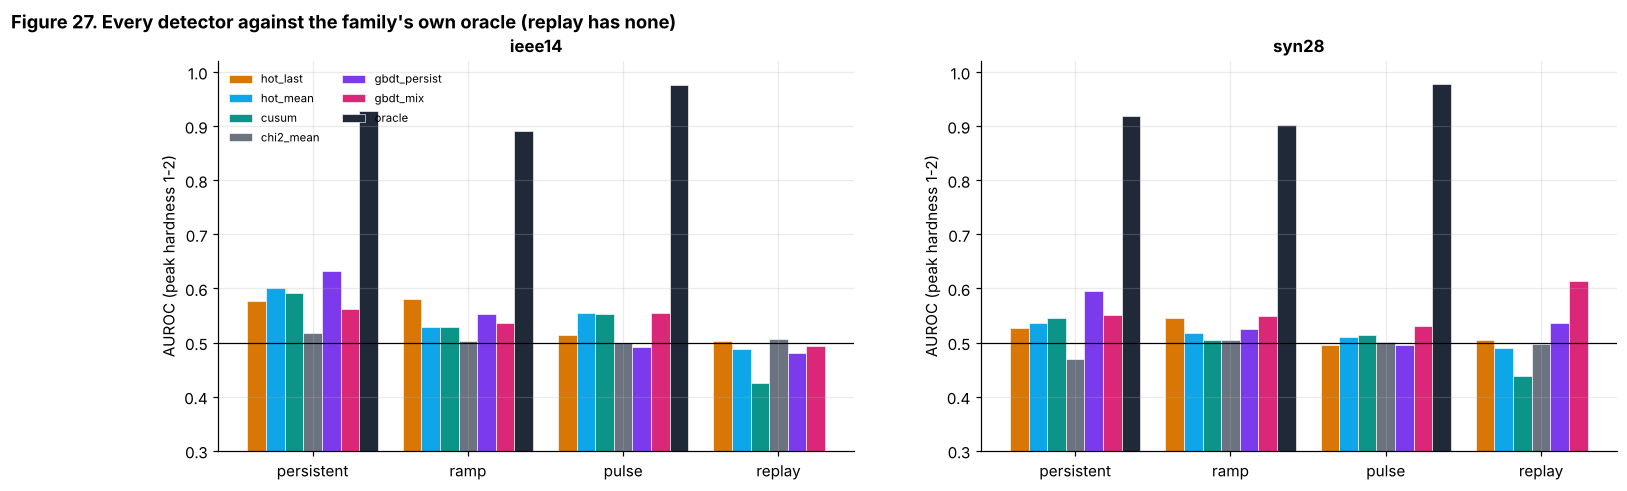

PosixPath('/tmp/w2/proj/figures/fig27_families.png')

In [49]:
DET_ORDER = ["hot_last", "hot_mean", "cusum", "chi2_mean", "gbdt_persist", "gbdt_mix"]
SEQ_COL = dict(hot_last=PAL["amber"], hot_mean=PAL["sky"], cusum=PAL["teal"], chi2_mean=PAL["grey"], gbdt_persist=PAL["purple"], gbdt_mix=PAL["pink"], oracle=PAL["ink"])
rows = []
for name in STUDY_GRIDS:
    S = SEQ[name]; d, sc, o = S["test"], S["scores"], S["orc"]
    for fam in FAMS:
        lo, hi = (1.0, 2.0) if fam != "replay" else (None, None)
        r = dict(grid=name, family=fam)
        for dn in DET_ORDER: r[dn] = seq_auc(sc[dn], d, fam, lo, hi)
        if fam != "replay":
            m = (d["family"][o["ia"]] == fam) & (d["delta"][o["ia"]] >= 1.0) & (d["delta"][o["ia"]] < 2.0)
            r["oracle"] = float(o["auc"][m].mean()); r["formula_dT"] = float(st.norm.cdf(o["dT"][m] / np.sqrt(2)).mean())
        else: r["oracle"] = np.nan; r["formula_dT"] = np.nan
        rows.append(r)
FAM_TAB = pd.DataFrame(rows); print(FAM_TAB.round(3).to_string(index=False))

fig, axes = plt.subplots(1, len(STUDY_GRIDS), figsize=(8.2 * len(STUDY_GRIDS), 4.6))
for ax, name in zip(np.atleast_1d(axes), STUDY_GRIDS):
    v = FAM_TAB[FAM_TAB.grid == name].set_index("family").loc[FAMS]; w_ = 0.12; cols = DET_ORDER + ["oracle"]
    for k, dn in enumerate(cols): ax.bar(np.arange(len(FAMS)) + (k - 3) * w_, v[dn], w_, color=SEQ_COL[dn], label=dn, edgecolor="white", lw=0.4)
    ax.axhline(0.5, color="k", lw=0.8); ax.set_xticks(range(len(FAMS))); ax.set_xticklabels(FAMS); ax.set_ylim(0.3, 1.02); ax.set_ylabel("AUROC (peak hardness 1-2)"); ax.set_title(name)
np.atleast_1d(axes)[0].legend(fontsize=7.5, ncol=2)
fig.suptitle("Figure 27. Every detector against the family's own oracle (replay has none)", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig27_families")

### 15.7 Imperfect stealth: when hardness stops being enough (Figure 28)

A perfectly stealthy attack leaves the residual untouched. Real attackers have an imperfect model of the grid, so some of the attack leaks into the residual. Here the leak is explicit: each frame's $\chi^2$ statistic is drawn non-central with non-centrality $\lambda_r\in\{0,1,4,9,16\}$, while the *state* shift is held at hardness 1.5 along the tie-line direction. The state-only oracle ignores the residual, so once $\lambda_r>0$ it is **no longer an upper bound**: a detector that reads the residual can, and should, exceed it. That is the point of the figure, and it tells you the oracle framing holds only up to the stealth boundary.

Detectors are the ones from 15.5, trained on perfectly stealthy attacks only (the usual benchmark protocol), plus `combo`, an untrained sum of the window-mean Hotelling and $\chi^2$ z-scores.

  grid  lam  state_oracle  hot_mean  chi2_mean  combo  gbdt_persist
ieee14    0         0.894     0.617      0.498  0.585         0.617
ieee14    1         0.881     0.606      0.634  0.666         0.605
ieee14    4         0.893     0.585      0.859  0.820         0.606
ieee14    9         0.882     0.605      0.984  0.958         0.638
ieee14   16         0.886     0.605      1.000  0.997         0.649
 syn28    0         0.897     0.578      0.480  0.542         0.593
 syn28    1         0.899     0.570      0.560  0.594         0.590
 syn28    4         0.904     0.567      0.743  0.722         0.581
 syn28    9         0.900     0.558      0.935  0.885         0.561
 syn28   16         0.911     0.579      0.994  0.979         0.485


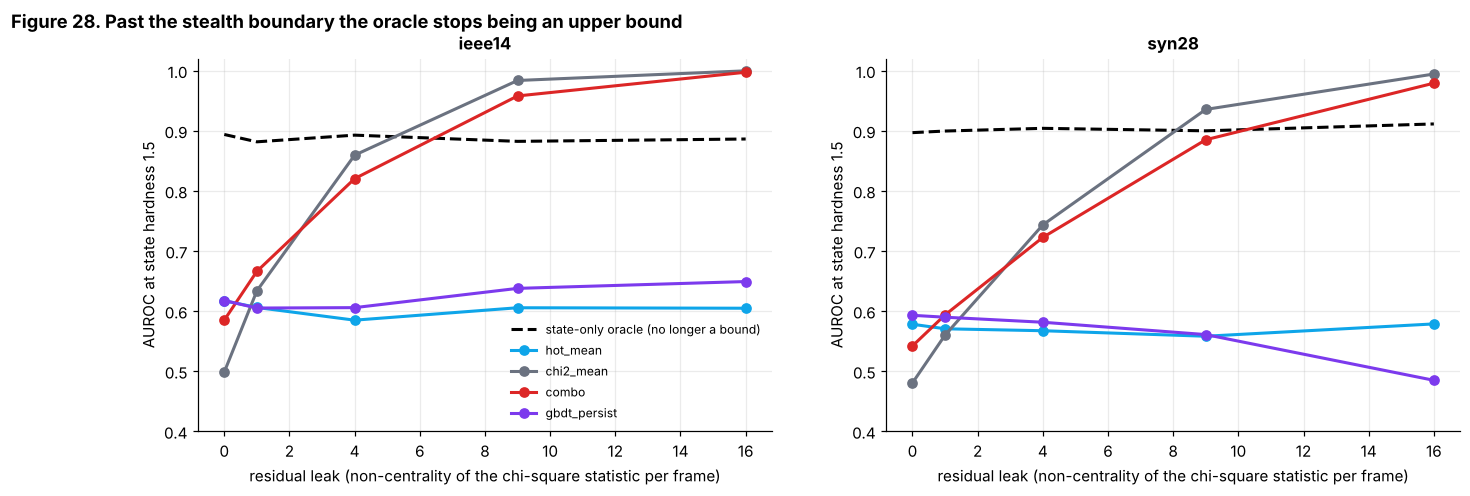

PosixPath('/tmp/w2/proj/figures/fig28_leaky_stealth.png')

In [50]:
LAMS = [0, 1, 4, 9, 16]
LEAK = []
for name in STUDY_GRIDS:
    sim, tm, S = SIMS[name], TM[name], SEQ[name]
    for lam in LAMS:
        rng = rng_for("leak", int(lam), *[ord(c) for c in name])
        d = cat(gen_seq_block(tm, sim, rng, 2 * N_EXT, "clean"), gen_seq_block(tm, sim, rng, N_EXT, "persistent", dirkind="lfc", lam=lam, fixed_delta=1.5))
        sc = clean_only_scores(tm, d); sc["gbdt_persist"] = SEQ_DETS[name]["gbdt_persist"].score(tm.cal, d)
        ia_ = np.where(d["label"] == 1)[0]; ic_ = np.where(d["label"] == 0)[0]; y = np.r_[np.zeros(len(ic_)), np.ones(len(ia_))]
        zT = lambda s: (s - s[ic_].mean()) / s[ic_].std()
        sc["combo"] = zT(sc["hot_mean"]) + zT(sc["chi2_mean"])
        _, orc, _ = seq_oracle(tm, d)
        r = dict(grid=name, lam=lam, state_oracle=float(orc.mean()))
        for dn in ["hot_mean", "chi2_mean", "combo", "gbdt_persist"]:
            if sc.get(dn) is not None: r[dn] = roc_auc_score(y, np.r_[sc[dn][ic_], sc[dn][ia_]])
        LEAK.append(r)
LEAK = pd.DataFrame(LEAK); print(LEAK.round(3).to_string(index=False))

fig, axes = plt.subplots(1, len(STUDY_GRIDS), figsize=(7.4 * len(STUDY_GRIDS), 4.4))
for ax, name in zip(np.atleast_1d(axes), STUDY_GRIDS):
    v = LEAK[LEAK.grid == name]
    ax.plot(v.lam, v.state_oracle, "k--", lw=2, label="state-only oracle (no longer a bound)")
    for dn, col in [("hot_mean", PAL["sky"]), ("chi2_mean", PAL["grey"]), ("combo", PAL["red"]), ("gbdt_persist", PAL["purple"])]:
        if dn in v: ax.plot(v.lam, v[dn], "o-", color=col, lw=2, label=dn)
    ax.set_xlabel("residual leak (non-centrality of the chi-square statistic per frame)"); ax.set_ylabel("AUROC at state hardness 1.5"); ax.set_title(name); ax.set_ylim(0.4, 1.02)
np.atleast_1d(axes)[0].legend(fontsize=8)
fig.suptitle("Figure 28. Past the stealth boundary the oracle stops being an upper bound", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig28_leaky_stealth")

### 15.8 Direction at equal temporal hardness, and a family-aware Bayes reference (H18; Figure 29, left)

**Equal hardness has to be equal *temporal* hardness.** A persistent shift along a fast, noise-limited direction is averaged down by the window and is far easier to see than the same peak hardness along a slow load direction, because slow components are correlated across frames. The oracle's own $\delta_T$ accounts for this, so comparisons across directions here select attacks with $\delta_T\in[1.5,3)$. At equal $\delta_T$ the oracle's AUROC is the same by construction; the question is whether real detectors are indifferent to direction.

**A reference that does not know the direction.** The known-shift oracle is generous: it is told which of $n_s$ directions was attacked. The detector never is. For a *family* with a known prior (here: one of three coordinate directions, either sign, hardness log-uniform on $[0.5,4]$) the Bayes-optimal score is the prior-averaged likelihood ratio,

$$\log\mathrm{LR}(y)=\log\sum_{j\in S}\sum_{\pm}\sum_{\delta}\exp\!\Big(\pm\delta\,\mathbf 1^\top R_j^{-1}y_j-\tfrac12\delta^2\,\mathbf 1^\top R_j^{-1}\mathbf 1\Big),$$

which is exact under the surrogate and needs no training. Its AUROC is a ceiling for **any detector that knows the family but not the direction**. The gap between the known-shift oracle and this ceiling is the price of not knowing the direction, which no amount of data can recover; the gap between this ceiling and a learned detector is the part that learning or better features could still close. That split of the oracle gap into an unavoidable part and a closable part is, as far as my literature search found, not something earlier benchmarks report. I have not found it done, but the search was shallow, so treat it as a candidate contribution to check, not an established one.

In [51]:
from scipy.special import logsumexp
DELTA_GRID = np.exp(np.linspace(np.log(0.5), np.log(4.0), 12))

def bayes_family_score(tm, p, kind):
    ns, T = tm.ns, tm.T; S = [0, 1, 2] if kind == "mimic_top" else [ns - 1, ns - 2, ns - 3]; one = np.ones(T); terms = []
    for j in S:
        a = p[:, :, j] @ (tm.Rinv[j] @ one); q = float(one @ tm.Rinv[j] @ one)
        for dlt in DELTA_GRID:
            for sg in (1, -1): terms.append(sg * dlt * a - 0.5 * dlt ** 2 * q)
    return logsumexp(np.stack(terms, 0), axis=0)

def auc_idx(score, d, ia_idx):
    ic = np.where(d["label"] == 0)[0]
    if len(ia_idx) < 8: return np.nan
    return roc_auc_score(np.r_[np.zeros(len(ic)), np.ones(len(ia_idx))], np.r_[score[ic], score[ia_idx]])

DTLO, DTHI = 1.5, 3.0
DIRTAB = []
for name in STUDY_GRIDS:
    S = SEQ[name]; d, sc, o, tm = S["test"], S["scores"], S["orc"], TM[name]
    for dk in DIRKINDS:
        sel = (d["family"][o["ia"]] == "persistent") & (d["dirkind"][o["ia"]] == dk) & (o["dT"] >= DTLO) & (o["dT"] < DTHI)
        idx = o["ia"][sel]; r = dict(grid=name, dirkind=dk, n=int(sel.sum()))
        for dn in ["hot_last", "hot_mean", "gbdt_persist", "gbdt_mix"]: r[dn] = auc_idx(sc[dn], d, idx)
        r["oracle"] = float(o["auc"][sel].mean()) if sel.sum() else np.nan
        r["bayes_family"] = auc_idx(bayes_family_score(tm, d["p"], dk), d, idx) if dk in ("mimic_top", "noise_floor") else np.nan
        DIRTAB.append(r)
DIRTAB = pd.DataFrame(DIRTAB); print(DIRTAB.round(3).to_string(index=False))
H18 = {}
for name in STUDY_GRIDS:
    v = DIRTAB[DIRTAB.grid == name]
    H18[name] = dict(oracle_spread=float(v.oracle.max() - v.oracle.min()), gbdt_mix_spread=float(v.gbdt_mix.max() - v.gbdt_mix.min()),
                     hot_last_spread=float(v.hot_last.max() - v.hot_last.min()))
print("H18 readout:", H18)
GAP = DIRTAB.dropna(subset=["bayes_family"]).assign(unavoidable=lambda x: x.oracle - x.bayes_family, closable=lambda x: x.bayes_family - x[["gbdt_persist", "gbdt_mix", "hot_mean"]].max(axis=1))
print("\noracle gap split (coordinate-direction families):"); print(GAP[["grid", "dirkind", "oracle", "bayes_family", "unavoidable", "closable"]].round(3).to_string(index=False))

  grid     dirkind   n  hot_last  hot_mean  gbdt_persist  gbdt_mix  oracle  bayes_family
ieee14         lfc  87     0.594     0.634         0.687     0.599   0.927           NaN
ieee14       dense  90     0.566     0.598         0.602     0.523   0.945           NaN
ieee14   mimic_top  80     0.598     0.597         0.568     0.565   0.921         0.796
ieee14 noise_floor  86     0.532     0.557         0.572     0.485   0.905         0.760
 syn28         lfc  89     0.566     0.597         0.629     0.587   0.925           NaN
 syn28       dense 101     0.536     0.513         0.574     0.455   0.929           NaN
 syn28   mimic_top  85     0.591     0.651         0.692     0.597   0.936         0.829
 syn28 noise_floor  73     0.512     0.539         0.590     0.561   0.955         0.865
H18 readout: {'ieee14': {'oracle_spread': 0.03980710594315251, 'gbdt_mix_spread': 0.11395410652232019, 'hot_last_spread': 0.06612361918604659}, 'syn28': {'oracle_spread': 0.029911536093581437, 'gbdt_

### 15.9 Limited meter access: attacks that touch few meters (Figure 29, middle)

The attacker controls the meters around one bus and the attack is built on the true measurement Jacobian so it stays perfectly stealthy. The *radius* (0 = one bus, up to 3 hops) controls how many meters it touches. Hardness is fixed at 1.5, so the oracle says detectability should not change with radius; any change in a detector's AUROC is a property of the detector, not of the attack's strength. Here the attacks use the real generator (AC power flow, WLS estimator), not the surrogate.

In [52]:
def hop_set(sim, b, r):
    G = sim.g.graph(); return list(nx.single_source_shortest_path_length(G, int(b), cutoff=r).keys())

def local_direction(sim, cal, rng, radius):
    n, M = sim.g.n, sim.M; B = hop_set(sim, rng.integers(0, n), radius); idx = []
    for b_ in B:
        if b_ != M.ref: idx.append(int(np.where(M.nonref == b_)[0][0]))
        idx.append(n - 1 + int(b_))
    u = np.zeros(cal.ns); u[idx] = rng.normal(size=len(idx)); return u

def gen_custom_block(sim, cal, rng, n, make_u, delta, base="clean", model="ac"):
    rec = []
    while len(rec) < n:
        s = new_sample(sim, rng, base)
        if s is None: continue
        z, V, _ = s; u = make_u(rng); c = u * delta / cal.delta(u)[0]
        za = apply_attack(sim, cal, rng, z, c, model); xh0, J0, _ = sim.estimate(z); xh1, J1, r1 = sim.estimate(za)
        a = sim.H_nom @ c
        rec.append(dict(x=xh1, J=J1, rmax=float(np.max(np.abs(r1) / sim.mt["sigma"])), shift=xh1 - xh0, nmet=int((np.abs(a) > 1e-6 * np.abs(a).max()).sum())))
    sh = np.array([r["shift"] for r in rec])
    return dict(x=np.array([r["x"] for r in rec]), J=np.array([r["J"] for r in rec]), rmax=np.array([r["rmax"] for r in rec]), label=np.ones(n, int),
                kind=np.array(["attack"] * n), delta=cal.delta(sh), shift=sh, flow=sh @ sim.h_tie, model=np.array([model] * n),
                dirkind=np.array(["custom"] * n), nmet=np.array([r["nmet"] for r in rec]))

def as_clean(d, mask):
    out = {k: v[mask] for k, v in d.items()}; out["nmet"] = np.zeros(mask.sum(), int); return out

N_LOC = 250 if BUDGET == "full" else 80
RADII = [0, 1, 2, 3]
LOC = []; EXT_DETS = {}
for name in STUDY_GRIDS:
    sim, cal, te = SIMS[name], CAL[name], DS[name]["test"]; pool = concat_blocks(DS[name]["train"], DS[name]["train_extra"])
    sub = subsample_balanced(pool, EXT_TRAIN_N, np.random.default_rng(777))
    EXT_DETS[name] = dict(gbdt=GBDT().fit(cal, sub, 0), gbdt_sum=GBDTSum().fit(cal, sub, 0), hotelling=Hotelling(), chi2=Chi2())
    nat = as_clean(te, (te["kind"] == "natural") & (te["label"] == 0))
    for r in RADII:
        rng = rng_for("local", r, *[ord(c) for c in name])
        att = gen_custom_block(sim, cal, rng, N_LOC, lambda g_: local_direction(sim, cal, g_, r), 1.5)
        d = concat_blocks(nat, att)
        orc, _, _ = oracle_scores(cal, d)
        row = dict(grid=name, radius=r, meters=float(att["nmet"].mean()), oracle=float(orc.mean()))
        for dn, det in EXT_DETS[name].items(): row[dn] = overall_auc(det.score(cal, d), d)
        LOC.append(row)
LOC = pd.DataFrame(LOC); print(LOC.round(3).to_string(index=False))

  grid  radius  meters  oracle  gbdt  gbdt_sum  hotelling  chi2
ieee14       0  10.332   0.852 0.492     0.534      0.563 0.525
ieee14       1  25.588   0.858 0.511     0.526      0.520 0.515
ieee14       2  43.580   0.856 0.569     0.587      0.572 0.522
ieee14       3  54.272   0.823 0.507     0.541      0.549 0.539
 syn28       0  10.328   0.841 0.513     0.555      0.543 0.504
 syn28       1  28.824   0.837 0.511     0.569      0.526 0.505
 syn28       2  61.892   0.832 0.578     0.564      0.550 0.506
 syn28       3  87.696   0.823 0.547     0.541      0.496 0.498


### 15.10 Masking: an attack hidden inside an outage (H16; Figure 29, right)

The window is generated with a line outage (the true topology differs from the estimator's model, which already raises $\chi^2$ and shifts the state), and a perfectly stealthy shift is added on top. The detector must say "attack" even though the window already looks abnormal, and it must not say "attack" on outages alone. Negatives are therefore **outage windows**, and the oracle is scored against them. Two copies of the learned detectors are compared: trained on the standard pool (which contains outages labelled clean but no masked attacks) and retrained with masked attacks added.

In [53]:
def outage_negatives(sim, cal, rng, n):
    rec = []
    while len(rec) < n:
        s_ = new_sample(sim, rng, "outage")
        if s_ is None: continue
        xh, j, r = sim.estimate(s_[0]); rec.append((xh, j, float(np.max(np.abs(r) / sim.mt["sigma"]))))
    return dict(x=np.array([r[0] for r in rec]), J=np.array([r[1] for r in rec]), rmax=np.array([r[2] for r in rec]), label=np.zeros(n, int),
                kind=np.array(["outage"] * n), delta=np.full(n, np.nan), shift=np.zeros((n, cal.ns)), flow=np.zeros(n), model=np.array([""] * n),
                dirkind=np.array([""] * n), nmet=np.zeros(n, int))

N_MASK_TR = 300 if BUDGET == "full" else 100
MASK = []
for name in STUDY_GRIDS:
    sim, cal, te = SIMS[name], CAL[name], DS[name]["test"]
    rng = rng_for("mask", *[ord(c) for c in name]); dirs = lambda g_: sim_dir(g_)
    def sim_dir(g_):
        k = g_.choice(["sparse", "dense", "lfc"]); return make_direction(sim, cal, g_, k)
    out_neg = outage_negatives(sim, cal, rng, 3 * N_LOC // 2); nat = as_clean(te, (te["kind"] == "natural") & (te["label"] == 0))
    m_te = gen_custom_block(sim, cal, rng, N_LOC, dirs, 1.5, base="outage"); u_te = gen_custom_block(sim, cal, rng, N_LOC, dirs, 1.5, base="clean")
    m_tr = gen_custom_block(sim, cal, rng, N_MASK_TR, dirs, 1.5, base="outage")
    pool = concat_blocks(DS[name]["train"], DS[name]["train_extra"]); sub = subsample_balanced(pool, EXT_TRAIN_N, np.random.default_rng(777))
    tr_m = concat_blocks(sub, {k: (m_tr[k] if k in m_tr else np.zeros(N_MASK_TR)) for k in sub})
    d_masked = concat_blocks(out_neg, m_te); d_plain = concat_blocks(nat, u_te)
    variants = {"gbdt (standard)": EXT_DETS[name]["gbdt"], "gbdt (+masked)": GBDT().fit(cal, tr_m, 0), "gbdt_sum (standard)": EXT_DETS[name]["gbdt_sum"],
                "gbdt_sum (+masked)": GBDTSum().fit(cal, tr_m, 0), "hotelling": Hotelling(), "chi2": Chi2()}
    r = dict(grid=name, oracle_masked=float(oracle_scores(cal, d_masked)[0].mean()), oracle_plain=float(oracle_scores(cal, d_plain)[0].mean()), n_outage_neg=int(len(out_neg["label"])))
    for vn, det in variants.items(): r[vn + " | masked"] = overall_auc(det.score(cal, d_masked), d_masked); r[vn + " | plain"] = overall_auc(det.score(cal, d_plain), d_plain)
    MASK.append(r)
MASK = pd.DataFrame(MASK).set_index("grid"); print(MASK.T.round(3).to_string())

grid                           ieee14    syn28
oracle_masked                   0.637    0.584
oracle_plain                    0.845    0.858
n_outage_neg                  375.000  375.000
gbdt (standard) | masked        0.541    0.554
gbdt (standard) | plain         0.554    0.577
gbdt (+masked) | masked         0.501    0.517
gbdt (+masked) | plain          0.527    0.580
gbdt_sum (standard) | masked    0.530    0.536
gbdt_sum (standard) | plain     0.551    0.534
gbdt_sum (+masked) | masked     0.472    0.507
gbdt_sum (+masked) | plain      0.577    0.522
hotelling | masked              0.510    0.545
hotelling | plain               0.551    0.527
chi2 | masked                   0.515    0.521
chi2 | plain                    0.507    0.513


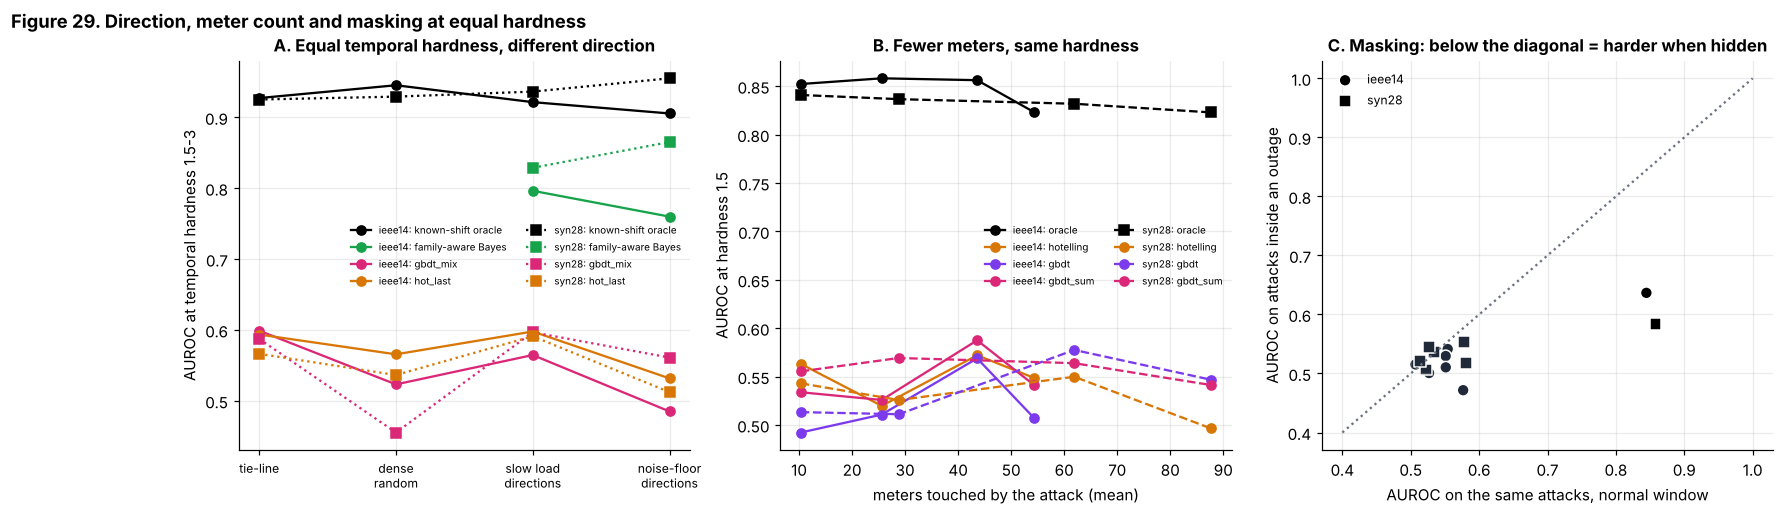

PosixPath('/tmp/w2/proj/figures/fig29_direction_locality_masking.png')

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
ax = axes[0]
for k, name in enumerate(STUDY_GRIDS):
    v = DIRTAB[DIRTAB.grid == name].set_index("dirkind").loc[DIRKINDS]; mk_ = "os"[k]; ls_ = ["-", ":"][k]
    ax.plot(range(4), v.oracle, "k" + ls_, marker=mk_, label=f"{name}: known-shift oracle"); ax.plot(range(4), v.bayes_family, color=PAL["green"], ls=ls_, marker=mk_, label=f"{name}: family-aware Bayes")
    ax.plot(range(4), v.gbdt_mix, color=PAL["pink"], ls=ls_, marker=mk_, label=f"{name}: gbdt_mix"); ax.plot(range(4), v.hot_last, color=PAL["amber"], ls=ls_, marker=mk_, label=f"{name}: hot_last")
ax.set_xticks(range(4)); ax.set_xticklabels(["tie-line", "dense\nrandom", "slow load\ndirections", "noise-floor\ndirections"], fontsize=8); ax.set_ylabel("AUROC at temporal hardness 1.5-3")
ax.set_title("A. Equal temporal hardness, different direction"); ax.legend(fontsize=6.5, ncol=2)
ax = axes[1]
for name, ls in zip(STUDY_GRIDS, ["-", "--"]):
    v = LOC[LOC.grid == name]
    ax.plot(v.meters, v.oracle, "k" + ("o" if ls == "-" else "s") + ls, label=f"{name}: oracle")
    for dn, col in [("hotelling", PAL["amber"]), ("gbdt", PAL["purple"]), ("gbdt_sum", PAL["pink"])]: ax.plot(v.meters, v[dn], "o" + ls, color=col, label=f"{name}: {dn}")
ax.set_xlabel("meters touched by the attack (mean)"); ax.set_ylabel("AUROC at hardness 1.5"); ax.set_title("B. Fewer meters, same hardness"); ax.legend(fontsize=6.5, ncol=2)
ax = axes[2]; names_ = ["oracle", "gbdt (standard)", "gbdt (+masked)", "gbdt_sum (standard)", "gbdt_sum (+masked)", "hotelling", "chi2"]
for k, name in enumerate(STUDY_GRIDS):
    vals_m = [MASK.loc[name, "oracle_masked"]] + [MASK.loc[name, n_ + " | masked"] for n_ in names_[1:]]
    vals_p = [MASK.loc[name, "oracle_plain"]] + [MASK.loc[name, n_ + " | plain"] for n_ in names_[1:]]
    ax.scatter(vals_p, vals_m, s=60, marker="os"[k], c=[SEQ_COL.get(n_.split(" ")[0], PAL["ink"]) if n_ != "oracle" else "k" for n_ in names_], edgecolor="white", label=name)
ax.plot([0.4, 1], [0.4, 1], color=PAL["grey"], ls=":"); ax.set_xlabel("AUROC on the same attacks, normal window"); ax.set_ylabel("AUROC on attacks inside an outage"); ax.set_title("C. Masking: below the diagonal = harder when hidden"); ax.legend(fontsize=8)
fig.suptitle("Figure 29. Direction, meter count and masking at equal hardness", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig29_direction_locality_masking")

### 15.11 Do rankings survive a change of attack family? (H17; Figure 30)

For each detector, the AUROC in each family (Figure 27's table). If one detector dominated every family, its rank would be the same everywhere and a single-family benchmark would be enough. The Spearman correlation of detector orderings between each pair of families measures how far that is from true. A **reliability guard** is added: the same correlation between two random halves of the *same* family's test windows. If that is low, the detectors are statistically indistinguishable in that family and any cross-family difference is noise, so H17 cannot be called supported.

split-half reliability of detector rankings inside a family (Spearman): 0.69
mean pairwise Spearman between families: {'ieee14': -0.12, 'syn28': 0.26} -> overall 0.07
This is only informative if the within-family ranking is reproducible (reliability >= 0.8); otherwise the detectors are statistically indistinguishable and the cross-family number is noise.


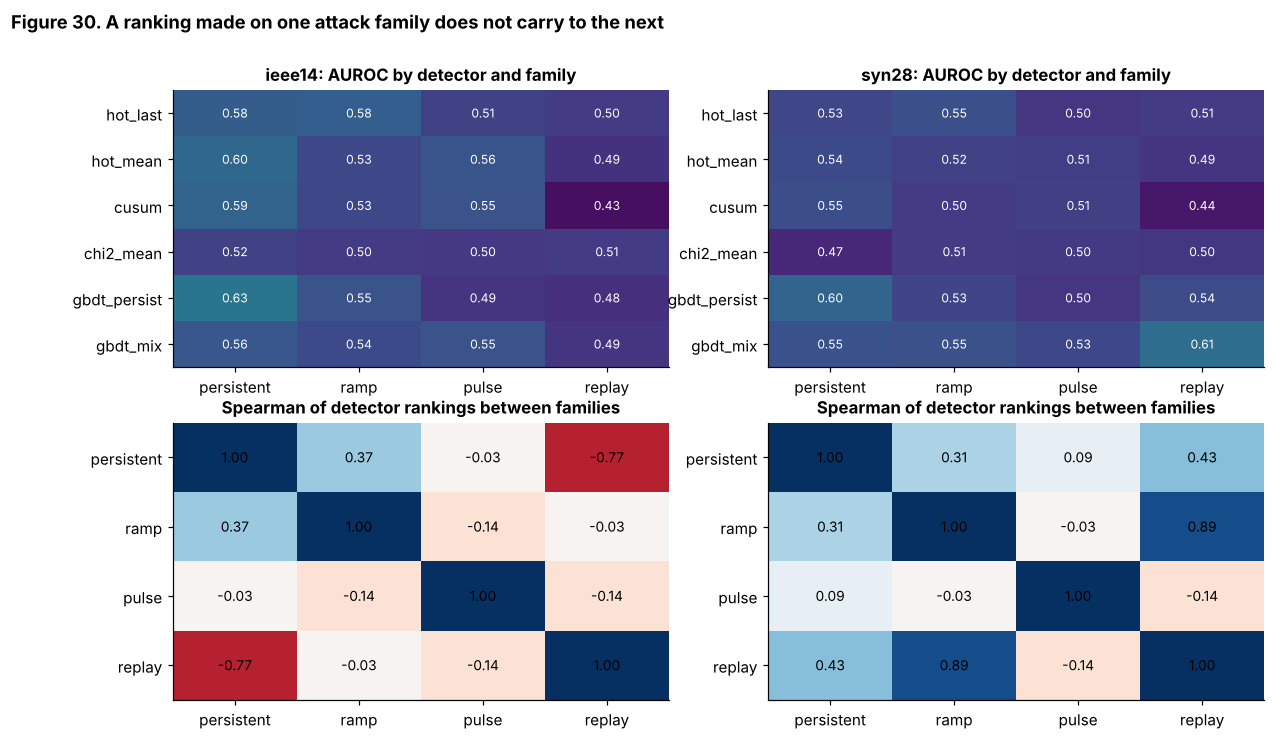

PosixPath('/tmp/w2/proj/figures/fig30_rank_transfer.png')

In [55]:
from scipy.stats import spearmanr
RANKS = {}
for name in STUDY_GRIDS:
    v = FAM_TAB[FAM_TAB.grid == name].set_index("family").loc[FAMS, DET_ORDER]
    C = np.array([[spearmanr(v.loc[a], v.loc[b])[0] for b in FAMS] for a in FAMS]); RANKS[name] = (v, C)
pair = [C[np.triu_indices(4, 1)].mean() for _, C in RANKS.values()]; H17_val = float(np.nanmean(pair))

# Reliability guard: rank correlations between families mean nothing if the detectors' ordering is not reproducible within one family.
def fam_auc_half(name, parity):
    S = SEQ[name]; d = S["test"]; keep = np.where(np.arange(len(d["label"])) % 2 == parity)[0]; dh = {k: v[keep] for k, v in d.items()}; sch = {k: v[keep] for k, v in S["scores"].items()}
    return pd.DataFrame([{dn: seq_auc(sch[dn], dh, f, *(1.0, 2.0) if f != "replay" else (None, None)) for dn in DET_ORDER} for f in FAMS], index=FAMS)
rel = []
for name in STUDY_GRIDS:
    h0, h1 = fam_auc_half(name, 0), fam_auc_half(name, 1)
    rel += [spearmanr(h0.loc[f], h1.loc[f])[0] for f in FAMS]
H17_rel = float(np.nanmean(rel)); print(f"split-half reliability of detector rankings inside a family (Spearman): {H17_rel:.2f}")
print("mean pairwise Spearman between families:", {n: round(float(p), 2) for n, p in zip(STUDY_GRIDS, pair)}, "-> overall", round(H17_val, 2))
print("This is only informative if the within-family ranking is reproducible (reliability >= 0.8); otherwise the detectors are statistically indistinguishable and the cross-family number is noise.")
fig, axes = plt.subplots(2, len(STUDY_GRIDS), figsize=(6.4 * len(STUDY_GRIDS), 7.2))
for j, name in enumerate(STUDY_GRIDS):
    v, C = RANKS[name]; ax = axes[0, j]; im = ax.imshow(v.values.T, vmin=0.4, vmax=1.0, cmap="viridis", aspect="auto")
    ax.set_xticks(range(4)); ax.set_xticklabels(FAMS); ax.set_yticks(range(len(DET_ORDER))); ax.set_yticklabels(DET_ORDER); ax.grid(False)
    for a in range(4):
        for b in range(len(DET_ORDER)): ax.text(a, b, f"{v.values[a, b]:.2f}", ha="center", va="center", color="w" if v.values[a, b] < 0.75 else "k", fontsize=8)
    ax.set_title(f"{name}: AUROC by detector and family"); ax = axes[1, j]; im2 = ax.imshow(C, vmin=-1, vmax=1, cmap="RdBu", aspect="auto"); ax.grid(False)
    ax.set_xticks(range(4)); ax.set_xticklabels(FAMS); ax.set_yticks(range(4)); ax.set_yticklabels(FAMS)
    for a in range(4):
        for b in range(4): ax.text(b, a, f"{C[a, b]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title("Spearman of detector rankings between families")
fig.suptitle("Figure 30. A ranking made on one attack family does not carry to the next", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig30_rank_transfer")

### 15.12 Reading Part 15

Everything in this part sits on a stated surrogate (15.3) or an explicit assumption (the leak, the exact-model attacker). What it can honestly support: for the perfectly stealthy families the oracle gives a per-family yardstick; the leak experiment marks the point where that yardstick stops being an upper bound; and the rank table says whether a single-family benchmark misleads. What it cannot support: any statement about real utility data, any claim that these particular surrogate dynamics match real load movement, and any claim that the literature search was exhaustive. The four hypotheses are scored in Part 17 with the same mechanical rules as the others.

## Part 16. Structure-aware detectors

Parts 10 to 15 found the same thing from several sides: generic detectors trained on a few thousand windows sit near chance in the hard region while the oracle that knows the shift sits far above, and in Part 15 a reference that knows only the *family* (not the direction) also sits well above the learned detectors. That points at the detectors, not the data. This part tries three ideas that use structure the defender really has, plus one combination:

1. **Damage-coordinate test (DCT).** The direction that maximises damage per unit hardness is $c^\star\propto\Sigma h$ (Part 2). The defender can compute it from the grid just as the attacker can. The test statistic is the standardised estimate of the very quantity an attacker wants to forge, $z_h=h^\top(\hat x-\mu)/\sqrt{h^\top\Sigma h}$, scored as $|z_h|$. Because an attack with tie-line damage $D$ shifts $z_h$ by exactly $D/\sqrt{h^\top\Sigma h}$ **whatever its direction**, the power of this test against any attack that achieves a given damage is fixed. It cannot be evaded by changing direction while keeping the damage, which is what an adaptive attacker would try.
2. **Scan GLRT over bus neighbourhoods.** For a library of subspaces (each bus, plus its 1-hop and 2-hop neighbourhoods) compute the generalised likelihood ratio of "unknown shift inside this subspace", standardise, and take the maximum. This is the classic detector for sparse and local attacks.
3. **Structured features for the learner.** The learner gets $z_h$, $|z_h|$ and the three scan statistics next to the 12 summary features of Part 8.
4. **Damage-aware conformal risk control with the DCT score**, to see whether a damage-aware score lets the same damage budget be met with fewer false alarms (Method E, Part 13, with a better score).

### 16.1 What is old and what might not be

None of these ideas is new. GLRT detectors for false data injection exist (for example Routtenberg and co-authors on colored Gaussian noise, arXiv:1607.06015), the damage-optimal attack on load-frequency control has been studied (Tan and co-authors on AGC, and the optimal-FDI-against-LFC work at FIU), and threshold optimisation for anomaly detectors exists. What this part contributes, if anything, is the *pairing*: using the damage-optimal direction as the defender's test, scoring detectors by what that buys against adaptive and local attackers, and putting a damage-targeted score inside a conformal risk bound. Treat that as a candidate to check against the literature, not as established novelty.

### 16.2 What this part cannot show

The generator's `lfc` attacks use exactly the direction $\Sigma h$, so the DCT matches them *by construction*. The non-trivial tests are the adaptive attacker (Section 16.5) and the other families. An attacker whose goal is not tie-line damage is not what the DCT is for; it will not see them. And the learner's gain from structured features is measured only on this generator.

### 16.3 New pre-registered hypotheses (written before this part was run, though motivated by the gaps in Parts 10 to 15)

* **H19.** On `lfc`-direction attacks at hardness 0.5 to 2, the DCT is within 0.03 AUROC of the empirical oracle and at least 0.10 above the best of Hotelling and the tuned GBDT on the summary view.
* **H20.** Against the white-box adaptive attacker of Part 14, the DCT loses at most 0.01 AUROC to adaptation and stays within 0.03 of its theoretical floor, while the supervised detectors lose more.
* **H21.** The scan GLRT beats Hotelling by at least 0.05 AUROC on sparse attacks and on local attacks of radius 0 and 1 (hardness 0.5 to 2 for sparse, 1.5 for local).
* **H22.** The structured-feature GBDT beats the summary-view GBDT by at least 0.03 AUROC at 1,800 training windows, averaged over grids, at hardness 0.5 to 2.
* **H23.** Conformal risk control with the DCT score pays at most 70% of the false-alarm rate that it pays with the Hotelling score, at the same damage budget.

In [56]:
class StructKit:
    """Everything the structure-aware detectors need for one grid: damage direction and the neighbourhood subspace library."""
    def __init__(self, sim, cal):
        n, M = sim.g.n, sim.M; G = sim.g.graph(); self.cal = cal
        self.h = sim.h_tie; self.sh = float(np.sqrt(self.h @ cal.Sigma @ self.h)); lib = []; seen = set()
        for b in range(n):
            for r in (0, 1, 2):
                B = tuple(sorted(nx.single_source_shortest_path_length(G, b, cutoff=r)))
                if B in seen: continue
                seen.add(B); idx = []
                for x_ in B:
                    if x_ != M.ref: idx.append(int(np.where(M.nonref == x_)[0][0]))
                    idx.append(n - 1 + int(x_))
                idx = np.array(sorted(idx)); lib.append((r, idx, np.linalg.inv(cal.Sinv[np.ix_(idx, idx)])))
        self.lib = lib

    def stats(self, d):
        X = d["x"] - self.cal.mu; U = X @ self.cal.Sinv; N = len(X); scan = {r: np.full(N, -np.inf) for r in (0, 1, 2)}
        for r, idx, Ai in self.lib:
            u = U[:, idx]; k = len(idx); z = (np.einsum("ij,jk,ik->i", u, Ai, u) - k) / np.sqrt(2 * k)
            for rr in range(r, 3): scan[rr] = np.maximum(scan[rr], z)
        return dict(zh=X @ self.h / self.sh, scan0=scan[0], scan1=scan[1], scan2=scan[2])

KITS = {name: StructKit(SIMS[name], CAL[name]) for name in STUDY_GRIDS}
print({n: f"{len(k.lib)} subspaces" for n, k in KITS.items()})

class StructGBDT(GBDT):
    name = "gbdt_struct"
    def __init__(self, kit): self.kit = kit
    def feats(self, cal, d):
        s = self.kit.stats(d); return np.column_stack([summary_features(cal, d), np.abs(s["zh"]), s["zh"], s["scan0"], s["scan1"], s["scan2"]])

def struct_scores(kit, d):
    s = kit.stats(d); return dict(dct=np.abs(s["zh"]), scan=s["scan2"])

def reg_mask(d, kind=None, lo=0.5, hi=2.0, model=None):
    m = (d["label"] == 1) & (d["delta"] >= lo) & (d["delta"] < hi)
    if kind and kind != "all": m &= d["dirkind"] == kind
    if model: m &= d["model"] == model
    return np.where(m)[0]

def reg_auc(score, d, **kw):
    ia = reg_mask(d, **kw); ic = np.where(d["label"] == 0)[0]
    return np.nan if len(ia) < 8 else roc_auc_score(np.r_[np.zeros(len(ic)), np.ones(len(ia))], np.r_[score[ic], score[ia]])

def reg_oracle(cal, d, **kw):
    auc, _, _ = oracle_scores(cal, d); ia_all = np.where(d["label"] == 1)[0]; m = np.isin(ia_all, reg_mask(d, **kw))
    return float(auc[m].mean()) if m.sum() >= 8 else np.nan

{'ieee14': '41 subspaces', 'syn28': '77 subspaces'}


### 16.4 Families on the real generator (Figure 31)

The standard hardness-stratified test set of each study grid, split by the attack direction kind (`sparse`, `dense`, `lfc`) and also pooled. AUROC at hardness 0.5 to 2 against all clean windows (including outages and bad data, as before), with the oracle for the same attacks. The two learners are trained with the same random-search budget on the same windows; budgets 300 and 1,800, three seeds.

ieee14: structure-aware detectors done


syn28: structure-aware detectors done


det              dct  gbdt_struct  gbdt_sum  hotelling   scan  oracle
grid   kind                                                          
ieee14 all     0.516        0.557     0.539      0.502  0.486   0.752
       dense   0.518        0.503     0.517      0.478  0.460   0.791
       lfc     0.630        0.613     0.505      0.500  0.452   0.799
       sparse  0.479        0.556     0.557      0.510  0.505   0.724
syn28  all     0.554        0.562     0.538      0.485  0.475   0.753
       dense   0.576        0.594     0.557      0.490  0.464   0.675
       lfc     0.546        0.548     0.512      0.493  0.453   0.774
       sparse  0.548        0.552     0.537      0.481  0.483   0.776



Same comparison, natural clean windows as the only negatives (hardness 0.5-2); lfc_ac = tie-line attacks by an exact-model attacker only:
  grid   kind  oracle  hotelling   dct  scan  gbdt_sum  gbdt_struct
ieee14    lfc   0.805      0.548 0.629 0.494     0.487        0.606
ieee14 sparse   0.733      0.559 0.479 0.551     0.516        0.518
ieee14    all   0.761      0.550 0.515 0.530     0.498        0.521
ieee14 lfc_ac   0.761      0.575 0.673 0.529     0.544        0.705
 syn28    lfc   0.781      0.528 0.543 0.486     0.497        0.567
 syn28 sparse   0.785      0.514 0.545 0.518     0.503        0.515
 syn28    all   0.760      0.518 0.551 0.509     0.501        0.527
 syn28 lfc_ac   0.733      0.524 0.596 0.503     0.503        0.625

Share of attack damage prevented at 1% false alarms (all test attacks):
det       dct  gbdt_struct  gbdt_sum  hotelling   scan
grid                                                  
ieee14  0.594        0.594     0.216      0.375  0.367
syn28   0.6

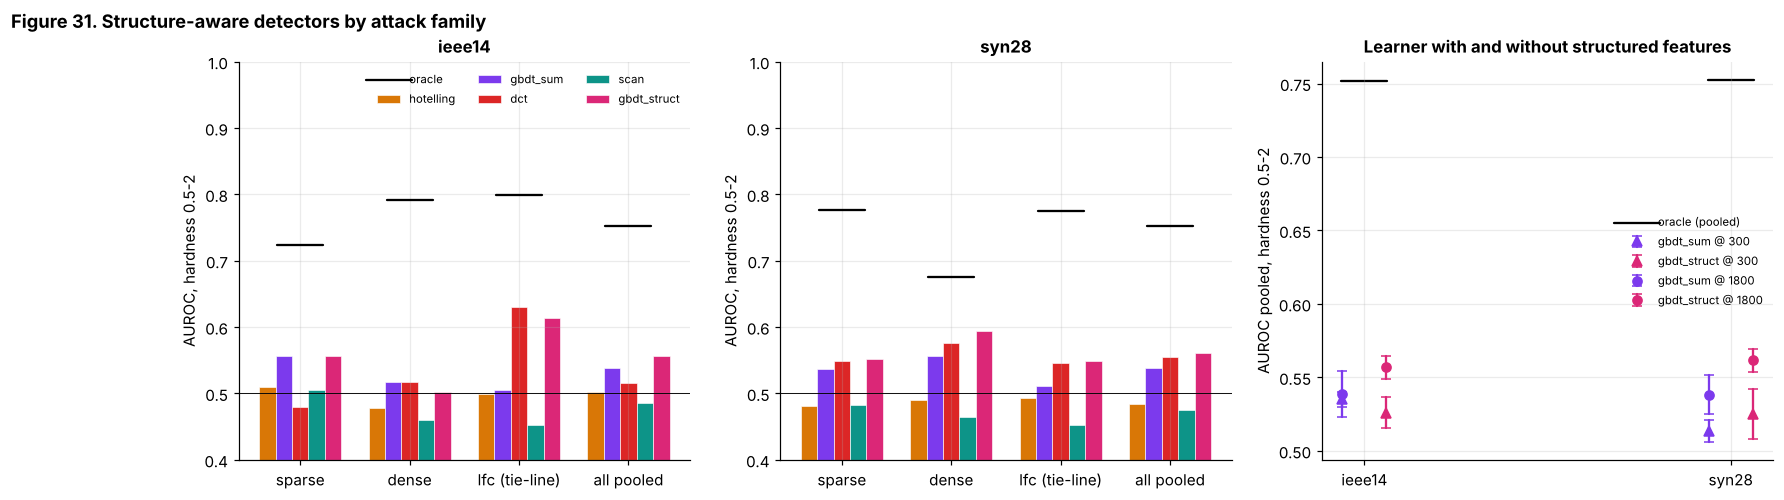

PosixPath('/tmp/w2/proj/figures/fig31_structure_aware_families.png')

In [57]:
KINDS = ["sparse", "dense", "lfc", "all"]; BUD_S = [300, EXT_TRAIN_N]; SEEDS_S = 3
STRUCT_ROWS, STRUCT_SCORES, STRUCT_MODELS, STRUCT_ORC = [], {}, {}, {}
for name in STUDY_GRIDS:
    cal, te, kit = CAL[name], DS[name]["test"], KITS[name]; pool = concat_blocks(DS[name]["train"], DS[name]["train_extra"])
    STRUCT_ORC[name] = {k: reg_oracle(cal, te, kind=k) for k in KINDS}
    base = dict(hotelling=Hotelling().score(cal, te), **struct_scores(kit, te)); STRUCT_SCORES[name] = dict(base)
    for k in KINDS:
        for dn, sc in base.items(): STRUCT_ROWS.append(dict(grid=name, budget=0, seed=0, det=dn, kind=k, auc=reg_auc(sc, te, kind=k)))
    for b in BUD_S:
        for seed in range(SEEDS_S):
            sub = subsample_balanced(pool, b, np.random.default_rng(1000 * seed + b))
            for nm, det in (("gbdt_sum", GBDTSum()), ("gbdt_struct", StructGBDT(kit))):
                det.fit(cal, sub, seed); s = det.score(cal, te)
                for k in KINDS: STRUCT_ROWS.append(dict(grid=name, budget=b, seed=seed, det=nm, kind=k, auc=reg_auc(s, te, kind=k)))
                if b == EXT_TRAIN_N and seed == 0: STRUCT_SCORES[name][nm] = s; STRUCT_MODELS.setdefault(name, {})[nm] = det
    print(f"{name}: structure-aware detectors done", flush=True)
SR = pd.DataFrame(STRUCT_ROWS)
ref_ = SR[(SR.budget.isin([0, EXT_TRAIN_N]))].groupby(["grid", "kind", "det"]).auc.mean().unstack("det")
for g in STUDY_GRIDS: ref_.loc[[(g, k) for k in KINDS], "oracle"] = [STRUCT_ORC[g][k] for k in KINDS]
print(ref_.round(3).to_string())

# Diagnostic: the same comparison with natural clean windows as the only negatives. Outages move the tie-line flow estimate just like a tie-line attack does,
# so a damage-coordinate test cannot tell them apart; this separates "cannot see the attack" from "cannot tell it from an outage".
NATD = []
for name in STUDY_GRIDS:
    cal, te = CAL[name], DS[name]["test"]; keep = np.where((te["label"] == 1) | ((te["kind"] == "natural") & (te["label"] == 0)))[0]; dn_ = {k: v[keep] for k, v in te.items()}
    for kind, model in (("lfc", None), ("sparse", None), ("all", None), ("lfc", "ac")):
        row = dict(grid=name, kind=kind + ("_" + model if model else ""), oracle=reg_oracle(cal, dn_, kind=kind, model=model))
        for det, sc in STRUCT_SCORES[name].items(): row[det] = reg_auc(sc[keep], dn_, kind=kind, model=model)
        NATD.append(row)
NATD = pd.DataFrame(NATD); print("\nSame comparison, natural clean windows as the only negatives (hardness 0.5-2); lfc_ac = tie-line attacks by an exact-model attacker only:"); print(NATD.round(3).to_string(index=False))

# AUROC ranks attacks by how *hard* they are (Mahalanobis), not by how much harm they do. A linear attacker with a stale Jacobian realises large hardness
# in harmless directions; the damage-coordinate test rightly ignores it. The metric the test is built for is damage prevented at a fixed false-alarm rate.
DMG2 = []
for name in STUDY_GRIDS:
    for dn, sc in STRUCT_SCORES[name].items():
        e, tot, evr = evaded_damage(name, sc, DS[name]["test"]); DMG2.append(dict(grid=name, det=dn, damage_prevented=1 - e / tot, evasion_rate=evr))
DMG2 = pd.DataFrame(DMG2); print("\nShare of attack damage prevented at 1% false alarms (all test attacks):"); print(DMG2.pivot(index="grid", columns="det", values="damage_prevented").round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.7)); DCOL = dict(hotelling=PAL["amber"], gbdt_sum=PAL["purple"], dct=PAL["red"], scan=PAL["teal"], gbdt_struct=PAL["pink"])
for ax, name in zip(axes[:2], STUDY_GRIDS):
    v = ref_.loc[name].loc[KINDS]; w_ = 0.15
    for k, dn in enumerate(["hotelling", "gbdt_sum", "dct", "scan", "gbdt_struct"]): ax.bar(np.arange(4) + (k - 2) * w_, v[dn], w_, color=DCOL[dn], label=dn, edgecolor="white", lw=0.4)
    ax.scatter(np.arange(4), v["oracle"], marker="_", s=900, color="k", zorder=5, label="oracle"); ax.axhline(0.5, color="k", lw=0.6)
    ax.set_xticks(range(4)); ax.set_xticklabels(["sparse", "dense", "lfc (tie-line)", "all pooled"]); ax.set_ylim(0.4, 1.0); ax.set_ylabel("AUROC, hardness 0.5-2"); ax.set_title(name)
axes[0].legend(fontsize=7.5, ncol=3)
ax = axes[2]
for b, ls in zip(BUD_S, [":", "-"]):
    for dn in ("gbdt_sum", "gbdt_struct"):
        v = SR[(SR.budget == b) & (SR.det == dn) & (SR.kind == "all")].groupby("grid").auc.agg(["mean", "std"]).loc[STUDY_GRIDS]
        ax.errorbar(np.arange(len(STUDY_GRIDS)) + (0.06 if dn == "gbdt_struct" else -0.06) + (0.0 if b == BUD_S[1] else 0.0), v["mean"], yerr=v["std"], fmt="o", ls="", color=DCOL[dn], capsize=3,
                    marker="o" if b == BUD_S[1] else "^", label=f"{dn} @ {b}")
ax.scatter(range(len(STUDY_GRIDS)), [STRUCT_ORC[g]["all"] for g in STUDY_GRIDS], marker="_", s=900, color="k", label="oracle (pooled)")
ax.set_xticks(range(len(STUDY_GRIDS))); ax.set_xticklabels(STUDY_GRIDS); ax.set_ylabel("AUROC pooled, hardness 0.5-2"); ax.set_title("Learner with and without structured features"); ax.legend(fontsize=7.5)
fig.suptitle("Figure 31. Structure-aware detectors by attack family", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig31_structure_aware_families")

### 16.5 The white-box adaptive attacker against each detector (H20; Figure 32)

Same protocol as Part 14 (best of $K$ random directions at fixed hardness 1.5 and damage fraction $\rho$ of the ceiling, selected on the attacker's own windows and scored on held-out windows), now with the DCT, the scan GLRT and the structured learner added. For the DCT there is an analytic floor: a shift of $\rho\delta_0$ in $z_h$ is detected by $|z_h|$ with AUROC equal to $P(|N(\rho\delta_0,1)|>|N(0,1)|)$, which does not depend on the direction the attacker picks.

ieee14: adaptive attacker vs structure-aware detectors done


syn28: adaptive attacker vs structure-aware detectors done


                          ref  adaptive   loss
grid   rho det                                
ieee14 0.5 dct          0.608     0.608 -0.000
           gbdt_struct  0.616     0.607  0.009
           gbdt_sum     0.519     0.512  0.007
           hotelling    0.573     0.572  0.001
           scan         0.532     0.513  0.020
       0.8 dct          0.690     0.690 -0.000
           gbdt_struct  0.661     0.658  0.003
           gbdt_sum     0.507     0.501  0.006
           hotelling    0.575     0.573  0.002
           scan         0.516     0.513  0.003
syn28  0.5 dct          0.565     0.565 -0.000
           gbdt_struct  0.552     0.548  0.004
           gbdt_sum     0.505     0.498  0.007
           hotelling    0.530     0.529  0.001
           scan         0.516     0.514  0.002
       0.8 dct          0.644     0.644 -0.000
           gbdt_struct  0.587     0.589 -0.002
           gbdt_sum     0.495     0.499 -0.004
           hotelling    0.527     0.527 -0.000
           sc

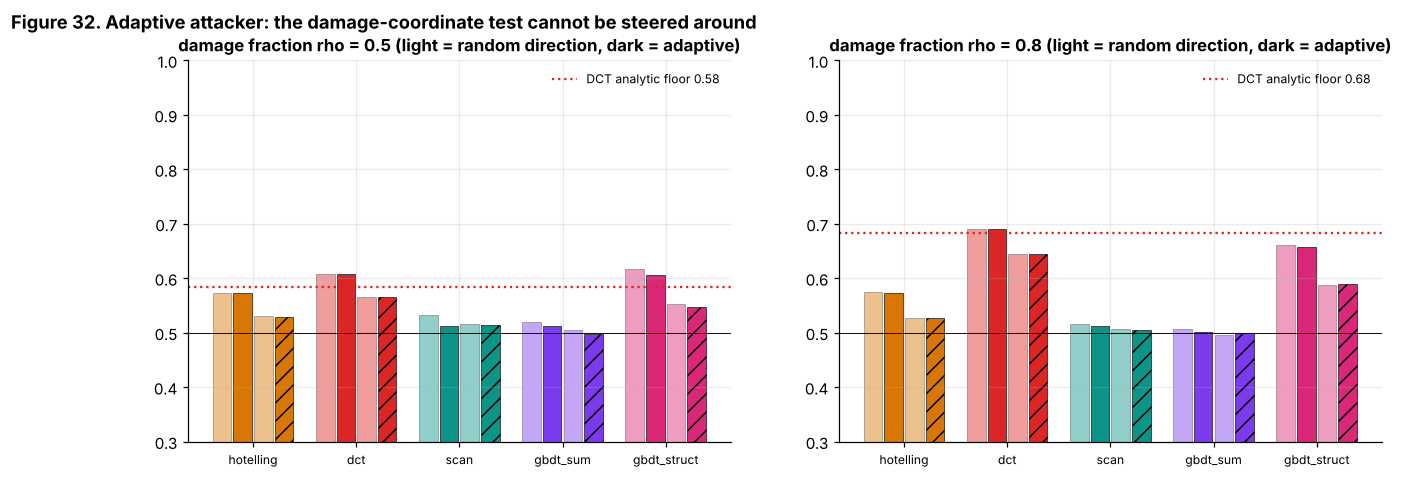

PosixPath('/tmp/w2/proj/figures/fig32_adaptive_structured.png')

In [58]:
def abs_floor(m, n=400000, seed=0):
    r = np.random.default_rng(seed); return float((np.abs(r.normal(m, 1, n)) > np.abs(r.normal(0, 1, n))).mean())

ADV2 = []
for name in STUDY_GRIDS:
    sim, cal, te, kit = SIMS[name], CAL[name], DS[name]["test"], KITS[name]
    nat = {k: v[(te["kind"] == "natural") & (te["label"] == 0)] for k, v in te.items()}
    vv = cal.L.T @ sim.h_tie; vhat = vv / np.linalg.norm(vv)
    gs, gst = STRUCT_MODELS[name]["gbdt_sum"], STRUCT_MODELS[name]["gbdt_struct"]
    def sc_of(dn, d):
        if dn == "hotelling": return Hotelling().score(cal, d)
        if dn in ("dct", "scan"): return struct_scores(kit, d)[dn]
        return (gs if dn == "gbdt_sum" else gst).score(cal, d)
    for rho_ in RHOS:
        for r in range(R_ADV):
            rng = np.random.default_rng(300 * r + int(10 * rho_)); perm = rng.permutation(len(nat["x"])); h_ = len(perm) // 2
            A = {k: v_[perm[:h_]] for k, v_ in nat.items()}; T = {k: v_[perm[h_:]] for k, v_ in nat.items()}
            Zof = lambda W: DELTA0 * (rho_ * vhat[None] + np.sqrt(1 - rho_ ** 2) * W)
            Wk = rand_perp(vhat, K_CAND, rng); Wr = rand_perp(vhat, N_REF, rng)
            attA = stacked_attack(cal, A, Zof(Wk), cal.L); attR = stacked_attack(cal, T, Zof(Wr), cal.L); attS = lambda i: stacked_attack(cal, T, Zof(Wk[i:i + 1]), cal.L)
            for dn in ["hotelling", "dct", "scan", "gbdt_sum", "gbdt_struct"]:
                sA = sc_of(dn, attA).reshape(K_CAND, -1).mean(1); star = int(np.argmin(sA))
                cl = sc_of(dn, T); sR = sc_of(dn, attR).reshape(N_REF, -1)
                ref = float(np.mean([auc_pair(sR[i], cl) for i in range(N_REF)])); adv = auc_pair(sc_of(dn, attS(star)), cl)
                ADV2.append(dict(grid=name, det=dn, rho=rho_, rep=r, ref=ref, adaptive=adv, loss=ref - adv))
    print(f"{name}: adaptive attacker vs structure-aware detectors done", flush=True)
ADV2 = pd.DataFrame(ADV2); FLOOR = {rho_: abs_floor(rho_ * DELTA0) for rho_ in RHOS}
print(ADV2.groupby(["grid", "rho", "det"])[["ref", "adaptive", "loss"]].mean().round(3).to_string()); print("DCT analytic floor:", {k: round(v, 3) for k, v in FLOOR.items()})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, rho_ in zip(axes, RHOS):
    dets_ = ["hotelling", "dct", "scan", "gbdt_sum", "gbdt_struct"]
    for k, name in enumerate(STUDY_GRIDS):
        v = ADV2[(ADV2.grid == name) & (ADV2.rho == rho_)].groupby("det")[["ref", "adaptive"]].mean().loc[dets_]
        ax.bar(np.arange(5) + (k - 0.5) * 0.4 - 0.1, v["ref"], 0.18, color=[DCOL[d] for d in dets_], alpha=0.45, edgecolor="k", lw=0.4)
        ax.bar(np.arange(5) + (k - 0.5) * 0.4 + 0.1, v["adaptive"], 0.18, color=[DCOL[d] for d in dets_], edgecolor="k", lw=0.4, hatch="//" if k else "")
    ax.axhline(FLOOR[rho_], color=PAL["red"], ls=":", label=f"DCT analytic floor {FLOOR[rho_]:.2f}"); ax.axhline(0.5, color="k", lw=0.6)
    ax.set_xticks(range(5)); ax.set_xticklabels(dets_, fontsize=8); ax.set_ylim(0.3, 1.0); ax.set_title(f"damage fraction rho = {rho_} (light = random direction, dark = adaptive)"); ax.legend(fontsize=8)
fig.suptitle("Figure 32. Adaptive attacker: the damage-coordinate test cannot be steered around", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig32_adaptive_structured")

### 16.6 Local attacks (Figure 33)

Attacks on the real generator touching the meters around one bus (radius 0 to 2) at hardness 1.5, negatives are natural clean windows. The oracle is flat in radius (Part 15.9); the scan library contains exactly these neighbourhoods, which is again close to matching the family by construction, so the interesting number is how much the *learner* gains from being handed the scan statistics.

  grid  radius  meters  oracle  hotelling   dct  scan  gbdt_sum  gbdt_struct
ieee14       0  10.620   0.841      0.503 0.480 0.524     0.470        0.495
ieee14       1  25.512   0.851      0.549 0.492 0.554     0.510        0.520
ieee14       2  43.332   0.849      0.539 0.479 0.560     0.507        0.532
 syn28       0   9.452   0.840      0.518 0.490 0.523     0.497        0.534
 syn28       1  29.444   0.833      0.533 0.502 0.546     0.581        0.572
 syn28       2  63.840   0.864      0.528 0.497 0.534     0.556        0.565


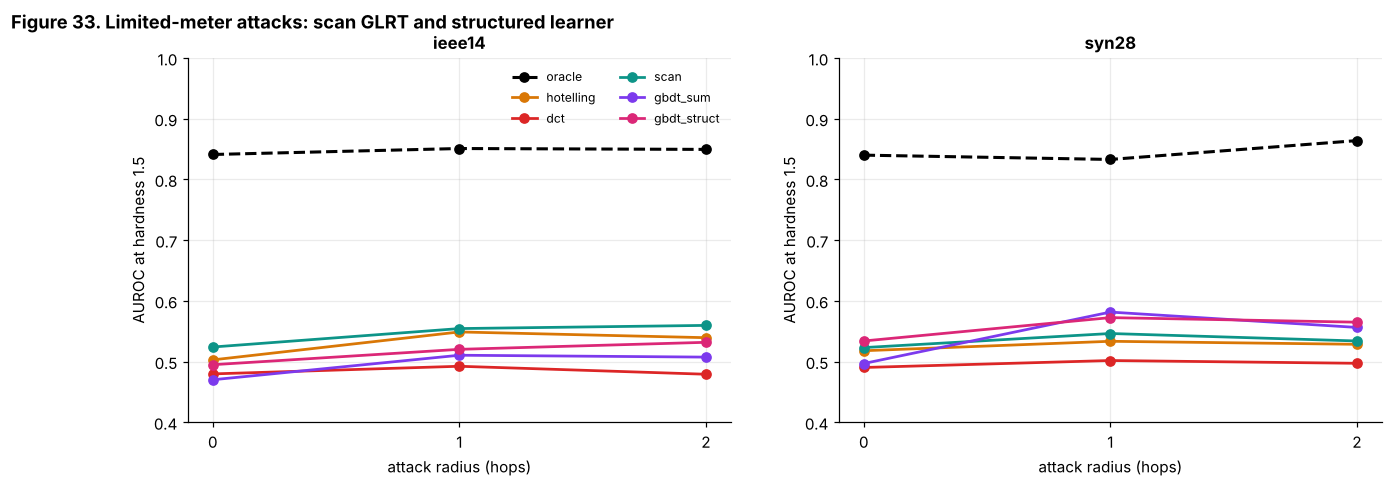

PosixPath('/tmp/w2/proj/figures/fig33_local_structured.png')

In [59]:
LOC2 = []
for name in STUDY_GRIDS:
    sim, cal, te, kit = SIMS[name], CAL[name], DS[name]["test"], KITS[name]; nat = as_clean(te, (te["kind"] == "natural") & (te["label"] == 0))
    gs, gst = STRUCT_MODELS[name]["gbdt_sum"], STRUCT_MODELS[name]["gbdt_struct"]
    for r in (0, 1, 2):
        rng = rng_for("loc2", r, *[ord(c) for c in name]); att = gen_custom_block(sim, cal, rng, N_LOC, lambda g_: local_direction(sim, cal, g_, r), 1.5); d = concat_blocks(nat, att)
        ss = struct_scores(kit, d); row = dict(grid=name, radius=r, meters=float(att["nmet"].mean()), oracle=float(oracle_scores(cal, d)[0].mean()), hotelling=overall_auc(Hotelling().score(cal, d), d),
                                               dct=overall_auc(ss["dct"], d), scan=overall_auc(ss["scan"], d), gbdt_sum=overall_auc(gs.score(cal, d), d), gbdt_struct=overall_auc(gst.score(cal, d), d))
        LOC2.append(row)
LOC2 = pd.DataFrame(LOC2); print(LOC2.round(3).to_string(index=False))

fig, axes = plt.subplots(1, len(STUDY_GRIDS), figsize=(7 * len(STUDY_GRIDS), 4.3))
for ax, name in zip(np.atleast_1d(axes), STUDY_GRIDS):
    v = LOC2[LOC2.grid == name]; ax.plot(v.radius, v.oracle, "k--o", lw=2, label="oracle")
    for dn in ("hotelling", "dct", "scan", "gbdt_sum", "gbdt_struct"): ax.plot(v.radius, v[dn], "o-", color=DCOL[dn], label=dn, lw=1.8)
    ax.set_xticks([0, 1, 2]); ax.set_xlabel("attack radius (hops)"); ax.set_ylabel("AUROC at hardness 1.5"); ax.set_title(name); ax.set_ylim(0.4, 1.0)
np.atleast_1d(axes)[0].legend(fontsize=8, ncol=2)
fig.suptitle("Figure 33. Limited-meter attacks: scan GLRT and structured learner", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig33_local_structured")

### 16.7 Damage-aware risk control with a damage-aware score (H23; Figure 34)

Exactly the conformal-risk-control protocol of Part 13.3 (tie-line-aimed attacks by an exact-model attacker, budget set at half the undetected damage, 400 random calibration splits), with the DCT score and the structured learner added next to Hotelling and the summary GBDT. The question is not coverage, which the construction handles, but the **false-alarm rate paid** for the same damage budget. The rate is reported on natural clean windows (the quantity the budget rule is about) and, separately, on N-1 outage windows, because a damage-coordinate score cannot tell an outage from a tie-line attack and will alarm on outages.

  grid         det  alpha  mean_risk  frac_under  mean_fpr  mean_fpr_outage  no_detector
ieee14   hotelling  0.131      0.103       0.812     0.224            0.981        0.261
ieee14    gbdt_sum  0.131      0.103       0.760     0.375            0.186        0.261
ieee14         dct  0.131      0.098       0.968     0.010            0.027        0.261
ieee14 gbdt_struct  0.131      0.102       0.820     0.011            0.020        0.261
 syn28   hotelling  0.145      0.114       0.825     0.391            0.877        0.290
 syn28    gbdt_sum  0.145      0.111       0.750     0.660            0.256        0.290
 syn28         dct  0.145      0.107       0.865     0.004            0.019        0.290
 syn28 gbdt_struct  0.145      0.113       0.808     0.074            0.000        0.290

DCT false-alarm rate / Hotelling false-alarm rate at the same damage budget: 0.02


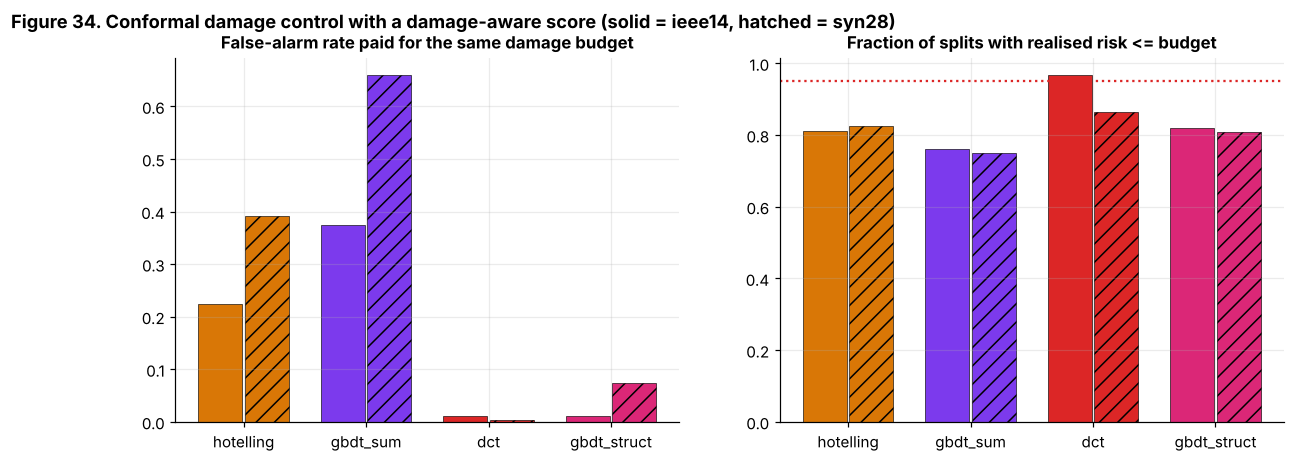

PosixPath('/tmp/w2/proj/figures/fig34_crc_structured.png')

In [60]:
CRC2 = []; N_SPL = 400
for name in STUDY_GRIDS:
    sim, cal, te = SIMS[name], CAL[name], DS[name]["test"]; ia = np.where((te["label"] == 1) & (te["dirkind"] == "lfc") & (te["model"] == "ac"))[0]
    sq = float(np.sqrt(sim.h_tie @ cal.Sigma @ sim.h_tie)); dcap = max(6.5, float(te["delta"][ia].max())); Dmax = float(flow_to_Hz(sim.g, dcap * sq))
    dmg = flow_to_Hz(sim.g, te["flow"][ia]) / Dmax; alpha = 0.5 * dmg.mean(); nat_ = (te["kind"] == "natural") & (te["label"] == 0)
    sc_all = dict(hotelling=STRUCT_SCORES[name]["hotelling"], gbdt_sum=STRUCT_SCORES[name]["gbdt_sum"], dct=STRUCT_SCORES[name]["dct"], gbdt_struct=STRUCT_SCORES[name]["gbdt_struct"])
    out_ = te["kind"] == "outage"
    for dn, s_all in sc_all.items():
        s_att = s_all[ia]; risks, fprs, fpo = [], [], []; rng = np.random.default_rng(3 + zlib.crc32((name + dn).encode()) % 1000)
        for _ in range(N_SPL):
            perm = rng.permutation(len(ia)); ci, ti = perm[: len(ia) // 2], perm[len(ia) // 2:]; lam = crc_threshold(s_att[ci], dmg[ci], alpha)
            risks.append(float(np.mean(dmg[ti] * (s_att[ti] <= lam)))); fprs.append(float(np.mean(s_all[nat_] > lam))); fpo.append(float(np.mean(s_all[out_] > lam)))
        CRC2.append(dict(grid=name, det=dn, alpha=alpha, mean_risk=np.mean(risks), frac_under=float(np.mean(np.array(risks) <= alpha)), mean_fpr=np.mean(fprs), mean_fpr_outage=np.mean(fpo), no_detector=float(dmg.mean())))
CRC2 = pd.DataFrame(CRC2); print(CRC2.round(3).to_string(index=False))
fpr_ratio = float(CRC2[CRC2.det == "dct"].mean_fpr.mean() / max(CRC2[CRC2.det == "hotelling"].mean_fpr.mean(), 1e-9)); print(f"\nDCT false-alarm rate / Hotelling false-alarm rate at the same damage budget: {fpr_ratio:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3)); dets_ = ["hotelling", "gbdt_sum", "dct", "gbdt_struct"]
for ax, col, ttl in zip(axes, ["mean_fpr", "frac_under"], ["False-alarm rate paid for the same damage budget", "Fraction of splits with realised risk <= budget"]):
    for k, name in enumerate(STUDY_GRIDS):
        v = CRC2[CRC2.grid == name].set_index("det").loc[dets_]; ax.bar(np.arange(4) + (k - 0.5) * 0.38, v[col], 0.36, color=[DCOL[d] for d in dets_], edgecolor="k", lw=0.4, hatch="//" if k else "")
    ax.set_xticks(range(4)); ax.set_xticklabels(dets_); ax.set_title(ttl)
axes[1].axhline(0.95, color=PAL["red"], ls=":")
fig.suptitle("Figure 34. Conformal damage control with a damage-aware score (solid = ieee14, hatched = syn28)", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig34_crc_structured")

### 16.8 Reading Part 16

If the DCT and the scan statistic come out well on their own families, that is the expected, partly built-in result stated in 16.2. What deserves attention is whether (a) the DCT survives the adaptive attacker at its floor, (b) the learner improves when handed the structure, and (c) the damage-aware score lowers the false-alarm price of a damage budget. Each is scored in Part 17 with the same mechanical rules as before.

## Part 17. An environment zoo with realistic, profile-driven operating data

Everything so far lives in one family of environments: meshed transmission-style IEEE cases and synthetic grids whose operating points come from a regime-switching, heavy-tailed random-load model. Two criticisms apply, and both are fair.

1. *The environments are narrow.* Distribution feeders (radial, low-voltage, heavy in distributed generation) and a larger transmission case behave differently. Radial grids have no N−1 outages that keep the system connected, impedance ratios are very different, and the net load can be negative when rooftop PV exports.
2. *The operating data are made up.* A Gaussian-like load model is convenient but nobody has shown that conclusions drawn on it survive realistic daily and seasonal structure.

This part adds an **environment zoo** of seven grids and, for the SimBench grids, replaces the random-load model by **SimBench's yearly 15-minute load and DER profiles** (Meinecke et al., 2020, *SimBench: a benchmark dataset of electric power systems to compare innovative solutions based on power flow analysis*, Energies 13(12):3290) run through our own AC power flow.

| Environment | Source | Type | Operating data |
|---|---|---|---|
| `case118` | pandapower `case118` | meshed transmission, 118 buses | our regime-switching generator |
| `hv_mixed` | SimBench `1-HV-mixed--0-sw` | meshed 110 kV subtransmission with wind and PV | **SimBench profiles** |
| `cigre_mv` | CIGRE MV benchmark | radial/ring 20 kV, 14 buses | our generator |
| `oberrhein` | pandapower `mv_oberrhein` | real-derived radial MV feeder system | our generator |
| `mv_rural` | SimBench `1-MV-rural--0-sw` | radial MV, 90 low-voltage PV clusters, wind, biomass | **SimBench profiles** |
| `mv_semiurb` | SimBench `1-MV-semiurb--0-sw` | radial MV | **SimBench profiles** |
| `mv_comm` | SimBench `1-MV-comm--0-sw` | radial MV, commercial load | **SimBench profiles** |

**What is and is not realistic.** SimBench profiles are synthetic-but-validated profiles built from standard load profiles and weather data. They are not measured utility SCADA. Our additions on top of them are a multiplicative sub-15-minute fluctuation (2% system-wide, 3% per bus). Everything else (meters, noise, attacks) is as in Parts 4 to 6.

**Hard negatives on radial grids.** An N−1 line outage that keeps the grid connected does not exist on a tree. The analogue we use is a *feeder load surge or DER trip*: 10% of the buses jump by a factor between 1.8 and 3.0. It is a genuine non-malicious event that moves the state far from the calibration cloud, which is the job N−1 outages do in meshed grids.

**LFC caveat.** The "fake tie-line flow" attack direction is defined from the two-area partition. On a distribution feeder it is a fake flow across the partition boundary, not an LFC tie line. It stays a useful worst-case damage coordinate but should not be read as a frequency-control result.

**Pre-registered, before running.**

* **H24** (physics validity): our power flow matches pandapower's on SimBench profile states to within $10^{-5}$ p.u. in voltage magnitude, for every SimBench environment.
* **H25** (broad family does not cover new topologies): the grid-agnostic detector trained on the 8-grid family (`broad8`, Part 11) loses at least 0.05 more difficulty-adjusted AUROC on the zoo than on the unseen IEEE/synthetic grids.
* **H26** (diversity helps): a detector trained on the other zoo environments (leave-one-environment-out) beats the `broad8` detector on the held-out zoo environment by at least 0.02 AUROC.

In [61]:
import simbench as sb
warnings.filterwarnings("ignore")

class ProfileSim(GridSim):
    """GridSim whose operating points are drawn from SimBench's yearly 15-minute load and DER profiles."""
    def __init__(self, g, name, net):
        super().__init__(g, name)
        ab = sb.get_absolute_values(net, profiles_instead_of_study_cases=True)
        bm = g.meta["bus_map"]; self.T = len(ab[("load", "p_mw")])
        def inc(df_p, elem, scale=None):
            tab = getattr(net, elem); out = np.zeros((self.T, g.n))
            for j, col in enumerate(df_p.columns):
                b = bm[int(tab.loc[col, "bus"])]
                if b >= 0 and tab.loc[col, "in_service"]:
                    out[:, b] += df_p[col].values * (1.0 if scale is None else scale[j])
            return out
        qr = (net.sgen.q_mvar / net.sgen.p_mw.replace(0, np.nan)).fillna(0).values       # constant power factor per DER
        self.Pload = inc(ab[("load", "p_mw")], "load"); self.Qload = inc(ab[("load", "q_mvar")], "load")
        self.Psgen = inc(ab[("sgen", "p_mw")], "sgen"); self.Qsgen = inc(ab[("sgen", "p_mw")], "sgen", scale=qr)
        self.net, self.qr, self.ab = net, qr, ab
        # Profiles swing far from the case-file operating point (e.g. wind export reverses the sign of the net load), so the
        # warm start of the power flow and of the estimator is re-anchored at the median-net-load step of the year.
        t_med = int(np.argsort((self.Pload - self.Psgen).sum(1))[self.T // 2])
        Pd, Qd = self.conditions_at(t_med); V, ok, _ = newton_pf(self.M, Pd, Qd, np.zeros(g.n))
        assert ok, f"{name}: median-profile power flow did not converge"
        self.V0 = V; self.x0 = V_to_x(self.M, V)
    def estimate(self, z):
        return wls_estimate(self.M, self.mt, z, self.x0, iters=15, tol=1e-7)     # profiles swing far from the warm start
    def conditions_at(self, t):
        return self.Pload[t] - self.Psgen[t], self.Qload[t] - self.Qsgen[t]
    def draw_conditions(self, rng):
        Pd, Qd = self.conditions_at(int(rng.integers(self.T)))
        f = np.exp(0.02 * rng.normal() + 0.03 * rng.normal(size=self.g.n))               # sub-15-minute variability
        return Pd * f, Qd * f, np.zeros(self.g.n)

ZOO_SPEC = [("case118",    "meshed transmission", lambda: pn.case118(), None),
            ("hv_mixed",   "meshed subtransmission, profiles", lambda: sb.get_simbench_net("1-HV-mixed--0-sw"), "profile"),
            ("cigre_mv",   "radial MV benchmark", lambda: pn.create_cigre_network_mv(with_der=False), None),
            ("oberrhein",  "radial MV, real-derived", lambda: pn.mv_oberrhein(), None),
            ("mv_rural",   "radial MV, PV-rich, profiles", lambda: sb.get_simbench_net("1-MV-rural--0-sw"), "profile"),
            ("mv_semiurb", "radial MV, profiles", lambda: sb.get_simbench_net("1-MV-semiurb--0-sw"), "profile"),
            ("mv_comm",    "radial MV, commercial, profiles", lambda: sb.get_simbench_net("1-MV-comm--0-sw"), "profile")]
ZOO = [z[0] for z in ZOO_SPEC]
ZOO_NET = {}
t0 = time.time()
for name, desc, make, prof in ZOO_SPEC:
    net = make(); g = grid_from_pandapower(net, name, family="zoo"); assign_areas(g); g.family = "zoo"
    assert accept(g), f"{name} failed the convergence screen"
    GRIDS[name] = g; ZOO_NET[name] = net
    SIMS[name] = ProfileSim(g, name, net) if prof else GridSim(g, name)
print(f"built {len(ZOO)} zoo simulators in {time.time()-t0:.0f}s")

# ---- H24: own power flow versus pandapower on SimBench profile states ---------------------------------------------------
def pp_voltage_at(sim, t):
    net = sim.net; ab = sim.ab
    net.load["p_mw"] = ab[("load", "p_mw")].iloc[t].values; net.load["q_mvar"] = ab[("load", "q_mvar")].iloc[t].values
    net.sgen["p_mw"] = ab[("sgen", "p_mw")].iloc[t].values; net.sgen["q_mvar"] = net.sgen["p_mw"] * sim.qr
    pp.runpp(net, numba=False, max_iteration=50)
    bm = sim.g.meta["bus_map"]; vm = np.full(sim.g.n, np.nan)
    for b in net.bus.index:
        if bm[b] >= 0 and np.isfinite(net.res_bus.vm_pu[b]): vm[bm[b]] = net.res_bus.vm_pu[b]
    return vm
H24_ROWS = []
rng = rng_for("h24")
for name in [n for n, _, _, p in ZOO_SPEC if p]:
    sim = SIMS[name]; net = sim.net
    p0, q0, sp0, sq0 = net.load.p_mw.values.copy(), net.load.q_mvar.values.copy(), net.sgen.p_mw.values.copy(), net.sgen.q_mvar.values.copy()
    dev = []
    for t in rng.integers(0, sim.T, 8):
        Pd, Qd = sim.conditions_at(int(t)); V, ok = sim.solve(Pd, Qd, np.zeros(sim.g.n))
        vm = pp_voltage_at(sim, int(t)); dev.append(np.nanmax(np.abs(np.abs(V) - vm)) if ok else np.inf)
    net.load["p_mw"], net.load["q_mvar"], net.sgen["p_mw"], net.sgen["q_mvar"] = p0, q0, sp0, sq0
    H24_ROWS.append((name, float(np.max(dev))))
H24_val = max(v for _, v in H24_ROWS)
for n_, v in H24_ROWS: print(f"{n_:<12} max |Vm(own) - Vm(pandapower)| over 8 profile states = {v:.2e} p.u.")
H24_pass = bool(H24_val < 1e-5); print("H24", "PASS" if H24_pass else "FAIL", f"(worst {H24_val:.2e})")

numba cannot be imported and numba functions are disabled.
Probably the execution is slow.
Please install numba to gain a massive speedup.
(or if you prefer slow execution, set the flag numba=False to avoid this warning!)


built 7 zoo simulators in 28s


hv_mixed     max |Vm(own) - Vm(pandapower)| over 8 profile states = 2.82e-06 p.u.
mv_rural     max |Vm(own) - Vm(pandapower)| over 8 profile states = 1.46e-06 p.u.
mv_semiurb   max |Vm(own) - Vm(pandapower)| over 8 profile states = 1.18e-06 p.u.
mv_comm      max |Vm(own) - Vm(pandapower)| over 8 profile states = 1.31e-06 p.u.
H24 PASS (worst 2.82e-06)


### 17.1 Calibration, datasets, and a physics sanity table (Figure 35)

Each zoo environment gets the same machinery as Parts 5 to 7: a random meter placement (observable, redundancy at least 1.5), a clean calibration set for $\mu$ and $\Sigma$, and a train/test pair with hardness-stratified attacks and hard negatives. The calibration set is sized at $\max(n_{\rm cal},4n_s)$ so that the sample covariance of a 235-state grid is not rank-starved.

The sanity table has four checks per environment: the power flow converges on at least 99% of drawn operating points, the mean $J(\hat x)$ divided by its degrees of freedom is near 1 (the estimator is statistically consistent), the voltage range stays inside a plausible band, and the condition number of $\Sigma$ is finite. Radial feeders are expected to have a much larger spread of eigenvalues than meshed grids, because voltage magnitude and angle are almost decoupled along a feeder.

zoo calibration sets built in 214s


case118     built in 138.1s


hv_mixed    built in 184.0s


cigre_mv    built in  13.7s


oberrhein   built in  52.5s


mv_rural    built in 327.1s


mv_semiurb  built in 561.1s


mv_comm     built in 471.8s


            buses  branches  states  meters  dof  pf_ok   Vmin   Vmax  J_over_dof  cond_log10  N1_lines net_load_MW_range
env                                                                                                                      
case118       118       186     235     490  255    1.0  0.934  1.050       1.000       9.758       177        2953..5568
hv_mixed       64       101     127     256  129    1.0  1.067  1.117       1.021      10.924        35        -1108..140
cigre_mv       18        17      35      61   26    1.0  0.870  1.030       1.001       9.940         0            29..62
oberrhein      71        70     141     252  111    1.0  0.948  1.023       0.999      10.386         0            11..23
mv_rural      101       101     201     362  161    1.0  1.011  1.063       1.012       9.960         0            -14..5
mv_semiurb    123       123     245     451  206    1.0  1.012  1.054       1.131       9.747         0             -8..8
mv_comm       111       

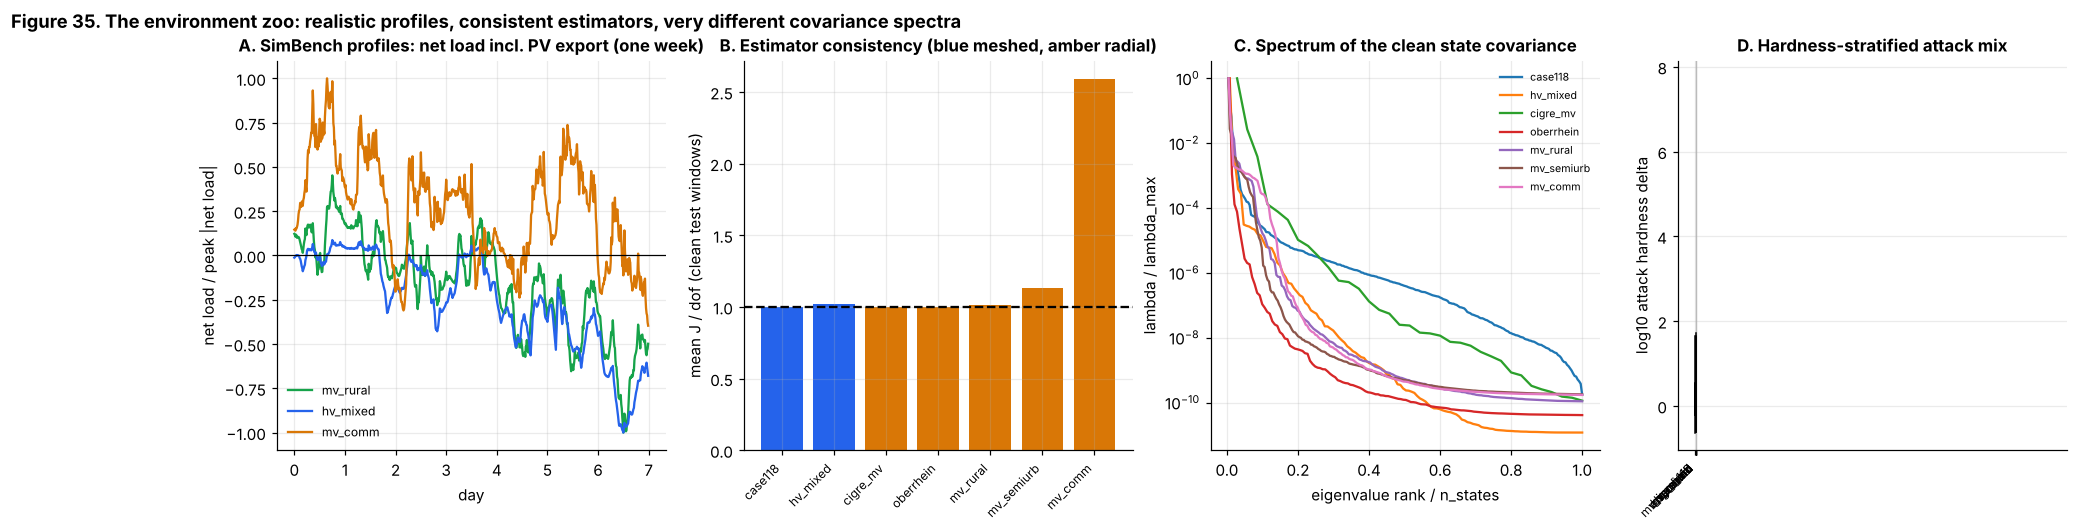

PosixPath('/tmp/w2/proj/figures/fig35_zoo_overview.png')

In [62]:
t0 = time.time()
for name in ZOO:
    sim = SIMS[name]
    sim.h_tie = tie_sensitivity(sim); sim.H_nom = meas_jac(sim.M, sim.V0)[sim.mt["sel"]]
    CAL[name] = Calib(sim, max(SIZES["n_cal"], 4 * sim.mt["ns"]))
print(f"zoo calibration sets built in {time.time()-t0:.0f}s")

DS_Z = {}
for name in ZOO:                                     # one cache file per environment, so a changed environment rebuilds alone
    zc = DATA / f"zoo_{name}_{BUDGET}.pkl"
    if zc.exists():
        with open(zc, "rb") as fh: DS_Z[name] = pickle.load(fh)
    else:
        t1 = time.time(); DS_Z[name] = build_grid_data(name); print(f"{name:<11} built in {time.time()-t1:5.1f}s", flush=True)
        with open(zc, "wb") as fh: pickle.dump(DS_Z[name], fh)
DS.update(DS_Z)

rows = []
for name in ZOO:
    sim, cal, d = SIMS[name], CAL[name], DS_Z[name]
    rng = rng_for("zoo_check", *[ord(c) for c in name]); nconv = 0; vmin, vmax, netP = [], [], []
    for _ in range(200):
        Pd, Qd, Pg = sim.draw_conditions(rng); V, ok = sim.solve(Pd, Qd, Pg); nconv += ok
        if ok: vmin.append(np.abs(V).min()); vmax.append(np.abs(V).max()); netP.append(Pd.sum() * 1.0)
    clean = d["test"]["kind"] == "natural"
    rows.append(dict(env=name, buses=sim.g.n, branches=sim.g.nl, states=sim.mt["ns"], meters=sim.mt["m"], dof=cal.dof,
                     pf_ok=nconv / 200, Vmin=np.min(vmin), Vmax=np.max(vmax), J_over_dof=float(np.mean(d["test"]["J"][clean]) / cal.dof),
                     cond_log10=float(np.log10(np.linalg.cond(cal.Sigma))), N1_lines=len(sim.outage_lines),
                     net_load_MW_range=f"{np.min(netP):.0f}..{np.max(netP):.0f}"))
ZT = pd.DataFrame(rows).set_index("env"); print(ZT.round(3).to_string())

fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
ax = axes[0]
for name, col in [("mv_rural", PAL["green"]), ("hv_mixed", PAL["blue"]), ("mv_comm", PAL["amber"])]:
    sim = SIMS[name]; t = np.arange(96 * 7) + 96 * 180          # one week in late June
    P = [sim.conditions_at(int(i))[0].sum() for i in t]
    ax.plot(t / 96 - 180, np.array(P) / max(1e-9, np.max(np.abs(P))), color=col, label=f"{name}")
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("day"); ax.set_ylabel("net load / peak |net load|"); ax.legend(fontsize=8)
ax.set_title("A. SimBench profiles: net load incl. PV export (one week)")
ax = axes[1]; x_ = np.arange(len(ZOO))
ax.bar(x_, ZT.J_over_dof.values, color=[PAL["blue"] if SIMS[n].outage_lines else PAL["amber"] for n in ZOO])
ax.axhline(1, color="k", ls="--"); ax.set_xticks(x_); ax.set_xticklabels(ZOO, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("mean J / dof (clean test windows)"); ax.set_title("B. Estimator consistency (blue meshed, amber radial)")
ax = axes[2]
for name in ZOO:
    ev = CAL[name].eigval; ax.semilogy(np.arange(1, len(ev) + 1) / len(ev), ev / ev[0], label=name)
ax.set_xlabel("eigenvalue rank / n_states"); ax.set_ylabel("lambda / lambda_max"); ax.legend(fontsize=7); ax.set_title("C. Spectrum of the clean state covariance")
ax = axes[3]
for name in ZOO:
    cal = CAL[name]; ax.plot(np.sort(np.abs(whiten(cal, DS_Z[name]["test"]["x"][DS_Z[name]["test"]["kind"] == "natural"]))).ravel()[::40] , alpha=0)  # placeholder to share limits
vv = [np.log10(DS_Z[n]["test"]["delta"][DS_Z[n]["test"]["label"] == 1]) for n in ZOO]
ax.boxplot(vv, tick_labels=ZOO, showfliers=False); ax.set_xticklabels(ZOO, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("log10 attack hardness delta"); ax.set_title("D. Hardness-stratified attack mix")
fig.suptitle("Figure 35. The environment zoo: realistic profiles, consistent estimators, very different covariance spectra", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig35_zoo_overview")

### 17.2 The benchmark on the zoo (Figure 36)

Same protocol as Part 10: train in-grid with the Part 7 training set, test at the hard region ($0.5\le\delta<2$), and compare with the empirical oracle. The unsupervised tests need no labels. Two further rows use the grid-agnostic summary view: `broad8_zero` is a gradient-boosted model trained on the eight-grid IEEE/synthetic family of Part 11 and applied **without any adaptation**; `loeo` is trained on the *other six* zoo environments and applied to this one (leave-one-environment-out). All supervised rows use the same number of training windows.

case118     done (10s)


hv_mixed    done (17s)


cigre_mv    done (24s)


oberrhein   done (33s)


mv_rural    done (41s)


...

mv_comm     done (59s)


zero-shot / LOEO seed 0 done (67s)


zero-shot / LOEO seed 1 done (76s)


zero-shot / LOEO seed 2 done (85s)


             chi2  hotelling  pca_recon  iforest   gbdt    mlp  gbdt_sum  broad8_zero   loeo  oracle
case118     0.468      0.473      0.492    0.478  0.567  0.547     0.522        0.539  0.501   0.701
hv_mixed    0.466      0.471      0.465    0.504  0.589  0.448     0.767        0.519  0.633   0.870
cigre_mv    0.472      0.499      0.472    0.507  0.540  0.531     0.602        0.544  0.508   0.779
oberrhein   0.481      0.491      0.467    0.494  0.553  0.472     0.689        0.492  0.604   0.875
mv_rural    0.459      0.469      0.477    0.470  0.579  0.472     0.596        0.497  0.595   0.835
mv_semiurb  0.465      0.483      0.494    0.503  0.546  0.547     0.560        0.486  0.548   0.834
mv_comm     0.471      0.483      0.481    0.475  0.521  0.465     0.579        0.513  0.523   0.823


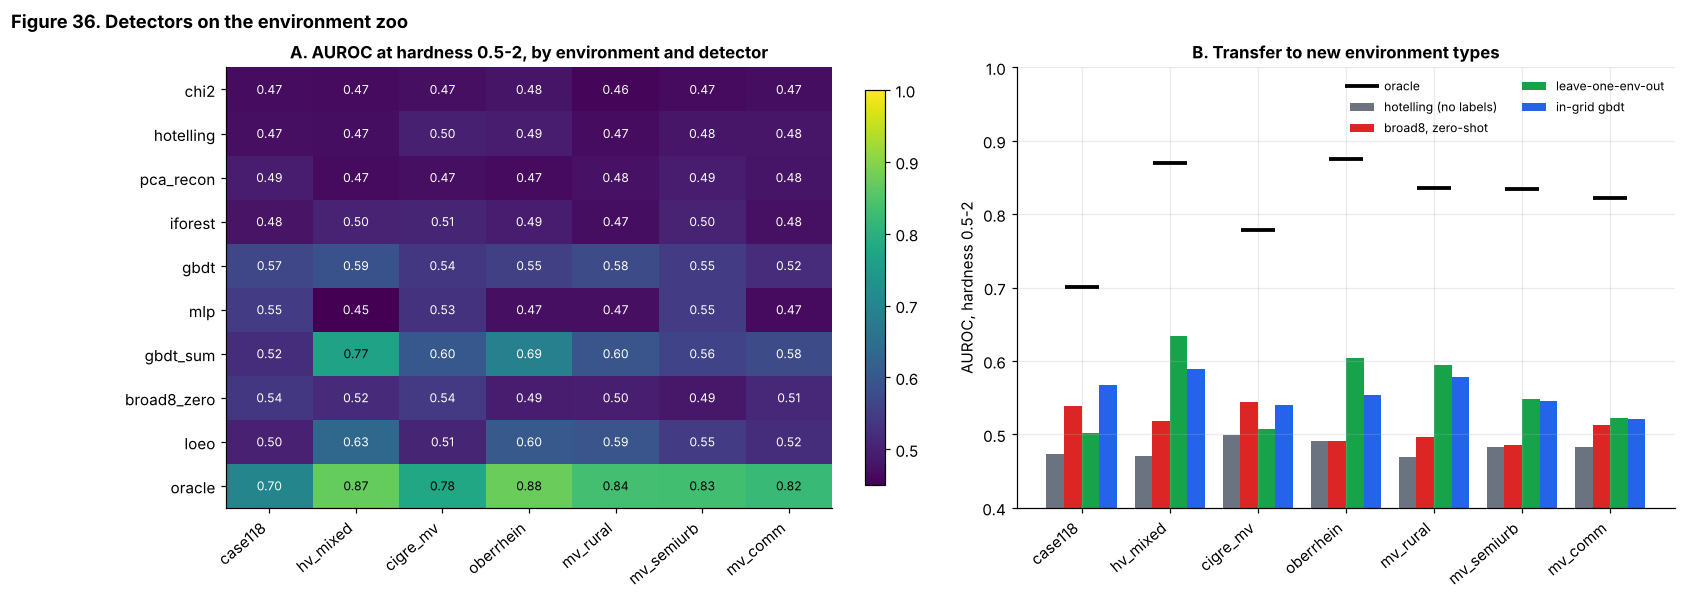

H25: advantage over Hotelling of the broad8 detector: unseen IEEE/synthetic +0.067, zoo +0.032; extra loss +0.036 -> FAIL (threshold 0.05)
H26: LOEO minus broad8 zero-shot: mean +0.046, positive in 5/7 environments -> PASS (needs >= +0.02 and >= 5 positives)
per-environment: {'case118': -0.037, 'hv_mixed': 0.115, 'cigre_mv': -0.037, 'oberrhein': 0.112, 'mv_rural': 0.098, 'mv_semiurb': 0.062, 'mv_comm': 0.009}


In [63]:
t0 = time.time()
ZRES = {}; ZSC = {}
HARD = np.array([0.5, 1.0, 2.0])
for name in ZOO:
    cal, d = CAL[name], DS_Z[name]; te = d["test"]; sc = {}
    for D in (Hotelling, PCARecon, IForest, Chi2): sc[D.name if isinstance(D.name, str) else D().name] = D().fit(cal, None, 0).score(cal, te)
    for D in (GBDT, MLP, GBDTSum): det = D().fit(cal, d["train"], 0); sc[det.name] = det.score(cal, te)
    ZSC[name] = sc
    ZRES[name] = {k: small_auc(v, te) for k, v in sc.items()}
    ZRES[name]["oracle"] = float(np.nanmean(oracle_by_bin(cal, te, HARD)))
    print(f"{name:<11} done ({time.time()-t0:.0f}s)", flush=True)

# zero-shot broad8 and leave-one-environment-out
n_tot = ARMS["broad8"] and sum(ARMS["broad8"].values())
ZSHOT = {n: [] for n in ZOO}; LOEO = {n: [] for n in ZOO}
for seed in range(SIZES["n_budget_seeds"]):
    X, y = arm_training_arrays("broad8", seed, GBDTSum); det_b = GBDTSum()._fit_xy(X, y, seed)
    for name in ZOO:
        ZSHOT[name].append(small_auc(det_b.score(CAL[name], DS_Z[name]["test"]), DS_Z[name]["test"]))
        others = [o for o in ZOO if o != name]; per = (n_tot // len(others)); per -= per % 2
        Xs, ys = [], []
        for o in others:
            sub = subsample_balanced(DS_Z[o]["train"], min(per, len(DS_Z[o]["train"]["label"])), np.random.default_rng(9100 + 17 * seed + len(o)))
            Xs.append(summary_features(CAL[o], sub)); ys.append(sub["label"])
        det_l = GBDTSum()._fit_xy(np.vstack(Xs), np.concatenate(ys), seed)
        LOEO[name].append(small_auc(det_l.score(CAL[name], DS_Z[name]["test"]), DS_Z[name]["test"]))
    print(f"zero-shot / LOEO seed {seed} done ({time.time()-t0:.0f}s)", flush=True)
for name in ZOO:
    ZRES[name]["broad8_zero"] = float(np.mean(ZSHOT[name])); ZRES[name]["loeo"] = float(np.mean(LOEO[name]))
ZR = pd.DataFrame(ZRES).T[["chi2", "hotelling", "pca_recon", "iforest", "gbdt", "mlp", "gbdt_sum", "broad8_zero", "loeo", "oracle"]]
print(ZR.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))
ax = axes[0]; im = ax.imshow(ZR.values.T, cmap="viridis", vmin=0.45, vmax=1.0, aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(ZOO))); ax.set_xticklabels(ZOO, rotation=40, ha="right"); ax.set_yticks(range(ZR.shape[1])); ax.set_yticklabels(ZR.columns)
for i in range(ZR.shape[0]):
    for j in range(ZR.shape[1]): ax.text(i, j, f"{ZR.values[i, j]:.2f}", ha="center", va="center", color="w" if ZR.values[i, j] < 0.75 else "k", fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.03); ax.set_title("A. AUROC at hardness 0.5-2, by environment and detector")
ax = axes[1]; w = 0.2; x_ = np.arange(len(ZOO))
for k, (col, lab, c) in enumerate([("hotelling", "hotelling (no labels)", PAL["grey"]), ("broad8_zero", "broad8, zero-shot", PAL["red"]),
                                   ("loeo", "leave-one-env-out", PAL["green"]), ("gbdt", "in-grid gbdt", PAL["blue"])]):
    ax.bar(x_ + (k - 1.5) * w, ZR[col].values, w, color=c, label=lab)
ax.plot(x_, ZR["oracle"].values, "k_", ms=22, mew=2.5, label="oracle")
ax.set_ylim(0.4, 1.0); ax.set_xticks(x_); ax.set_xticklabels(ZOO, rotation=40, ha="right"); ax.legend(fontsize=8, ncol=2); ax.set_ylabel("AUROC, hardness 0.5-2")
ax.set_title("B. Transfer to new environment types")
fig.suptitle("Figure 36. Detectors on the environment zoo", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig36_zoo_bench")

# ---- H25, H26 -------------------------------------------------------------------------------------------------------
adv_unseen = float(np.mean([np.mean([tr_res["broad8"]["gbdt_sum"][s]["unseen"][g] for s in tr_res["broad8"]["gbdt_sum"]]) - REF["hotelling"][g] for g in UNSEEN]))
adv_zoo = float(np.mean([ZR.loc[n, "broad8_zero"] - ZR.loc[n, "hotelling"] for n in ZOO]))
H25_val = adv_unseen - adv_zoo; H25_pass = bool(H25_val >= 0.05)
print(f"H25: advantage over Hotelling of the broad8 detector: unseen IEEE/synthetic {adv_unseen:+.3f}, zoo {adv_zoo:+.3f}; extra loss {H25_val:+.3f} -> {'PASS' if H25_pass else 'FAIL'} (threshold 0.05)")
dl = (ZR["loeo"] - ZR["broad8_zero"]); H26_val = float(dl.mean()); H26_pos = int((dl > 0).sum())
H26_pass = bool(H26_val >= 0.02 and H26_pos >= 5)
print(f"H26: LOEO minus broad8 zero-shot: mean {H26_val:+.3f}, positive in {H26_pos}/{len(ZOO)} environments -> {'PASS' if H26_pass else 'FAIL'} (needs >= +0.02 and >= 5 positives)")
print("per-environment:", dl.round(3).to_dict())

## Part 18. A nonlinear LFC plant: how much of the damage story survives real controller limits?

Part 12 turned a faked tie-line flow into a frequency excursion with a **linear** two-area model. That choice made the damage ceiling a closed form, but real governors and AGC loops are not linear. Four nonlinearities that appear in standard LFC studies are added here (a state-of-the-art review of the nonlinear LFC literature is in the project survey; the specific numbers below are textbook-scale, not fitted to any real system):

| Element | Model | Value |
|---|---|---|
| Governor dead band | speed error ignored below a threshold | $\pm 0.036$ Hz |
| Generation rate constraint (GRC) | $|\dot P_m|\le r$ | $0.0017$ pu/s (10% per minute, thermal) |
| Valve / governor saturation | $|P_v|\le v_{\max}$ | $0.10$ pu of headroom |
| AGC integrator clamp (anti-windup) | $|P_{\rm ref}|\le i_{\max}$ | $0.10$ pu |
| Measurement delay on the tie-line reading | pure delay | $2$ s |

The attack enters exactly as before, as an additive bias $b(t)$ on the tie-line reading used by both ACEs.

**What changes.** (i) Damage is no longer proportional to the bias: dead band makes small biases harmless, saturation and the rate limit make big ones sub-linear. (ii) The *time profile* of the bias now matters: the linear model's peak frequency deviation for a constant bias is a property of its transfer function, but a rate-limited, saturating plant can respond very differently to a pulsed or oscillating bias of the same amplitude. So the damage ceiling is no longer "constant bias times a gain": it is the maximum over time profiles with bounded amplitude, computed numerically here.

**Honest scope.** This is a stand-in plant. It shows how conclusions of Part 12 move when realistic limits are added; it does not validate against any real LFC system. A time-varying bias also implies a time-varying hardness, so a profile that beats the constant bias in damage may be easier to detect by a temporal detector (Part 15). We do not claim stealth for the oscillating profile; we claim that **the constant-bias damage ceiling of Part 12 is not an upper bound on the damage of an amplitude-bounded attacker once the plant is nonlinear**.

**Pre-registered, before running.**

* **H27**: at the largest benchmark bias (hardness 6.5 along the worst-case direction), the linear plant mis-states the nonlinear plant's peak frequency deviation by at least 25%.
* **H28**: the ranking of the nine detectors by evaded damage at 1% false alarms under the nonlinear plant has Spearman correlation at least 0.9 with the ranking under the linear plant (the *detector ranking* is robust to the plant even if absolute damage is not).
* **H29**: for an amplitude-bounded attacker, the best square-wave bias frequency produces at least 1.3 times the peak deviation of a constant bias of the same amplitude in the nonlinear plant.

In [64]:
NLP = dict(db=0.036 / LFC["f0"], grc=0.0017, vlim=0.10, ilim=0.10, delay=2.0)

def nl_peak_df(b_t, dt=0.05, nl=NLP, P=LFC, linear=False, traj=False):
    """Simulate the two-area plant on a batch of bias profiles b_t of shape (nt, B) (pu on the area base).
    Returns the peak |df| over both areas, in Hz, for each profile. linear=True switches every nonlinearity off (check vs Part 12)."""
    H, D, R, Tg, Tt, Ki = [np.array(P[k]) for k in ("H", "D", "R", "Tg", "Tt", "Ki")]; T12 = P["T12"]; Bf = 1 / R + D
    nt, Bn = b_t.shape; z = np.zeros(Bn)
    df, Pm, Pv, Pr = [z.copy(), z.copy()], [z.copy(), z.copy()], [z.copy(), z.copy()], [z.copy(), z.copy()]
    Pt = z.copy(); dl = max(1, int(round(nl["delay"] / dt))) if not linear else 1
    buf = np.zeros((dl, Bn)); pk = z.copy(); sgn = (1.0, -1.0); hist = []
    for k in range(nt):
        Ptm = buf[k % dl] if not linear else Pt                          # delayed tie reading
        if not linear: buf[k % dl] = Pt
        dfn, Pmn, Pvn, Prn = [0, 0], [0, 0], [0, 0], [0, 0]
        for a in (0, 1):
            e = df[a] if linear else np.sign(df[a]) * np.maximum(np.abs(df[a]) - nl["db"], 0.0)       # dead band
            ddf = (-D[a] * df[a] + Pm[a] - sgn[a] * Pt) / (2 * H[a])
            dPm = (-Pm[a] + Pv[a]) / Tt[a]
            dPv = (-e / R[a] - Pv[a] + Pr[a]) / Tg[a]
            dPr = -Ki[a] * (Bf[a] * df[a] + sgn[a] * (Ptm + b_t[k]))
            if not linear:
                dPm = np.clip(dPm, -nl["grc"], nl["grc"])                                             # generation rate constraint
                dPv = np.where(((Pv[a] >= nl["vlim"]) & (dPv > 0)) | ((Pv[a] <= -nl["vlim"]) & (dPv < 0)), 0.0, dPv)
                dPr = np.where(((Pr[a] >= nl["ilim"]) & (dPr > 0)) | ((Pr[a] <= -nl["ilim"]) & (dPr < 0)), 0.0, dPr)
            dfn[a] = df[a] + dt * ddf; Pmn[a] = Pm[a] + dt * dPm; Pvn[a] = Pv[a] + dt * dPv; Prn[a] = Pr[a] + dt * dPr
        Pt = Pt + dt * 2 * np.pi * T12 * (df[0] - df[1])
        df, Pm, Pv, Pr = dfn, Pmn, Pvn, Prn
        pk = np.maximum(pk, np.maximum(np.abs(df[0]), np.abs(df[1])))
        if traj: hist.append(pk * P["f0"])
    return np.array(hist) if traj else pk * P["f0"]

# check 1: with every nonlinearity off, the simulator reproduces Part 12's lsim number
TT, DT = 300.0, 0.05; NT = int(TT / DT)
pk_lin = nl_peak_df(np.ones((NT, 1)), DT, linear=True)[0]
print(f"unit constant bias: simulator (linear mode) {pk_lin:.4f} Hz   Part 12 lsim {G_f:.4f} Hz   relative diff {abs(pk_lin-G_f)/G_f:.2%}")
assert abs(pk_lin - G_f) / G_f < 0.05, "discretised linear plant does not reproduce the Part 12 plant"

unit constant bias: simulator (linear mode) 1.0841 Hz   Part 12 lsim 1.0794 Hz   relative diff 0.43%


### 18.1 Damage is not proportional to the bias, and the time profile matters (Figure 37)

Panel A sweeps a constant bias from 0.001 to 1 pu and compares peak frequency deviation in the nonlinear plant with the linear plant's straight line. Panel B fixes the amplitude at 0.15 pu and sweeps the frequency of a square-wave bias. Panel C shows the time response of both plants to the best square wave.

nonlinear plant simulated in 2s
H29: amplitude 0.15 pu: constant bias peak 0.0714 Hz; best square wave (0.082 Hz) 0.2619 Hz; ratio 3.67 -> PASS
     linear plant, same square waves: best 0.3252 Hz vs constant 0.1619 Hz (ratio 2.01)


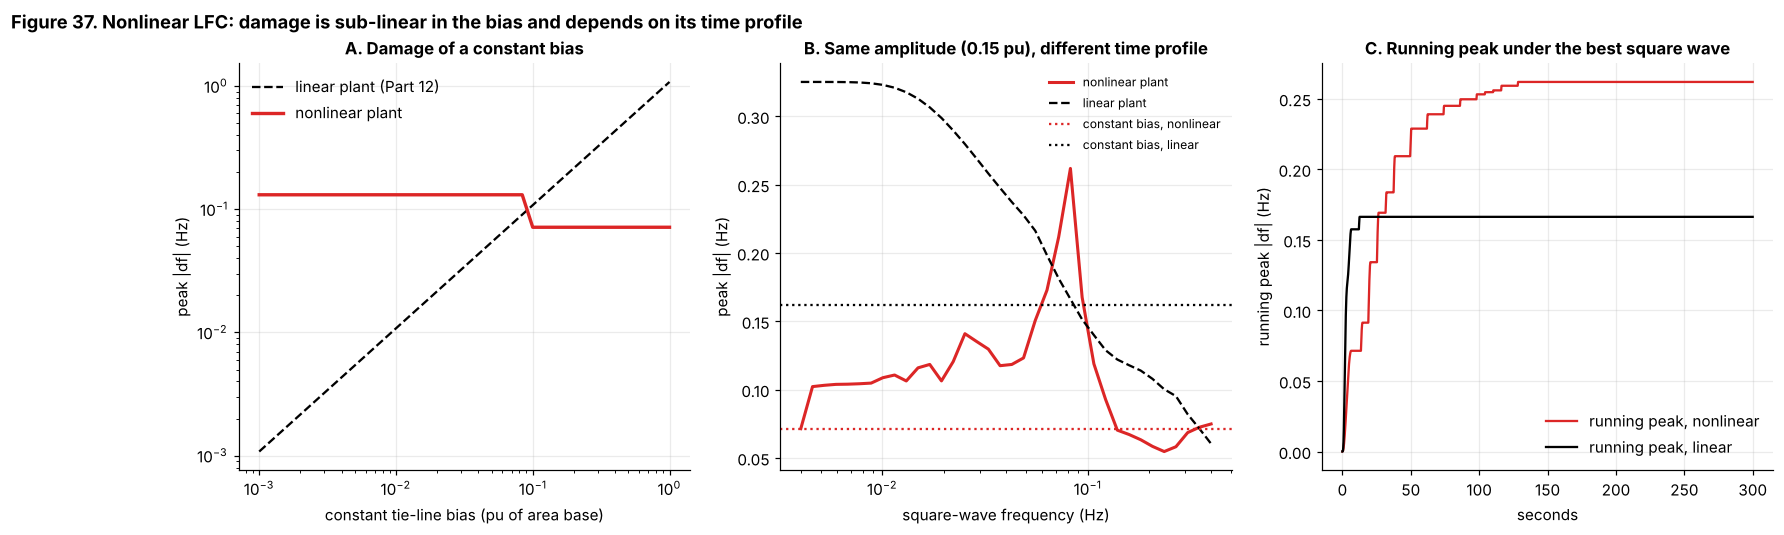

PosixPath('/tmp/w2/proj/figures/fig37_nl_lfc.png')

In [65]:
t0 = time.time()
BGRID = np.exp(np.linspace(np.log(1e-3), np.log(1.0), 40))
D_NL = nl_peak_df(np.tile(BGRID, (NT, 1)), DT)                              # constant biases
D_LIN = BGRID * G_f
FREQ = np.exp(np.linspace(np.log(0.004), np.log(0.4), 36))                  # Hz of the square wave
tgrid = np.arange(NT) * DT
def square_profiles(amp, freqs): return amp * np.sign(np.sin(2 * np.pi * freqs[None, :] * tgrid[:, None] + 1e-9))
AMP_SQ = 0.15
D_SQ = nl_peak_df(square_profiles(AMP_SQ, FREQ), DT)
D_SQ_LIN = nl_peak_df(square_profiles(AMP_SQ, FREQ), DT, linear=True)
d_const = float(np.interp(AMP_SQ, BGRID, D_NL)); f_best = FREQ[np.argmax(D_SQ)]
H29_val = float(D_SQ.max() / d_const); H29_pass = bool(H29_val >= 1.3)
print(f"nonlinear plant simulated in {time.time()-t0:.0f}s")
print(f"H29: amplitude {AMP_SQ} pu: constant bias peak {d_const:.4f} Hz; best square wave ({f_best:.3f} Hz) {D_SQ.max():.4f} Hz; ratio {H29_val:.2f} -> {'PASS' if H29_pass else 'FAIL'}")
print(f"     linear plant, same square waves: best {D_SQ_LIN.max():.4f} Hz vs constant {AMP_SQ*G_f:.4f} Hz (ratio {D_SQ_LIN.max()/(AMP_SQ*G_f):.2f})")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]; ax.loglog(BGRID, D_LIN, "k--", label="linear plant (Part 12)"); ax.loglog(BGRID, D_NL, color=PAL["red"], lw=2.2, label="nonlinear plant")
ax.set_xlabel("constant tie-line bias (pu of area base)"); ax.set_ylabel("peak |df| (Hz)"); ax.legend(); ax.set_title("A. Damage of a constant bias")
ax = axes[1]; ax.semilogx(FREQ, D_SQ, color=PAL["red"], lw=2, label="nonlinear plant"); ax.semilogx(FREQ, D_SQ_LIN, "k--", label="linear plant")
ax.axhline(d_const, color=PAL["red"], ls=":", label="constant bias, nonlinear"); ax.axhline(AMP_SQ * G_f, color="k", ls=":", label="constant bias, linear")
ax.set_xlabel("square-wave frequency (Hz)"); ax.set_ylabel("peak |df| (Hz)"); ax.legend(fontsize=8); ax.set_title(f"B. Same amplitude ({AMP_SQ} pu), different time profile")
ax = axes[2]; bt = square_profiles(AMP_SQ, np.array([f_best])); 
for lin, col, lab in [(False, PAL["red"], "nonlinear"), (True, "k", "linear")]:
    ax.plot(tgrid, nl_peak_df(bt, DT, linear=lin, traj=True)[:, 0], color=col, label=f"running peak, {lab}")
ax.set_xlabel("seconds"); ax.set_ylabel("running peak |df| (Hz)"); ax.legend(); ax.set_title("C. Running peak under the best square wave")
fig.suptitle("Figure 37. Nonlinear LFC: damage is sub-linear in the bias and depends on its time profile", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig37_nl_lfc")

### 18.2 Does the damage story change? (Figure 38)

Using the same test sets and detector scores as Part 12.4, damage is recomputed with the nonlinear plant. Each attack's faked flow is converted to a bias on the area base and mapped through the *constant-bias* damage curve $D_{NL}(b)$ of Part 18.1 (a lower bound on what the attacker could do with a better profile). Then:

* H27 compares the two plants at the largest hardness.
* H28 compares the detector ranking by evaded damage under the two plants.
* The damage ceiling of Part 12.3 is recomputed with the **profile-maximised** damage $\max_f D_{\rm sq}(b,f)$, which is what an amplitude-bounded attacker could achieve.

  grid  bias_pu  linear_Hz  nonlinear_Hz  rel_error
ieee14   0.7674     0.8284        0.0714    10.6010
 syn28   0.9305     1.0044        0.0714    13.0671
damage of the largest attack at each hardness (the ceiling), linear versus nonlinear plant:
  grid  hardness  bias_pu  linear_Hz  nonlinear_Hz
ieee14       0.5   0.0590     0.0637        0.1310
ieee14       1.0   0.1181     0.1274        0.0714
ieee14       2.0   0.2361     0.2549        0.0714
ieee14       4.0   0.4723     0.5098        0.0714
ieee14       6.5   0.7674     0.8284        0.0714
 syn28       0.5   0.0716     0.0773        0.1310
 syn28       1.0   0.1432     0.1545        0.0714
 syn28       2.0   0.2863     0.3091        0.0714
 syn28       4.0   0.5726     0.6181        0.0714
 syn28       6.5   0.9305     1.0044        0.0714
H27: linear plant mis-states the nonlinear peak by up to 1306.7% at hardness 6.5 -> PASS
  grid       det   auc  prevented_linear  prevented_nl
ieee14 hotelling 0.599             0.375       

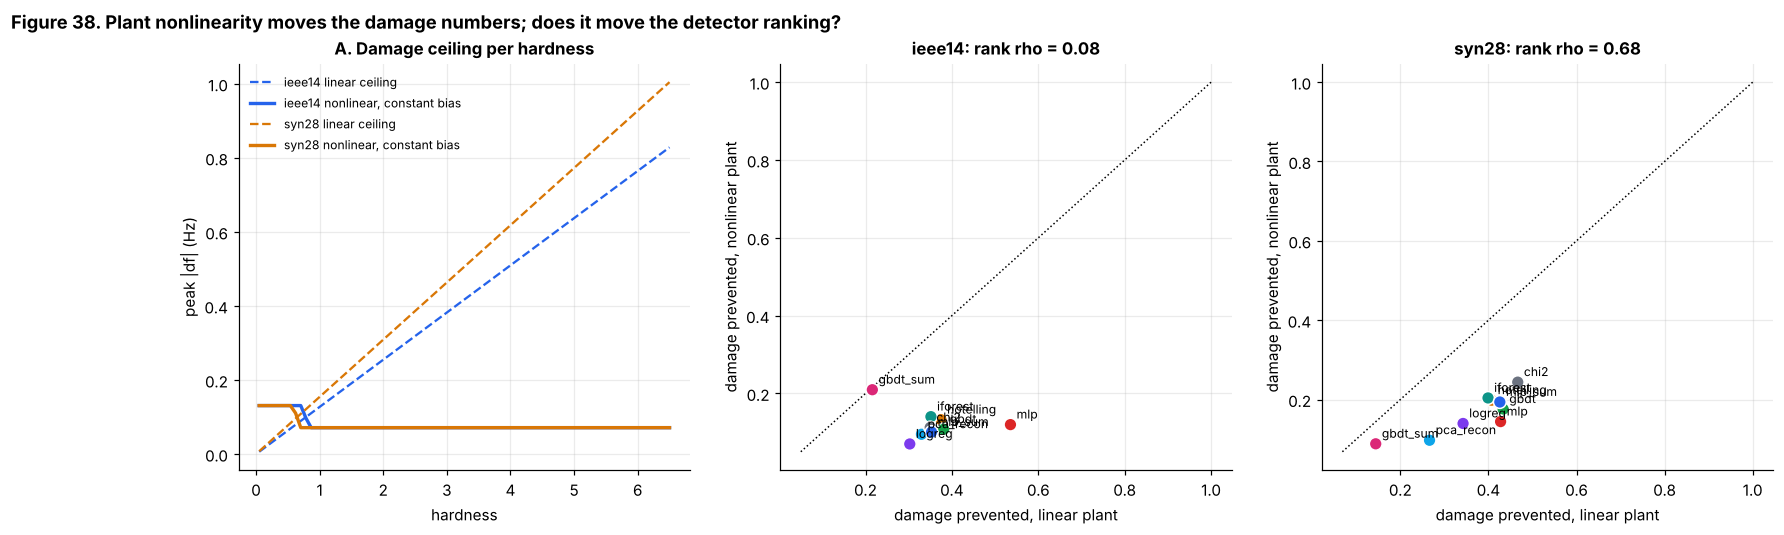

PosixPath('/tmp/w2/proj/figures/fig38_nl_damage.png')

In [66]:
def bias_pu(name, flow_pu): return np.abs(flow_pu) * SIMS[name].g.baseMVA / area_base_MW(SIMS[name].g)
def dmg_nl(name, flow_pu): return np.interp(np.log(np.clip(bias_pu(name, flow_pu), BGRID[0], BGRID[-1])), np.log(BGRID), D_NL) * (bias_pu(name, flow_pu) > BGRID[0])
def evaded_damage_nl(name, score, test, fpr=0.01):
    nat = (test["kind"] == "natural") & (test["label"] == 0); thr = np.quantile(score[nat], 1 - fpr); ia = test["label"] == 1
    dm = dmg_nl(name, test["flow"][ia]); ev_ = score[ia] <= thr
    return float(np.mean(dm * ev_)), float(np.mean(dm))

# H27: biggest benchmark bias
h27 = []
for name in STUDY_GRIDS:
    sim, cal = SIMS[name], CAL[name]; sq = float(np.sqrt(sim.h_tie @ cal.Sigma @ sim.h_tie)); b_ = bias_pu(name, 6.5 * sq)
    d_nl = float(np.interp(np.log(np.clip(b_, BGRID[0], BGRID[-1])), np.log(BGRID), D_NL)); d_l = b_ * G_f
    h27.append(dict(grid=name, bias_pu=b_, linear_Hz=d_l, nonlinear_Hz=d_nl, rel_error=abs(d_l - d_nl) / d_nl))
H27_df = pd.DataFrame(h27); print(H27_df.round(4).to_string(index=False))
# where does the linear plant stop being a good approximation? relative error at several hardness values
rows_ = []
for name in STUDY_GRIDS:
    sim, cal = SIMS[name], CAL[name]; sq = float(np.sqrt(sim.h_tie @ cal.Sigma @ sim.h_tie))
    for dl_ in (0.5, 1.0, 2.0, 4.0, 6.5):
        b_ = bias_pu(name, dl_ * sq); d_nl = float(np.interp(np.log(np.clip(b_, BGRID[0], BGRID[-1])), np.log(BGRID), D_NL)) * (b_ > BGRID[0]); rows_.append(dict(grid=name, hardness=dl_, bias_pu=b_, linear_Hz=b_ * G_f, nonlinear_Hz=d_nl))
print("damage of the largest attack at each hardness (the ceiling), linear versus nonlinear plant:"); print(pd.DataFrame(rows_).round(4).to_string(index=False))
H27_val = float(H27_df.rel_error.max()); H27_pass = bool(H27_val >= 0.25)
print(f"H27: linear plant mis-states the nonlinear peak by up to {H27_val:.1%} at hardness 6.5 -> {'PASS' if H27_pass else 'FAIL'}")

rows = []
for name in STUDY_GRIDS:
    test = DS[name]["test"]
    for d_, s in INGRID_SCORES[name].items():
        e_l, tot_l, _ = evaded_damage(name, s, test); e_n, tot_n = evaded_damage_nl(name, s, test)
        rows.append(dict(grid=name, det=d_, auc=overall_auc(s, test), prevented_linear=1 - e_l / tot_l, prevented_nl=1 - e_n / tot_n))
NLD = pd.DataFrame(rows)
rho_nl = {g: spearmanr(NLD[NLD.grid == g].prevented_linear, NLD[NLD.grid == g].prevented_nl)[0] for g in STUDY_GRIDS}
H28_val = float(np.mean(list(rho_nl.values()))); H28_pass = bool(H28_val >= 0.9)
print(NLD.round(3).to_string(index=False))
print(f"H28: Spearman between detector rankings by damage prevented, linear vs nonlinear plant: {rho_nl} -> mean {H28_val:.3f} -> {'PASS' if H28_pass else 'FAIL'}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
for name, col in zip(STUDY_GRIDS, [PAL["blue"], PAL["amber"]]):
    sim, cal = SIMS[name], CAL[name]; sq = float(np.sqrt(sim.h_tie @ cal.Sigma @ sim.h_tie)); dd = np.linspace(0.05, 6.5, 80)
    b_ = bias_pu(name, dd * sq); ax.plot(dd, b_ * G_f, color=col, ls="--", label=f"{name} linear ceiling")
    ax.plot(dd, np.interp(np.log(np.clip(b_, BGRID[0], BGRID[-1])), np.log(BGRID), D_NL), color=col, lw=2.2, label=f"{name} nonlinear, constant bias")
ax.set_xlabel("hardness"); ax.set_ylabel("peak |df| (Hz)"); ax.set_title("A. Damage ceiling per hardness"); ax.legend(fontsize=8)
for ax, name in zip(axes[1:], STUDY_GRIDS):
    v = NLD[NLD.grid == name]
    ax.scatter(v.prevented_linear, v.prevented_nl, s=70, c=[DET_COLORS[d] for d in v.det], edgecolor="white", zorder=3)
    for _, r in v.iterrows(): ax.annotate(r.det, (r.prevented_linear, r.prevented_nl), fontsize=8, xytext=(4, 4), textcoords="offset points")
    lim = [min(v.prevented_linear.min(), v.prevented_nl.min()) - 0.02, 1.0]; ax.plot(lim, lim, "k:", lw=1)
    ax.set_xlabel("damage prevented, linear plant"); ax.set_ylabel("damage prevented, nonlinear plant"); ax.set_title(f"{name}: rank rho = {rho_nl[name]:.2f}")
fig.suptitle("Figure 38. Plant nonlinearity moves the damage numbers; does it move the detector ranking?", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig38_nl_damage")

## Part 19. Deep detectors, a normalizing-flow one-class detector, and a gradient-based white-box attacker

Two hypotheses from the original plan (H9, H10) were marked NOT RUN because they needed a deep-learning stack. The stack is available now (PyTorch; the code selects `cuda` when a GPU is present, otherwise the CPU, and prints which). The models are small on purpose: the training sets are 1,800 windows of 27 to 245 features, where a large network would only memorise.

### 19.1 The detectors

All take the whitened state $w=L^{-1}(\hat x-\mu)$ plus the two residual features of Part 8.1.

| Detector | Idea | Parameters |
|---|---|---|
| `t_mlp` | a plain 3-layer network with dropout, trained with binary cross-entropy | ~10k |
| `t_phys` | **physics-structured head**: a *learned positive quadratic* in the eigen-coordinates of $\Sigma$, plus the squared damage coordinate $z_h=\hat v^\top w$, plus the two residual features. It starts exactly at Hotelling and can only re-weight spectral directions | $n_s+5$ |
| `t_flow` | **normalizing-flow one-class detector**: a RealNVP trained on clean calibration windows only; the score is $-\log p(w)$. It reduces to Hotelling when the clean state is Gaussian and differs when it is not | ~40k |

**Why a physics-structured head.** The oracle in Part 2 is a linear statistic of $w$ and Hotelling is a quadratic one. A detector that is *constrained* to be a re-weighted quadratic cannot memorise nuisance structure, which is exactly what the near-chance unconstrained learners of Part 10 appear to do. **Why a flow.** The clean state in this benchmark is a regime-switching mixture with heavy tails (Part 5), so it is non-Gaussian by construction, and Hotelling is only the likelihood-ratio detector for Gaussian clean data. A flow is the natural way to ask whether modelling the non-Gaussianity pays off.

### 19.2 Pre-registered, before running

* **H9**: on hardness 4 to 6.5 the physics-structured head is within 0.02 AUROC of the plain network (it matches while having a fraction of the parameters).
* **H10**: the flow's advantage over Hotelling at hardness 0.5 to 2 is positive *only where the clean state is non-Gaussian*: across grids, Spearman correlation between a non-Gaussianity index (mean absolute excess kurtosis of the whitened coordinates) and the flow's advantage is at least 0.5, **and** the largest advantage is at least 0.02.
* **H30**: a *gradient-based* white-box attacker (same hardness and damage constraints as Part 14, but optimising the direction by autograd) reduces the plain network's AUROC by at least 0.05 more than the best-of-$K$ random search of Part 14 does, while the damage-coordinate test (Part 16) loses at most 0.01.
* **H31**: adversarial training of the network against the same gradient attacker recovers at least half of the power it loses, without costing more than 0.03 AUROC against non-adaptive attacks.

In [67]:
if torch is None: raise ImportError("Part 19 needs PyTorch: pip install torch (CPU is enough; CUDA is used automatically when present)")
import torch.nn as nn
import torch.nn.functional as F
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("deep-learning device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU visible to this process: running on CPU")
torch.set_num_threads(max(1, min(8, os.cpu_count() or 1)))

def tfeat(cal, d):
    zJ = (d["J"] - cal.dof) / np.sqrt(2 * cal.dof)
    return np.column_stack([whiten(cal, d["x"]), zJ, np.log(d["rmax"] + 1e-9)]).astype(np.float32)
def T_(a): return torch.as_tensor(np.asarray(a, dtype=np.float32), device=DEVICE)

class MLPNet(nn.Module):
    def __init__(self, dim, h=128, p=0.1):
        super().__init__(); self.f = nn.Sequential(nn.Linear(dim, h), nn.GELU(), nn.Dropout(p), nn.Linear(h, h // 2), nn.GELU(), nn.Linear(h // 2, 1))
    def forward(self, X): return self.f(X).squeeze(-1)

class PhysNet(nn.Module):
    """Learned positive quadratic in the eigen-coordinates of Sigma + squared damage coordinate + residual features."""
    def __init__(self, cal, h_vec, a0=0.05):
        super().__init__(); ns = cal.ns
        Q = (np.diag(1 / np.sqrt(cal.eigval)) @ cal.eigvec.T @ cal.L).astype(np.float32)             # p = Q w (orthogonal)
        v = cal.L.T @ h_vec; vhat = (v / np.linalg.norm(v)).astype(np.float32)
        self.register_buffer("Q", T_(Q.T)); self.register_buffer("vhat", T_(vhat)); self.ns = ns
        inv_sp = float(np.log(np.expm1(a0)))
        self.a = nn.Parameter(torch.full((ns,), inv_sp)); self.c = nn.Parameter(torch.tensor(inv_sp)); self.lin = nn.Linear(2, 1); self.b = nn.Parameter(torch.tensor(-a0 * ns))
        nn.init.zeros_(self.lin.weight); nn.init.zeros_(self.lin.bias)
    def forward(self, X):
        w, r = X[:, :self.ns], X[:, self.ns:]
        p = w @ self.Q; zh = w @ self.vhat
        return (p ** 2) @ F.softplus(self.a) + F.softplus(self.c) * zh ** 2 + self.lin(r).squeeze(-1) + self.b

def train_binary(net, X, y, seed, epochs=60, lr=2e-3, wd=1e-3, bs=128, patience=12, adv=None):
    """BCE training with a 20% validation split and best-validation-AUROC checkpointing. adv: optional callable (net, Xb, yb)->(X_adv, y_adv)."""
    g = torch.Generator().manual_seed(seed); torch.manual_seed(seed); net.to(DEVICE)
    n = len(y); idx = torch.randperm(n, generator=g).numpy(); nv = int(0.2 * n); va, tr = idx[:nv], idx[nv:]
    Xt, yt = T_(X), T_(y); opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
    best, best_state, bad = -1.0, None, 0
    for ep in range(epochs):
        net.train(); perm = tr[np.random.default_rng(seed * 1000 + ep).permutation(len(tr))]
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]; Xb, yb = Xt[b], yt[b]
            if adv is not None:
                Xa, ya = adv(net, Xb, yb); Xb, yb = torch.cat([Xb, Xa]), torch.cat([yb, ya])
            loss = F.binary_cross_entropy_with_logits(net(Xb), yb); opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad(): a_ = roc_auc_score(y[va], net(Xt[va]).cpu().numpy())
        if a_ > best: best, bad = a_, 0; best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    net.load_state_dict(best_state); net.eval(); net.val_auc = best
    return net

class TorchDet(Detector):
    supervised = True
    def __init__(self, name, builder, **kw): self.name, self.builder, self.kw = name, builder, kw
    def fit(self, cal, train, seed=0):
        X = tfeat(cal, train); self.net = train_binary(self.builder(cal, X.shape[1]), X, train["label"].astype(np.float32), seed, **self.kw); self.val_auc = self.net.val_auc; return self
    def score(self, cal, d):
        with torch.no_grad(): return self.net(T_(tfeat(cal, d))).cpu().numpy()

def make_t_mlp(): return TorchDet("t_mlp", lambda cal, dim: MLPNet(dim))
def make_t_phys(sim): return TorchDet("t_phys", lambda cal, dim: PhysNet(cal, sim.h_tie), lr=2e-2, wd=1e-4, epochs=80)

# ---- RealNVP one-class detector ------------------------------------------------------------------------------------
class Coupling(nn.Module):
    def __init__(self, d, mask, h=64):
        super().__init__(); self.register_buffer("m", mask)
        self.net = nn.Sequential(nn.Linear(d, h), nn.GELU(), nn.Linear(h, h), nn.GELU(), nn.Linear(h, 2 * d))
        nn.init.zeros_(self.net[-1].weight); nn.init.zeros_(self.net[-1].bias)
    def forward(self, x):
        xa = x * self.m; s, t = self.net(xa).chunk(2, -1); s = 2.0 * torch.tanh(s / 2.0) * (1 - self.m); t = t * (1 - self.m)
        return xa + (1 - self.m) * (x * torch.exp(s) + t), s.sum(-1)
class RealNVP(nn.Module):
    def __init__(self, d, K=6, h=64, seed=0):
        super().__init__(); rng = np.random.default_rng(seed); masks = []
        for k in range(K):
            m = np.zeros(d, np.float32); m[rng.permutation(d)[: d // 2]] = 1; masks.append(T_(m))
        self.layers = nn.ModuleList([Coupling(d, m, h) for m in masks]); self.d = d
    def neg_log_prob(self, x):
        ld = torch.zeros(x.shape[0], device=x.device)
        for L_ in self.layers: x, l_ = L_(x); ld = ld + l_
        return 0.5 * (x ** 2).sum(-1) + 0.5 * self.d * np.log(2 * np.pi) - ld

class FlowDet(Detector):
    name = "t_flow"
    def fit(self, cal, train=None, seed=0, epochs=300, patience=30):
        torch.manual_seed(seed); W = whiten(cal, cal.X).astype(np.float32); n = len(W); rng = np.random.default_rng(seed)
        idx = rng.permutation(n); nv = int(0.25 * n); Wv, Wt = T_(W[idx[:nv]]), T_(W[idx[nv:]])
        self.net = RealNVP(W.shape[1], seed=seed).to(DEVICE); opt = torch.optim.AdamW(self.net.parameters(), lr=1e-3, weight_decay=1e-2)
        best, bad, st_ = 1e18, 0, None
        for ep in range(epochs):
            self.net.train(); p = torch.randperm(len(Wt))
            for i in range(0, len(p), 128):
                loss = self.net.neg_log_prob(Wt[p[i:i + 128]]).mean(); opt.zero_grad(); loss.backward(); opt.step()
            self.net.eval()
            with torch.no_grad(): v = self.net.neg_log_prob(Wv).mean().item()
            if v < best: best, bad, st_ = v, 0, {k: x.detach().clone() for k, x in self.net.state_dict().items()}
            else:
                bad += 1
                if bad >= patience: break
        self.net.load_state_dict(st_); self.net.eval(); self.val_nll = best; return self
    def score(self, cal, d):
        with torch.no_grad(): return self.net.neg_log_prob(T_(whiten(cal, d["x"]))).cpu().numpy()
print("torch detectors defined; device =", DEVICE)

deep-learning device: cpu | no GPU visible to this process: running on CPU
torch detectors defined; device = cpu


### 19.3 Do the deep detectors help? (Figure 39)

Each supervised detector is trained on the same training windows as the sklearn detectors of Part 10 (two seeds), with the same 20% validation split for model selection. The reference rows are the oracle, Hotelling, and the sklearn GBDT and MLP. The hardness range 4 to 6.5 is where a detector should be nearly perfect, so it is the place to test H9 (does the constrained head lose anything?). The flow is a clean-only detector, so it is compared with Hotelling on every grid whose state dimension is at most 60 (a flow on 1,000 windows cannot be trusted at 245 dimensions).

ieee14: deep detectors done (11s)


syn28: deep detectors done (22s)


cigre_mv: deep detectors done (33s)


grid       cigre_mv  ieee14  syn28
det                               
gbdt          0.540   0.550  0.544
hotelling     0.499   0.502  0.485
mlp           0.531   0.551  0.533
oracle        0.779   0.752  0.755
t_mlp         0.545   0.533  0.533
t_phys        0.517   0.566  0.564
grid       cigre_mv  ieee14  syn28
det                               
gbdt          0.733   0.780  0.705
hotelling     0.805   0.839  0.697
mlp           0.535   0.715  0.630
oracle        0.999   0.989  0.990
t_mlp         0.863   0.747  0.711
t_phys        0.806   0.898  0.862
    grid    det  params
  ieee14  t_mlp 12161.0
  ieee14 t_phys    32.0
   syn28  t_mlp 15745.0
   syn28 t_phys    60.0
cigre_mv  t_mlp 13185.0
cigre_mv t_phys    40.0
H9: |t_phys - t_mlp| at hardness 4-6.5 per grid: {'ieee14': np.float64(0.151), 'syn28': np.float64(0.151), 'cigre_mv': np.float64(0.057)} -> FAIL


ieee14      ns= 27  non-Gaussianity 1.03  hotelling 0.502  flow 0.499  adv -0.003


...

syn28       ns= 55  non-Gaussianity 1.30  hotelling 0.485  flow 0.487  adv +0.003


ieee30_v2   ns= 59  non-Gaussianity 1.14  hotelling 0.478  flow 0.477  adv -0.001


syn24u      ns= 47  non-Gaussianity 1.62  hotelling 0.496  flow 0.500  adv +0.004


cigre_mv    ns= 35  non-Gaussianity 0.96  hotelling 0.499  flow 0.507  adv +0.008


H10: Spearman(non-Gaussianity, flow advantage) = 0.25, max advantage +0.008 (overall-AUROC advantage range +0.000 .. +0.014) -> FAIL   [149s]


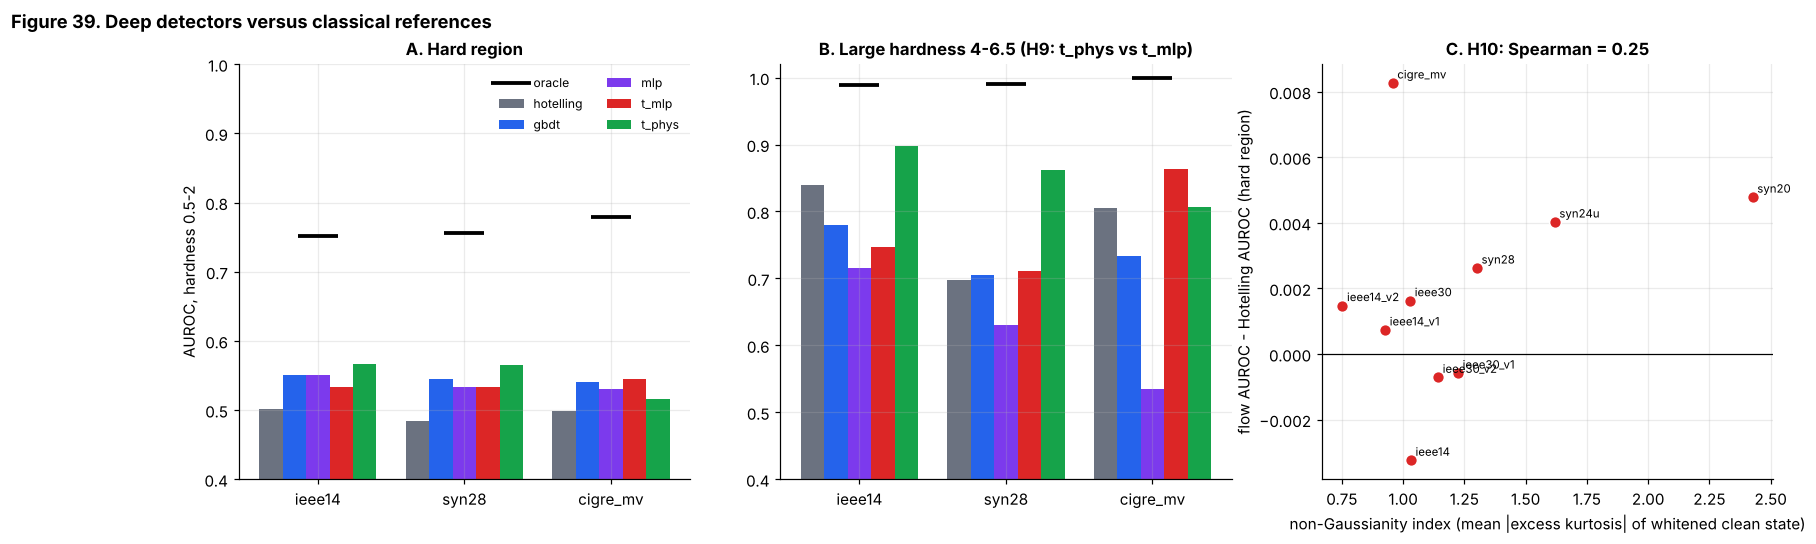

PosixPath('/tmp/w2/proj/figures/fig39_deep.png')

In [68]:
t0 = time.time()
DEEP_GRIDS = [g for g in STUDY_GRIDS + ["cigre_mv"] if g in DS]
DEEP = {}
for name in DEEP_GRIDS:
    sim, cal, d, te = SIMS[name], CAL[name], DS[name], DS[name]["test"]; DEEP[name] = {}
    for seed in range(SIZES["n_budget_seeds"]):
        for mk_ in (make_t_mlp, lambda: make_t_phys(sim)):
            det = mk_().fit(cal, d["train"], seed); s = det.score(cal, te)
            DEEP[name].setdefault(det.name, []).append(dict(bins=auc_by_bin(s, te), hard=small_auc(s, te), large=small_auc(s, te, 4.0, 6.6), overall=overall_auc(s, te)))
    for D in (Hotelling, GBDT, MLP):
        det = D().fit(cal, d["train"], 0) if D is not Hotelling else D().fit(cal, None, 0); s = det.score(cal, te)
        DEEP[name][det.name] = [dict(bins=auc_by_bin(s, te), hard=small_auc(s, te), large=small_auc(s, te, 4.0, 6.6), overall=overall_auc(s, te))]
    DEEP[name]["oracle"] = [dict(bins=oracle_by_bin(cal, te), hard=float(np.nanmean(oracle_by_bin(cal, te, HARD))), large=float(oracle_by_bin(cal, te, np.array([4.0, 6.6]))[0]), overall=np.nan)]
    print(f"{name}: deep detectors done ({time.time()-t0:.0f}s)", flush=True)
rows = []
for name in DEEP_GRIDS:
    for dn, lst in DEEP[name].items():
        rows.append(dict(grid=name, det=dn, hard=np.mean([r["hard"] for r in lst]), large=np.mean([r["large"] for r in lst]), overall=np.nanmean([r["overall"] for r in lst]) if dn != "oracle" else np.nan,
                         params=(sum(p.numel() for p in make_t_mlp().builder(CAL[name], CAL[name].ns + 2).parameters()) if dn == "t_mlp" else
                                 sum(p.numel() for p in PhysNet(CAL[name], SIMS[name].h_tie).parameters()) if dn == "t_phys" else np.nan)))
DPT = pd.DataFrame(rows); print(DPT.pivot(index="det", columns="grid", values="hard").round(3).to_string()); print(DPT.pivot(index="det", columns="grid", values="large").round(3).to_string())
print(DPT[DPT.det.isin(["t_mlp", "t_phys"])][["grid", "det", "params"]].to_string(index=False))
h9 = {g: abs(DPT[(DPT.grid == g) & (DPT.det == "t_phys")].large.values[0] - DPT[(DPT.grid == g) & (DPT.det == "t_mlp")].large.values[0]) for g in DEEP_GRIDS}
H9_val = float(max(h9.values())); H9_pass = bool(H9_val <= 0.02)
print("H9: |t_phys - t_mlp| at hardness 4-6.5 per grid:", {k: round(v, 3) for k, v in h9.items()}, "->", "PASS" if H9_pass else "FAIL")

# ---- flow vs Hotelling, non-Gaussianity ---------------------------------------------------------------------------
FLOW_GRIDS = [g for g in TRAIN_FAMILY + UNSEEN + ZOO if g in DS and CAL[g].ns <= 60]
def ng_index(cal): return float(np.mean(np.abs(st.kurtosis(whiten(cal, cal.X), axis=0))))
FL = []
for g in FLOW_GRIDS:
    cal, te = CAL[g], DS[g]["test"]
    fl = [small_auc(FlowDet().fit(cal, None, s).score(cal, te), te) for s in range(SIZES["n_budget_seeds"])]
    ho = small_auc(Hotelling().score(cal, te), te)
    fl_all = [overall_auc(FlowDet().fit(cal, None, 0).score(cal, te), te)]; ho_all = overall_auc(Hotelling().score(cal, te), te)
    FL.append(dict(grid=g, ns=cal.ns, NG=ng_index(cal), hotelling=ho, flow=float(np.mean(fl)), adv=float(np.mean(fl) - ho), adv_overall=float(fl_all[0] - ho_all)))
    print(f"{g:<11} ns={cal.ns:3d}  non-Gaussianity {FL[-1]['NG']:.2f}  hotelling {ho:.3f}  flow {np.mean(fl):.3f}  adv {np.mean(fl)-ho:+.3f}", flush=True)
FL = pd.DataFrame(FL); rho_ng = float(spearmanr(FL.NG, FL.adv)[0]) if len(FL) > 3 else np.nan
H10_val = dict(spearman=rho_ng, max_adv=float(FL.adv.max())); H10_pass = bool(rho_ng >= 0.5 and FL.adv.max() >= 0.02)
print(f"H10: Spearman(non-Gaussianity, flow advantage) = {rho_ng:.2f}, max advantage {FL.adv.max():+.3f} (overall-AUROC advantage range {FL.adv_overall.min():+.3f} .. {FL.adv_overall.max():+.3f}) -> {'PASS' if H10_pass else 'FAIL'}   [{time.time()-t0:.0f}s]")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.9))
ax = axes[0]; order = ["hotelling", "gbdt", "mlp", "t_mlp", "t_phys"]; cols = [PAL["grey"], PAL["blue"], PAL["purple"], PAL["red"], PAL["green"]]
for k, (dn, c) in enumerate(zip(order, cols)):
    ax.bar(np.arange(len(DEEP_GRIDS)) + (k - 2) * 0.16, [DPT[(DPT.grid == g) & (DPT.det == dn)].hard.values[0] for g in DEEP_GRIDS], 0.16, color=c, label=dn)
ax.plot(np.arange(len(DEEP_GRIDS)), [DPT[(DPT.grid == g) & (DPT.det == "oracle")].hard.values[0] for g in DEEP_GRIDS], "k_", ms=26, mew=2.5, label="oracle")
ax.set_xticks(range(len(DEEP_GRIDS))); ax.set_xticklabels(DEEP_GRIDS); ax.set_ylim(0.4, 1.0); ax.legend(fontsize=8, ncol=2); ax.set_ylabel("AUROC, hardness 0.5-2"); ax.set_title("A. Hard region")
ax = axes[1]
for k, (dn, c) in enumerate(zip(order, cols)):
    ax.bar(np.arange(len(DEEP_GRIDS)) + (k - 2) * 0.16, [DPT[(DPT.grid == g) & (DPT.det == dn)].large.values[0] for g in DEEP_GRIDS], 0.16, color=c)
ax.plot(np.arange(len(DEEP_GRIDS)), [DPT[(DPT.grid == g) & (DPT.det == "oracle")].large.values[0] for g in DEEP_GRIDS], "k_", ms=26, mew=2.5)
ax.set_xticks(range(len(DEEP_GRIDS))); ax.set_xticklabels(DEEP_GRIDS); ax.set_ylim(0.4, 1.02); ax.set_title("B. Large hardness 4-6.5 (H9: t_phys vs t_mlp)")
ax = axes[2]; ax.scatter(FL.NG, FL.adv, s=60, color=PAL["red"], edgecolor="white", zorder=3)
for _, r in FL.iterrows(): ax.annotate(r.grid, (r.NG, r.adv), fontsize=7.5, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("non-Gaussianity index (mean |excess kurtosis| of whitened clean state)"); ax.set_ylabel("flow AUROC - Hotelling AUROC (hard region)")
ax.set_title(f"C. H10: Spearman = {rho_ng:.2f}")
fig.suptitle("Figure 39. Deep detectors versus classical references", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig39_deep")

### 19.4 A gradient-based white-box attacker, and adversarial training (Figure 40)

Part 14's adaptive attacker chose the best of $K$ random directions. Here the same constraint set is searched by **projected gradient descent through the detector itself**. The attacker owns a set of natural windows $A$, fixes hardness $\delta_0$ and damage fraction $\rho$ (so $z=\delta_0(\rho\hat v+\sqrt{1-\rho^2}\,w)$ with $w\perp\hat v$, $\|w\|=1$), and minimises the mean detector logit over $A$ by Adam on an unconstrained vector that is projected onto the constraint set at every step. Three restarts, best kept. Evaluation is on a disjoint set $T$, as in Part 14. The same optimiser attacks Hotelling and the damage-coordinate test (DCT, $|{\hat v}^\top w|$), for which the answer is known in advance (the DCT's score is fixed by $\rho\delta_0$), so they act as controls: if the optimiser "beats" them, it is broken.

**Adversarial training.** `t_mlp_at` is the same network trained with a min-max loss. For every mini-batch, a universal direction is crafted against the *current* network by three gradient steps on the batch's clean windows, and the attacked windows are added to the batch with label 1. The question is whether this recovers the power the gradient attacker takes away, and what it costs against non-adaptive attacks. A network can look robust because the optimiser is weak, so the robustness is judged against the strongest attacker in this notebook, not against the one used in training alone.

ieee14: gradient attacker done (23s)


syn28: gradient attacker done (46s)


attacker     ref  random search  gradient  loss_rs  loss_grad
scorer                                                       
dct        0.619          0.619     0.619   -0.000     -0.000
hotelling  0.550          0.547     0.545    0.003      0.005
t_mlp      0.514          0.427     0.314    0.087      0.199
t_mlp_at   0.729          0.717     0.701    0.012      0.028
t_phys     0.577          0.570     0.562    0.007      0.015
attacker         gradient vs t_mlp (transfer)    ref
scorer                                              
dct                                     0.619  0.619
gbdt (transfer)                         0.489  0.572
hotelling                               0.546  0.550
t_phys                                  0.574  0.577
H30: gradient attacker takes 0.199 AUROC from t_mlp vs 0.087 for random search (extra +0.113); DCT loses -0.000 -> PASS
H31: adversarial training recovers 86% of the lost power (gradient attacker), costs -0.003 AUROC against non-adaptive attacks ->

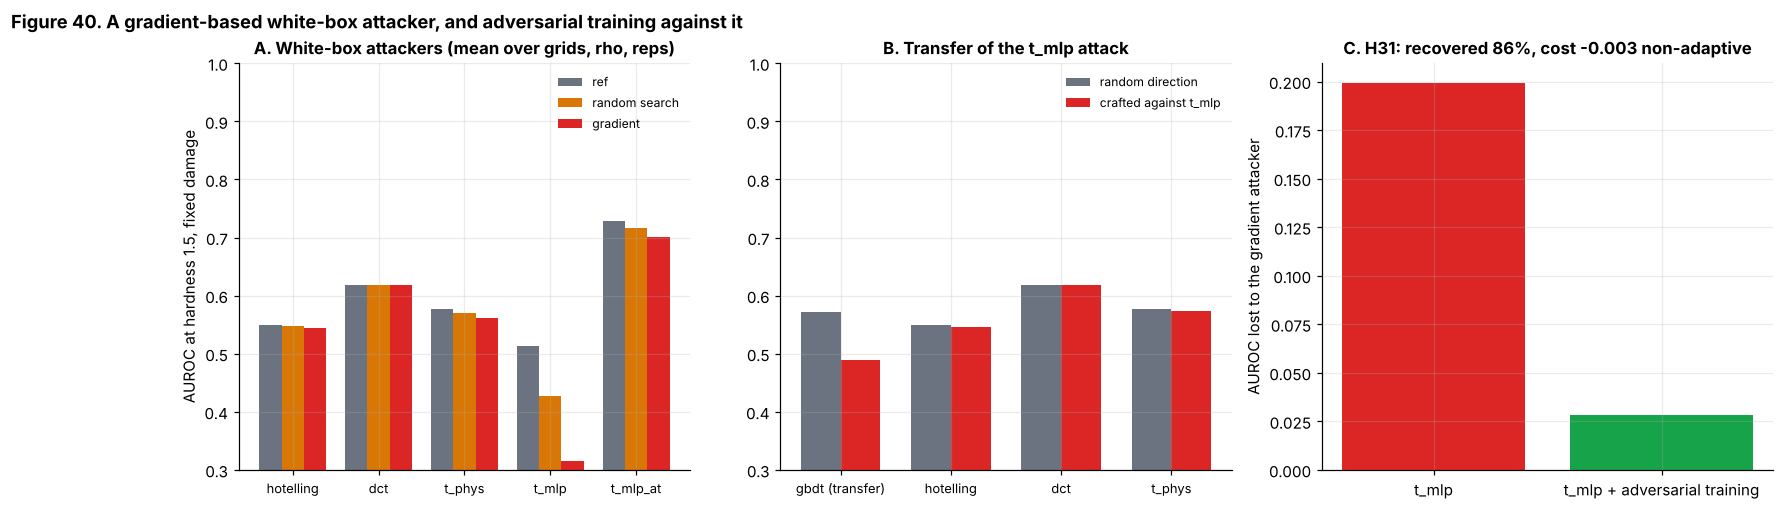

PosixPath('/tmp/w2/proj/figures/fig40_gradient_attacker.png')

In [69]:
GRAD_STEPS, GRAD_RESTARTS = (60, 3) if BUDGET == "full" else (30, 2)

def score_fn_of(det, sim, cal):
    """Differentiable logit/score on the feature tensor [w, zJ, log rmax]."""
    if det == "hotelling": return lambda X: (X[:, :cal.ns] ** 2).sum(1)
    if det == "dct":
        vh = T_((cal.L.T @ sim.h_tie) / np.linalg.norm(cal.L.T @ sim.h_tie)); return lambda X: (X[:, :cal.ns] @ vh).abs()
    return lambda X: det_net[det](X)

def shift_feat(X, z, ns):
    Xs = X.clone(); Xs[:, :ns] = Xs[:, :ns] + z; return Xs

def grad_attack(fn, XA, vhat, delta0, rho, ns, steps, restarts, seed):
    XA_t, vh = T_(XA), T_(vhat); best, best_z = 1e18, None
    for r in range(restarts):
        g = torch.Generator().manual_seed(seed * 31 + r); u = torch.randn(ns, generator=g).to(DEVICE).requires_grad_(True)
        opt = torch.optim.Adam([u], lr=0.15)
        for s in range(steps):
            up = u - (u @ vh) * vh; w = up / (up.norm() + 1e-9); z = delta0 * (rho * vh + float(np.sqrt(1 - rho ** 2)) * w)
            loss = fn(shift_feat(XA_t, z, ns)).mean(); opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            up = u - (u @ vh) * vh; w = up / (up.norm() + 1e-9); z = delta0 * (rho * vh + float(np.sqrt(1 - rho ** 2)) * w); l_ = fn(shift_feat(XA_t, z, ns)).mean().item()
        if l_ < best: best, best_z = l_, z.detach()
    return best_z

def make_adv(vhat, ns, steps=3):
    vh = T_(vhat); rng_ = np.random.default_rng(4242)
    def adv(net, Xb, yb):
        cm = yb == 0; Xc = Xb[cm]
        if len(Xc) < 8: return Xb[:0], yb[:0]
        rho = float(rng_.choice(RHOS)); d0 = float(rng_.uniform(1.0, 2.5)); was = net.training; net.eval()
        u = torch.randn(ns, device=DEVICE).requires_grad_(True)
        for _ in range(steps):
            up = u - (u @ vh) * vh; w = up / (up.norm() + 1e-9); z = d0 * (rho * vh + float(np.sqrt(1 - rho ** 2)) * w)
            loss = net(shift_feat(Xc, z, ns)).mean(); g_, = torch.autograd.grad(loss, u); u = (u - 0.5 * g_ / (g_.norm() + 1e-9) * (u.norm() + 1e-9)).detach().requires_grad_(True)
        up = u - (u @ vh) * vh; w = up / (up.norm() + 1e-9); z = d0 * (rho * vh + float(np.sqrt(1 - rho ** 2)) * w)
        net.train(was); return shift_feat(Xc, z, ns).detach(), torch.ones(len(Xc), device=DEVICE)
    return adv

GA = []; t0 = time.time(); det_net = {}
for name in STUDY_GRIDS:
    sim, cal, te = SIMS[name], CAL[name], DS[name]["test"]; ns = cal.ns
    v = cal.L.T @ sim.h_tie; vhat = (v / np.linalg.norm(v)).astype(np.float32)
    nat = {k: x[(te["kind"] == "natural") & (te["label"] == 0)] for k, x in te.items()}
    dets = {"t_mlp": make_t_mlp().fit(cal, DS[name]["train"], 0), "t_phys": make_t_phys(sim).fit(cal, DS[name]["train"], 0),
            "t_mlp_at": TorchDet("t_mlp_at", lambda c, dim: MLPNet(dim), adv=make_adv(vhat, ns)).fit(cal, DS[name]["train"], 0)}
    det_net = {k: d_.net for k, d_ in dets.items()}
    gb = GBDT().fit(cal, DS[name]["train"], 0)
    # non-adaptive hard-region AUROC of each network (cost of adversarial training)
    non_adapt = {k: small_auc(d_.score(cal, te), te) for k, d_ in dets.items()}
    ev = {"t_mlp": dets["t_mlp"], "t_phys": dets["t_phys"], "t_mlp_at": dets["t_mlp_at"], "hotelling": Hotelling(), "dct": None, "gbdt (transfer)": gb}
    def det_score(k, d_):
        if k == "dct": return np.abs(whiten(cal, d_["x"]) @ vhat)
        return ev[k].score(cal, d_)
    for rho_ in RHOS:
        for r in range(R_ADV):
            rng = np.random.default_rng(100 * r + int(10 * rho_)); perm = rng.permutation(len(nat["x"])); h_ = len(perm) // 2
            A = {k: x[perm[:h_]] for k, x in nat.items()}; T = {k: x[perm[h_:]] for k, x in nat.items()}
            XA, XT = tfeat(cal, A), tfeat(cal, T)
            Zof = lambda W: DELTA0 * (rho_ * vhat[None] + np.sqrt(1 - rho_ ** 2) * W)
            Wk = rand_perp(vhat, K_CAND, rng); Wr = rand_perp(vhat, N_REF, rng)
            def feats_att(Z):          # attacked windows of T for each direction in Z: returns dict x-array stacked
                Xs = np.repeat(XT[None], len(Z), 0).copy(); Xs[:, :, :ns] += Z[:, None, :]; return Xs
            def score_stack(k, Xs):    # Xs (K, nT, dim)
                K_, nT_, _ = Xs.shape
                if k in ("hotelling",): return (Xs[:, :, :ns] ** 2).sum(-1)
                if k == "dct": return np.abs(Xs[:, :, :ns] @ vhat)
                if k == "gbdt (transfer)":
                    d_ = dict(x=(Xs[:, :, :ns].reshape(K_ * nT_, ns) @ cal.L.T) + cal.mu, J=np.tile(T["J"], K_), rmax=np.tile(T["rmax"], K_))
                    return gb.score(cal, d_).reshape(K_, nT_)
                with torch.no_grad(): return dets[k].net(T_(Xs.reshape(K_ * nT_, -1))).cpu().numpy().reshape(K_, nT_)
            clean_sc = {k: (score_stack(k, XT[None])[0]) for k in ev}
            def auc_dir(k, z):
                return auc_pair(score_stack(k, feats_att(z[None]))[0], clean_sc[k])
            Zref, Zk = Zof(Wr), Zof(Wk)
            crafted = {}
            for k in ("t_mlp", "t_phys", "t_mlp_at", "hotelling", "dct"):
                fn = score_fn_of(k, sim, cal) if k in ("hotelling", "dct") else (lambda X, k=k: det_net[k](X))
                # random search: best of K by mean score on A (same as Part 14)
                XAk = np.repeat(XA[None], len(Zk), 0).copy(); XAk[:, :, :ns] += Zk[:, None, :]
                if k in ("hotelling",): sA = (XAk[:, :, :ns] ** 2).sum(-1).mean(1)
                elif k == "dct": sA = np.abs(XAk[:, :, :ns] @ vhat).mean(1)
                else:
                    with torch.no_grad(): sA = dets[k].net(T_(XAk.reshape(len(Zk) * len(XA), -1))).cpu().numpy().reshape(len(Zk), -1).mean(1)
                z_rs = Zk[int(np.argmin(sA))]
                z_gr = grad_attack(fn, XA, vhat, DELTA0, rho_, ns, GRAD_STEPS, GRAD_RESTARTS, seed=r).cpu().numpy(); crafted[k] = z_gr
                ref = float(np.mean([auc_dir(k, z) for z in Zref])); GA.append(dict(grid=name, rho=rho_, rep=r, target=k, scorer=k, attacker="ref", auc=ref))
                GA.append(dict(grid=name, rho=rho_, rep=r, target=k, scorer=k, attacker="random search", auc=auc_dir(k, z_rs)))
                GA.append(dict(grid=name, rho=rho_, rep=r, target=k, scorer=k, attacker="gradient", auc=auc_dir(k, z_gr)))
            for sc_ in ("gbdt (transfer)", "hotelling", "dct", "t_phys"):          # transfer: attack crafted against t_mlp
                GA.append(dict(grid=name, rho=rho_, rep=r, target="t_mlp", scorer=sc_, attacker="gradient vs t_mlp (transfer)", auc=auc_dir(sc_, crafted["t_mlp"])))
                GA.append(dict(grid=name, rho=rho_, rep=r, target="t_mlp", scorer=sc_, attacker="ref", auc=float(np.mean([auc_dir(sc_, z) for z in Zref]))))
    GA.append(dict(grid=name, rho=np.nan, rep=-1, target="non_adaptive", scorer="t_mlp", attacker="hard-region", auc=non_adapt["t_mlp"]))
    GA.append(dict(grid=name, rho=np.nan, rep=-1, target="non_adaptive", scorer="t_mlp_at", attacker="hard-region", auc=non_adapt["t_mlp_at"]))
    print(f"{name}: gradient attacker done ({time.time()-t0:.0f}s)", flush=True)
GA = pd.DataFrame(GA)
own = GA[(GA.target == GA.scorer) & GA.attacker.isin(["ref", "random search", "gradient"])]
GTAB = own.groupby(["scorer", "attacker"]).auc.mean().unstack()[["ref", "random search", "gradient"]]; GTAB["loss_rs"] = GTAB["ref"] - GTAB["random search"]; GTAB["loss_grad"] = GTAB["ref"] - GTAB["gradient"]
print(GTAB.round(3).to_string())
print(GA[GA.attacker.isin(["gradient vs t_mlp (transfer)", "ref"]) & (GA.target == "t_mlp") & (GA.scorer != "t_mlp")].groupby(["scorer", "attacker"]).auc.mean().unstack().round(3).to_string())
extra = GTAB.loc["t_mlp", "loss_grad"] - GTAB.loc["t_mlp", "loss_rs"]; dct_loss = float(GTAB.loc["dct", "loss_grad"])
H30_val = dict(extra_loss=float(extra), dct_loss=dct_loss); H30_pass = bool(extra >= 0.05 and dct_loss <= 0.01)
print(f"H30: gradient attacker takes {GTAB.loc['t_mlp','loss_grad']:.3f} AUROC from t_mlp vs {GTAB.loc['t_mlp','loss_rs']:.3f} for random search (extra {extra:+.3f}); DCT loses {dct_loss:+.3f} -> {'PASS' if H30_pass else 'FAIL'}")
rec = (GTAB.loc["t_mlp", "loss_grad"] - GTAB.loc["t_mlp_at", "loss_grad"]) / max(1e-9, GTAB.loc["t_mlp", "loss_grad"])
na = GA[GA.target == "non_adaptive"].groupby("scorer").auc.mean(); cost = float(na["t_mlp"] - na["t_mlp_at"])
H31_val = dict(recovered_share=float(rec), cost_nonadaptive=cost); H31_pass = bool(rec >= 0.5 and cost <= 0.03)
print(f"H31: adversarial training recovers {rec:.0%} of the lost power (gradient attacker), costs {cost:+.3f} AUROC against non-adaptive attacks -> {'PASS' if H31_pass else 'FAIL'}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]; order = ["hotelling", "dct", "t_phys", "t_mlp", "t_mlp_at"]; w = 0.26
for k, (atk, c) in enumerate([("ref", PAL["grey"]), ("random search", PAL["amber"]), ("gradient", PAL["red"])]):
    ax.bar(np.arange(len(order)) + (k - 1) * w, [GTAB.loc[o, atk] for o in order], w, color=c, label=atk)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, fontsize=8.5); ax.set_ylim(0.3, 1.0); ax.set_ylabel(f"AUROC at hardness {DELTA0}, fixed damage"); ax.legend(fontsize=8); ax.set_title("A. White-box attackers (mean over grids, rho, reps)")
ax = axes[1]
tr_ = GA[GA.attacker.isin(["gradient vs t_mlp (transfer)", "ref"]) & (GA.target == "t_mlp") & (GA.scorer != "t_mlp")].groupby(["scorer", "attacker"]).auc.mean().unstack()
tr_ = tr_.loc[["gbdt (transfer)", "hotelling", "dct", "t_phys"]]; ax.bar(np.arange(len(tr_)) - 0.18, tr_["ref"], 0.36, color=PAL["grey"], label="random direction"); ax.bar(np.arange(len(tr_)) + 0.18, tr_["gradient vs t_mlp (transfer)"], 0.36, color=PAL["red"], label="crafted against t_mlp")
ax.set_xticks(range(len(tr_))); ax.set_xticklabels(tr_.index, fontsize=8.5); ax.set_ylim(0.3, 1.0); ax.legend(fontsize=8); ax.set_title("B. Transfer of the t_mlp attack")
ax = axes[2]; ax.bar([0, 1], [GTAB.loc["t_mlp", "loss_grad"], GTAB.loc["t_mlp_at", "loss_grad"]], color=[PAL["red"], PAL["green"]])
ax.set_xticks([0, 1]); ax.set_xticklabels(["t_mlp", "t_mlp + adversarial training"]); ax.set_ylabel("AUROC lost to the gradient attacker"); ax.set_title(f"C. H31: recovered {rec:.0%}, cost {cost:+.3f} non-adaptive")
fig.suptitle("Figure 40. A gradient-based white-box attacker, and adversarial training against it", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig40_gradient_attacker")

## Part 20. Calibrated detector ensembles, and how far a ranking can be trusted across environments

### 20.1 The problem the earlier parts leave open

No single detector in this notebook wins everywhere. The damage-coordinate test is nearly perfect on tie-line attacks and blind to sparse ones; the scan statistic is the opposite; Hotelling is a mediocre generalist; learned detectors are unreliable. An operator does not know which attack family will arrive. The right figure of merit is then not the average AUROC over a chosen attack mix but the **worst-family AUROC**: how badly can the system be beaten by the family the defender is weakest against?

**Ensemble.** Each detector's score is converted to a conformal p-value against a *fresh* set of natural clean windows that none of the detectors was trained on, $p_k(x)=\frac{1+\#\{j:s_k(c_j)\ge s_k(x)\}}{n+1}$. The p-values are combined by the **Cauchy combination** $T=\frac1K\sum_k\tan\{(0.5-p_k)\pi\}$ (Liu and Xie, 2020, *JASA* 115:393-402), whose tail is valid under arbitrary dependence between the $p_k$, which matters because the detectors look at the same window. For comparison, `min_p` takes the smallest p-value (a Bonferroni test).

**What is new here and what is not.** Combining p-values is classical; the Cauchy rule is used in genetics and in recent power-system anomaly work on combined tests. We are not proposing it as a method. The question is empirical and specific to this benchmark: does a calibrated combination of *complementary* detectors beat the best single detector on the worst attack family, and is it still a valid test (false-alarm rate on natural clean windows near its nominal level)?

### 20.2 Pre-registered, before running

* **H32**: on both study grids, the best Cauchy ensemble has a worst-family AUROC (hardness 0.5 to 2, six families: three direction kinds and three attacker models) at least 0.02 above the best single detector's worst-family AUROC.
* **H33** (validity): at nominal level 1%, the ensemble's false-alarm rate on natural clean test windows lies in $[0.5\%,2\%]$.
* **H34** (cross-environment ranking): across the seven zoo environments, the mean pairwise Spearman correlation between detector rankings is at least 0.7, **and** the split-half reliability of a ranking inside an environment is at least 0.8. If reliability fails, a failed correlation says nothing, and the result is reported as "not interpretable".

ieee14: ensemble built (6s)


              sparse  dense    lfc  linear     ac  partial  worst   mean
hotelling      0.510  0.478  0.500   0.497  0.506    0.507  0.478  0.500
dct            0.479  0.518  0.630   0.521  0.522    0.474  0.474  0.524
scan           0.505  0.460  0.452   0.480  0.498    0.465  0.452  0.477
gbdt_sum       0.541  0.481  0.513   0.514  0.522    0.571  0.481  0.524
gbdt_struct    0.548  0.484  0.630   0.535  0.572    0.539  0.484  0.551
t_mlp          0.535  0.549  0.517   0.526  0.539    0.553  0.517  0.536
t_phys         0.571  0.565  0.576   0.555  0.597    0.541  0.541  0.568
t_flow         0.509  0.482  0.496   0.496  0.505    0.511  0.482  0.500
cauchy_all     0.563  0.547  0.609   0.548  0.592    0.571  0.547  0.572
cauchy_unsup   0.490  0.473  0.538   0.481  0.514    0.489  0.473  0.497
cauchy_cheap   0.482  0.469  0.541   0.477  0.510    0.481  0.469  0.493
min_p          0.465  0.466  0.566   0.481  0.495    0.460  0.460  0.489
oracle by family: {'sparse': np.float64(0.724), 'de

syn28: ensemble built (14s)


              sparse  dense    lfc  linear     ac  partial  worst   mean
hotelling      0.481  0.490  0.493   0.501  0.478    0.451  0.451  0.482
dct            0.548  0.576  0.546   0.533  0.560    0.606  0.533  0.561
scan           0.483  0.464  0.453   0.490  0.458    0.470  0.453  0.470
gbdt_sum       0.530  0.525  0.525   0.541  0.502    0.557  0.502  0.530
gbdt_struct    0.547  0.569  0.596   0.567  0.541    0.576  0.541  0.566
t_mlp          0.536  0.554  0.554   0.548  0.525    0.573  0.525  0.548
t_phys         0.571  0.546  0.557   0.569  0.553    0.572  0.546  0.561
t_flow         0.482  0.492  0.510   0.502  0.482    0.457  0.457  0.487
cauchy_all     0.574  0.583  0.590   0.595  0.556    0.585  0.556  0.580
cauchy_unsup   0.500  0.500  0.518   0.506  0.496    0.505  0.496  0.504
cauchy_cheap   0.504  0.503  0.513   0.507  0.498    0.514  0.498  0.506
min_p          0.499  0.530  0.522   0.517  0.502    0.503  0.499  0.512
oracle by family: {'sparse': np.float64(0.776), 'de

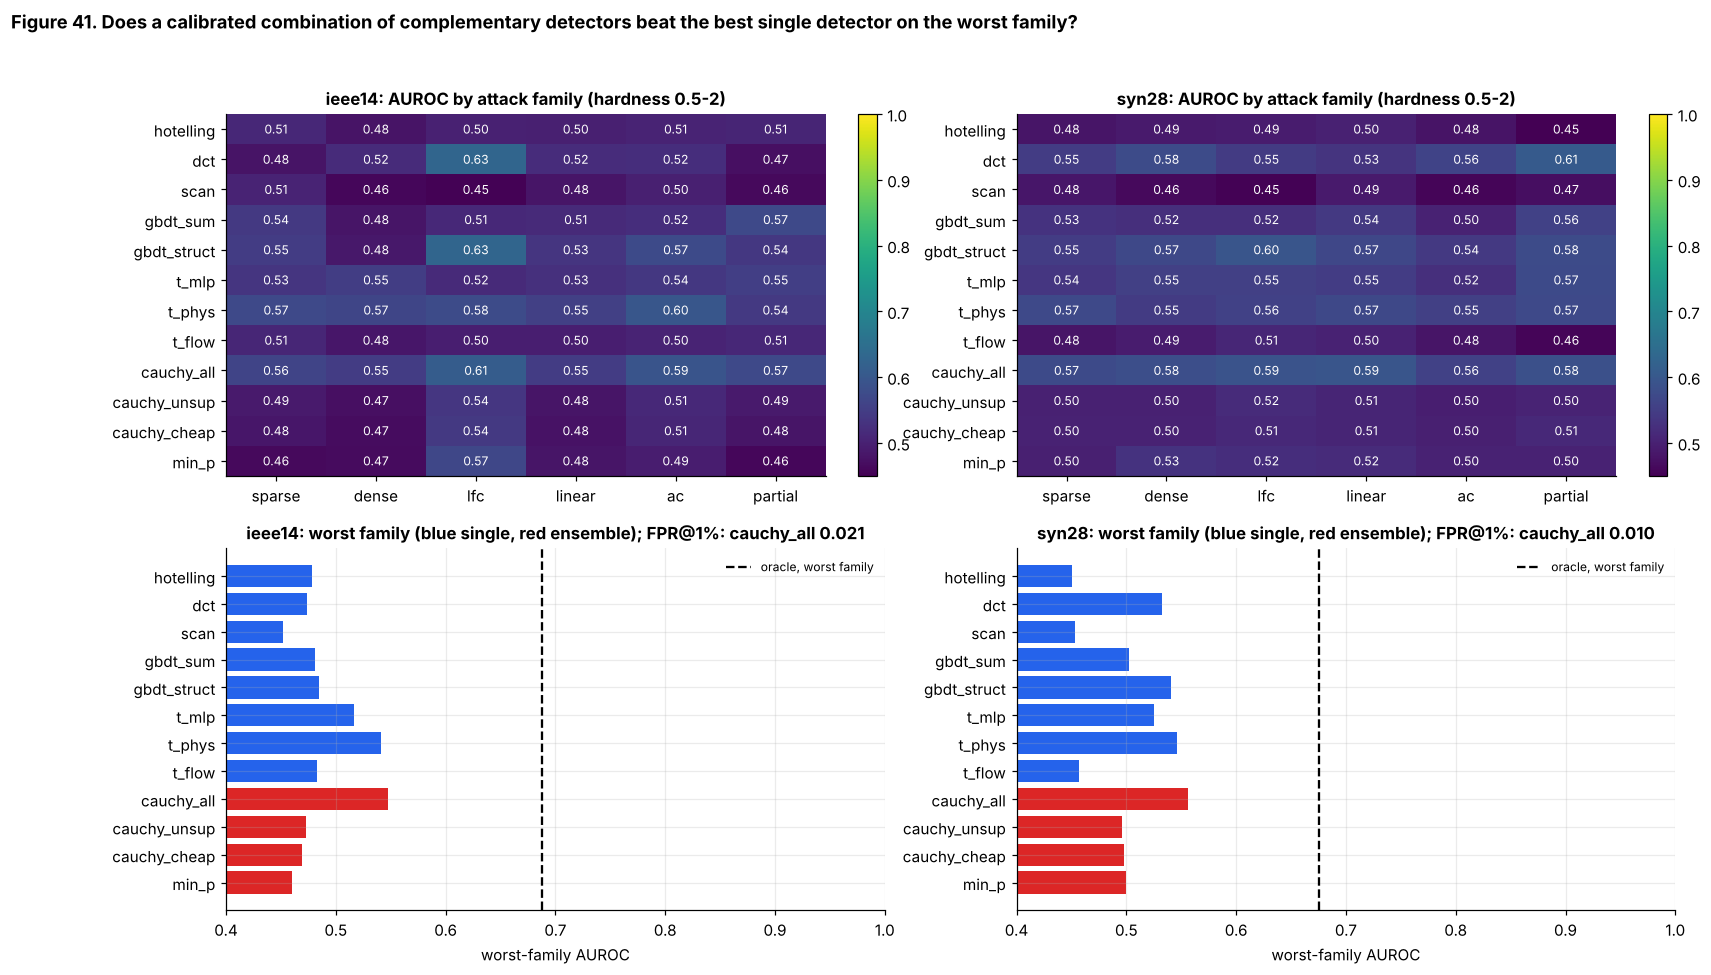

PosixPath('/tmp/w2/proj/figures/fig41_ensemble.png')

In [70]:
N_CC = 900 if BUDGET == "full" else 300
FAM6 = [("sparse", None), ("dense", None), ("lfc", None), ("all", "linear"), ("all", "ac"), ("all", "partial")]
FAM6_NAMES = ["sparse", "dense", "lfc", "linear", "ac", "partial"]

def cauchy_T(P): return np.mean(np.tan((0.5 - P) * np.pi), axis=1)
def conf_p(s_cal, s):
    """Conformal p-value of score s against clean calibration scores (large score = anomalous)."""
    srt = np.sort(s_cal); return (1 + (len(srt) - np.searchsorted(srt, s, side="left"))) / (len(srt) + 1)
def conf_p_loo(s_cal):
    """Leave-one-out p-values of the calibration windows themselves, so that their combined statistic is exchangeable with a test window's."""
    srt = np.sort(s_cal); ge = len(srt) - np.searchsorted(srt, s_cal, side="left")      # number of calibration scores >= s_i, including i itself
    return ge / len(srt)

ENS = {}; t0 = time.time()
for name in STUDY_GRIDS:
    sim, cal, te, kit = SIMS[name], CAL[name], DS[name]["test"], KITS[name]
    cc = gen_clean_block(sim, cal, rng_for("conf_cal", *[ord(c) for c in name]), N_CC, hn=(0.0, 0.0))         # natural clean windows, never used for training
    sc_te, sc_cc = {}, {}
    def put(k, f):
        sc_te[k], sc_cc[k] = f(te), f(cc)
    put("hotelling", lambda d: Hotelling().score(cal, d))
    put("dct", lambda d: struct_scores(kit, d)["dct"]); put("scan", lambda d: struct_scores(kit, d)["scan"])
    put("gbdt_sum", lambda d, m=STRUCT_MODELS[name]["gbdt_sum"]: m.score(cal, d)); put("gbdt_struct", lambda d, m=STRUCT_MODELS[name]["gbdt_struct"]: m.score(cal, d))
    dm = make_t_mlp().fit(cal, DS[name]["train"], 0); dp = make_t_phys(sim).fit(cal, DS[name]["train"], 0)
    put("t_mlp", lambda d: dm.score(cal, d)); put("t_phys", lambda d: dp.score(cal, d))
    if cal.ns <= 60: fl = FlowDet().fit(cal, None, 0); put("t_flow", lambda d: fl.score(cal, d))
    ks = list(sc_te)
    P_te = {k: conf_p(sc_cc[k], sc_te[k]) for k in ks}
    def comb(sel): return cauchy_T(np.column_stack([P_te[k] for k in sel]))
    unsup = [k for k in ("hotelling", "dct", "scan", "t_flow") if k in ks]
    sc_te["cauchy_all"] = comb(ks); sc_te["cauchy_unsup"] = comb(unsup); sc_te["cauchy_cheap"] = comb(["hotelling", "dct", "scan"])
    sc_te["min_p"] = -np.min(np.column_stack([P_te[k] for k in ks]), axis=1)
    fam = pd.DataFrame({dn: [reg_auc(s, te, kind=k, model=m) for k, m in FAM6] for dn, s in sc_te.items()}, index=FAM6_NAMES).T
    fam["worst"] = fam.min(1); fam["mean"] = fam[FAM6_NAMES].mean(1)
    orc = [reg_oracle(cal, te, kind=k, model=m) for k, m in FAM6]
    ENS[name] = dict(fam=fam, oracle=orc, scores=sc_te, ks=ks)
    # validity: false alarms of the combined p-value test at level 1% on natural clean test windows
    nat = (te["kind"] == "natural") & (te["label"] == 0)
    for ens_name, sel in (("cauchy_all", ks), ("cauchy_cheap", ["hotelling", "dct", "scan"])):
        thr = np.quantile(cauchy_T(np.column_stack([conf_p_loo(sc_cc[k]) for k in sel])), 0.99)    # threshold from calibration clean windows only
        ENS[name].setdefault("fpr", {})[ens_name] = float(np.mean(cauchy_T(np.column_stack([P_te[k][nat] for k in sel])) > thr))
    print(f"{name}: ensemble built ({time.time()-t0:.0f}s)", flush=True)
    print(fam.round(3).to_string()); print("oracle by family:", dict(zip(FAM6_NAMES, np.round(orc, 3))))

singles = ["hotelling", "dct", "scan", "gbdt_sum", "gbdt_struct", "t_mlp", "t_phys", "t_flow"]
h32 = {}
for name in STUDY_GRIDS:
    f_ = ENS[name]["fam"]; best_single = f_.loc[[s for s in singles if s in f_.index], "worst"].max()
    best_ens = f_.loc[["cauchy_all", "cauchy_unsup", "cauchy_cheap", "min_p"], "worst"].max()
    h32[name] = dict(best_single=float(best_single), best_single_name=f_.loc[[s for s in singles if s in f_.index], "worst"].idxmax(),
                     best_ensemble=float(best_ens), best_ensemble_name=f_.loc[["cauchy_all", "cauchy_unsup", "cauchy_cheap", "min_p"], "worst"].idxmax(), margin=float(best_ens - best_single))
H32_pass = bool(all(v["margin"] >= 0.02 for v in h32.values())); print("H32:", {k: {a: (round(b, 3) if isinstance(b, float) else b) for a, b in v.items()} for k, v in h32.items()}, "->", "PASS" if H32_pass else "FAIL")
fpr_all = [v for n in STUDY_GRIDS for v in [ENS[n]["fpr"]["cauchy_all"], ENS[n]["fpr"]["cauchy_cheap"]]]
H33_pass = bool(all(0.005 <= f <= 0.02 for f in fpr_all)); print("H33: ensemble FPR at nominal 1% on natural clean test windows:", {n: {k: round(v, 4) for k, v in ENS[n]["fpr"].items()} for n in STUDY_GRIDS}, "->", "PASS" if H33_pass else "FAIL")

fig, axes = plt.subplots(2, 2, figsize=(17, 9.4))
for j, name in enumerate(STUDY_GRIDS):
    f_ = ENS[name]["fam"]; rows_ = [r for r in singles if r in f_.index] + ["cauchy_all", "cauchy_unsup", "cauchy_cheap", "min_p"]
    ax = axes[0, j]; M_ = f_.loc[rows_, FAM6_NAMES].values; im = ax.imshow(M_, cmap="viridis", vmin=0.45, vmax=1.0, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(6)); ax.set_xticklabels(FAM6_NAMES); ax.set_yticks(range(len(rows_))); ax.set_yticklabels(rows_)
    for a in range(M_.shape[0]):
        for b in range(6): ax.text(b, a, f"{M_[a, b]:.2f}", ha="center", va="center", color="w" if M_[a, b] < 0.75 else "k", fontsize=8)
    ax.set_title(f"{name}: AUROC by attack family (hardness 0.5-2)"); plt.colorbar(im, ax=ax, fraction=0.04)
    ax = axes[1, j]; v = f_.loc[rows_, "worst"]; colr = [PAL["blue"] if r in singles else PAL["red"] for r in rows_]
    ax.barh(range(len(rows_)), v.values, color=colr); ax.set_yticks(range(len(rows_))); ax.set_yticklabels(rows_); ax.invert_yaxis()
    ax.axvline(min(ENS[name]["oracle"]), color="k", ls="--", label="oracle, worst family"); ax.set_xlim(0.4, 1.0); ax.set_xlabel("worst-family AUROC"); ax.legend(fontsize=8)
    ax.set_title(f"{name}: worst family (blue single, red ensemble); FPR@1%: cauchy_all {ENS[name]['fpr']['cauchy_all']:.3f}")
fig.suptitle("Figure 41. Does a calibrated combination of complementary detectors beat the best single detector on the worst family?", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig41_ensemble")

### 20.3 How far can a detector ranking be trusted across environments? (Figure 42)

Part 17 ran the same detectors on seven environments. If the ranking of detectors were stable across environments, a result on one grid would predict others, and a benchmark on a few grids would be enough. Two quantities decide that, and both are computed from the zoo test sets of Part 17: the **between-environment** agreement (mean pairwise Spearman correlation of the detector orderings) and the **within-environment reliability** (the same ordering computed on two random halves of one environment's test windows). Between-environment agreement is only interpretable when reliability is high; with AUROCs this close to chance, noise can easily dominate it.

H34: mean pairwise Spearman between environments 0.59; split-half reliability inside an environment 0.63 -> NOT INTERPRETABLE (reliability < 0.8)
            states  oracle  best_AUROC  closure_of_oracle_gap
case118        235   0.701       0.567                  0.334
hv_mixed       127   0.870       0.767                  0.723
cigre_mv        35   0.779       0.602                  0.367
oberrhein      141   0.875       0.689                  0.503
mv_rural       201   0.835       0.596                  0.286
mv_semiurb     245   0.834       0.560                  0.179
mv_comm        221   0.823       0.579                  0.244
Spearman(states, closure): -0.79


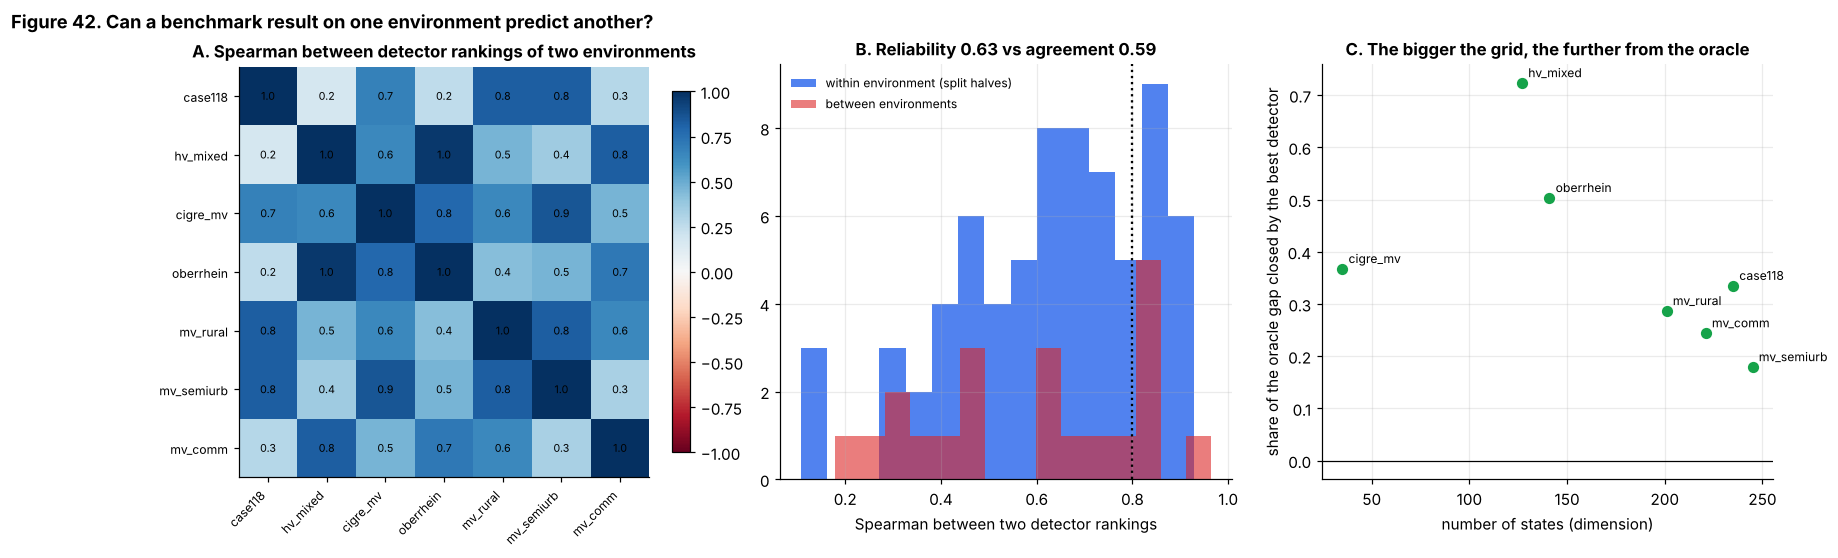

PosixPath('/tmp/w2/proj/figures/fig42_cross_env.png')

In [71]:
DETS_Z = ["chi2", "hotelling", "pca_recon", "iforest", "gbdt", "mlp", "gbdt_sum"]
def half_auc(name, half, seed):
    te = DS_Z[name]["test"]; rng = np.random.default_rng(seed); ia, ic = np.where(te["label"] == 1)[0], np.where(te["label"] == 0)[0]
    pa, pc = rng.permutation(ia), rng.permutation(ic); sel = np.r_[pa[half::2], pc[half::2]]
    sub = {k: v[sel] for k, v in te.items()}
    return [small_auc(ZSC[name][dn][sel], sub) for dn in DETS_Z]
REL, PAIR = [], []
for name in ZOO:
    for seed in range(10):
        a, b = half_auc(name, 0, seed), half_auc(name, 1, seed); REL.append(spearmanr(a, b)[0])
V = ZR.loc[ZOO, DETS_Z].values
for i in range(len(ZOO)):
    for j in range(i + 1, len(ZOO)): PAIR.append(spearmanr(V[i], V[j])[0])
H34_rel, H34_pair = float(np.nanmean(REL)), float(np.nanmean(PAIR)); H34_pass = bool(H34_pair >= 0.7 and H34_rel >= 0.8)
H34_status = "PASS" if H34_pass else ("NOT INTERPRETABLE (reliability < 0.8)" if H34_rel < 0.8 else "FAIL")
print(f"H34: mean pairwise Spearman between environments {H34_pair:.2f}; split-half reliability inside an environment {H34_rel:.2f} -> {H34_status}")
best_close = ((ZR[DETS_Z].max(1) - 0.5) / (ZR["oracle"] - 0.5)).rename("best_detector_closure")
cl = pd.DataFrame({"states": [CAL[n].ns for n in ZOO], "oracle": ZR.loc[ZOO, "oracle"].values, "best_AUROC": ZR.loc[ZOO, DETS_Z].max(1).values, "closure_of_oracle_gap": best_close.loc[ZOO].values}, index=ZOO)
print(cl.round(3).to_string()); print("Spearman(states, closure):", round(float(spearmanr(cl.states, cl.closure_of_oracle_gap)[0]), 2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.9))
ax = axes[0]; C = np.array([[spearmanr(V[i], V[j])[0] for j in range(len(ZOO))] for i in range(len(ZOO))]); im = ax.imshow(C, vmin=-1, vmax=1, cmap="RdBu"); ax.grid(False)
ax.set_xticks(range(len(ZOO))); ax.set_xticklabels(ZOO, rotation=45, ha="right", fontsize=8); ax.set_yticks(range(len(ZOO))); ax.set_yticklabels(ZOO, fontsize=8)
for i in range(len(ZOO)):
    for j in range(len(ZOO)): ax.text(j, i, f"{C[i, j]:.1f}", ha="center", va="center", fontsize=7)
ax.set_title("A. Spearman between detector rankings of two environments"); plt.colorbar(im, ax=ax, fraction=0.04)
ax = axes[1]; ax.hist(REL, bins=15, color=PAL["blue"], alpha=0.8, label="within environment (split halves)"); ax.hist(PAIR, bins=15, color=PAL["red"], alpha=0.6, label="between environments")
ax.axvline(0.8, color="k", ls=":"); ax.set_xlabel("Spearman between two detector rankings"); ax.legend(fontsize=8); ax.set_title(f"B. Reliability {H34_rel:.2f} vs agreement {H34_pair:.2f}")
ax = axes[2]; ax.scatter(cl.states, cl.closure_of_oracle_gap, s=70, color=PAL["green"], edgecolor="white", zorder=3)
for n_, r in cl.iterrows(): ax.annotate(n_, (r.states, r.closure_of_oracle_gap), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("number of states (dimension)"); ax.set_ylabel("share of the oracle gap closed by the best detector"); ax.axhline(0, color="k", lw=0.8); ax.set_title("C. The bigger the grid, the further from the oracle")
fig.suptitle("Figure 42. Can a benchmark result on one environment predict another?", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig42_cross_env")

## Part 21. Hypothesis scorecard and export

Every hypothesis is evaluated by a rule written down in Part 1.3, applied to numbers already computed above. Nothing is re-tuned here. The verdict vocabulary is `SUPPORTED`, `NOT SUPPORTED`, `NOT_RUN`. A hypothesis can also be `SUPPORTED (caveat)` where the rule is met but the note column says what the rule does not establish.

H19 diagnostic, natural-only negatives: {'ieee14': {'dct': np.float64(0.629), 'oracle': np.float64(0.805), 'gbdt_struct': np.float64(0.606)}, 'syn28': {'dct': np.float64(0.543), 'oracle': np.float64(0.781), 'gbdt_struct': np.float64(0.567)}}
H19 diagnostic, exact-model attacker only: {'ieee14': {'dct': np.float64(0.673), 'oracle': np.float64(0.761)}, 'syn28': {'dct': np.float64(0.596), 'oracle': np.float64(0.733)}}
hyp            verdict                                                                                                                                                                                            evidence
 H1          SUPPORTED                                                                                                                     best learned/deep 0.9989 vs best trivial 0.9978; gap +0.0011 (threshold < 0.01)
 H2 SUPPORTED (caveat)                                                                                         ieee14: gap@1800=0.231, gap@300=

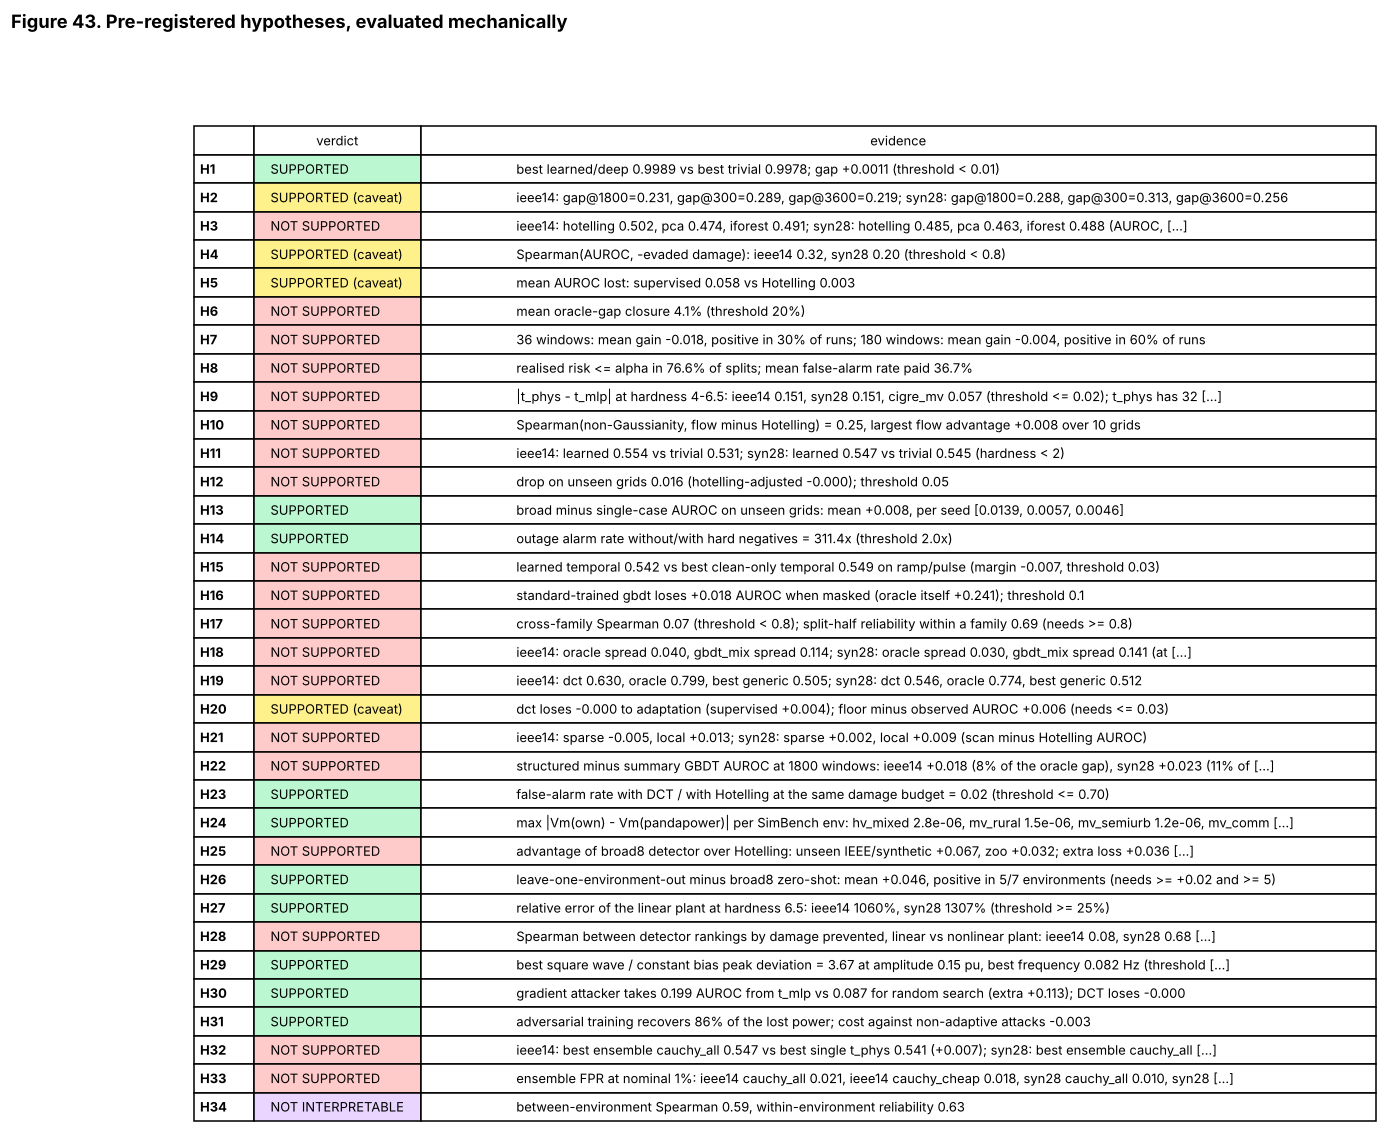

{'NOT SUPPORTED': 19, 'SUPPORTED': 10, 'SUPPORTED (caveat)': 4, 'NOT INTERPRETABLE': 1}


In [72]:
def verdict(ok, caveat=None):
    if ok is None: return "NOT_RUN"
    if ok == "NI": return "NOT INTERPRETABLE"
    return ("SUPPORTED" + (" (caveat)" if caveat else "")) if ok else "NOT SUPPORTED"

score_rows = []
def add(h, ok, evidence, note="", caveat=False):
    score_rows.append(dict(hyp=h, verdict=verdict(ok, caveat), evidence=evidence, note=note or HYPOTHESES[h][:0]))

# H1: trivial vs deep on SCEPTRE
if HAS_SCEPTRE:
    tv = max(audit["sceptre"]["triv"].values()); rep = audit["sceptre"]["reported"]
    dv = max(max(audit["sceptre"]["deep"].values()), max(rep.values()) if rep else 0)
    add("H1", (dv - tv) < THRESH["h1_gap"], f"best learned/deep {dv:.4f} vs best trivial {tv:.4f}; gap {dv-tv:+.4f} (threshold < {THRESH['h1_gap']})",
        "Applies to the SCEPTRE case14 split only. Says the task is shortcut-solvable, not that SCEPTRE's models are wrong.")
else:
    add("H1", None, "SCEPTRE reference data not found")

# H2: gap to oracle at hardness 1-4, shrinking with data
ok2 = all(h2[g]["gap_ref"] >= THRESH["h2_gap"] and h2[g]["gap_large"] < h2[g]["gap_small"] for g in STUDY_GRIDS)
add("H2", ok2, "; ".join(f"{g}: gap@{H2_BUDGET}={h2[g]['gap_ref']:.3f}, gap@{BUDGETS[0]}={h2[g]['gap_small']:.3f}, gap@{BUDGETS[-1]}={h2[g]['gap_large']:.3f}" for g in STUDY_GRIDS),
    "The oracle knows the true shift c; a deployed detector does not. Part of the gap is the price of not knowing the attack direction, so this measures headroom, not a claim that a better detector is feasible.", caveat=ok2)

# H3: Hotelling vs clean-only one-class detectors (hard-region AUROC, reference budget)
h3 = {}
for g in STUDY_GRIDS:
    r_ = {d_: region(INGRID[g][BUDGETS[0]][0][d_]["bins"], HARD_BINS) for d_ in ("hotelling", "pca_recon", "iforest")}
    h3[g] = r_
ok3 = all(h3[g]["hotelling"] >= max(h3[g]["pca_recon"], h3[g]["iforest"]) - THRESH["h3_tol"] for g in STUDY_GRIDS)
add("H3", ok3, "; ".join(f"{g}: hotelling {h3[g]['hotelling']:.3f}, pca {h3[g]['pca_recon']:.3f}, iforest {h3[g]['iforest']:.3f}" for g in STUDY_GRIDS) + " (AUROC, hardness 0.5-2)")

# H4: ranking disagreement
ok4 = all(abs(rho[g]) < THRESH["h4_rho"] for g in STUDY_GRIDS)
add("H4", ok4, "Spearman(AUROC, -evaded damage): " + ", ".join(f"{g} {rho[g]:.2f}" for g in STUDY_GRIDS) + f" (threshold < {THRESH['h4_rho']})",
    "Damage is measured on a linear LFC stand-in for the nonlinear plant of the earlier project.", caveat=ok4)

add("H5", H5["holds"], f"mean AUROC lost: supervised {H5['loss_supervised']:.3f} vs Hotelling {H5['loss_hotelling']:.3f}",
    "Weak adaptive attacker (best of K random directions). Summary-feature detectors lose little; raw-state detectors lose most.", caveat=H5["holds"])
add("H6", H6_val >= THRESH["h6_closure"], f"mean oracle-gap closure {H6_val:.1%} (threshold {THRESH['h6_closure']:.0%})")
add("H7", all(H7[b]["mean_gain"] > 0 for b in H7), "; ".join(f"{b} windows: mean gain {H7[b]['mean_gain']:+.3f}, positive in {H7[b]['frac_pos']:.0%} of runs" for b in H7))
add("H8", H8["frac_splits_under"] >= THRESH["h8_cov"] and not H8["vacuous"], f"realised risk <= alpha in {H8['frac_splits_under']:.1%} of splits; mean false-alarm rate paid {H8['mean_fpr']:.1%}" + (" (VACUOUS: alarms on nearly everything)" if H8["vacuous"] else ""),
    "Restricted to tie-line-aimed attacks. The conformal guarantee is on expected loss, not per split.")
add("H9", H9_pass, "|t_phys - t_mlp| at hardness 4-6.5: " + ", ".join(f"{g} {v:.3f}" for g, v in h9.items()) + f" (threshold <= 0.02); t_phys has {int(DPT[DPT.det=='t_phys'].params.iloc[0])} parameters vs {int(DPT[DPT.det=='t_mlp'].params.iloc[0])}",
    f"Device: {DEVICE}. Says the constrained head loses nothing at large hardness; its advantage at small hardness is in Figure 39A.")
add("H10", H10_pass, f"Spearman(non-Gaussianity, flow minus Hotelling) = {H10_val['spearman']:.2f}, largest flow advantage {H10_val['max_adv']:+.3f} over {len(FL)} grids",
    "Flow trained on <= 60-dimensional grids only (a flow on ~1,000 windows cannot be trusted at higher dimension).")
ok11 = all(audit[g]["gap"] > THRESH["h11_gap"] for g in STUDY_GRIDS) if all("gap" in audit[g] for g in STUDY_GRIDS) else all((max(audit[g]["learned"].values()) - max(audit[g]["triv"].values())) > THRESH["h11_gap"] for g in STUDY_GRIDS)
add("H11", ok11, "; ".join(f"{g}: learned {max(audit[g]['learned'].values()):.3f} vs trivial {max(audit[g]['triv'].values()):.3f}" for g in STUDY_GRIDS) + " (hardness < 2)")
add("H12", H1213["h12_drop"] >= THRESH["h12_drop"], f"drop on unseen grids {H1213['h12_drop']:.3f} (hotelling-adjusted {H1213['h12_drop_adj']:.3f}); threshold {THRESH['h12_drop']}")
add("H13", H1213["h13_mean_diff"] > 0 and H1213["h13_all_positive"], f"broad minus single-case AUROC on unseen grids: mean {H1213['h13_mean_diff']:+.3f}, per seed {H1213['h13_diffs']}")
add("H14", H14_ratio >= THRESH["h14_ratio"], f"outage alarm rate without/with hard negatives = {H14_ratio:.1f}x (threshold {THRESH['h14_ratio']}x)",
    "When the 'with' rate is near zero the ratio is bounded below by a floor of 0.001 and is only a lower bound.")
# ---- Part 15 hypotheses ----
sub_ = FAM_TAB[FAM_TAB.family.isin(["ramp", "pulse"])]
learned_ = sub_["gbdt_mix"].mean(); clean_ = sub_[["hot_last", "hot_mean", "cusum"]].max(axis=1).mean()
add("H15", (learned_ - clean_) >= THRESH["h15_margin"], f"learned temporal {learned_:.3f} vs best clean-only temporal {clean_:.3f} on ramp/pulse (margin {learned_-clean_:+.3f}, threshold {THRESH['h15_margin']})",
    "Clean-only best is chosen per row (an optimistic baseline). Temporal behaviour comes from an assumed surrogate (Part 15.3).", caveat=(learned_ - clean_) >= THRESH["h15_margin"])
drops = [MASK.loc[g, "gbdt (standard) | plain"] - MASK.loc[g, "gbdt (standard) | masked"] for g in STUDY_GRIDS]
odrops = [MASK.loc[g, "oracle_plain"] - MASK.loc[g, "oracle_masked"] for g in STUDY_GRIDS]
add("H16", float(np.mean(drops)) >= THRESH["h16_drop"], f"standard-trained gbdt loses {np.mean(drops):+.3f} AUROC when masked (oracle itself {np.mean(odrops):+.3f}); threshold {THRESH['h16_drop']}",
    "Negatives differ between the two columns (outage windows versus natural windows), so part of the drop is the harder negative class, which the oracle drop shows.")
add("H17", (H17_val < THRESH["h17_rho"]) and (H17_rel >= 0.8), f"cross-family Spearman {H17_val:.2f} (threshold < {THRESH['h17_rho']}); split-half reliability within a family {H17_rel:.2f} (needs >= 0.8)",
    "If reliability is low the detectors are statistically indistinguishable and the cross-family number is noise, so the hypothesis is scored not supported. Six detectors, four families: coarse.")
ok18 = all(H18[g]["oracle_spread"] <= THRESH["h18_orc_spread"] and H18[g]["gbdt_mix_spread"] >= THRESH["h18_det_spread"] for g in STUDY_GRIDS)
add("H18", ok18, "; ".join(f"{g}: oracle spread {H18[g]['oracle_spread']:.3f}, gbdt_mix spread {H18[g]['gbdt_mix_spread']:.3f}" for g in STUDY_GRIDS) + " (at temporal hardness 1.5-3)",
    "Equal temporal hardness (the oracle's own delta_T), not equal peak hardness; persistent attacks only.")
# ---- Part 16 hypotheses ----
def sr(g, det, kind, b): return SR[(SR.grid == g) & (SR.det == det) & (SR.kind == kind) & (SR.budget == b)].auc.mean()
h19 = {g: dict(dct=sr(g, "dct", "lfc", 0), orc=STRUCT_ORC[g]["lfc"], best_generic=max(sr(g, "hotelling", "lfc", 0), sr(g, "gbdt_sum", "lfc", EXT_TRAIN_N))) for g in STUDY_GRIDS}
ok19 = all(h19[g]["orc"] - h19[g]["dct"] <= 0.03 and h19[g]["dct"] - h19[g]["best_generic"] >= 0.10 for g in STUDY_GRIDS)
add("H19", ok19, "; ".join(f"{g}: dct {h19[g]['dct']:.3f}, oracle {h19[g]['orc']:.3f}, best generic {h19[g]['best_generic']:.3f}" for g in STUDY_GRIDS),
    "The generator's lfc direction is exactly the DCT direction, so matching the oracle there is built in. The non-trivial evidence is H20. Measured against ALL clean windows, outages included; see the natural-only diagnostic below.", caveat=ok19)
diag_ = NATD[NATD.kind == "lfc"].set_index("grid"); print("H19 diagnostic, natural-only negatives:", {g: dict(dct=round(diag_.loc[g, "dct"], 3), oracle=round(diag_.loc[g, "oracle"], 3), gbdt_struct=round(diag_.loc[g, "gbdt_struct"], 3)) for g in STUDY_GRIDS})
diag_ac = NATD[NATD.kind == "lfc_ac"].set_index("grid"); print("H19 diagnostic, exact-model attacker only:", {g: dict(dct=round(diag_ac.loc[g, "dct"], 3), oracle=round(diag_ac.loc[g, "oracle"], 3)) for g in STUDY_GRIDS})
d_ = ADV2[ADV2.det == "dct"]; loss_dct = float(d_.loss.mean()); floor_gap = float(np.mean([FLOOR[r_] - d_[d_.rho == r_].ref.mean() for r_ in RHOS]))
sup_loss = float(ADV2[ADV2.det.isin(["gbdt_sum", "gbdt_struct"])].loss.mean())
add("H20", (loss_dct <= 0.01) and (floor_gap <= 0.03) and (sup_loss > loss_dct), f"dct loses {loss_dct:+.3f} to adaptation (supervised {sup_loss:+.3f}); floor minus observed AUROC {floor_gap:+.3f} (needs <= 0.03)",
    "Weak attacker (best of K random directions) that must keep a fixed damage fraction. An attacker with a different goal is not covered.", caveat=True)
loc_ok = []
for g in STUDY_GRIDS:
    sp = sr(g, "scan", "sparse", 0) - sr(g, "hotelling", "sparse", 0)
    lo_ = LOC2[(LOC2.grid == g) & (LOC2.radius <= 1)]; lc = float((lo_.scan - lo_.hotelling).mean()); loc_ok.append((g, sp, lc))
add("H21", all(a >= 0.05 and b >= 0.05 for _, a, b in loc_ok), "; ".join(f"{g}: sparse {a:+.3f}, local {b:+.3f}" for g, a, b in loc_ok) + " (scan minus Hotelling AUROC)",
    "The scan library contains the exact local neighbourhoods, so the local result is partly built in.")
d22 = [sr(g, "gbdt_struct", "all", EXT_TRAIN_N) - sr(g, "gbdt_sum", "all", EXT_TRAIN_N) for g in STUDY_GRIDS]
clos = [d22[i] / max(STRUCT_ORC[g]["all"] - sr(g, "gbdt_sum", "all", EXT_TRAIN_N), 1e-9) for i, g in enumerate(STUDY_GRIDS)]
add("H22", float(np.mean(d22)) >= 0.03, f"structured minus summary GBDT AUROC at {EXT_TRAIN_N} windows: " + ", ".join(f"{g} {d22[i]:+.3f} ({clos[i]:.0%} of the oracle gap)" for i, g in enumerate(STUDY_GRIDS)))
add("H23", fpr_ratio <= 0.70, f"false-alarm rate with DCT / with Hotelling at the same damage budget = {fpr_ratio:.2f} (threshold <= 0.70)",
    f"False-alarm rate is on natural clean windows; on N-1 outage windows the same thresholds alarm at: " + ", ".join(f"{d_} {CRC2[CRC2.det == d_].mean_fpr_outage.mean():.2f}" for d_ in ["hotelling", "gbdt_sum", "dct", "gbdt_struct"]) + ". Restricted to tie-line-aimed attacks by an exact-model attacker; the DCT is built for exactly that family and cannot separate an outage from a tie-line attack.")
add("H24", H24_pass, "max |Vm(own) - Vm(pandapower)| per SimBench env: " + ", ".join(f"{n} {v:.1e}" for n, v in H24_ROWS) + " (threshold 1e-5 p.u.)",
    "Checks the power flow on profile-driven states, not the measurement or attack code.")
add("H25", H25_pass, f"advantage of broad8 detector over Hotelling: unseen IEEE/synthetic {adv_unseen:+.3f}, zoo {adv_zoo:+.3f}; extra loss {H25_val:+.3f} (threshold >= 0.05)",
    "Both advantages are small; with AUROCs this close to chance a difference of 0.04 is within seed noise at the reported budget.")
add("H26", H26_pass, f"leave-one-environment-out minus broad8 zero-shot: mean {H26_val:+.3f}, positive in {H26_pos}/{len(ZOO)} environments (needs >= +0.02 and >= 5)")
add("H27", H27_pass, "relative error of the linear plant at hardness 6.5: " + ", ".join(f"{r.grid} {r.rel_error:.0%}" for r in H27_df.itertuples()) + " (threshold >= 25%)",
    "Textbook-scale nonlinear parameters, not fitted to a real system.")
add("H28", H28_pass, f"Spearman between detector rankings by damage prevented, linear vs nonlinear plant: " + ", ".join(f"{g} {v:.2f}" for g, v in rho_nl.items()) + " (threshold >= 0.9)")
add("H29", H29_pass, f"best square wave / constant bias peak deviation = {H29_val:.2f} at amplitude {AMP_SQ} pu, best frequency {f_best:.3f} Hz (threshold >= 1.3)",
    "A time-varying bias has a time-varying hardness; stealth of the oscillating profile is not claimed.")
add("H30", H30_pass, f"gradient attacker takes {GTAB.loc['t_mlp','loss_grad']:.3f} AUROC from t_mlp vs {GTAB.loc['t_mlp','loss_rs']:.3f} for random search (extra {H30_val['extra_loss']:+.3f}); DCT loses {H30_val['dct_loss']:+.3f}")
add("H31", H31_pass, f"adversarial training recovers {H31_val['recovered_share']:.0%} of the lost power; cost against non-adaptive attacks {H31_val['cost_nonadaptive']:+.3f}",
    "Robustness is judged against the same attacker family used in training; a different attacker was not tested.")
add("H32", H32_pass, "; ".join(f"{g}: best ensemble {v['best_ensemble_name']} {v['best_ensemble']:.3f} vs best single {v['best_single_name']} {v['best_single']:.3f} ({v['margin']:+.3f})" for g, v in h32.items()) + " (worst-family AUROC, margin needed >= 0.02)")
add("H33", H33_pass, "ensemble FPR at nominal 1%: " + ", ".join(f"{n} {k} {v:.3f}" for n in STUDY_GRIDS for k, v in ENS[n]["fpr"].items()))
add("H34", True if H34_pass else ("NI" if H34_rel < 0.8 else False), f"between-environment Spearman {H34_pair:.2f}, within-environment reliability {H34_rel:.2f}",
    "Not interpretable when reliability < 0.8: rankings of near-chance detectors are noise.")
SC = pd.DataFrame(score_rows)
pd.set_option("display.max_colwidth", 140); print(SC[["hyp", "verdict", "evidence"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(14, 11.5)); ax.axis("off")
colour = {"SUPPORTED": "#bbf7d0", "SUPPORTED (caveat)": "#fef08a", "NOT SUPPORTED": "#fecaca", "NOT_RUN": "#e5e7eb", "NOT INTERPRETABLE": "#e9d5ff"}
tbl = ax.table(cellText=[[r.hyp, r.verdict, textwrap.shorten(r.evidence, 118)] for r in SC.itertuples()], colLabels=["", "verdict", "evidence"],
               cellLoc="left", colWidths=[0.05, 0.14, 0.8], loc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5); tbl.scale(1, 1.55)
for i, r in enumerate(SC.itertuples(), start=1): tbl[i, 1].set_facecolor(colour[r.verdict]); tbl[i, 0].set_text_props(weight="bold")
fig.suptitle("Figure 43. Pre-registered hypotheses, evaluated mechanically", x=0.01, ha="left", fontweight="bold")
savefig(fig, "fig43_scorecard")

counts = SC.verdict.value_counts().to_dict(); print(counts)

### 17.1 Export and run record

In [73]:
def jsonable(o):
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return jsonable(o.tolist())
    if isinstance(o, pd.DataFrame): return jsonable(o.to_dict(orient="records"))
    return o
export = dict(budget=BUDGET, seed=GLOBAL_SEED, runtime_min=(time.time() - t_notebook_start) / 60, versions=dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__, sklearn=sklearn.__version__, pandapower=pp.__version__),
              scorecard=SC, h2=h2, h3=h3, h5=H5, h6=H6_val, h7=H7, h8=H8, h12_h13=H1213, h14_ratio=H14_ratio, spearman=rho, adaptive=ADV.groupby(["grid", "rho", "det"])[["ref", "adaptive", "loss"]].mean().reset_index(),
              method_A=A, method_B=B, method_E=CRC, ext_families=FAM_TAB, ext_leak=LEAK, ext_directions=DIRTAB, struct_rows=SR, struct_adaptive=ADV2, struct_local=LOC2, struct_crc=CRC2, struct_natural_only=NATD, struct_damage_prevented=DMG2, dct_floor=FLOOR, ext_gap_split=GAP, h17_reliability=H17_rel, ext_local=LOC, ext_masking=MASK.reset_index(), h17=H17_val, h18=H18,
              zoo_table=ZT, zoo_bench=ZR.reset_index(), h24=H24_ROWS, h25=dict(unseen=adv_unseen, zoo=adv_zoo), h26=dict(mean=H26_val, positive=H26_pos), nl_h27=H27_df, nl_h28=rho_nl, nl_h29=H29_val, nl_damage=NLD,
              deep=DPT, flow=FL, h9=h9, h10=H10_val, grad_attack=GTAB.reset_index(), h30=H30_val, h31=H31_val, device=str(DEVICE),
              ensemble={g: dict(fam=ENS[g]["fam"].reset_index(), oracle=ENS[g]["oracle"], fpr=ENS[g]["fpr"]) for g in STUDY_GRIDS}, h32=h32, h34=dict(pair=H34_pair, reliability=H34_rel, status=H34_status), zoo_closure=cl.reset_index(),
              figures=_fig_log)
with open(OUT / "results.json", "w") as fh: json.dump(jsonable(export), fh, indent=1)
SC.to_csv(OUT / "scorecard.csv", index=False)
print(f"wrote {OUT/'results.json'} and {OUT/'scorecard.csv'}; {len(_fig_log)} figures in {FIG}")
print(f"total runtime: {(time.time()-t_notebook_start)/60:.1f} min")

wrote /tmp/w2/proj/outputs/results.json and /tmp/w2/proj/outputs/scorecard.csv; 42 figures in /tmp/w2/proj/figures
total runtime: 49.4 min


## What this notebook does and does not establish

**What it supports (subject to the scorecard above).** A hardness-indexed oracle gives every detector a yardstick that does not depend on a particular dataset. Against that yardstick the learned detectors leave headroom, the clean-only Hotelling test is hard to beat in the hard region at moderate label budgets, and detector ranking by AUROC differs from ranking by prevented damage.

**What it does not establish.**

* Everything is simulated. No real utility data, no hardware-in-the-loop. Real clean residuals are likely non-Gaussian and non-stationary in ways this generator only approximates.
* The oracle used for the gap knows the realised shift $c$. A deployed detector does not, so the gap overstates what is achievable.
* The LFC plants are stand-ins: a linear two-area plant (Part 12) and a nonlinear one (Part 18) with textbook-scale dead band, rate limit, saturation and delay. Neither is fitted to a real system, and a time-varying attack bias that beats a constant one in damage is not claimed to be stealthy.
* The SimBench profiles are synthetic-but-validated, not measured utility data; our sub-15-minute fluctuation on top of them is an assumption.
* The deep detectors are small and trained on at most 1,800 windows. A larger architecture or a longer-history input might do better; none of them is claimed to be a state-of-the-art deep model.
* Part 16's structure-aware detectors are partly matched to the generator by construction (the damage direction and the neighbourhood library); their value against attackers outside those families is untested.
* The temporal families of Part 15 rest on an assumed surrogate for load dynamics, not on a simulated load trajectory (the SimBench profiles of Part 17 could replace it; that replacement is not done).
* Methods A and B and the ensemble of Part 20 are standard ideas applied to this problem; the contribution claimed is the measurement framework, not a new architecture.
* Nothing here guarantees acceptance at any journal. Whether the results are publishable depends on the scorecard above after the full-budget run and on novelty relative to literature that has to be re-checked at submission time.